# 🚢 타이타닉 생존 요인 분석 — 로지스틱 회귀부터 머신러닝 · SHAP 해석까지

> 타이타닉 승객 1,309명의 데이터로 생존 여부를 판별했습니다. **로지스틱 회귀로 요인을 해석**하고(품질 점검 → EDA → 기준선 모형 → 가정 검정 → 체크포인트 비교 → 최종 보고),
> **같은 데이터로 머신러닝 11종을 비교해 예측 성능과 일반화를 검증**했습니다(베이스라인 → 튜닝 → 과적합 진단 → 변수 중요도 → SHAP).
> 이름에서 뽑은 **호칭(Title)** 으로 '여성과 아이 먼저'를 성별보다 정확하게 포착했고,
> 가족 규모를 **단독 · 소가족 · 대가족**으로 나눈 도메인 파생변수로 대가족의 낮은 생존율을 모델에 담았습니다.
> 최종 CatBoost는 처음 보는 데이터에서 **F1 0.848 · ROC_AUC 0.927**로 일반화 판정을 받았고, SHAP은 가족 규모의 경계를 로지스틱 회귀에서 정한 기준(5명 이상)과 **같은 위치**에서 찾아냈습니다.

| 항목 | 내용 |
|---|---|
| **데이터** | [Titanic (Kaggle)](https://www.kaggle.com/c/titanic) · 1,309행 → 결측 처리 후 1,306행 |
| **종속변수** | `Survived` — 생존(1) 492명 / 사망(0) 814명 (38 : 62, 약한 불균형) |
| **분석 질문** | ① 누가 살아남았는가? ② '여성과 아이 먼저'는 데이터에서 어떻게 드러나는가? ③ 가족과 함께 탄 것은 생존에 유리했는가? |
| **주요 기법** | 파생변수(호칭 · 가족 규모) · Mann-Whitney U · 카이제곱 검정 · Box-Tidwell · 후진소거 · AUC · 임계값 조정 · 분류 모델 11종 · GridSearchCV · 과적합 진단 · Feature Importance · SHAP |

### 📑 목차
0. **준비** — 라이브러리, 데이터 로드, 컬럼 의미
1. **PART 1. 데이터 품질 점검** — 결측 처리 · 파생변수(가족 수 · 호칭) · 불필요 컬럼 제거
2. **PART 2. EDA** — 단변량 → 이변량(T검정 · 교차분석) → 다변량(공선성) → 최종 변수 선택
3. **PART 3. 기준선 모형과 가정 검정** — 모델링용 데이터 저장 → 기준선 모형 → 로짓 선형성 · 독립성
4. **PART 4. 로지스틱 회귀 모델링** — 가족 규모 도메인 파생변수 → 체크포인트 비교 → 최종 모델 선택
5. **PART 5. 최종 모델 보고** — 계수 해석 · 분류 성능 · 임계값 조정
6. **PART 6. 머신러닝 ① 베이스라인 모델 11종** — PART 3에서 저장한 데이터로 학습 · 비교
7. **PART 7. 머신러닝 ② 하이퍼파라미터 튜닝** — GridSearchCV · 5-Fold 교차검증
8. **PART 8. 머신러닝 ③ 과적합 진단 · 변수 중요도** — 과적합 판정 · Feature Importance · 채택 변수로 재학습
9. **PART 9. 머신러닝 ④ SHAP 분석** — 전역 영향력 · Dependence Plot
10. **📌 결론**

> ⚙️ **사용 모듈** : `my_qtcheck` · `my_plot` · `my_stats` · `my_prep` · `my_logit` · `my_ml` (helpers) · `scikit-learn` · `xgboost` · `lightgbm` · `catboost` · `shap` · 데이터 로더 `jussam`

---
# 0. 준비

### (1) 라이브러리 참조

In [1]:
from jussam import load_data
from helpers import *

import numpy as np
from pandas import DataFrame, crosstab, cut, set_option
from IPython.display import display, Markdown

📦 연세대학교 주영아 교수가 제작한 라이브러리를 사용중입니다.
📧 Email(1): j.purplerose@yonsei.ac.kr
📧 Email(2): j.purplerose@gmail.com
📝 Website: https://juyounga.kr/
🔖 Version: develop


### (2) 데이터 가져오기

In [2]:
origin = load_data("titanic")
print(f"데이터 크기 : {origin.shape}")
origin.head()

📚 타이타닉호 침몰은 역사상 가장 악명 높은 난파 사고 중 하나입니다. 1912년 4월 15일, 첫 항해 중이던 타이타닉호는 빙산과 충돌하여 침몰했습니다. 당시 배에는 모든 승객과 승무원을 태울 수 있는 구명보트가 충분하지 않아 2,224명의 승객과 승무원 중 1,502명이 목숨을 잃었습니다. 생존에는 어느 정도 운이 작용했지만, 일부 집단은 다른 집단보다 생존 가능성이 더 높았던 것으로 보입니다. 이번 과제에서는 승객 데이터(예: 이름, 나이, 성별, 사회경제적 계층 등)를 사용하여 `어떤 유형의 사람들이 생존할 가능성이 더 높았을까?`라는 질문에 답하는 예측 모델을 구축해야 합니다. (출처: https://www.kaggle.com/datasets/yasserh/titanic-dataset)

변수명       설명
-----------  -------------------------------------------------------
PassengerId  탑승객의 ID(인덱스와 같은 개념)
Survived     생존유무(0은 사망 1은 생존)
Pclass       객실의 등급(1=1등급, 2=2등급, 3=3등급)
Name         이름
Sex          성별
SibSp        동승한 형제 혹은 배우자의 수
Parch        동승한 자녀 혹은 부모의 수
Ticket       티켓번호
Fare         요금
Cabin        선실
Embarked     탑승지 (C = Cherbourg, Q = Queenstown, S = Southampton)

데이터 크기 : (1309, 12)


데이터 크기 : (1309, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.000,1,0,A/5 21171,7.250,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Thayer)",female,38.000,1,0,PC 17599,71.283,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.000,0,0,STON/O2. 3101282,7.925,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.000,1,0,113803,53.100,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.000,0,0,373450,8.050,NaN,S


### (3) 컬럼 의미를 정리한 딕셔너리

In [3]:
column_means = {
    "PassengerId": "탑승객 식별자",
    "Survived":    "생존 여부 (0=사망, 1=생존)",
    "Pclass":      "객실 등급 (1=1등급, 2=2등급, 3=3등급)",
    "Name":        "이름",
    "Sex":         "성별 (male, female)",
    "Age":         "나이",
    "SibSp":       "동승한 형제·배우자 수",
    "Parch":       "동승한 부모·자녀 수",
    "Ticket":      "티켓 번호",
    "Fare":        "요금",
    "Cabin":       "선실 번호",
    "Embarked":    "탑승 항구 (C=Cherbourg, Q=Queenstown, S=Southampton)",
}

---
# PART 1. 데이터 품질 점검

### (1) 자료형 변환

- `Survived` · `Pclass` · `Sex` · `Embarked`는 명목형(category)으로 지정한다. `Pclass`는 1 · 2 · 3이라는 숫자로 저장돼 있지만 **'3등급은 1등급의 3배'가 아니므로** 연속형으로 두면 안 된다.

In [4]:
df1 = my_qtcheck.set_type(origin, as_category=["Survived", "Pclass", "Sex", "Embarked"])

<class 'pandas.DataFrame'>
RangeIndex: 1309 entries, 0 to 1308
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   PassengerId  1309 non-null   int64   
 1   Survived     1309 non-null   category
 2   Pclass       1309 non-null   category
 3   Name         1309 non-null   str     
 4   Sex          1309 non-null   category
 5   Age          1046 non-null   float64 
 6   SibSp        1309 non-null   int64   
 7   Parch        1309 non-null   int64   
 8   Ticket       1309 non-null   str     
 9   Fare         1308 non-null   float64 
 10  Cabin        295 non-null    str     
 11  Embarked     1307 non-null   category
dtypes: category(4), float64(2), int64(3), str(3)
memory usage: 87.1 KB


### (2) 중복 점검

In [5]:
df2 = my_qtcheck.check_duplicates(data=df1)

중복된 행의 수: 0


### (3) 결측치 점검

In [6]:
my_qtcheck.check_missing_values(df2)

,Missing Count,Missing Ratio (%)
PassengerId,0,0.000
Survived,0,0.000
Pclass,0,0.000
Name,0,0.000
Sex,0,0.000
Age,263,20.092
SibSp,0,0.000
Parch,0,0.000
Ticket,0,0.000
Fare,1,0.076


### (4) 결측치 처리

| 컬럼 | 결측 | 처리 | 이유 |
|---|---|---|---|
| `Cabin` | 1,014건 (77.5%) | **컬럼 삭제** | 4명 중 3명이 비어 있어 채울 근거가 없다 |
| `Embarked` | 2건 (0.15%) | **행 삭제** | 합쳐서 3행(0.23%)뿐이라 지워도 영향이 거의 없고, 추정값을 만들지 않아도 된다 |
| `Fare` | 1건 (0.08%) | **행 삭제** | (위와 같음) |
| `Age` | 263건 (20.1%) | **중앙값으로 대체** | 아래 참고 |

- **`Age`는 지우지 않고 채운다.**
  - '여성과 아이 먼저' 관행이 있었던 만큼, 나이는 생존을 설명하는 핵심 변수라 컬럼째 지울 수 없다.
  - 결측 행을 지우면 263명(20.1%)을 잃는다.
- **평균이 아니라 중앙값으로 채운다.**
  - 평균은 극단값 몇 개에도 크게 움직이지만, 중앙값은 값을 크기순으로 세운 가운데 값이라 극단값에 덜 흔들린다.
  - 아직 분포 모양을 확인하기 전이므로, 어떤 분포에서도 무난한 **중앙값**을 택한다.
- ⚠️ 263명을 하나의 값(중앙값)으로 채우는 것은 **가볍게 볼 일이 아니다.**
  - 263명이 같은 값을 갖게 되어, 나이 분포에 **인공적인 봉우리**가 생길 수 있다.
  - 실제 나이의 차이가 지워져, 나이의 효과가 **실제보다 약하게** 추정될 수 있다.
  - → 채운 뒤의 분포는 단변량 분석에서 확인한다.

In [7]:
# Cabin 컬럼 삭제
df4 = df2.drop(columns=["Cabin"]) 

# Embarked · Fare 결측 행 삭제
df4 = my_prep.replace_missing(df=df4, columns=["Embarked", "Fare"], method="drop")

# Age  중앙값으로 대체
age_raw = df4["Age"].copy()            # Age 값을 따로 보관(호칭별 나이 확인용)
df4 = my_prep.replace_missing(df=df4, columns=["Age"], method="median")

# 결측치 다시 확인
my_qtcheck.check_missing_values(data=df4)

결측치 처리 방식: 'drop' (대상 컬럼 2개)
행 수: 1309개 -> 1306개 (3개 삭제)
결측치 처리 방식: 'median'
컬럼                     결측치                 대체값
--------------------------------------------
Age          263개(20.1%)              28.0


,Missing Count,Missing Ratio (%)
PassengerId,0,0.000
Survived,0,0.000
Pclass,0,0.000
Name,0,0.000
Sex,0,0.000
Age,0,0.000
SibSp,0,0.000
Parch,0,0.000
Ticket,0,0.000
Fare,0,0.000


### (5) 파생변수 ① — 동승 가족 수 (`FamilySize`)

- 형제 · 배우자(`SibSp`)와 부모 · 자녀(`Parch`)를 합치고 본인(1)을 더해 **함께 탄 가족 규모**를 만든다.

In [8]:
df4["FamilySize"] = df4["SibSp"] + df4["Parch"] + 1
column_means["FamilySize"] = "동승 가족 수 (SibSp + Parch + 본인)"

df4[["SibSp", "Parch", "FamilySize"]].head()

,SibSp,Parch,FamilySize
0,1,0,2
1,1,0,2
2,0,0,1
3,1,0,2
4,0,0,1


### (6) 파생변수 ② — 이름에서 호칭(`Title`) 추출

- 이름은 `Braund, Mr. Owen Harris`처럼 **`성, 호칭. 이름`** 형식이다. 쉼표와 마침표 사이를 뽑으면 호칭이 나온다.
- 원본 호칭은 **18종**인데, 그중 절반 이상이 1~2명뿐이다. 그대로 쓰면 추정이 불가능한 범주가 생기므로, 의미가 같은 것끼리 **5종**으로 묶는다(도메인 지식).

In [9]:
# 이름에서 호칭 추출 : "성, 호칭. 이름" 형식이므로 쉼표와 마침표 사이를 뽑는다
title_raw = df4["Name"].str.extract(r",\s*([^\.]+)\.", expand=False).str.strip()

display(Markdown(f"**원본 호칭 ({title_raw.nunique()}종)**"))
title_raw.value_counts().rename("빈도").to_frame().T

**원본 호칭 (18종)**

Name,Mr,Miss,Mrs,Master,Rev,Dr,Col,Ms,Major,Mlle,Don,Mme,Lady,Sir,Capt,the Countess,Jonkheer,Dona
빈도,756,259,196,61,8,8,4,2,2,2,1,1,1,1,1,1,1,1


In [10]:
# 의미별 호칭 정의
title_map = {
    # 성인 남성 — Don(스페인) · Sir(영국) · Jonkheer(네덜란드)는 남성 귀족 경칭
    "Mr": "Mr", "Don": "Mr", "Sir": "Mr", "Jonkheer": "Mr",
    # 미혼 여성 — Mlle(프랑스)=Miss, Ms=혼인 여부를 밝히지 않는 호칭
    "Miss": "Miss", "Mlle": "Miss", "Ms": "Miss",
    # 기혼 여성 — Mme(프랑스) · Dona(스페인)=Mrs, Lady · the Countess는 여성 귀족 경칭
    "Mrs": "Mrs", "Mme": "Mrs", "Dona": "Mrs", "Lady": "Mrs", "the Countess": "Mrs",
    # 남자아이
    "Master": "Master",
    # 전문직 · 군인 · 성직자 — 이름에 직위가 드러난 사람들
    "Dr": "Officer", "Rev": "Officer", "Col": "Officer", "Major": "Officer", "Capt": "Officer",
}

df4["Title"] = title_raw.map(title_map)
column_means["Title"] = "이름에서 추출한 호칭 (Mr/Mrs/Miss/Master/Officer)"

print("원본 호칭 :", title_raw.nunique(), "종 → 통합 후 :", df4["Title"].nunique(), "종")
print("매핑 누락 :", df4["Title"].isna().sum(), "건")
df4["Title"].value_counts().rename("빈도").to_frame().T

원본 호칭 : 18 종 → 통합 후 : 5 종
매핑 누락 : 0 건


Title,Mr,Miss,Mrs,Master,Officer
빈도,759,263,200,61,23


### (7) 호칭별 나이 — 결측 대체 전 기준

- 나이는 결측을 채우기 **전** 값(`age_raw`)으로 본다. 대체 후 값으로 보면 중앙값이 섞여 호칭별 차이가 흐려진다.

In [11]:
age_table = DataFrame({"Age": age_raw, "Title": df4["Title"]}).groupby("Title")["Age"]

result = DataFrame({
    "결측":   age_table.apply(lambda s: s.isna().sum()),   # 나이가 비어 있는 사람 수
    "기록":   age_table.count(),                           # 나이가 기록된 사람 수
    "중앙값": age_table.median(),                          # 기록된 나이의 중앙값
})

result.T

Title,Master,Miss,Mr,Mrs,Officer
결측,8.000,51.000,176.000,27.000,1.000
기록,53.000,212.000,583.000,173.000,22.000
중앙값,4.000,22.000,29.000,35.000,49.500


---
##### 💡 인사이트 — 호칭이 나이대를 가른다

| 호칭 | Master | Miss | Mr | Mrs | Officer |
|---|---|---|---|---|---|
| 나이 중앙값 | **4세** | 22세 | 29세 | 35세 | 49.5세 |
| 나이 결측 | 8명 | 51명 | 176명 | 27명 | 1명 |

- 호칭마다 나이대가 뚜렷하게 다르다. 특히 **`Master`는 남자아이**(중앙값 4세)라, 성별(`male`)로는 구분되지 않던 **'아이'를 따로 잡아낸다.**
- 그런데 결측은 전체 중앙값 **28세**로 채웠기 때문에, 나이를 모르는 남자아이(Master) 8명도 28세가 됐다. 

---

### (8) 불필요한 컬럼 제거 (도메인 지식)

| 컬럼 | 제거 이유 |
|---|---|
| `PassengerId` | 행마다 값이 모두 다른 **식별자**다. 숫자라서 그대로 두면 연속형 변수로 잘못 투입된다 |
| `Name` | 자유 텍스트다. **호칭(`Title`)을 뽑은 뒤** 제거한다 |
| `Ticket` | 형식이 제각각인 **문자열 식별자**다 (`A/5 21171`, `113803` …) |

In [12]:
df5 = df4.drop(columns=["PassengerId", "Name", "Ticket"])
df5 = my_qtcheck.set_type(df5, as_category=["Title"])
print("남은 컬럼 :", df5.columns.tolist())

<class 'pandas.DataFrame'>
RangeIndex: 1306 entries, 0 to 1305
Data columns (total 10 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   Survived    1306 non-null   category
 1   Pclass      1306 non-null   category
 2   Sex         1306 non-null   category
 3   Age         1306 non-null   float64 
 4   SibSp       1306 non-null   int64   
 5   Parch       1306 non-null   int64   
 6   Fare        1306 non-null   float64 
 7   Embarked    1306 non-null   category
 8   FamilySize  1306 non-null   int64   
 9   Title       1306 non-null   category
dtypes: category(5), float64(2), int64(3)
memory usage: 57.6 KB
남은 컬럼 : ['Survived', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked', 'FamilySize', 'Title']


### (9) 명목형 변수 기술통계량

In [13]:
cat_desc = my_qtcheck.categorical_summary(df5)
cat_desc

컬럼 'Survived'의 value_counts( ):


,count
Survived,
0,814
1,492


컬럼 'Pclass'의 value_counts( ):


,count
Pclass,
1,321
2,277
3,708


컬럼 'Sex'의 value_counts( ):


,count
Sex,
female,464
male,842


컬럼 'Embarked'의 value_counts( ):


,count
Embarked,
C,270
Q,123
S,913


컬럼 'Title'의 value_counts( ):


,count
Title,
Master,61
Miss,263
Mr,759
Mrs,200
Officer,23


,Survived,Pclass,Sex,Embarked,Title
count,1306,1306,1306,1306,1306
unique,2,3,2,3,5
top,0,3,male,S,Mr
freq,814,708,842,913,759


### (10) 연속형 변수 기술통계량

In [14]:
num_desc = my_qtcheck.numerical_summary(df5)
num_desc.T

,Age,SibSp,Parch,Fare,FamilySize
count,1306.000,1306.000,1306.000,1306.000,1306.000
mean,29.448,0.500,0.386,33.224,1.886
std,12.858,1.043,0.866,51.766,1.585
min,0.170,0.000,0.000,0.000,1.000
25%,22.000,0.000,0.000,7.896,1.000
50%,28.000,0.000,0.000,14.454,1.000
75%,35.000,1.000,0.000,31.275,2.000
max,80.000,8.000,9.000,512.329,11.000
rel_diff,0.052,inf,inf,1.299,0.886
rdiff_flag,similar,large_diff,large_diff,large_diff,large_diff


---
##### 💡 인사이트 — 품질 점검

| 점검 항목 | 결과 |
|---|---|
| 중복 | 0건 |
| 결측 처리 | `Cabin` 컬럼 삭제, `Embarked` · `Fare` 3행 삭제, `Age` 263건 중앙값(28세) 대체 |
| 파생변수 | `FamilySize`(동승 가족 수), `Title`(호칭 18종 → 5종) |
| 최종 | **1,306행 × 10개 변수** |

- 결측이 가장 많은 `Cabin`(77.5%)은 버리고, 생존과 직결되는 `Age`(20.1%)는 채워서 남겼다.
- 이름 · 가족 수처럼 그대로는 쓰기 어려운 정보를 **파생변수**로 바꿔, 버릴 뻔한 정보를 살렸다.

**명목형 기술통계**
- 종속변수 `Survived`는 사망 814명 · 생존 492명(약 62 : 38)으로 약한 불균형이다.
- 가장 많은 범주는 3등급(708명) · 남성(842명) · S 항구(913명) · Mr(759명)이다. `Title` 중 `Officer`는 **23명**으로 가장 적다.

**연속형 기술통계**

| 변수 | 평균 | 중앙값 | 최댓값 | 왜도 | 이상치 비율 | 로그 판정 |
|---|---|---|---|---|---|---|
| `Age` | 29.448 | 28.000 | 80.000 | 0.538 | 7.6% | log |
| `SibSp` | 0.500 | 0.000 | 8.000 | 3.840 | 4.4% | log1p |
| `Parch` | 0.386 | 0.000 | 9.000 | 3.665 | 23.5% | log1p |
| `Fare` | 33.224 | 14.454 | 512.329 | 4.376 | 12.9% | log1p |
| `FamilySize` | 1.886 | 1.000 | 11.000 | 2.849 | 9.6% | log |

- **`Fare`의 꼬리가 가장 길다** : 평균(33.224)이 중앙값(14.454)의 2배를 넘고, 최댓값은 512.329, 왜도는 4.376이다.
- **가족 변수는 대부분 0이다** : `SibSp` · `Parch`의 중앙값은 0, `FamilySize`의 중앙값은 1(혼자)이다.
  - `Parch`는 사분위범위가 0이라 부모 · 자녀가 1명만 있어도 이상치로 잡힌다(23.5%). 실제로 드문 값이라기보다 계산 방식 때문이다.
- **`Age`는 거의 대칭이다** : 평균과 중앙값이 가깝고(29.448 vs 28.000) 왜도는 0.538이다. 중앙값 28은 결측 대체값과 같다.

---

# PART 2. 탐색적 데이터 분석(EDA)

### (1) 변수 유형 분류

In [15]:
target = "Survived"
nominal_cols = my_qtcheck.get_categorical_column_names(df5)
continuous_cols = my_qtcheck.get_number_column_names(df5)
nominal_cols.remove(target)

print("종속변수 :", target)
print("명목형   :", nominal_cols)
print("연속형   :", continuous_cols)

종속변수 : Survived
명목형   : ['Pclass', 'Sex', 'Embarked', 'Title']
연속형   : ['Age', 'SibSp', 'Parch', 'Fare', 'FamilySize']


### (2) 범주 순서 지정

- `Pclass`는 **서열**(3등급 < 2등급 < 1등급)이 있어 순서를 지정한다.
- `Title`은 서열은 없지만, 더미변수의 **기준 범주를 `Mr`(성인 남성)** 로 정하기 위해 순서를 재배치한다.

In [16]:
df = df5.copy()
df["Pclass"] = df["Pclass"].cat.reorder_categories([3, 2, 1], ordered=True)
df["Title"] = df["Title"].cat.reorder_categories(["Mr", "Officer", "Master", "Miss", "Mrs"])

print("Pclass :", list(df["Pclass"].cat.categories))
print("Title  :", list(df["Title"].cat.categories))

Pclass : [3, 2, 1]
Title  : ['Mr', 'Officer', 'Master', 'Miss', 'Mrs']


### (3) EDA 범위 정리

- 종속변수 `Survived`가 **명목형(2집단)** 이므로, 독립변수의 유형에 따라 **T검정**과 **교차분석**을 적용한다.

| 종속유형 | 독립유형 | 분석 유형 | 대상 변수 | 적용 | 비고 |
|---|---|---|---|---|---|
| 연속형 | 연속형 | 상관분석 | — | ❌ 미적용 | 종속변수가 명목형 |
| 연속형 | 명목형(2집단) | T검정 | — | ❌ 미적용 | 종속변수가 명목형 |
| 연속형 | 명목형(3집단+) | ANOVA | — | ❌ 미적용 | 종속변수가 명목형 |
| **명목형(2집단)** | **연속형** | **T검정** | `Age` · `SibSp` · `Parch` · `Fare` · `FamilySize` → `Survived` | ✅ **적용** | |
| **명목형(2집단)** | **명목형(2집단)** | **교차분석** | `Sex` → `Survived` | ✅ **적용** | |
| **명목형(2집단)** | **명목형(3집단+)** | **교차분석** | `Pclass` · `Embarked` · `Title` → `Survived` | ✅ **적용** | |
| 명목형(3집단+) | 연속형 | ANOVA | — | ❌ 미적용 | 종속변수가 2집단 |
| 명목형(3집단+) | 명목형(2집단) | 교차분석 | — | ❌ 미적용 | 종속변수가 2집단 |
| 명목형(3집단+) | 명목형(3집단+) | 교차분석 | — | ❌ 미적용 | 종속변수가 2집단 |

- **다변량 분석(독립변수끼리)** : 연속형끼리는 상관분석 · VIF(`FamilySize` · `SibSp` · `Parch` 등), 명목형끼리는 교차분석(`Title` ↔ `Sex`)으로 중복 여부를 확인한다.

## 2-1. 단변량 분석

### (1) 종속변수 — 범주 비율

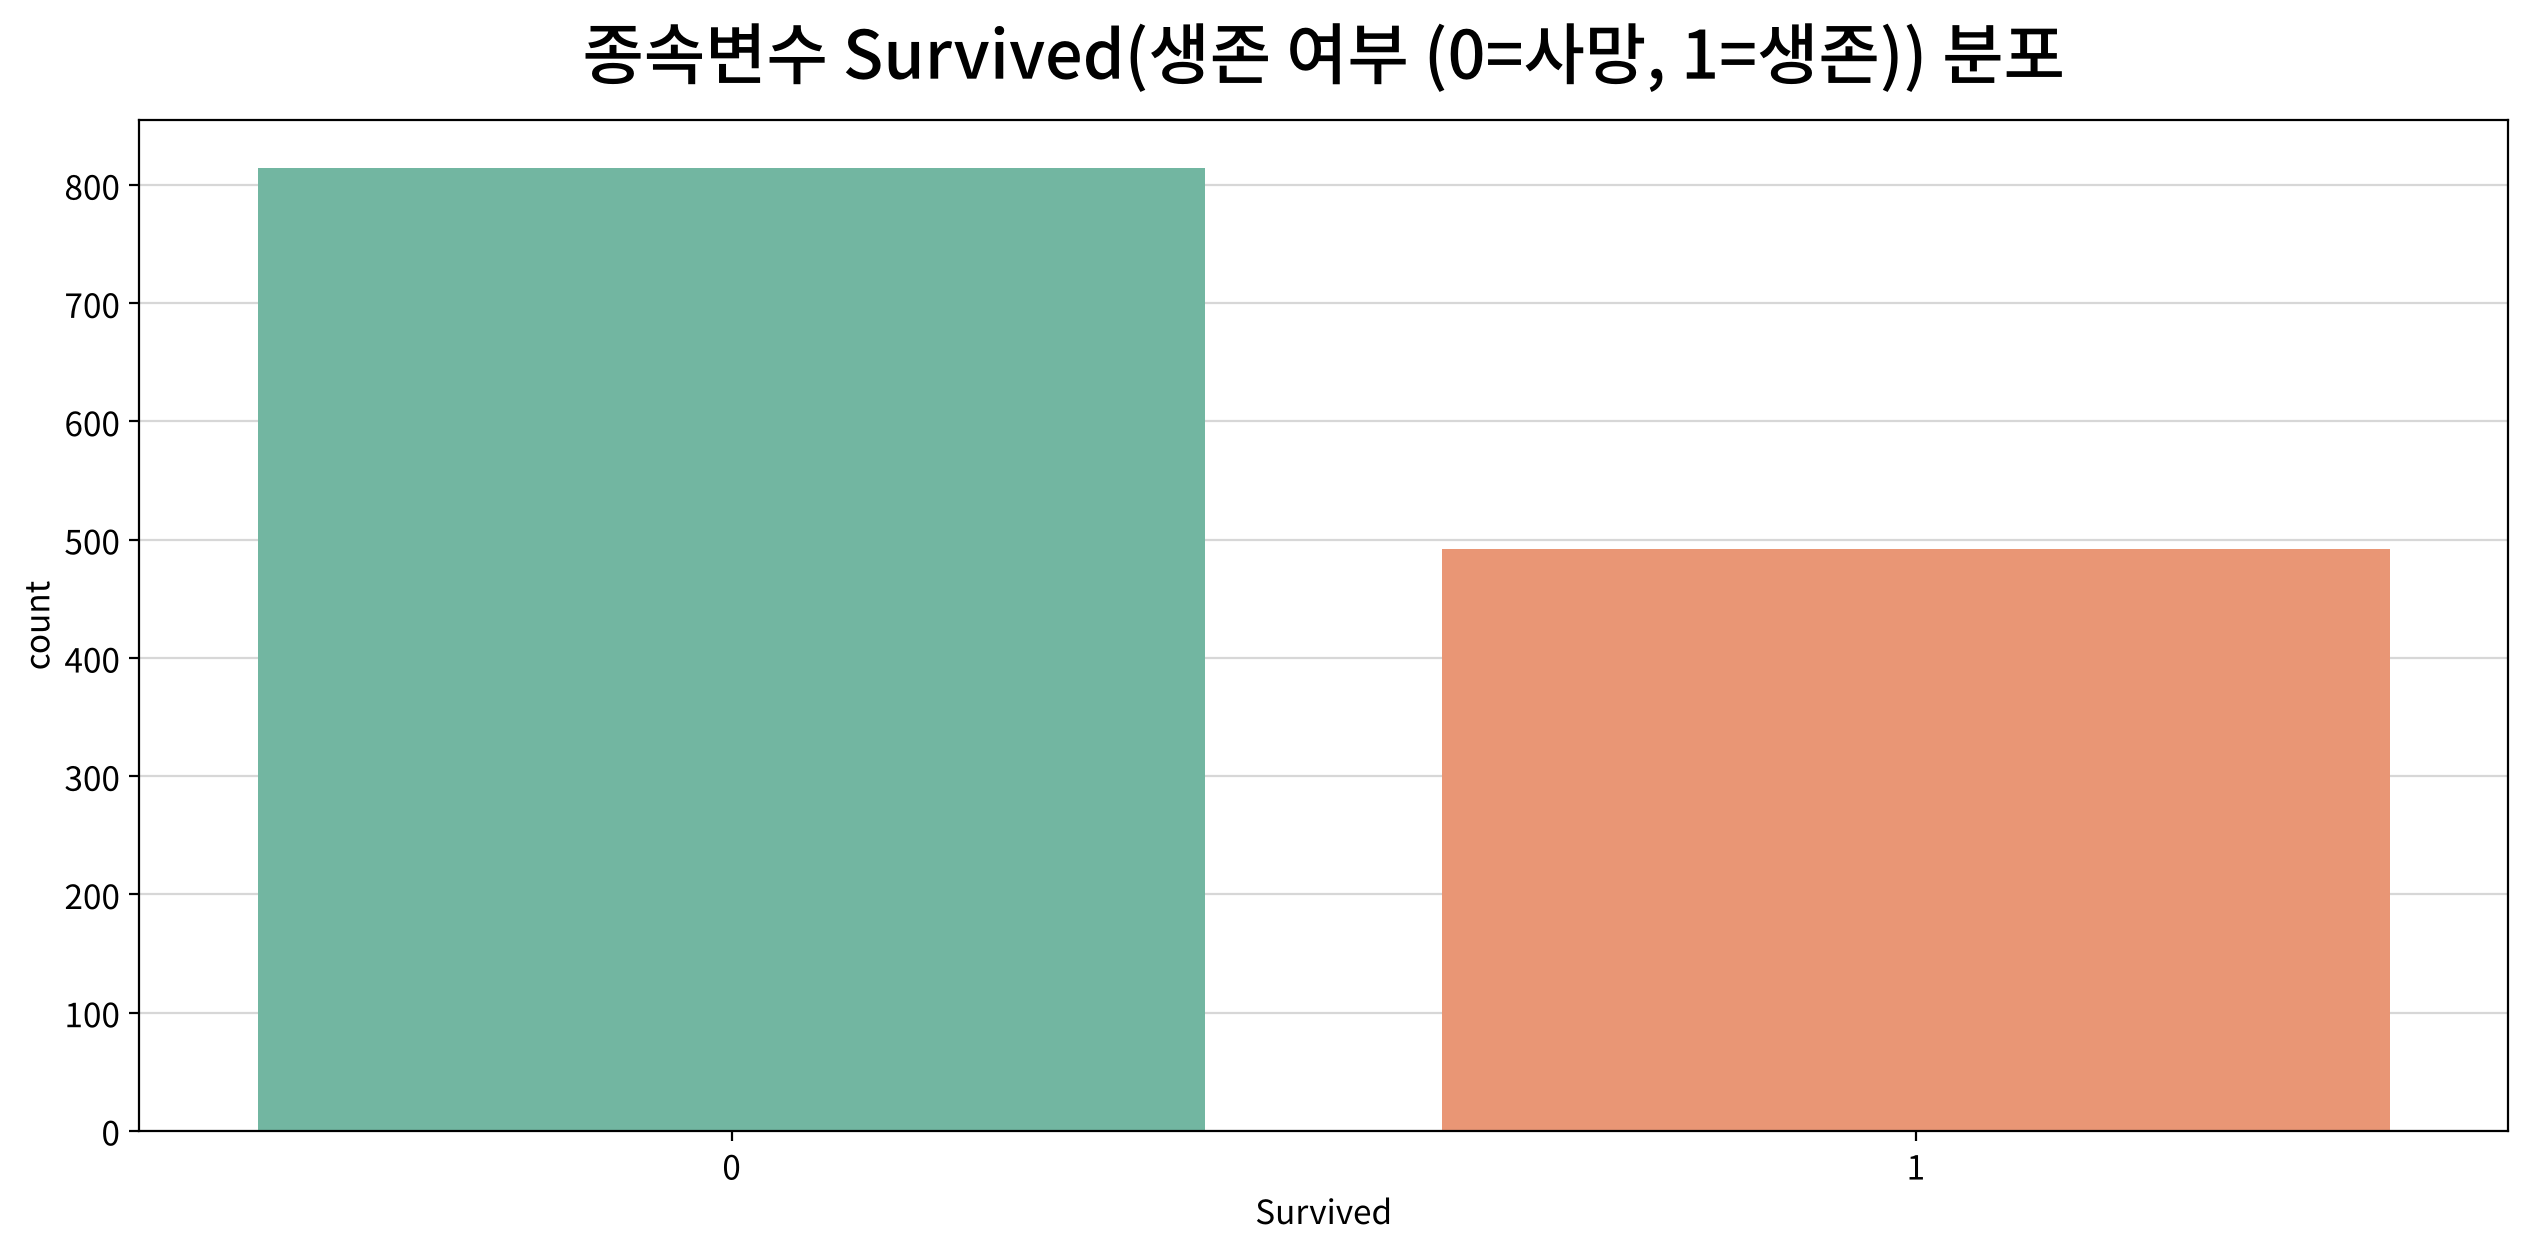

,빈도,비율
Survived,,
0,814,0.623
1,492,0.377


In [17]:
my_plot.countplot(data=df, x=target, hue=target, palette="Set2",
                  title=f"종속변수 {target}({column_means[target]}) 분포")

freq = df[target].value_counts().rename("빈도").to_frame()
freq["비율"] = df[target].value_counts(normalize=True)
freq

---
##### 💡 인사이트

| 점검 항목 | `Survived` 관찰값 |
|---|---|
| 범주 수 | 2 (0=사망 / 1=생존) → **이분형**이므로 로지스틱 회귀 적용 가능 |
| 비율 | 사망 814명(62.3%) · 생존 492명(37.7%) |
| 균형 여부 | **약한 불균형** (62 : 38) |

- **정확도의 바닥값은 62.3%** 다. 모두 '사망'이라고만 답하는 게으른 모델도 62.3%를 맞힌다.
- 심각한 불균형은 아니라 별도의 리샘플링 없이 진행하지만, **정확도 하나만 보지 말고 재현율 · 정밀도 · AUC를 함께** 확인해야 한다.

---

### (2) 명목형 독립변수

#### ▶︎ Pclass(객실 등급 (1=1등급, 2=2등급, 3=3등급)) 분포

Pclass,3,1,2
빈도,708.000,321.000,277.000
비율,0.542,0.246,0.212


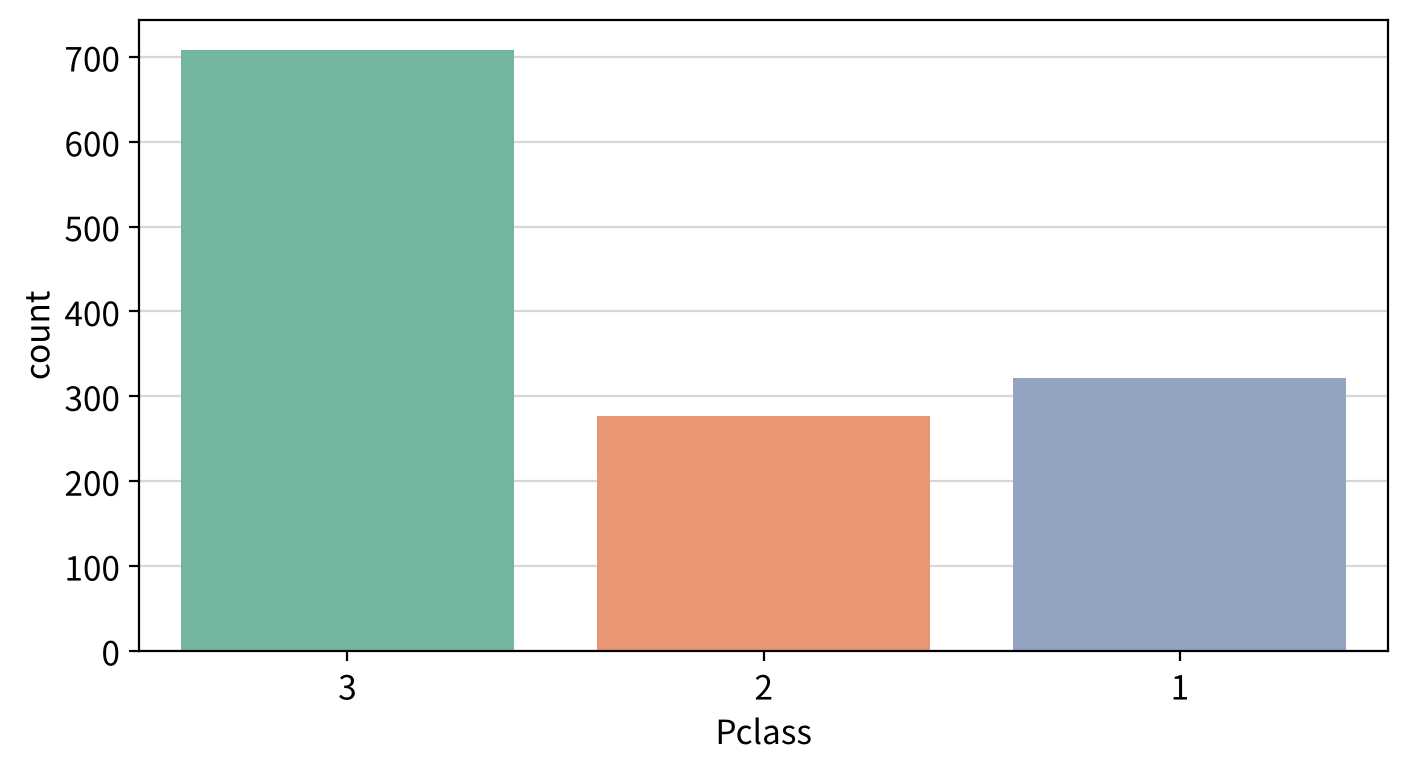

#### ▶︎ Sex(성별 (male, female)) 분포

Sex,male,female
빈도,842.000,464.000
비율,0.645,0.355


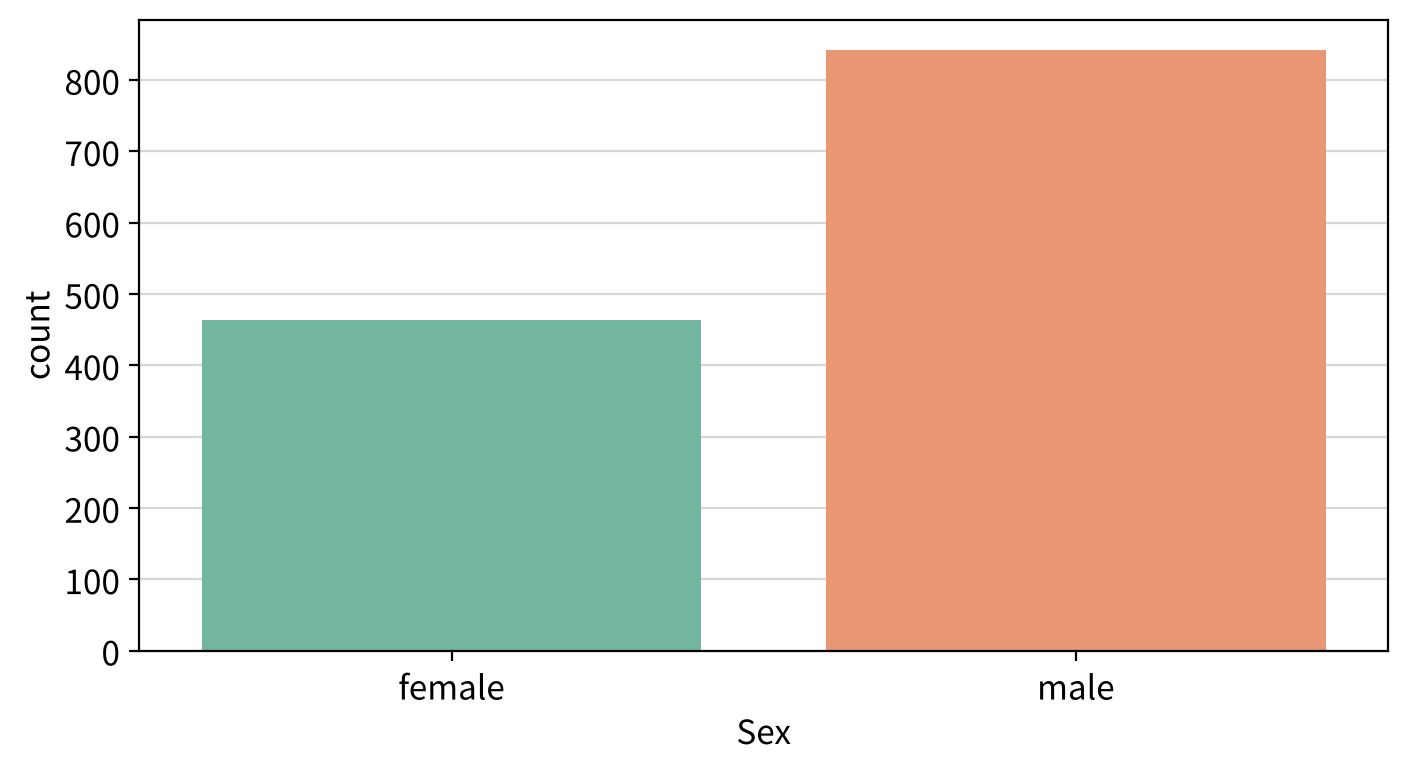

#### ▶︎ Embarked(탑승 항구 (C=Cherbourg, Q=Queenstown, S=Southampton)) 분포

Embarked,S,C,Q
빈도,913.000,270.000,123.000
비율,0.699,0.207,0.094


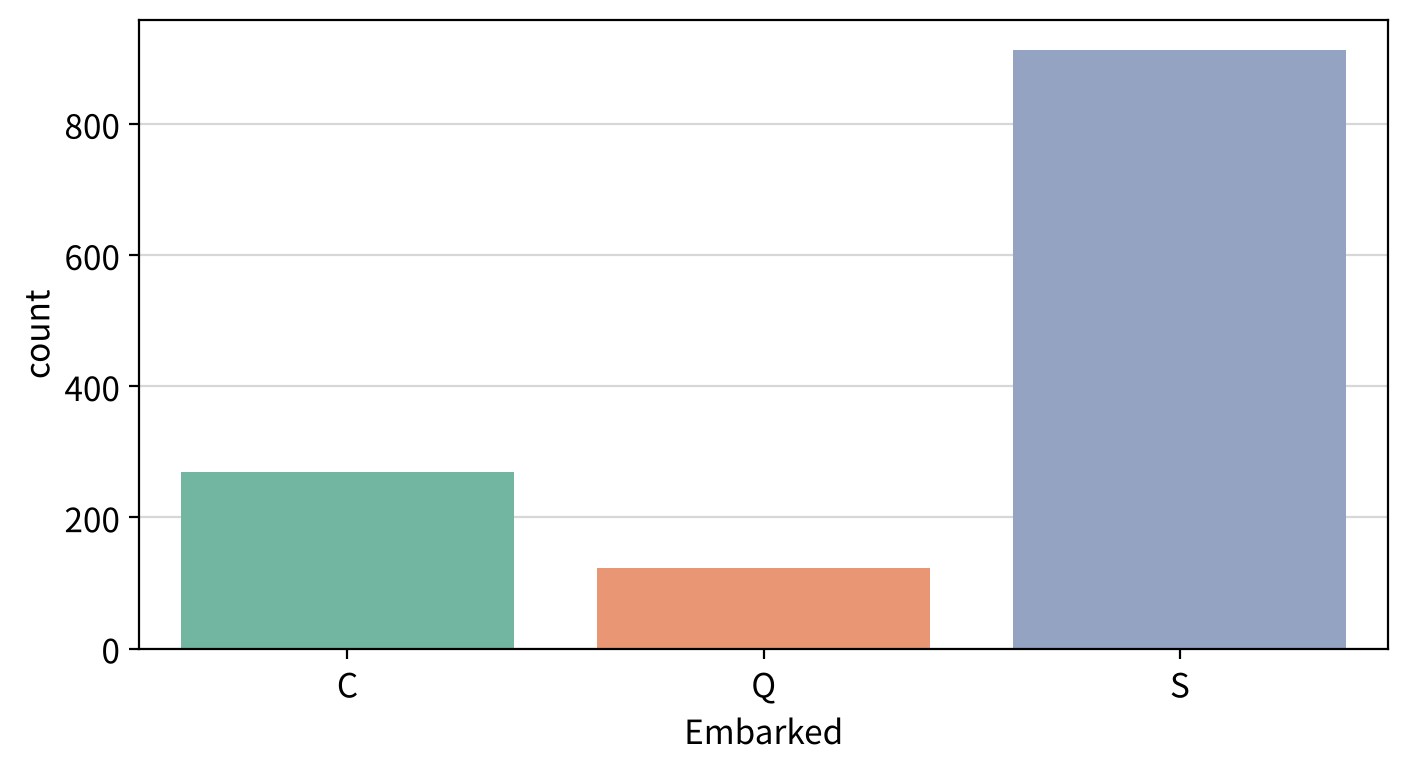

#### ▶︎ Title(이름에서 추출한 호칭 (Mr/Mrs/Miss/Master/Officer)) 분포

Title,Mr,Miss,Mrs,Master,Officer
빈도,759.000,263.000,200.000,61.000,23.000
비율,0.581,0.201,0.153,0.047,0.018


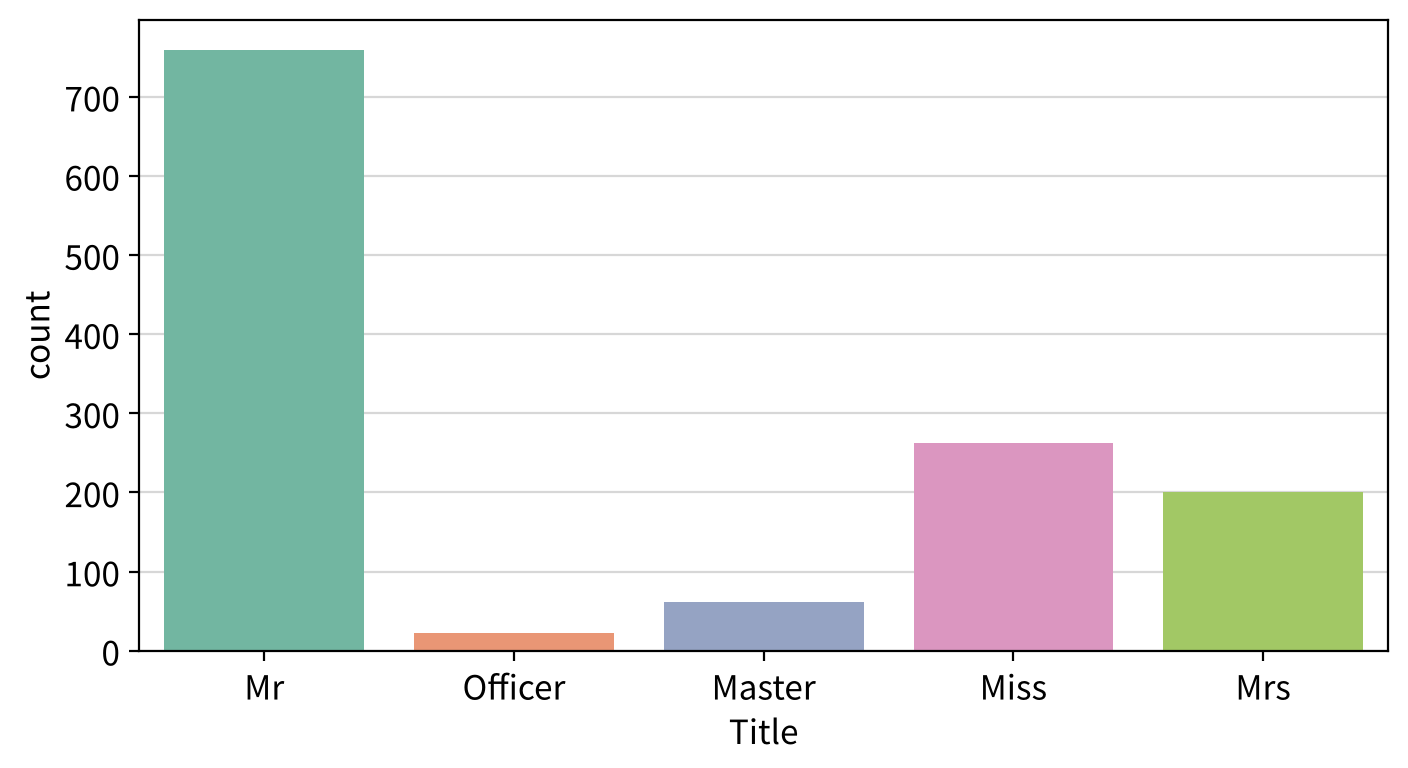

In [18]:
for n in nominal_cols:
    display(Markdown(f"#### ▶︎ {n}({column_means[n]}) 분포"))
    freq = df[n].value_counts().rename("빈도").to_frame()
    freq["비율"] = df[n].value_counts(normalize=True)
    display(freq.T)
    my_plot.countplot(data=df, x=n, hue=n, palette="Set2", width=720, height=400)

---
##### 💡 인사이트

| 변수 | 범주 분포 | 판단 |
|---|---|---|
| `Pclass` | 3등급 708 (54.2%) · 1등급 321 (24.6%) · 2등급 277 (21.2%) | 3등급이 절반 이상이지만 나머지도 충분 |
| `Sex` | 남성 842 (64.5%) · 여성 464 (35.5%) | 남성이 많지만 여성도 464명으로 충분해 분석에 문제 없음 |
| `Embarked` | S 913 (69.9%) · C 270 (20.7%) · **Q 123 (9.4%)** | Q가 적지만 100건 이상이라 사용 가능 |
| `Title` | Mr 759 (58.1%) · Miss 263 (20.1%) · Mrs 200 (15.3%) · Master 61 (4.7%) · **Officer 23 (1.8%)** | **`Officer`는 23명뿐이라 계수가 불안정할 수 있다** |

- **가장 작은 범주는 `Title = Officer`의 23명**이다. 모델에서 이 범주의 효과는 신뢰구간이 넓고 불안정하게 추정될 수 있다.
- 원본 호칭 18종을 그대로 썼다면 1명짜리 범주가 여럿 생겨 추정 자체가 어려웠을 것이다. **5종으로 묶은 판단이 여기서 정당화된다.**

---

### (3) 연속형 독립변수

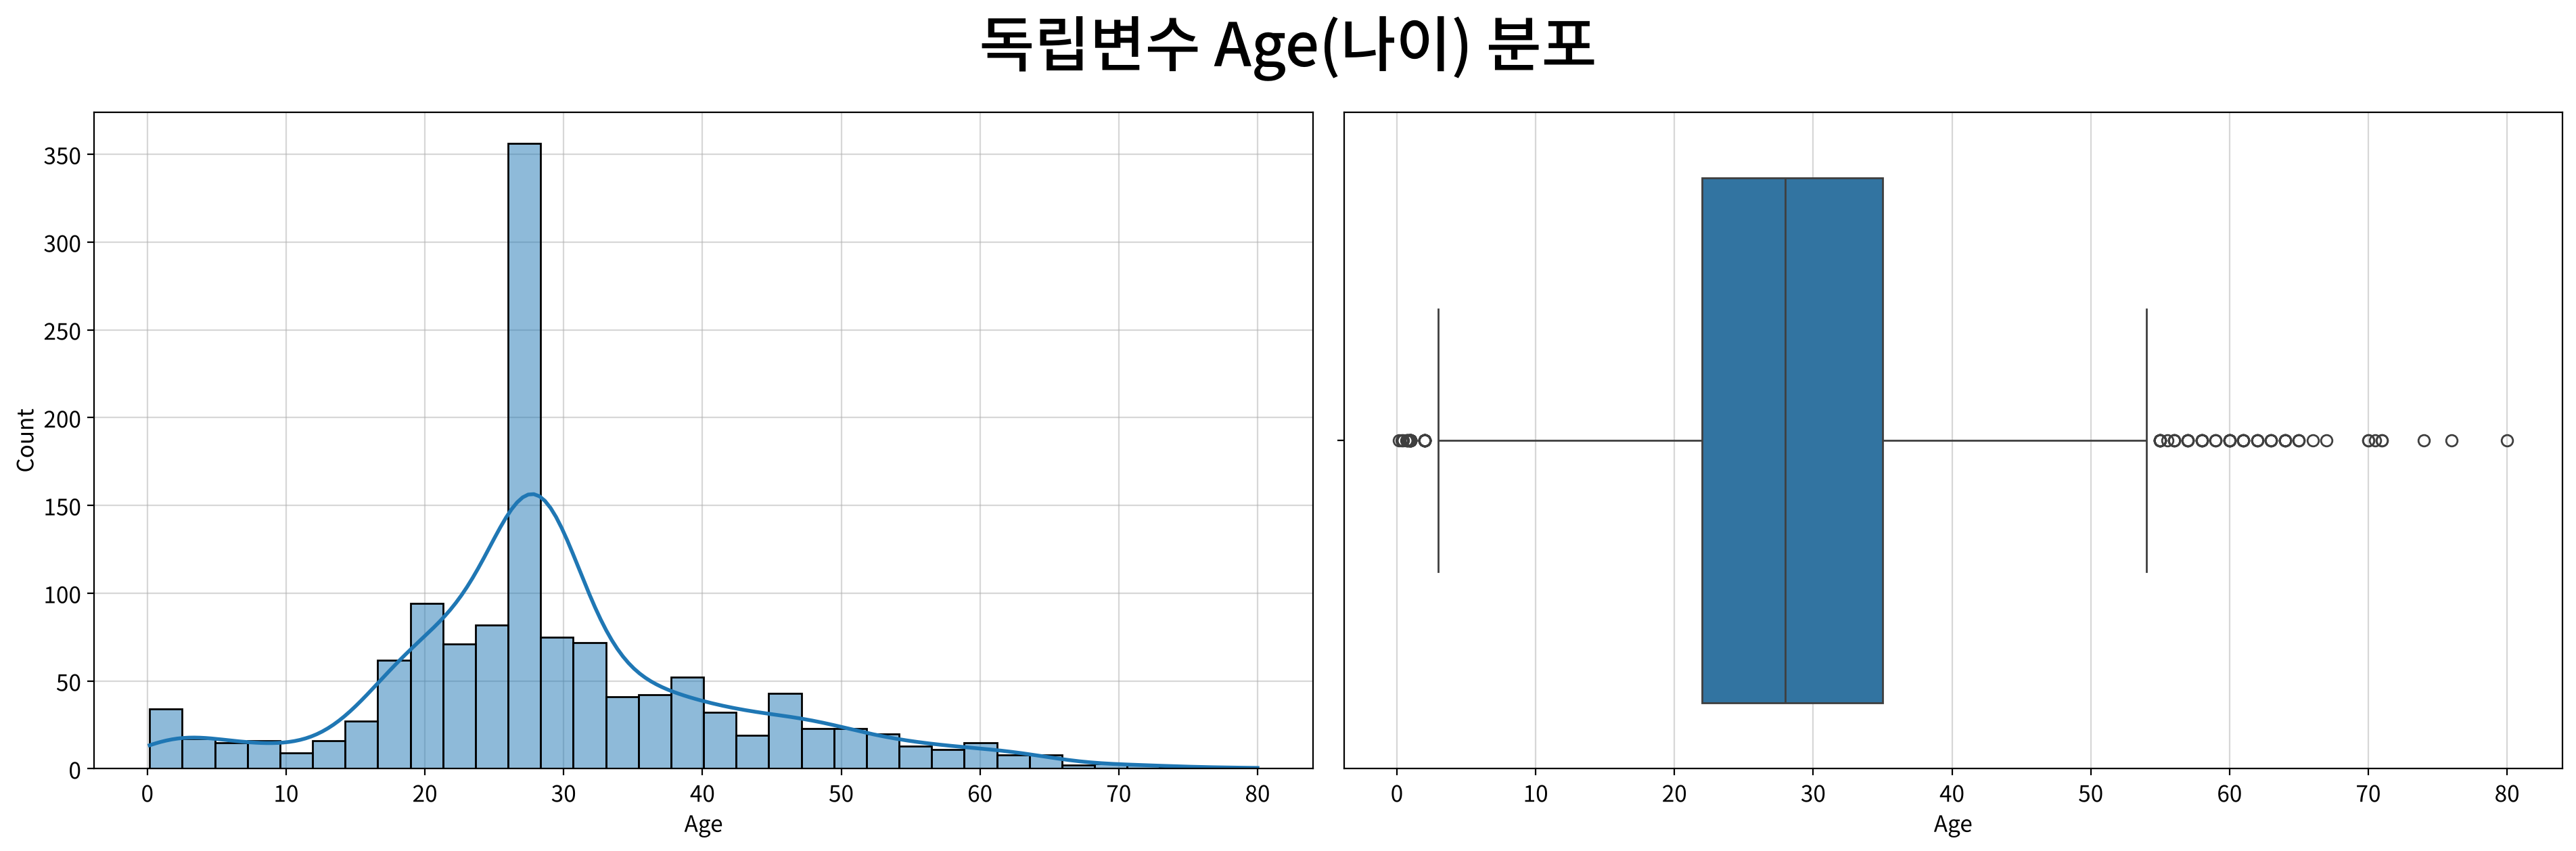

,Age
count,1306.000
mean,29.448
std,12.858
min,0.170
25%,22.000
50%,28.000
75%,35.000
max,80.000
rel_diff,0.052
rdiff_flag,similar


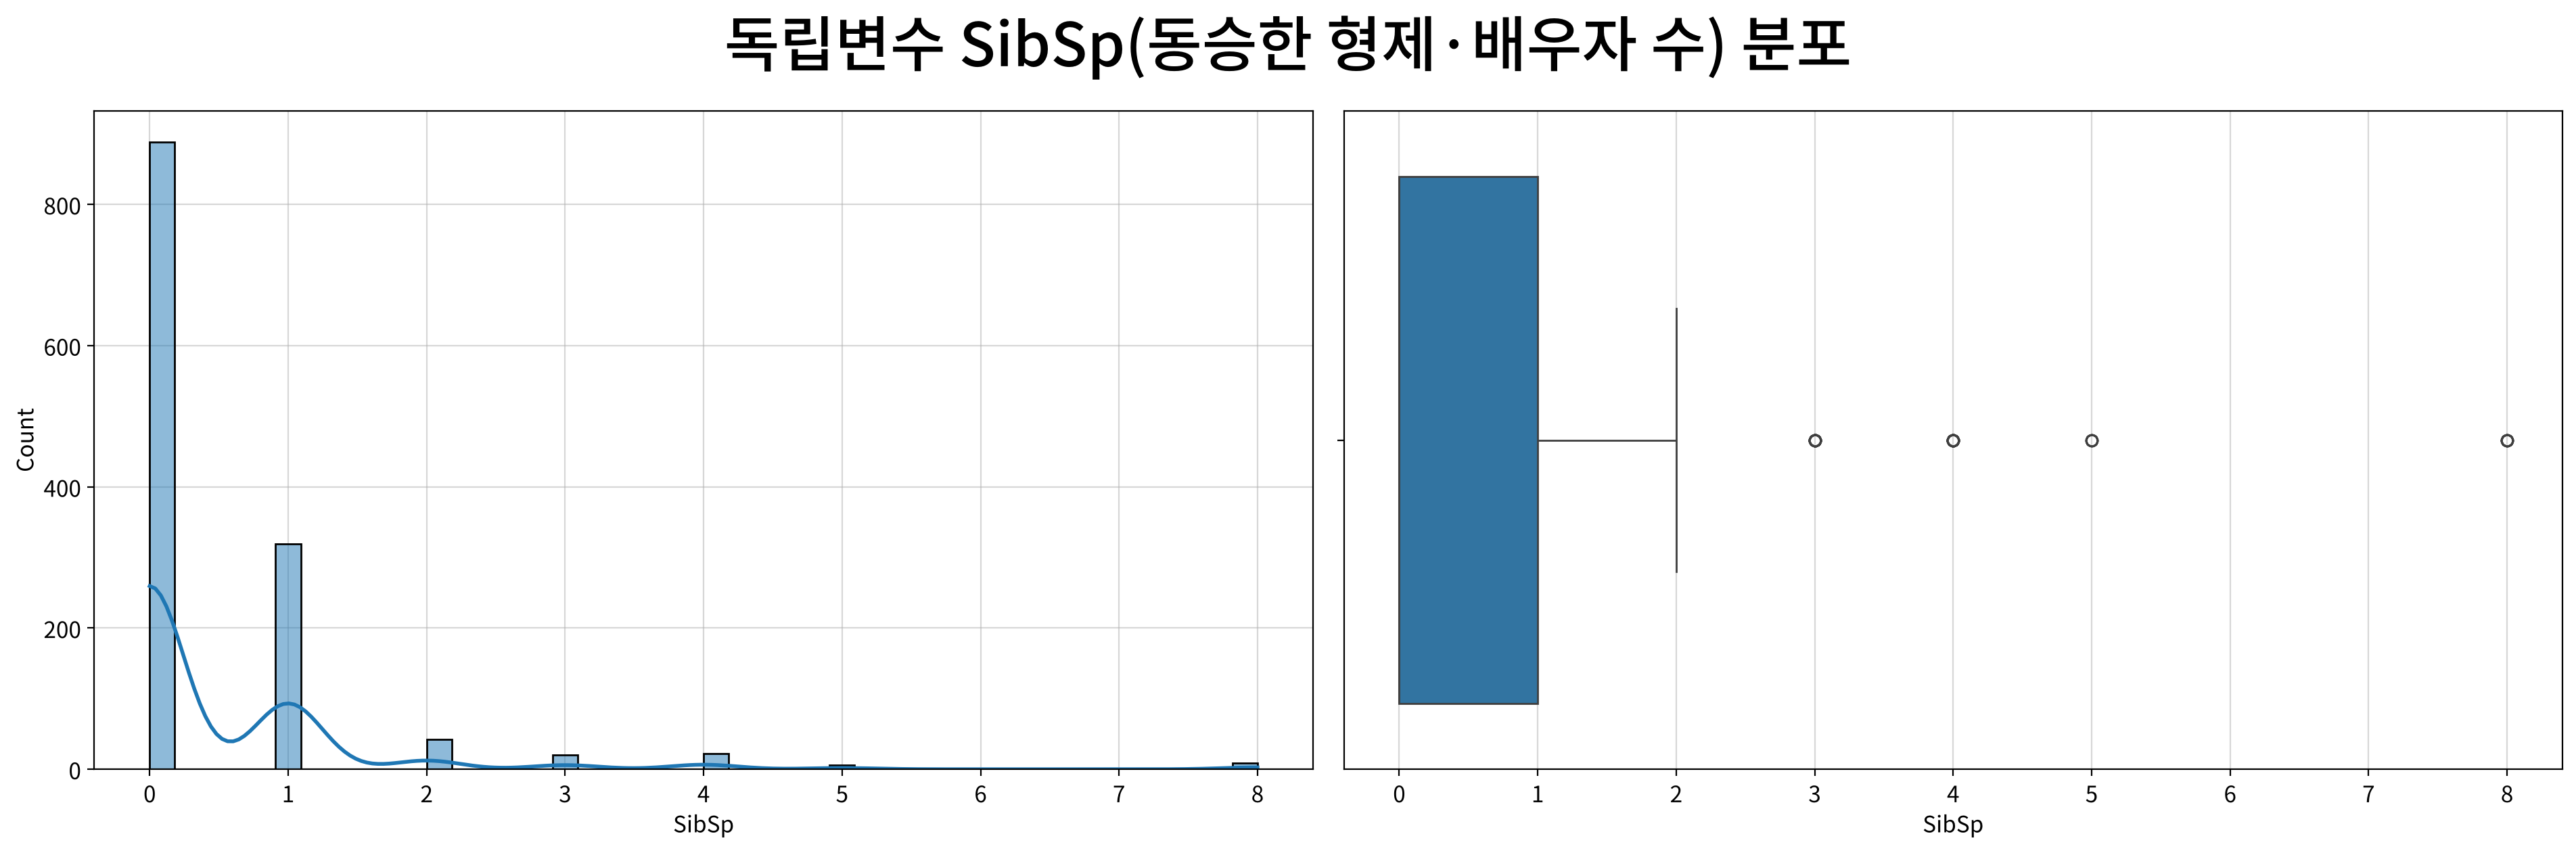

,SibSp
count,1306.000
mean,0.500
std,1.043
min,0.000
25%,0.000
50%,0.000
75%,1.000
max,8.000
rel_diff,inf
rdiff_flag,large_diff


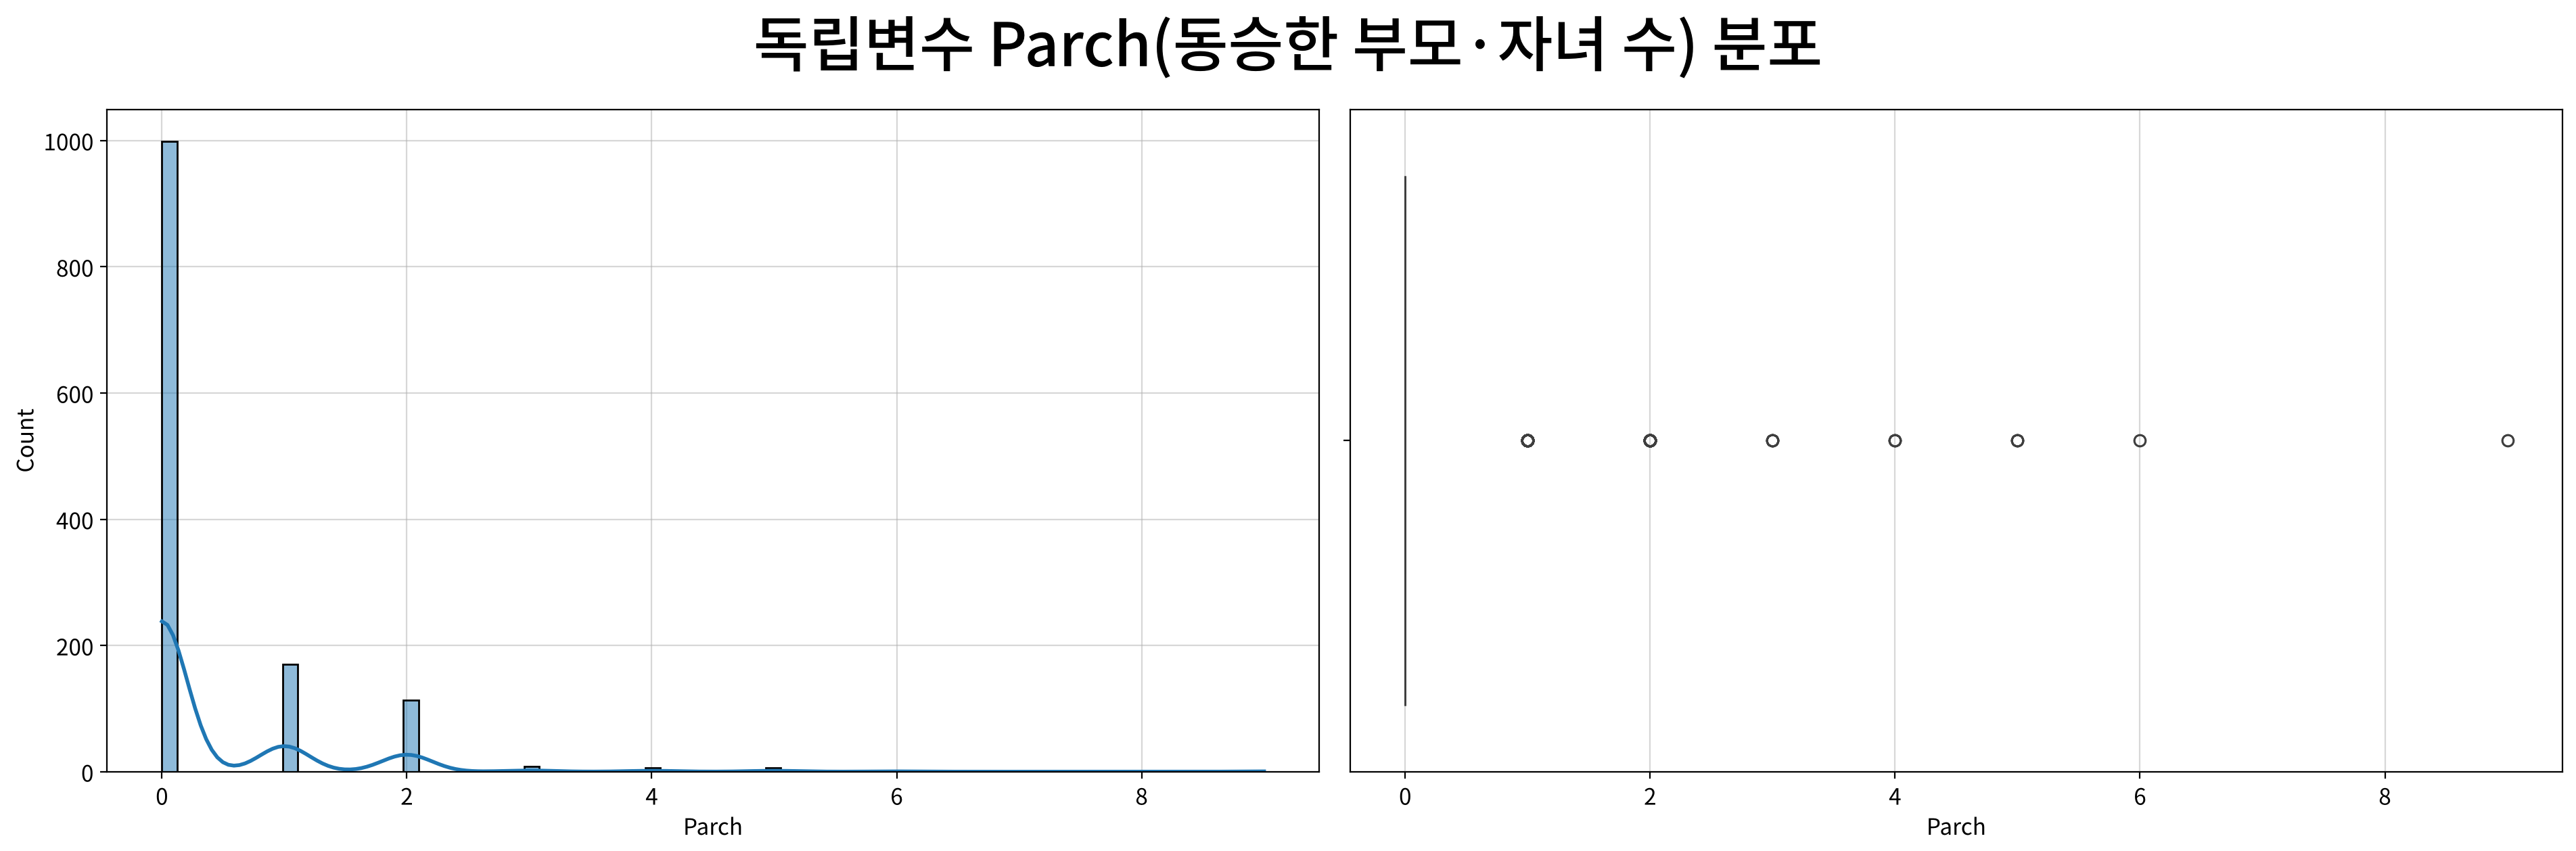

,Parch
count,1306.000
mean,0.386
std,0.866
min,0.000
25%,0.000
50%,0.000
75%,0.000
max,9.000
rel_diff,inf
rdiff_flag,large_diff


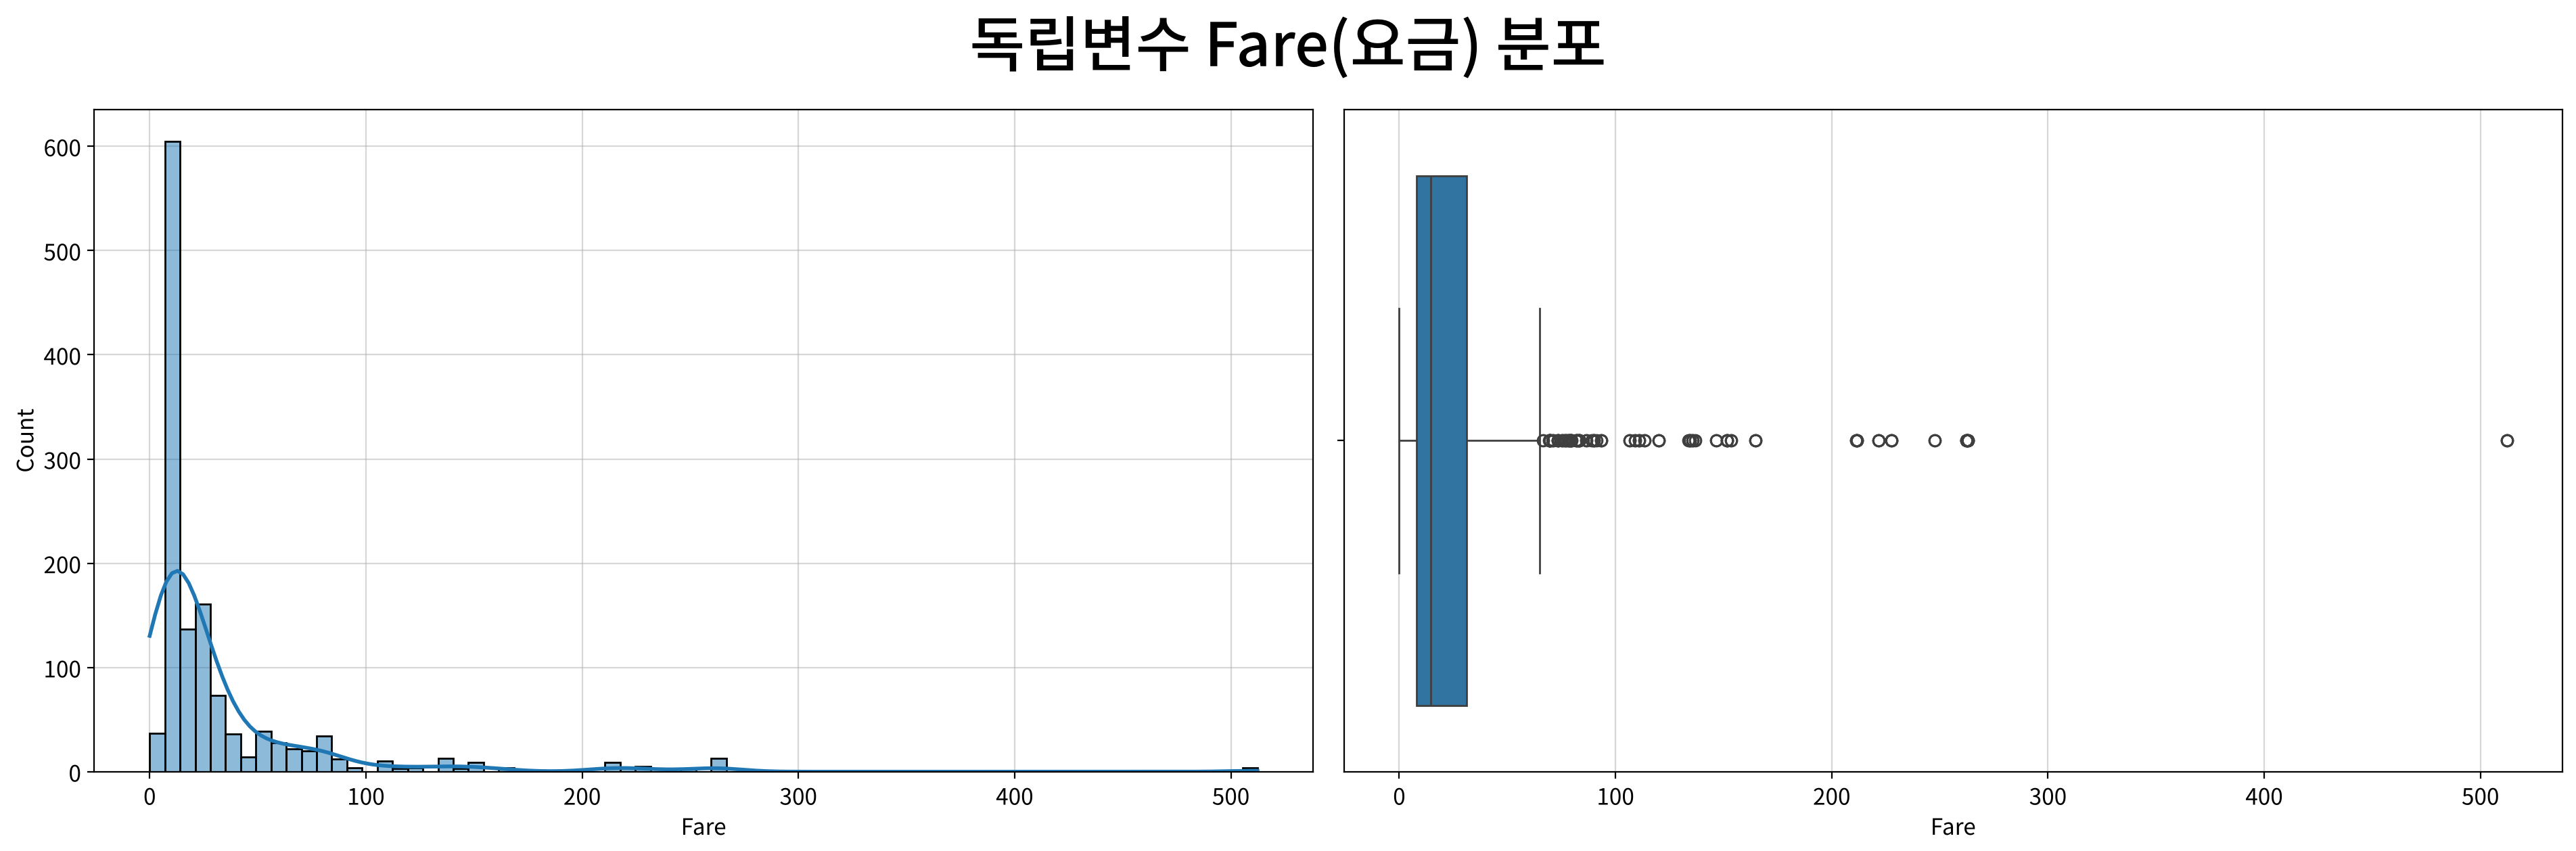

,Fare
count,1306.000
mean,33.224
std,51.766
min,0.000
25%,7.896
50%,14.454
75%,31.275
max,512.329
rel_diff,1.299
rdiff_flag,large_diff


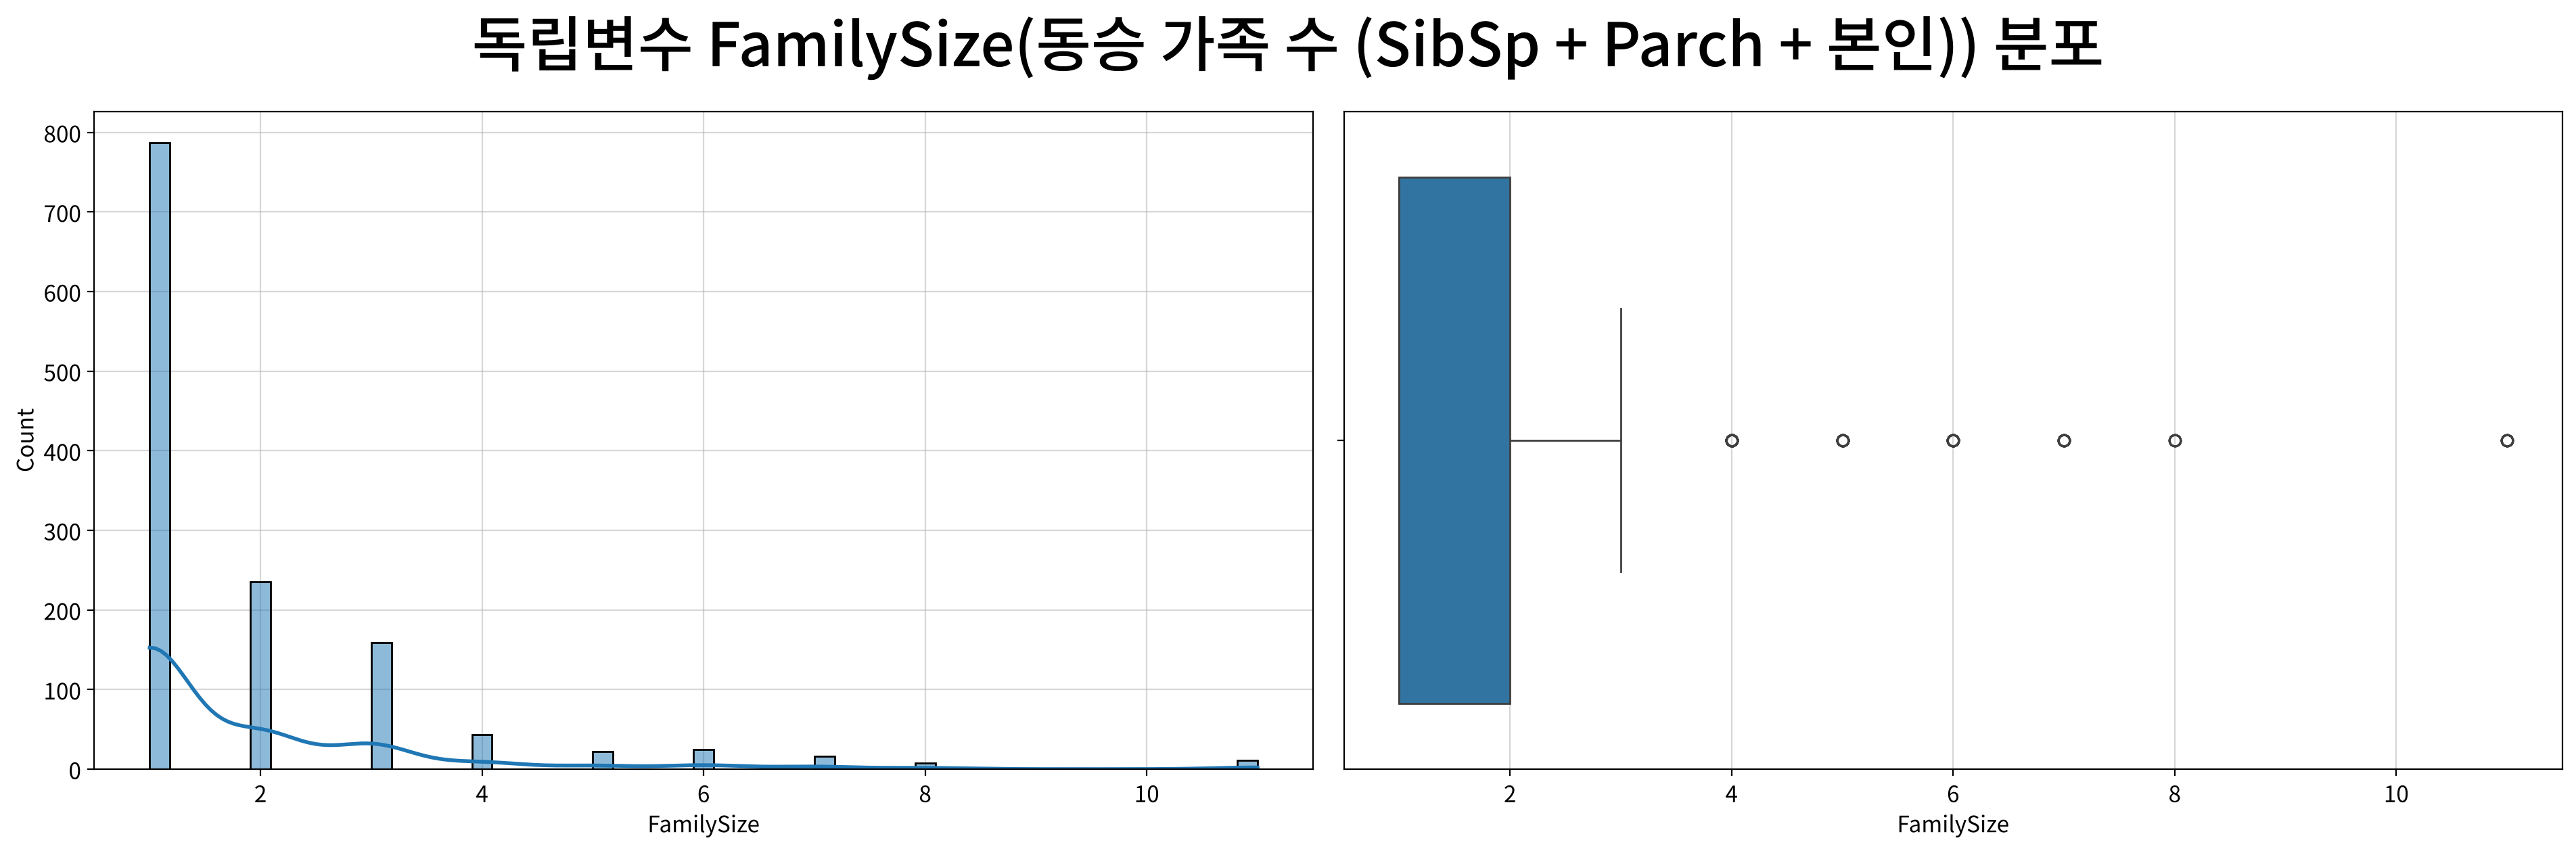

,FamilySize
count,1306.000
mean,1.886
std,1.585
min,1.000
25%,1.000
50%,1.000
75%,2.000
max,11.000
rel_diff,0.886
rdiff_flag,large_diff


In [19]:
for f in continuous_cols:
    fig, ax = my_plot.init(rows=1, cols=2, width=960, height=640,
                           title=f"독립변수 {f}({column_means[f]}) 분포")
    my_plot.histplot(data=df, x=f, kde=True, ax=ax[0])
    my_plot.boxplot(data=df, x=f, ax=ax[1])
    my_plot.show()

    display(num_desc.loc[[f]].T)

---
##### 💡 인사이트

| 변수 | 분포 모양 (왜도) | 이상치 | 판단 |
|---|---|---|---|
| `Age` | 약한 우편향 (0.54), **28세에 솟은 막대** | 7.6% | 중앙값(28세) 대체의 흔적 |
| `SibSp` | 심한 우편향 (3.84), 0에 집중 | 4.4% | 카운트 변수 |
| `Parch` | 심한 우편향 (3.67), 0에 집중 | 23.5% | 카운트 변수 — **Q1 = Q3 = 0이라 IQR 이상치 판정이 무의미** |
| `Fare` | 극심한 우편향 (4.38), 저가에 집중 | 12.9% | 높은 요금은 실제 1등석 가격 — 오류가 아니라 정보(삭제 시 객실 등급 정보가 사라짐) |
| `FamilySize` | 우편향 (2.85), **1명(단독)에 집중** | 9.6% | 카운트 변수 — 4명 이상이 이상치로 잡힘 |

- **`Age` 히스토그램의 28세 자리에 막대가 솟아 있다.** 결측 263명을 중앙값으로 채운 흔적이다. 실제 데이터가 아니라 **채워 넣은 값**이므로 이후 결과를 볼 때 염두에 둔다.
- `SibSp` · `Parch` · `FamilySize` 같은 **카운트 변수**에 IQR 이상치 대체를 쓰면, 의미 있는 값(가족이 많은 승객)이 눌려 버린다. → 이상치 대체는 `Age` · `Fare`에만 적용한다.
- 로지스틱 회귀는 잔차의 정규성 · 등분산성을 가정하지 않으므로 **왜도만으로 변환하지 않는다.** 변환 여부는 로짓 선형성 검정이 결정한다.

---

## 2-2. 이변량 분석 — 생존자와 사망자는 다른가?

### (1) 연속형 × 생존 : 독립표본 검정

#### ▶︎ Age(나이) → Survived

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

0 vs. 1: Mann-Whitney-Wilcoxon test two-sided, P_val:2.665e-01 U_stat=2.075e+05


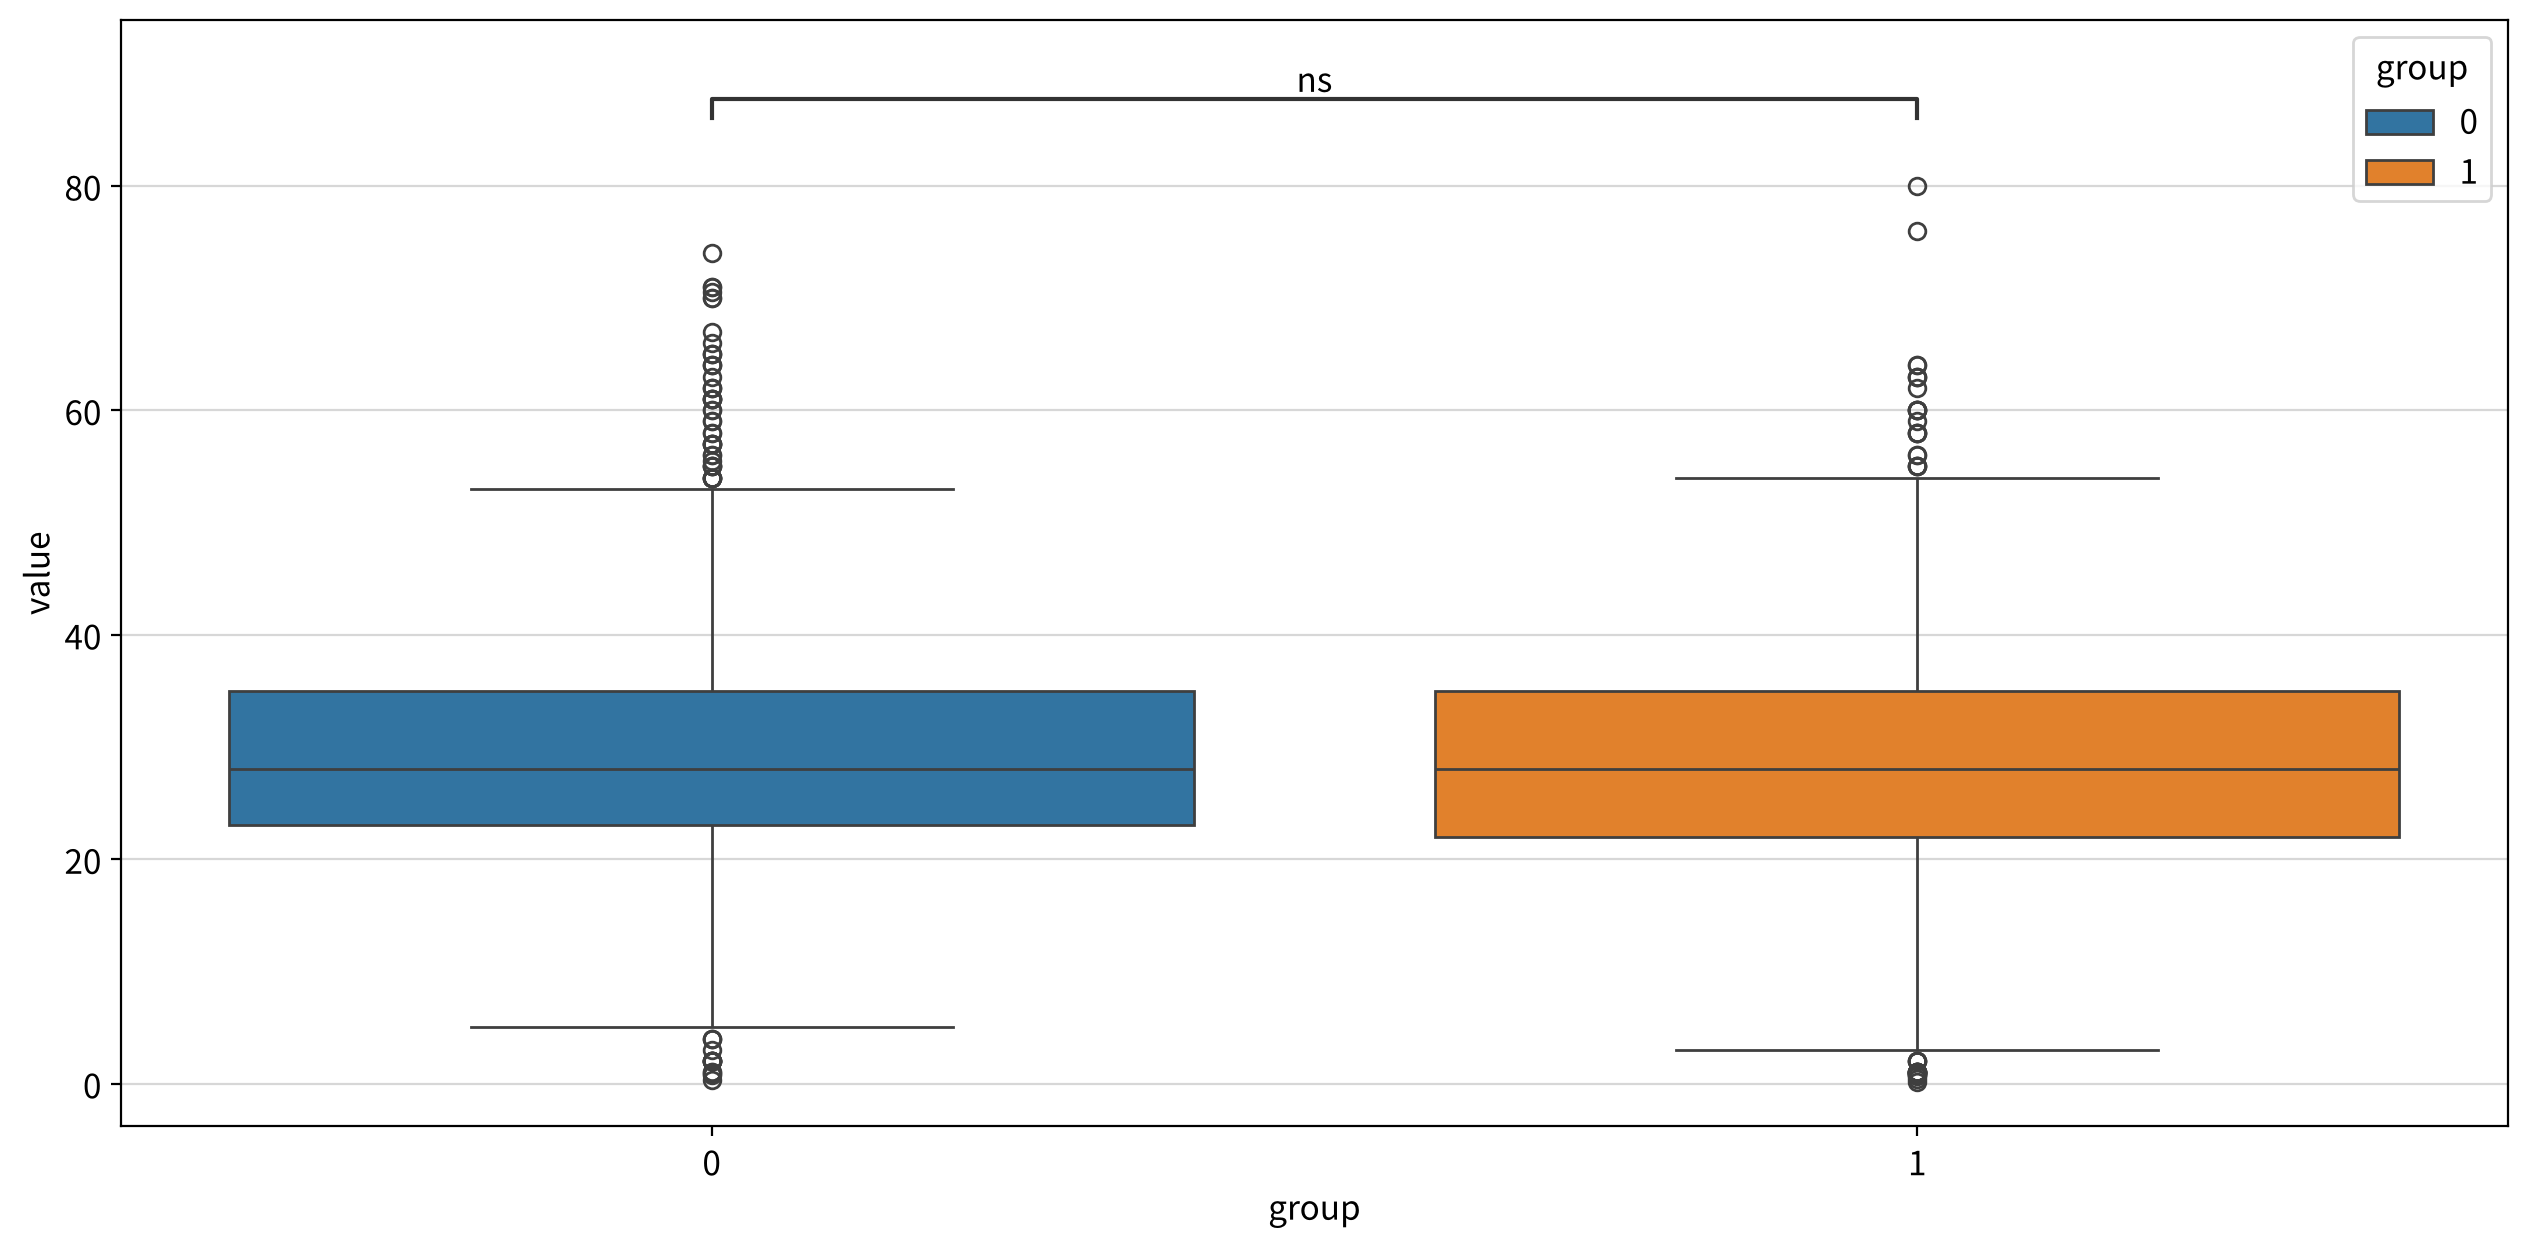

statistic  p-value  significant result
test                alternative                                        
Mann-Whitney U test two-sided   207540.000    0.267        False  0 = 1
                    less        207540.000    0.867        False  0 ≥ 1
                    greater     207540.000    0.133        False  0 ≤ 1

#### ▶︎ SibSp(동승한 형제·배우자 수) → Survived

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

0 vs. 1: Mann-Whitney-Wilcoxon test two-sided, P_val:7.787e-05 U_stat=1.789e+05


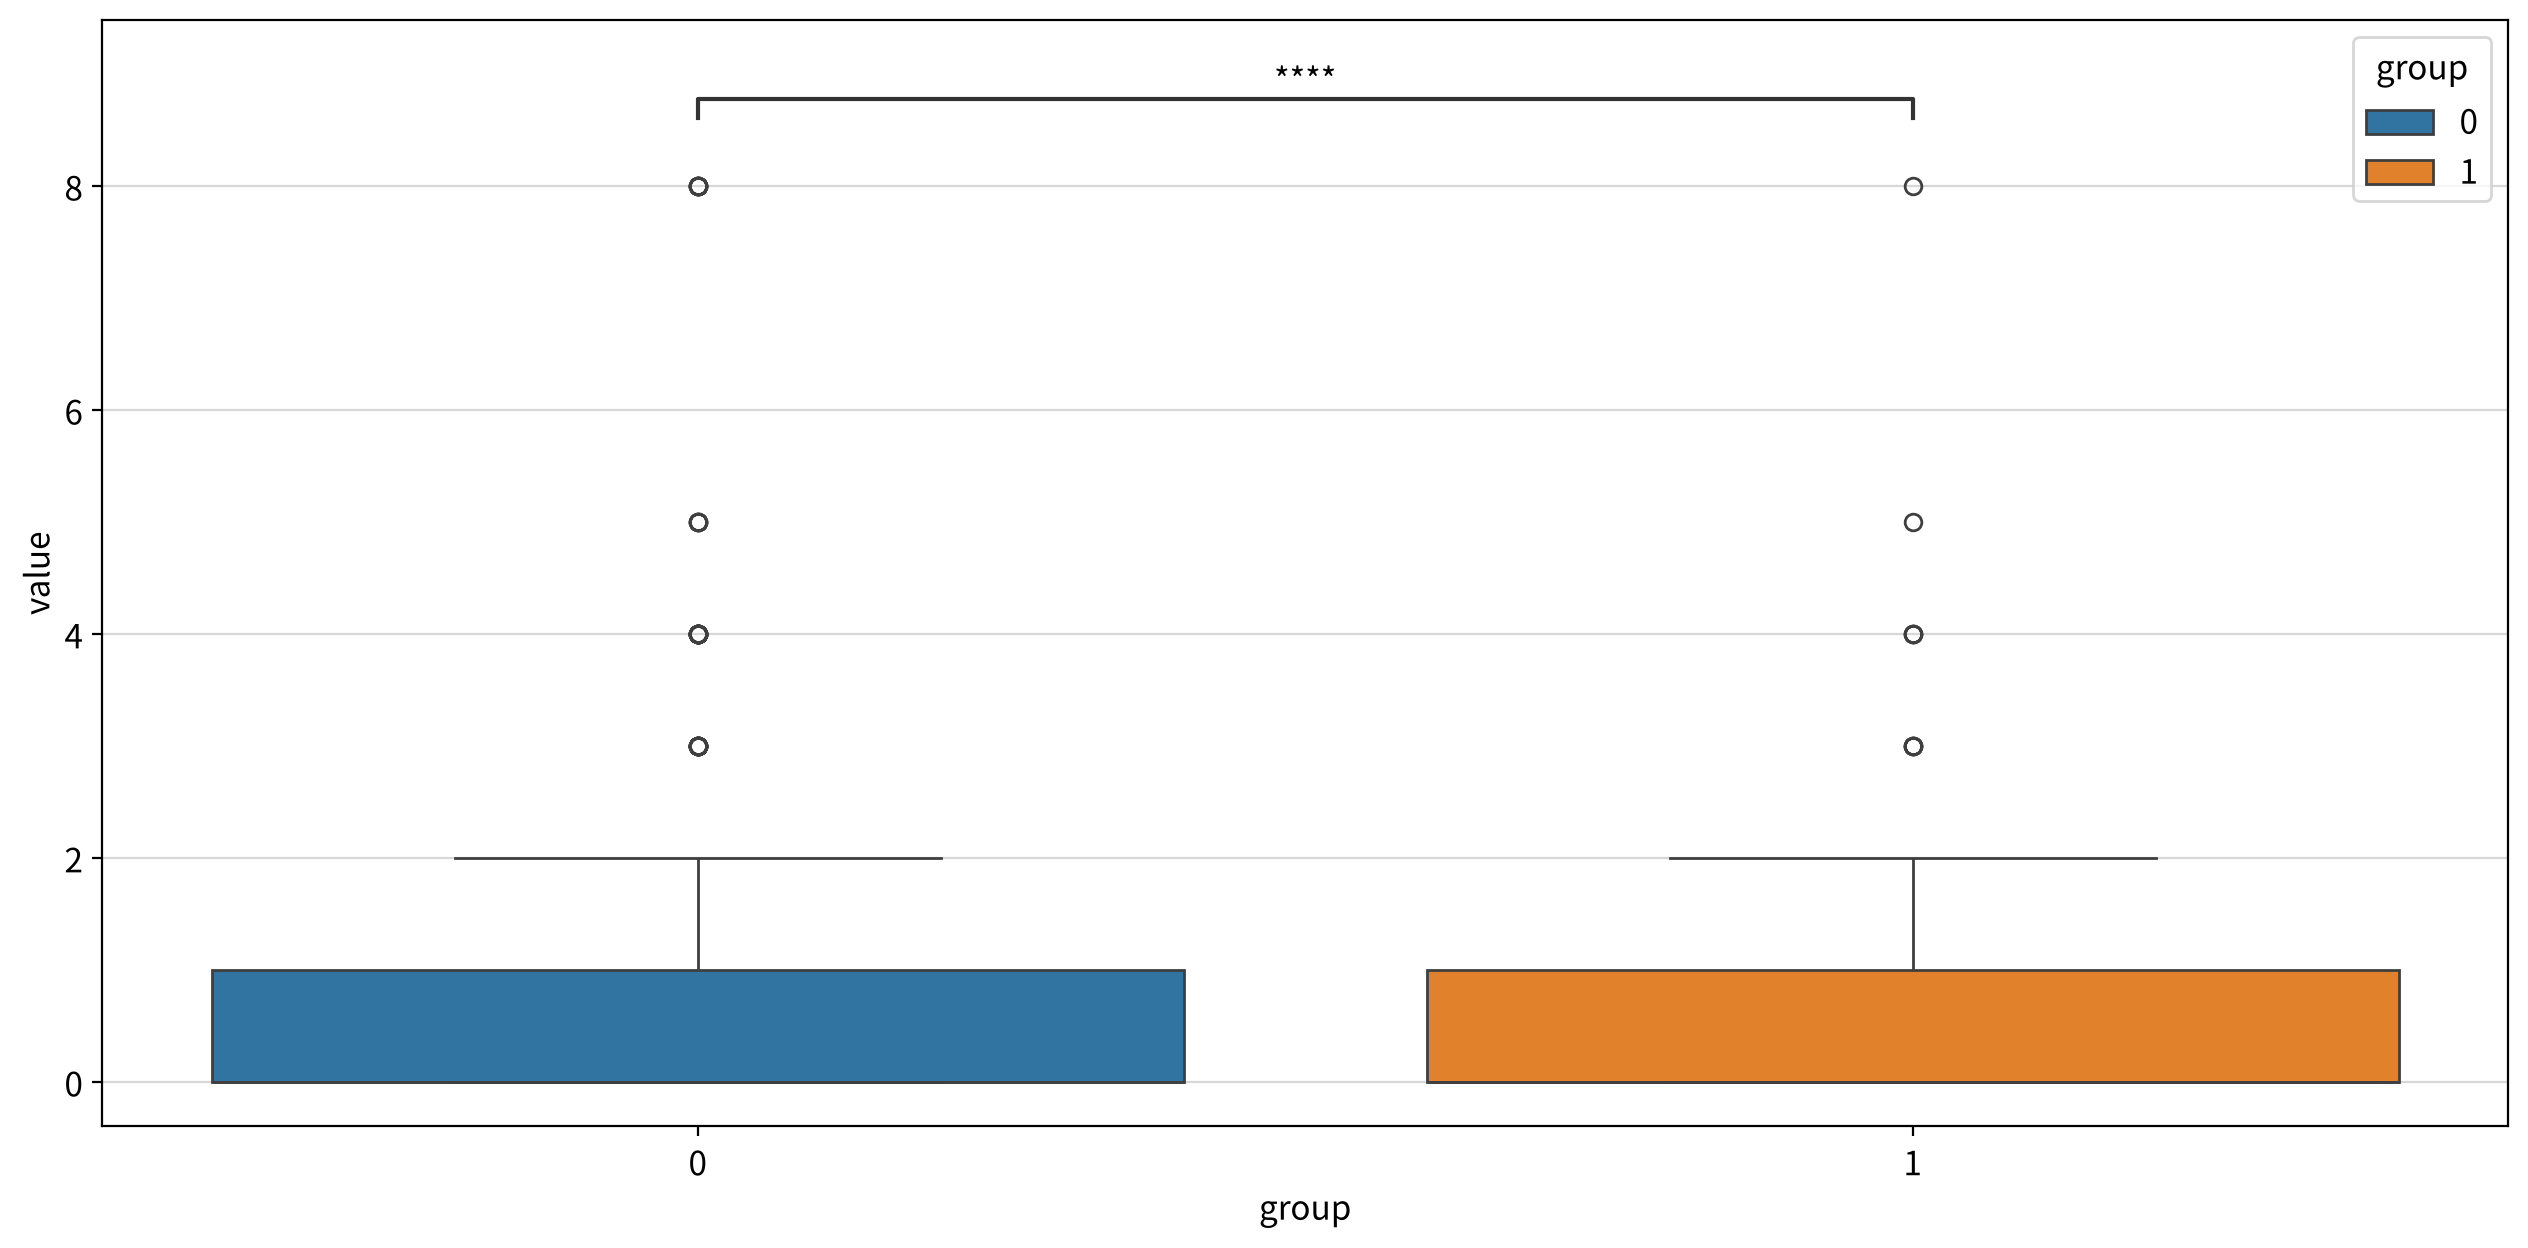

statistic  p-value  significant result
test                alternative                                        
Mann-Whitney U test two-sided   178868.500    0.000         True  0 ≠ 1
                    less        178868.500    0.000         True  0 < 1
                    greater     178868.500    1.000        False  0 ≤ 1

#### ▶︎ Parch(동승한 부모·자녀 수) → Survived

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

0 vs. 1: Mann-Whitney-Wilcoxon test two-sided, P_val:1.646e-09 U_stat=1.707e+05


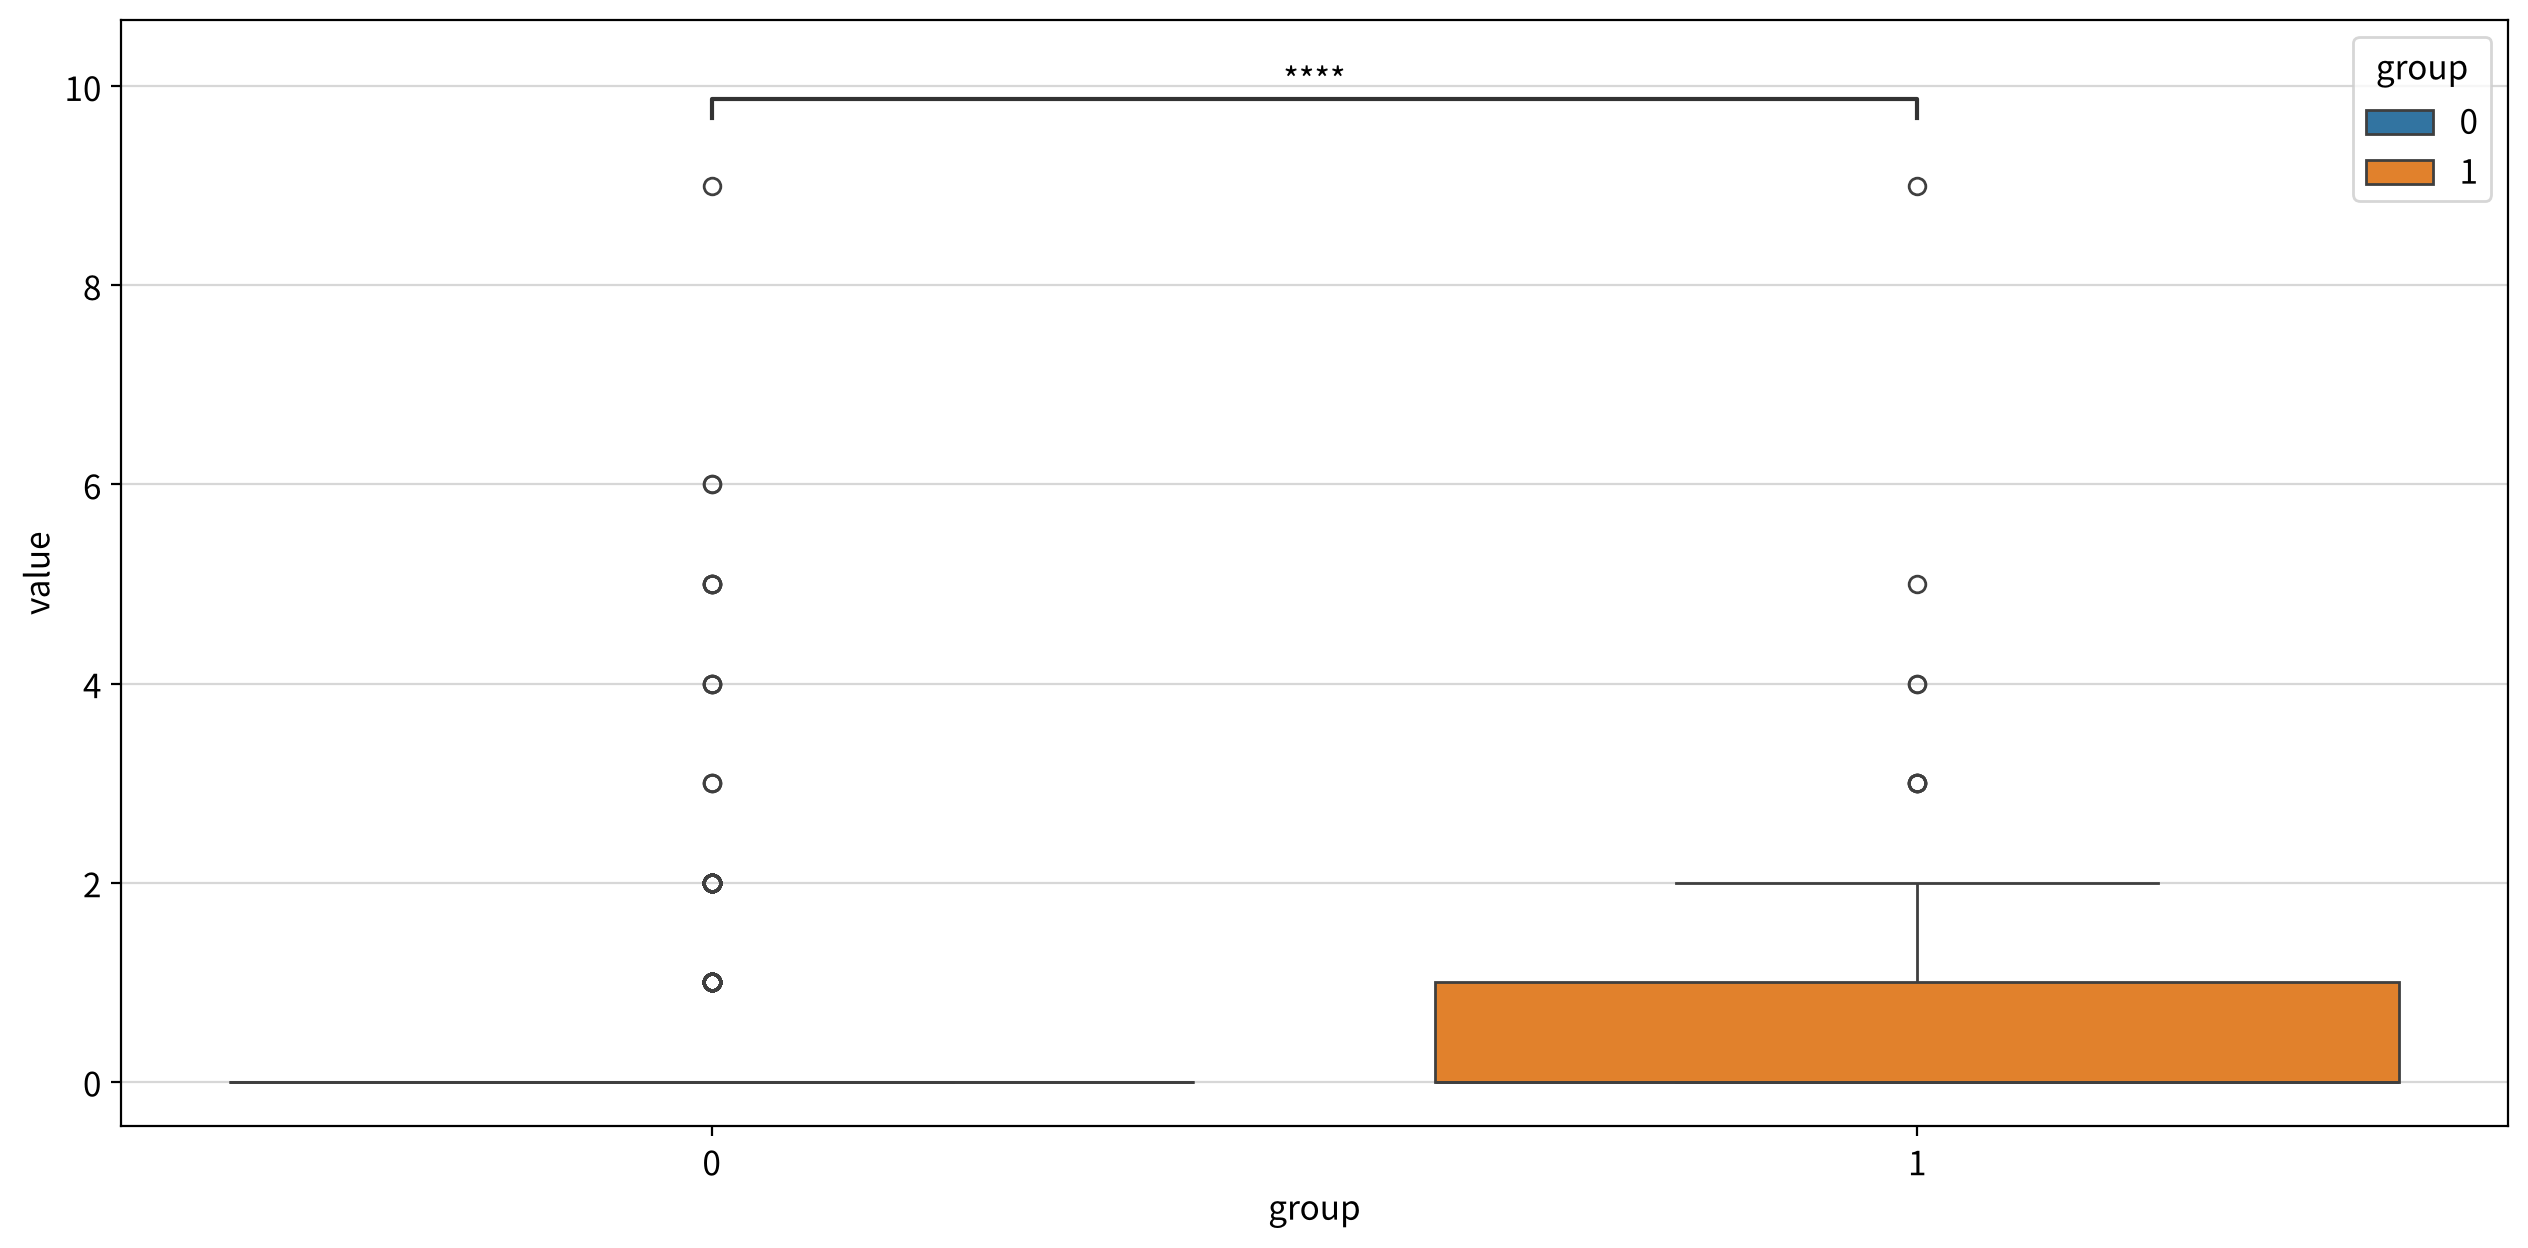

statistic  p-value  significant result
test                alternative                                        
Mann-Whitney U test two-sided   170723.000    0.000         True  0 ≠ 1
                    less        170723.000    0.000         True  0 < 1
                    greater     170723.000    1.000        False  0 ≤ 1

#### ▶︎ Fare(요금) → Survived

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

0 vs. 1: Mann-Whitney-Wilcoxon test two-sided, P_val:1.570e-24 U_stat=1.327e+05


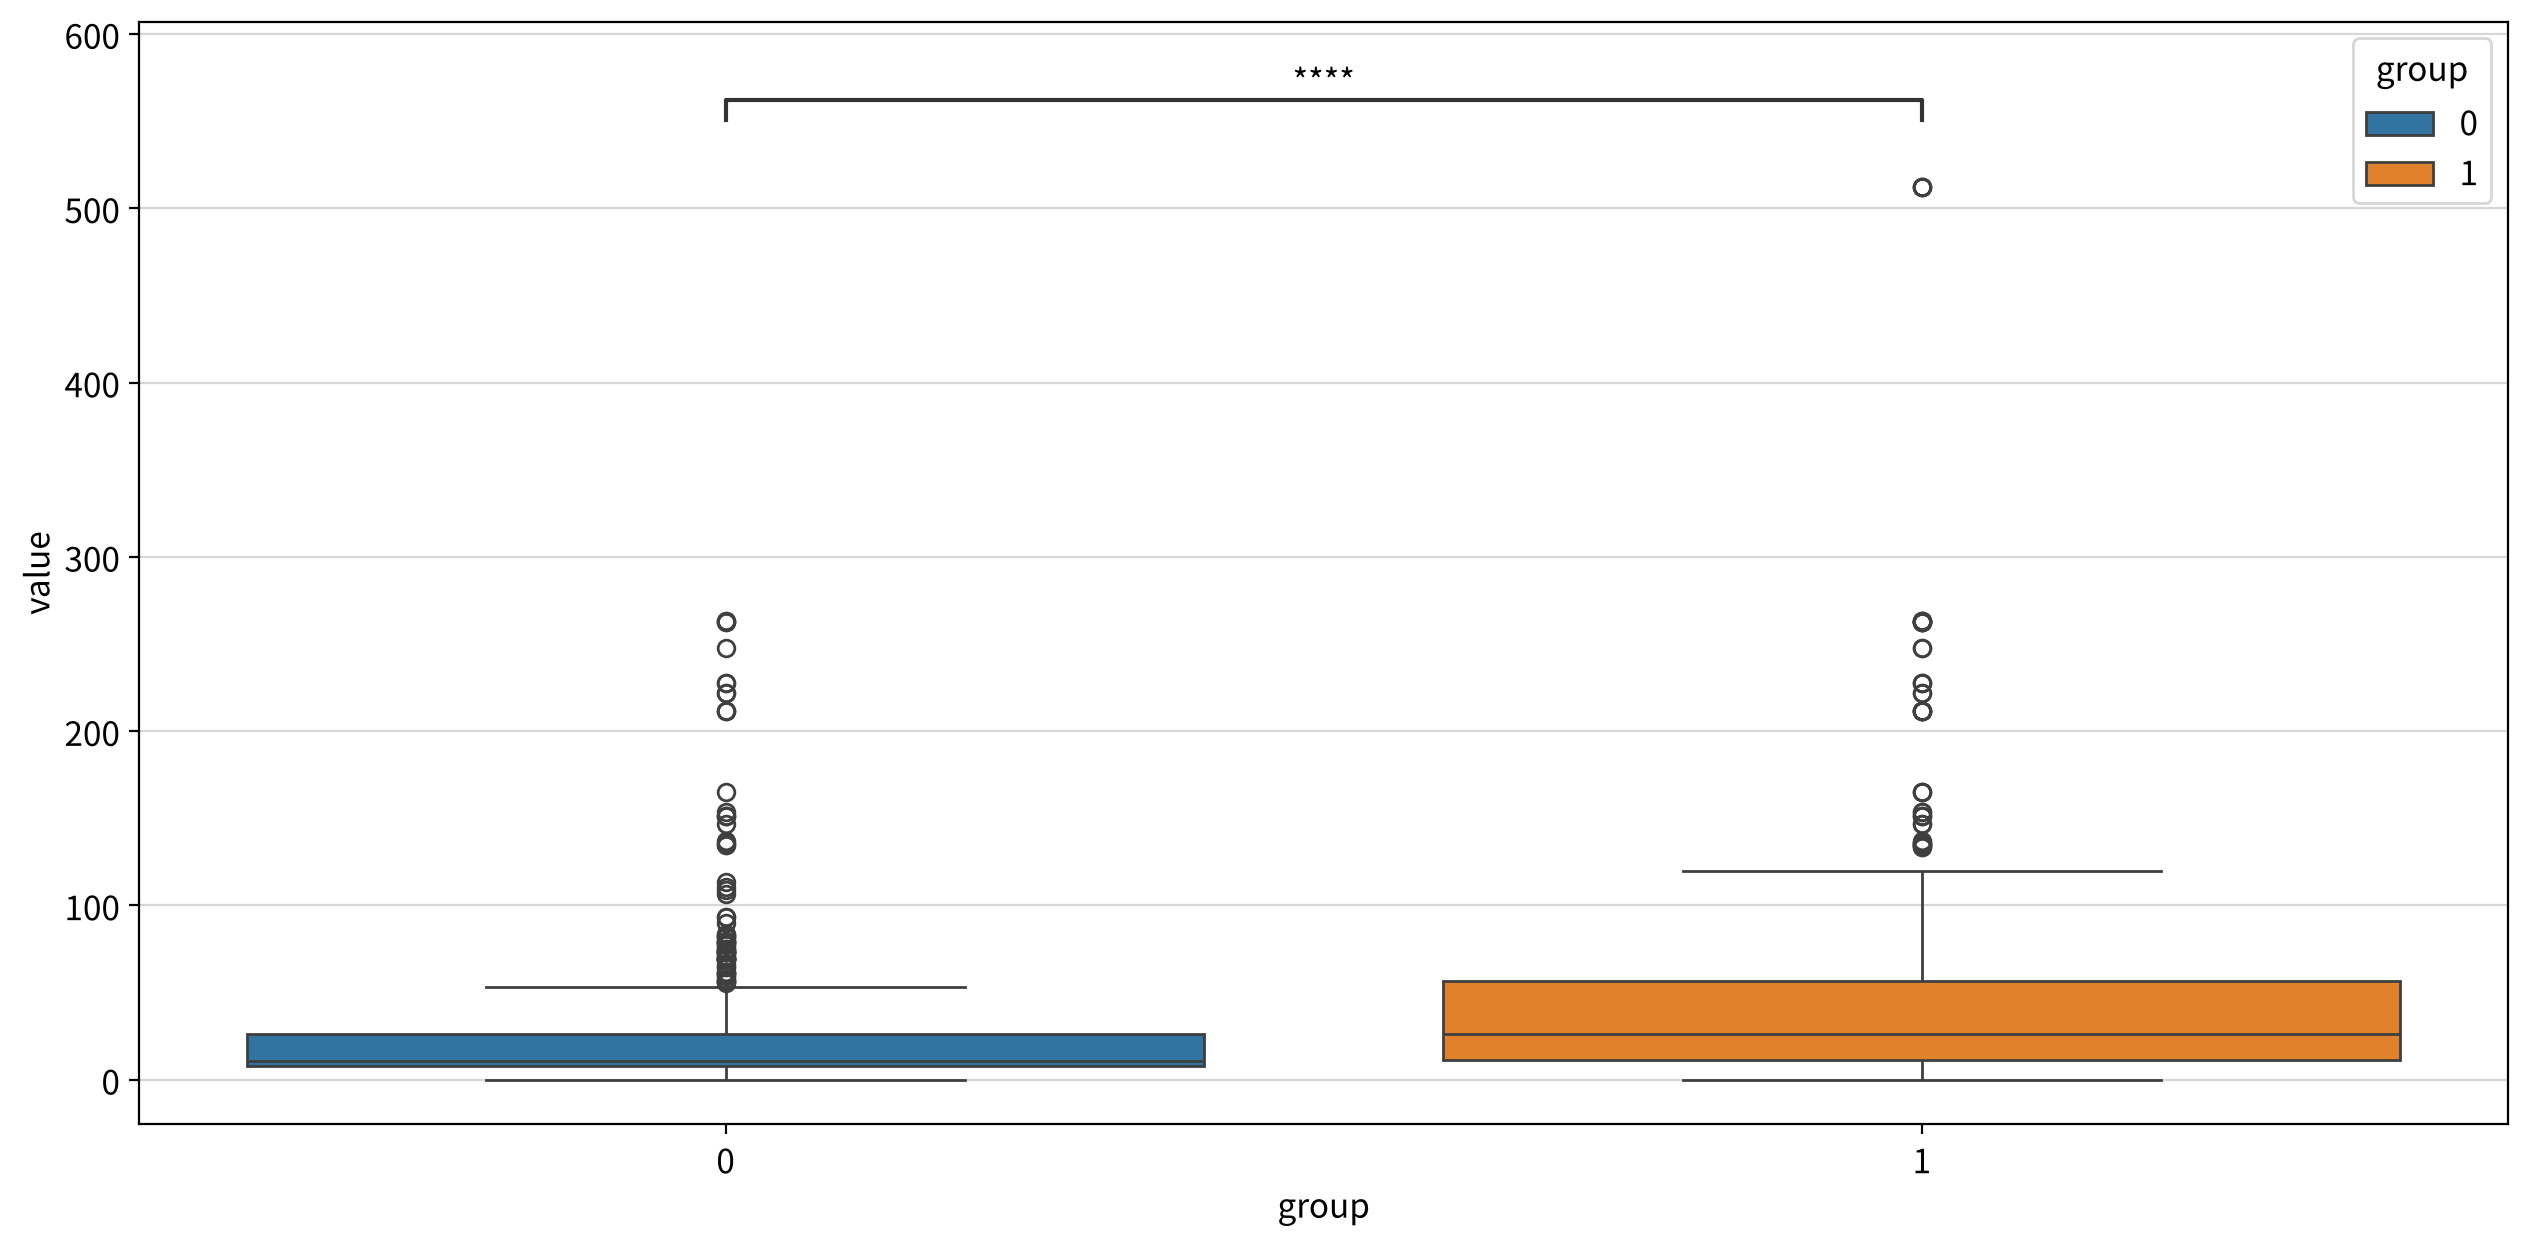

statistic  p-value  significant result
test                alternative                                        
Mann-Whitney U test two-sided   132743.000    0.000         True  0 ≠ 1
                    less        132743.000    0.000         True  0 < 1
                    greater     132743.000    1.000        False  0 ≤ 1

#### ▶︎ FamilySize(동승 가족 수 (SibSp + Parch + 본인)) → Survived

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

0 vs. 1: Mann-Whitney-Wilcoxon test two-sided, P_val:5.986e-12 U_stat=1.603e+05


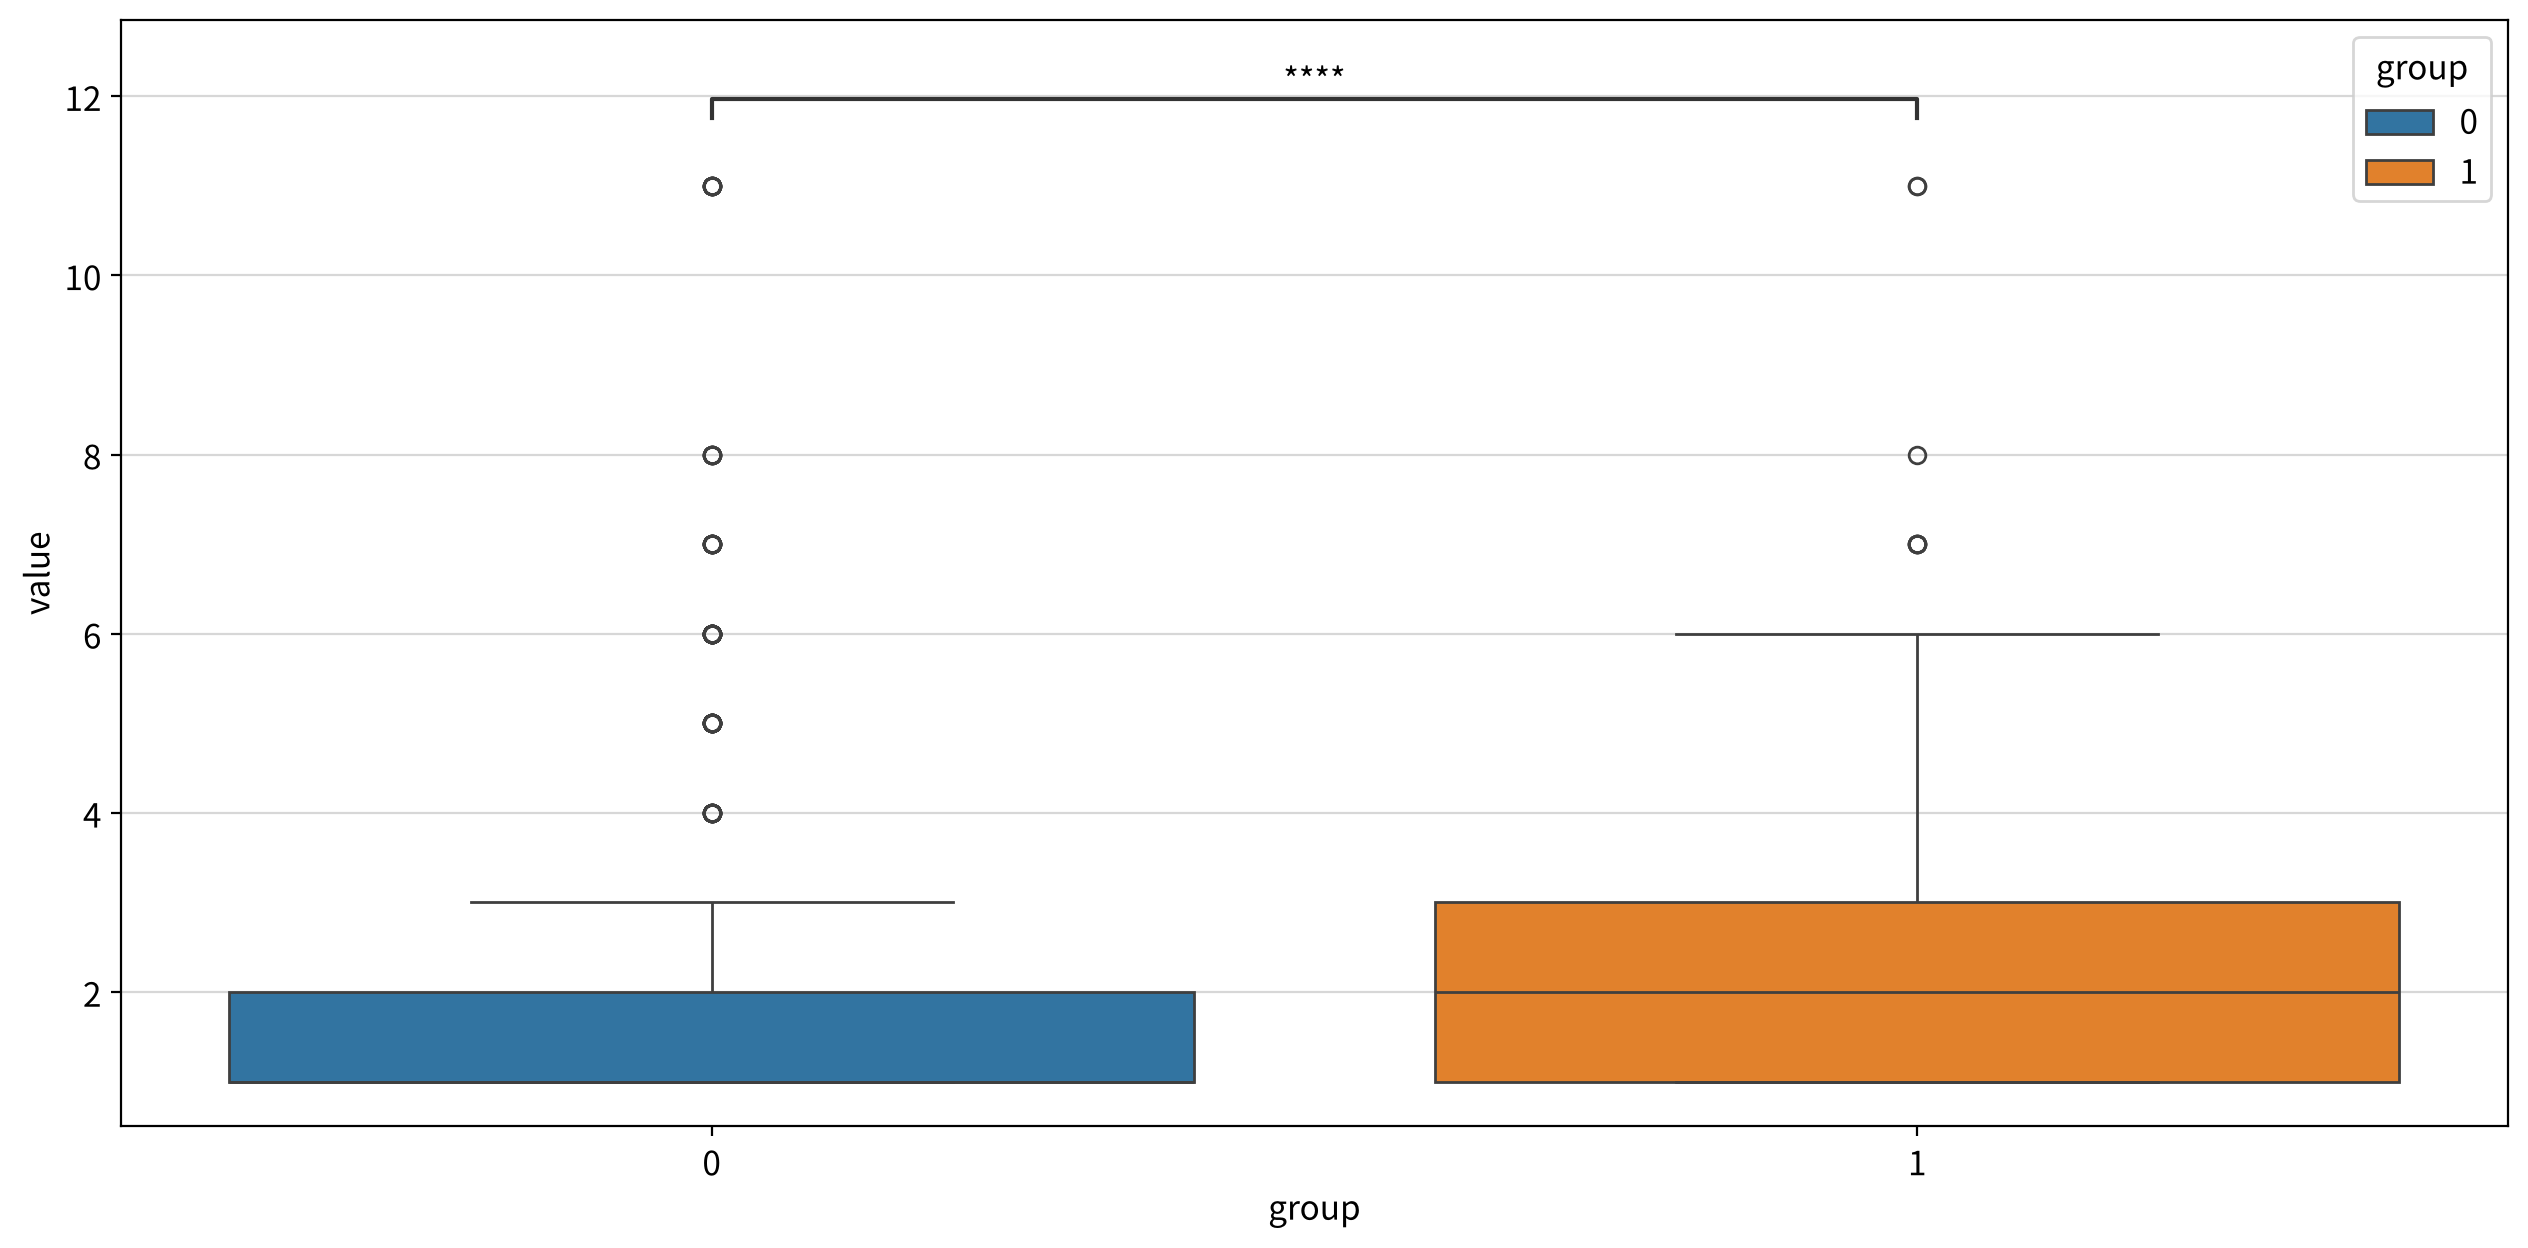

statistic  p-value  significant result
test                alternative                                        
Mann-Whitney U test two-sided   160280.500    0.000         True  0 ≠ 1
                    less        160280.500    0.000         True  0 < 1
                    greater     160280.500    1.000        False  0 ≤ 1

In [20]:
for f in continuous_cols:
    print()
    display(Markdown(f"#### ▶︎ {f}({column_means[f]}) → {target}"))

    # 종속변수(Survived)가 집단 기준이 되므로 hue=target, values=f
    wide_df = my_prep.long2wide(df, hue=target, values=f)
    display(my_stats.test_independent(wide_df, 
                                      group1=wide_df.columns[0], group2=wide_df.columns[1]))

### (2) 가족 규모별 생존율

- 검정은 두 집단의 **중심 위치**만 비교한다. `FamilySize`는 값이 1~11인 카운트 변수라, **값별 생존율의 모양**을 직접 본다.

In [21]:
fs = df.groupby("FamilySize")[target].agg(생존율=lambda s: (s.astype(int) == 1).mean(), 
                                          인원수="size")
fs.T

FamilySize,1,2,3,4,5,6,7,8,11
생존율,0.291,0.532,0.560,0.721,0.227,0.200,0.312,0.125,0.182
인원수,787.000,235.000,159.000,43.000,22.000,25.000,16.000,8.000,11.000


---
##### 💡 인사이트

| 변수 | 검정 방법 | 유의확률 | 방향 | 단독 판정 |
|---|---|---|---|---|
| `Fare` | Mann-Whitney U | < 0.001 | 사망 < 생존 | ✅ 채택 |
| `Parch` | Mann-Whitney U | < 0.001 | 사망 < 생존 | ✅ 채택 |
| `FamilySize` | Mann-Whitney U | < 0.001 | 사망 < 생존 | ✅ 채택 |
| `SibSp` | Mann-Whitney U | < 0.001 | 사망 < 생존 | ✅ 채택 |
| `Age` | Mann-Whitney U | **0.267** | **차이 없음** | 🟡 보류 |

- 정규성이 깨져 **모든 변수에서 Mann-Whitney U**가 선택됐다.
- **`Age`는 p = 0.267로 차이가 없었다.** 하지만 아이는 생존율이 높고 고령 남성은 낮아, 양 끝의 효과가 평균 비교에서 상쇄됐을 수 있다. 결측 263명이 28세로 채워진 영향도 있다. 

<br>

| 가족 수 | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 | 11 |
|---|---|---|---|---|---|---|---|---|---|
| 생존율 | 29.1% | 53.2% | 56.0% | **72.1%** | 22.7% | 20.0% | 31.2% | 12.5% | 18.2% |
| 인원 | 787 | 235 | 159 | 43 | 22 | 25 | 16 | 8 | 11 |

- **`FamilySize`는 "많을수록 생존"이 아니다.** 가족 규모별 생존율을 보면 단독(29.1%)에서 **4명까지 오르다가(72.1%), 5명부터 급락**한다. 검정이 '생존자 쪽이 크다'고 나온 건 단독 승객이 너무 많아서일 뿐, 실제 모양은 **오르다 꺾이는 ∩자**다.

---

### (3) 명목형 × 생존 : 교차분석 (카이제곱 독립성 검정)

- 채택 기준 (명목형) : **유의(p < 0.05) + Cramér's V ≥ 0.1**(효과가 무시할 수준이 아님). 효과크기가 Weak여도 범주별 효과가 다를 수 있으므로 채택하고, 모델에서 최종 판정한다.

#### ▶︎ Pclass(객실 등급 (1=1등급, 2=2등급, 3=3등급)) → Survived

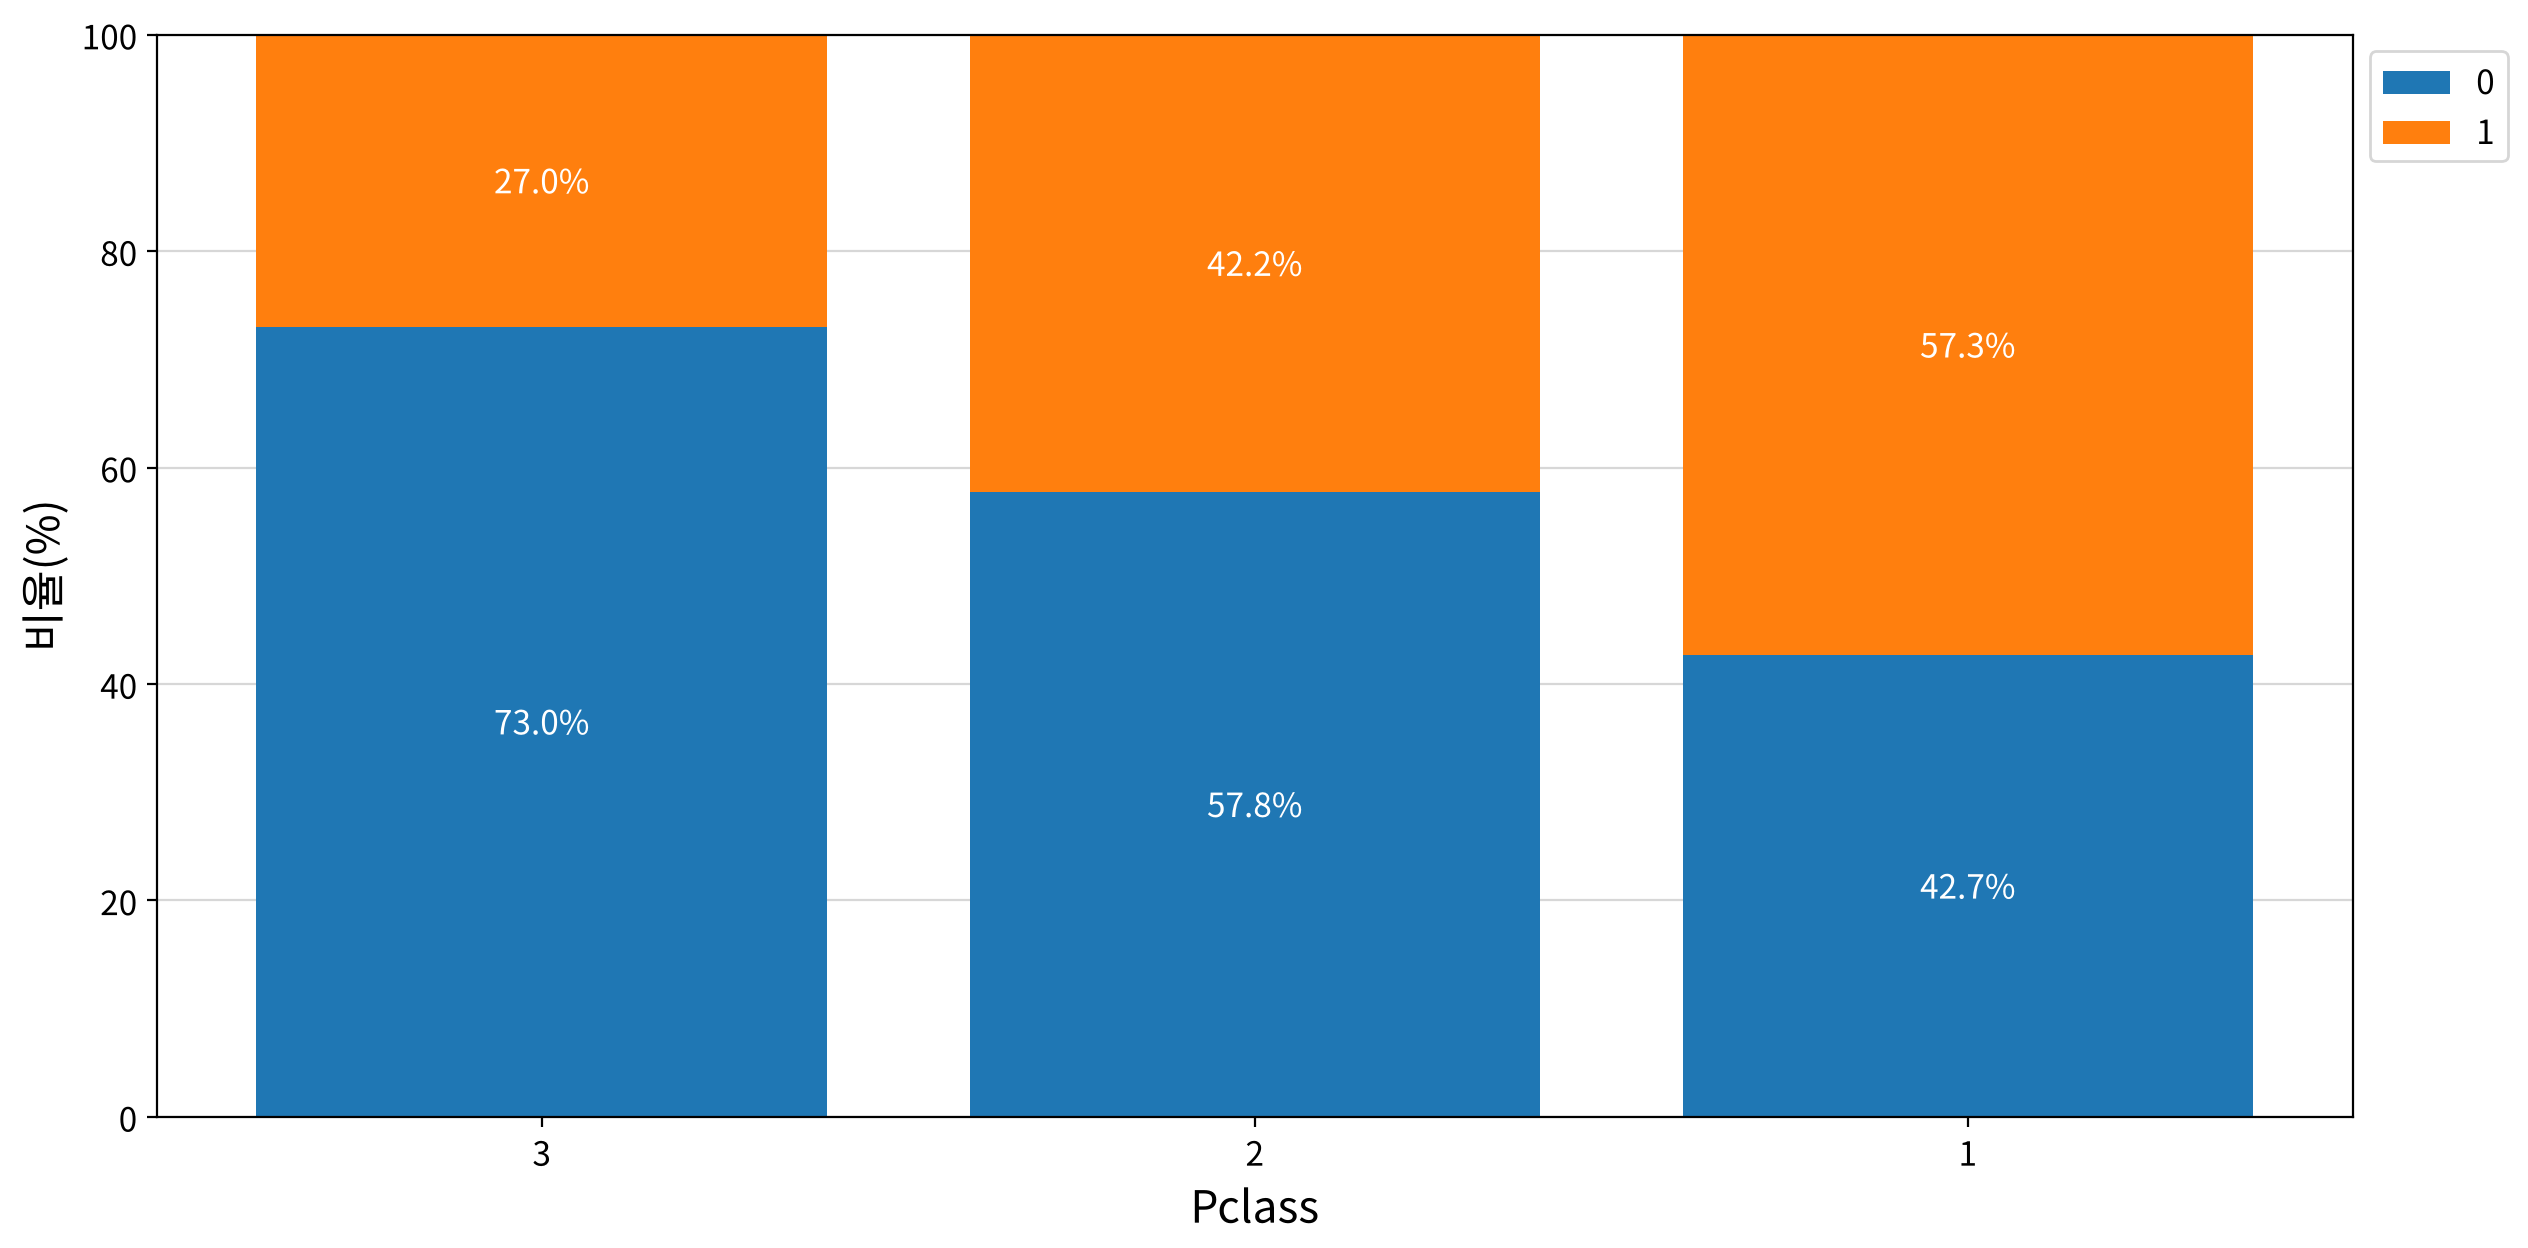

,,test,chi2,dof,p-value,significant,effect(V),strength,min_expected,assumption
row,col,,,,,,,,,
Pclass,Survived,Chi-square test of independence,89.728,2,0.000,True,0.262,Weak,104.350,True


#### ▶︎ Sex(성별 (male, female)) → Survived

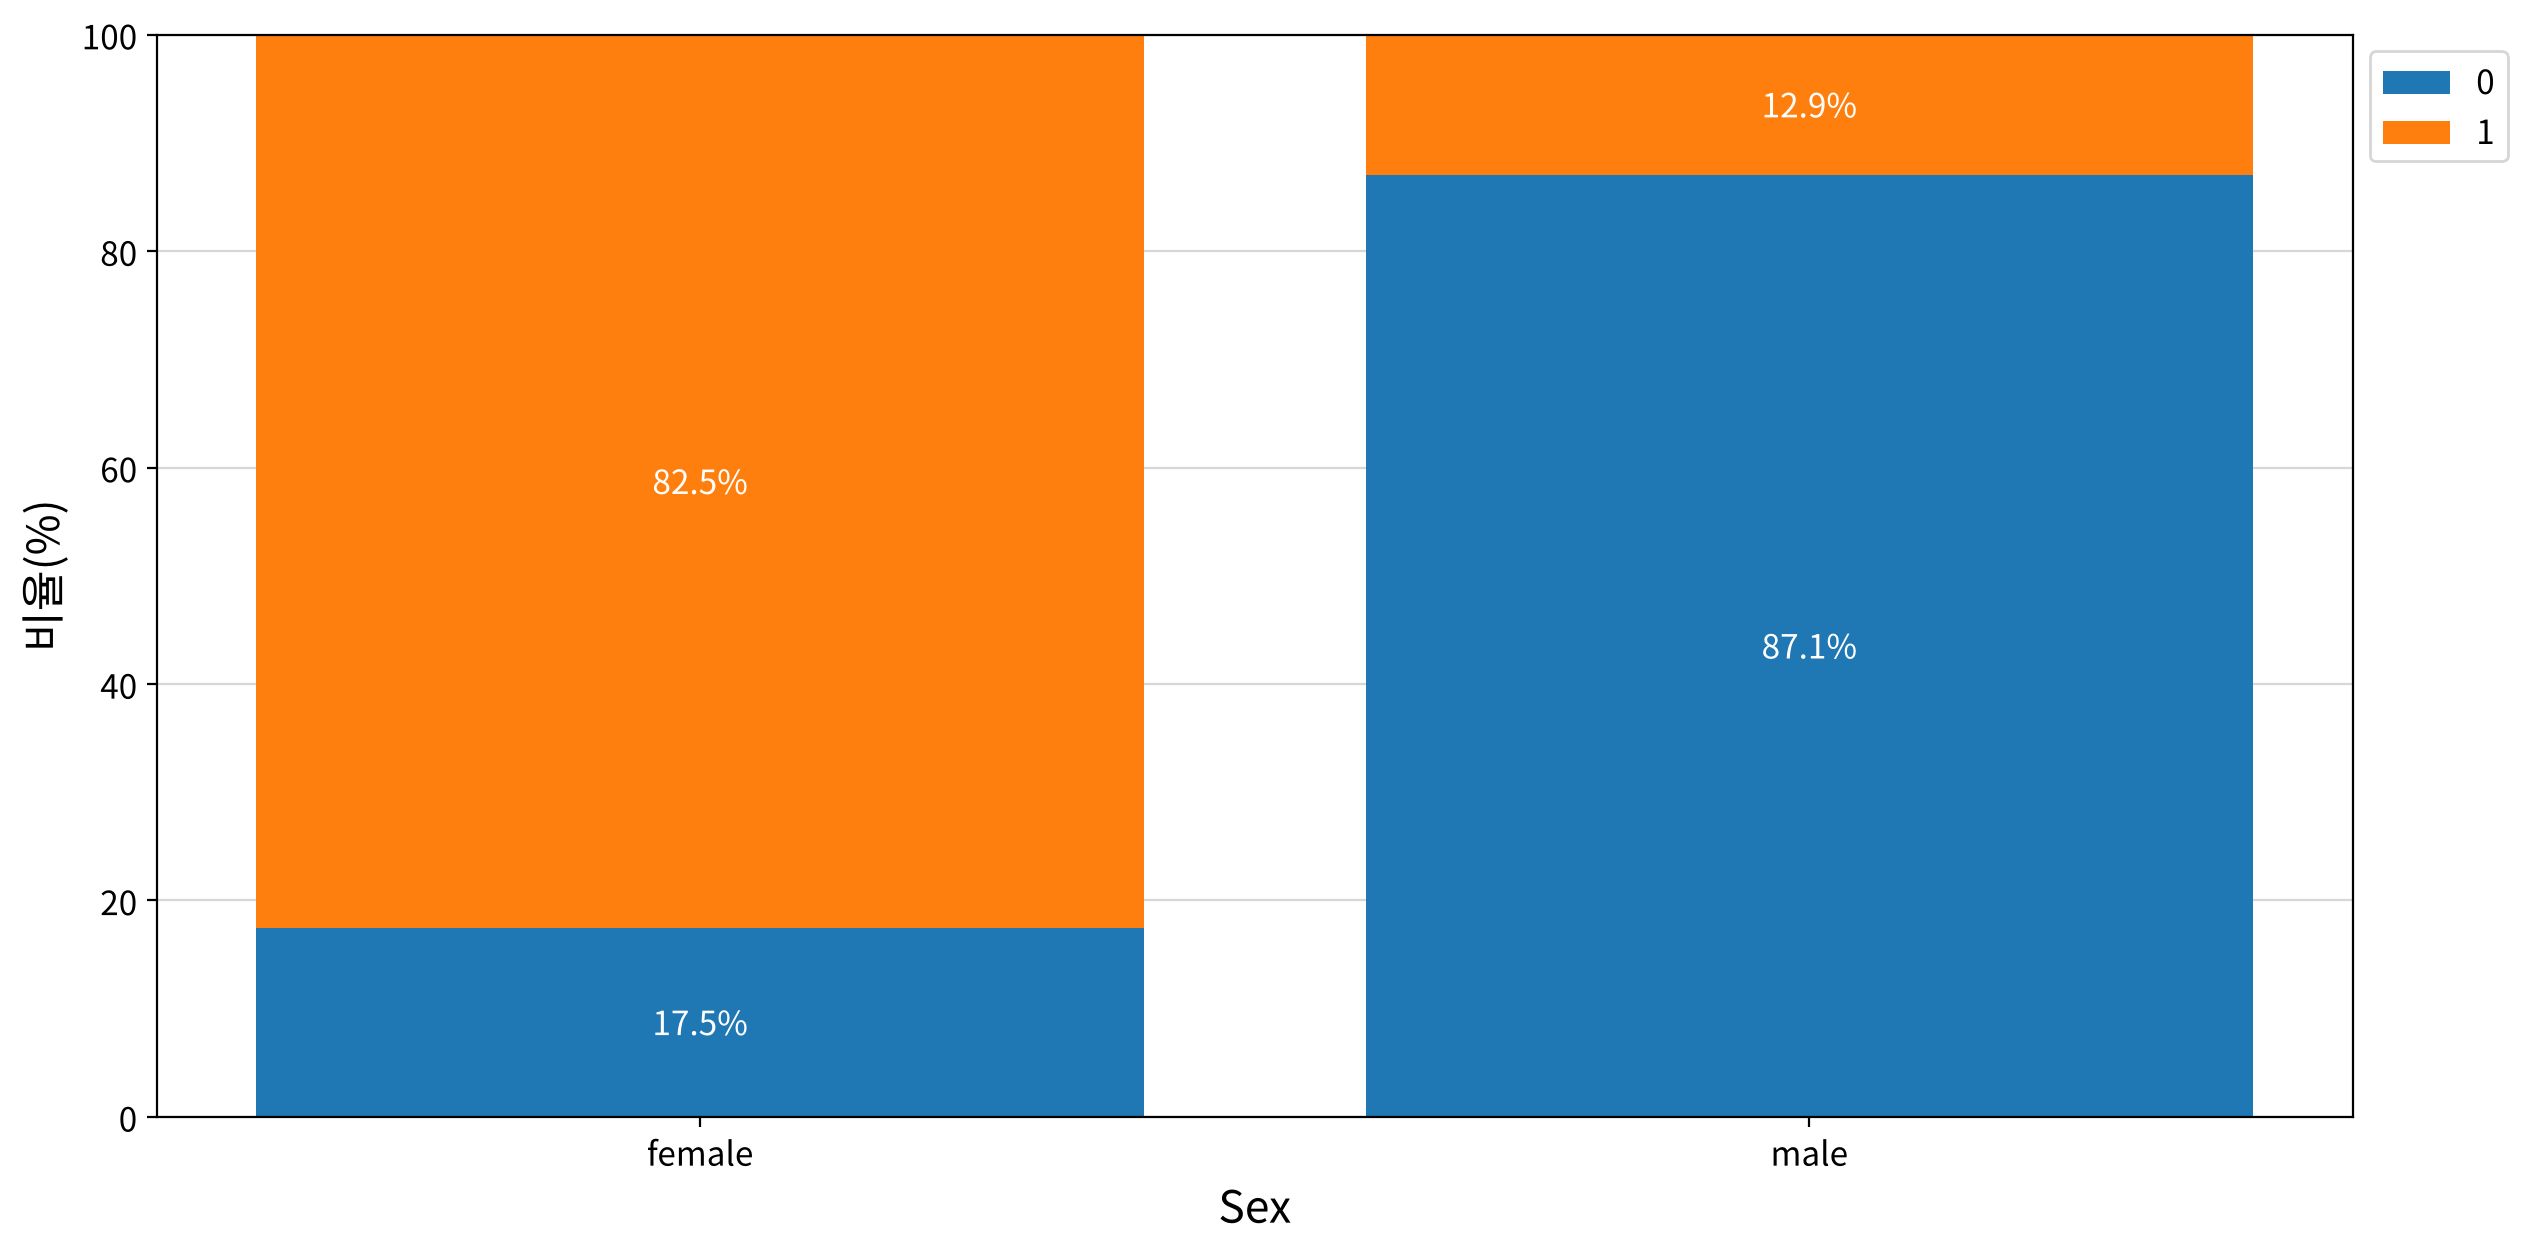

,,test,chi2,dof,p-value,significant,effect(V),strength,min_expected,assumption
row,col,,,,,,,,,
Sex,Survived,Chi-square test of independence,614.166,1,0.000,True,0.686,Strong,174.800,True


#### ▶︎ Embarked(탑승 항구 (C=Cherbourg, Q=Queenstown, S=Southampton)) → Survived

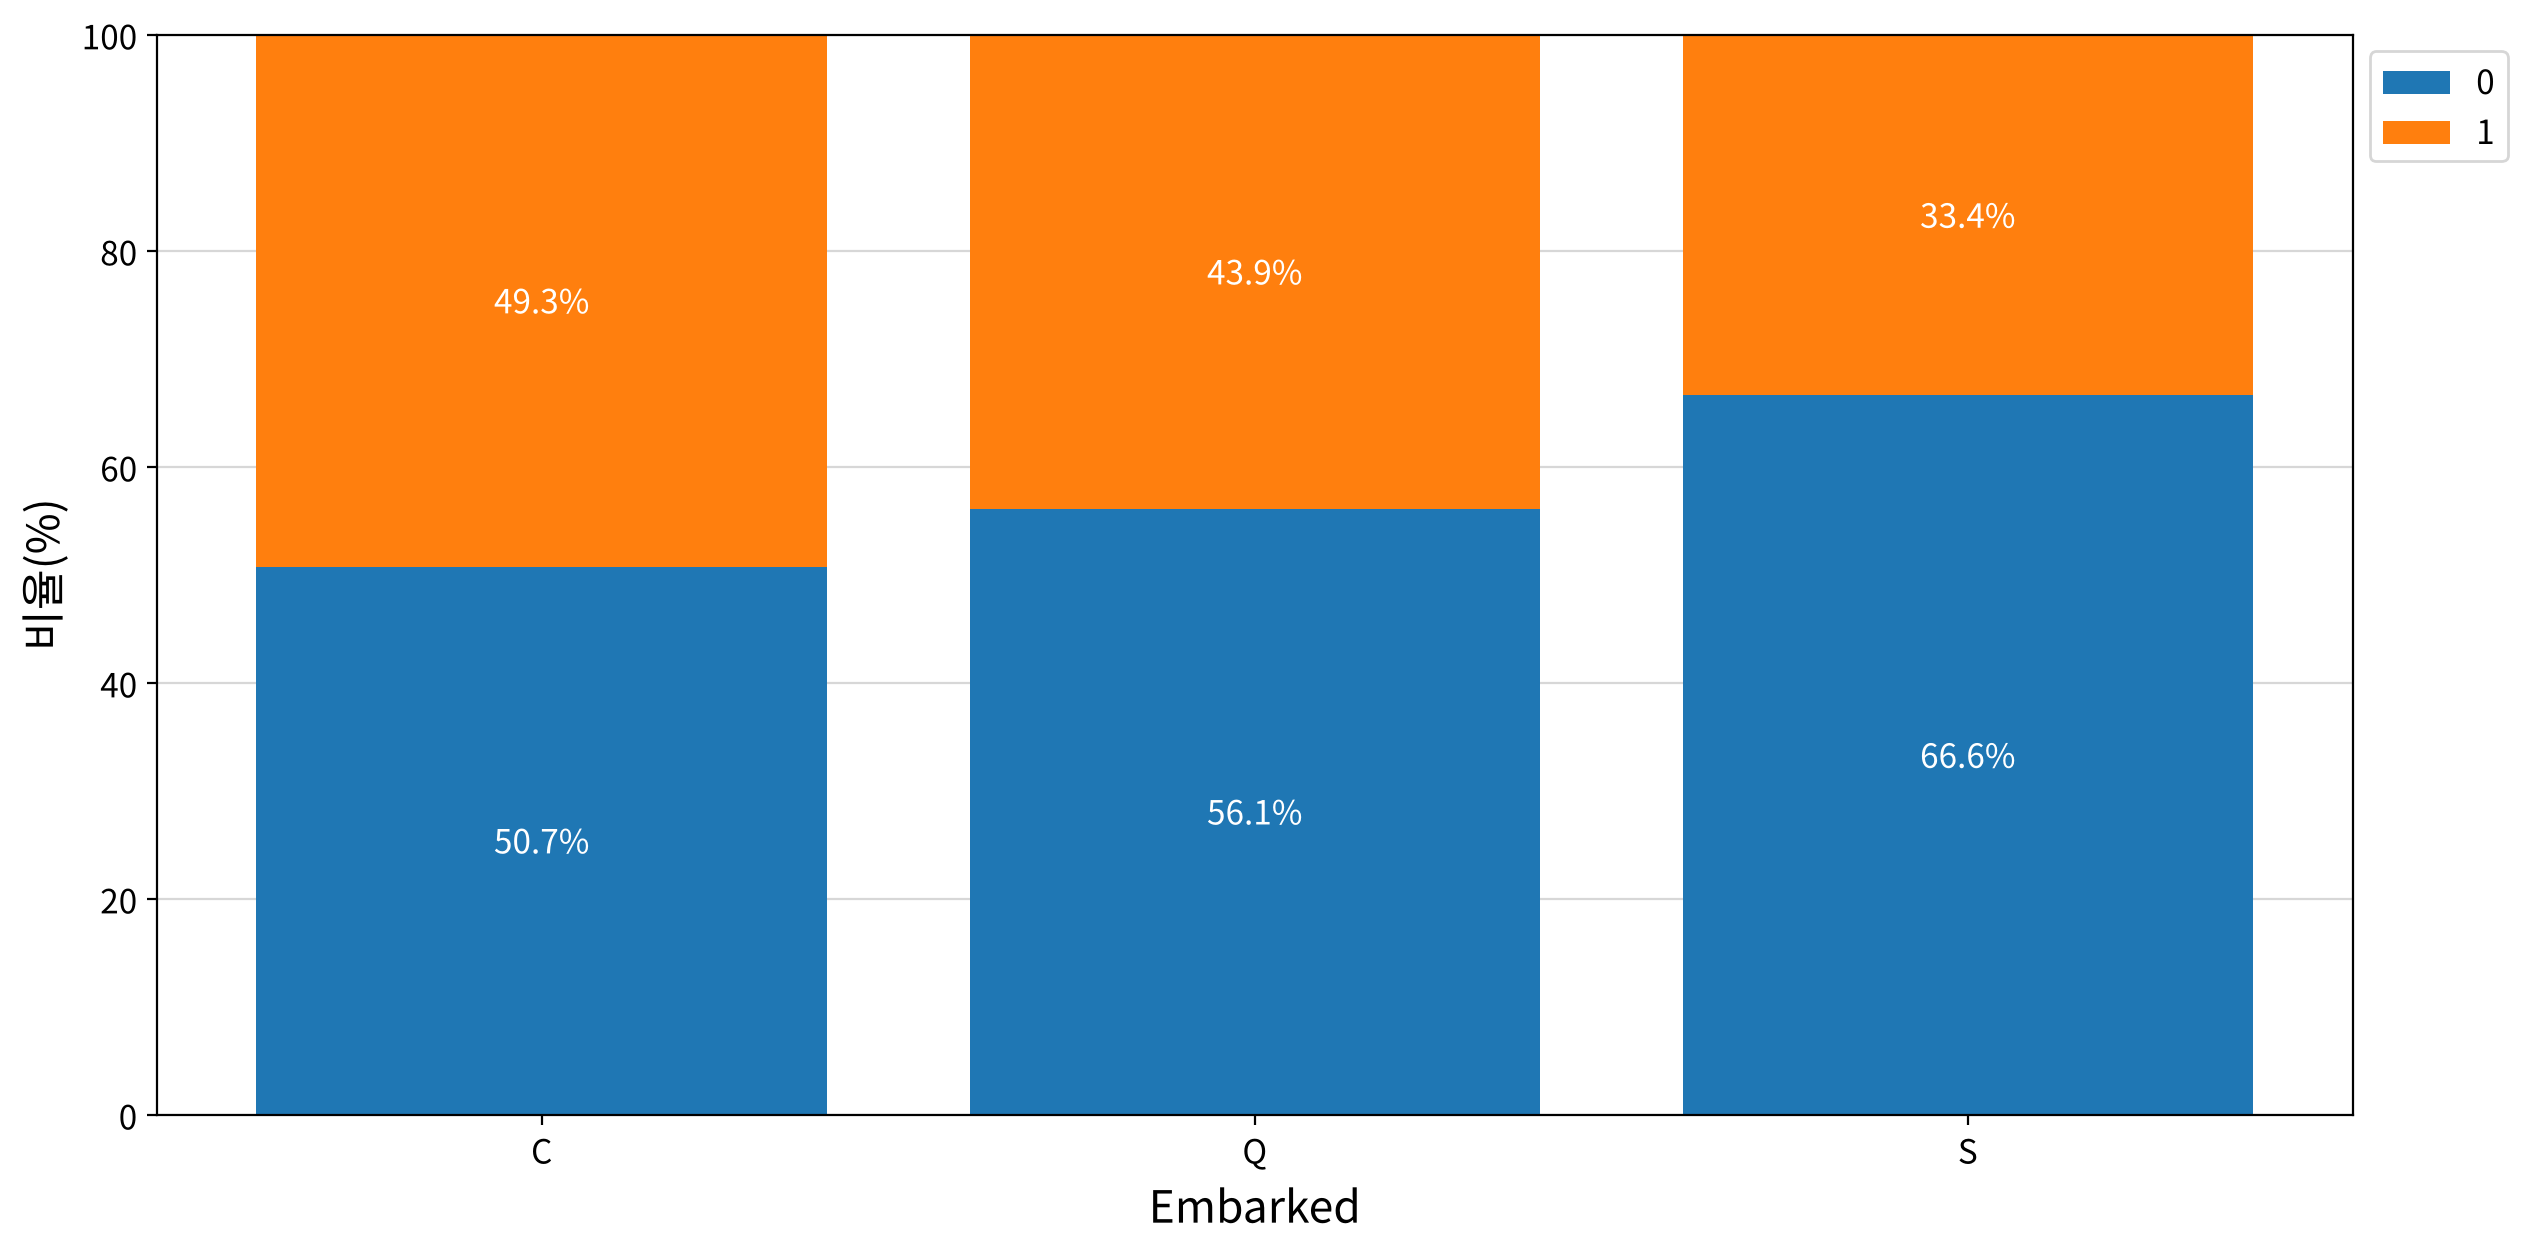

,,test,chi2,dof,p-value,significant,effect(V),strength,min_expected,assumption
row,col,,,,,,,,,
Embarked,Survived,Chi-square test of independence,24.548,2,0.000,True,0.137,Weak,46.340,True


#### ▶︎ Title(이름에서 추출한 호칭 (Mr/Mrs/Miss/Master/Officer)) → Survived

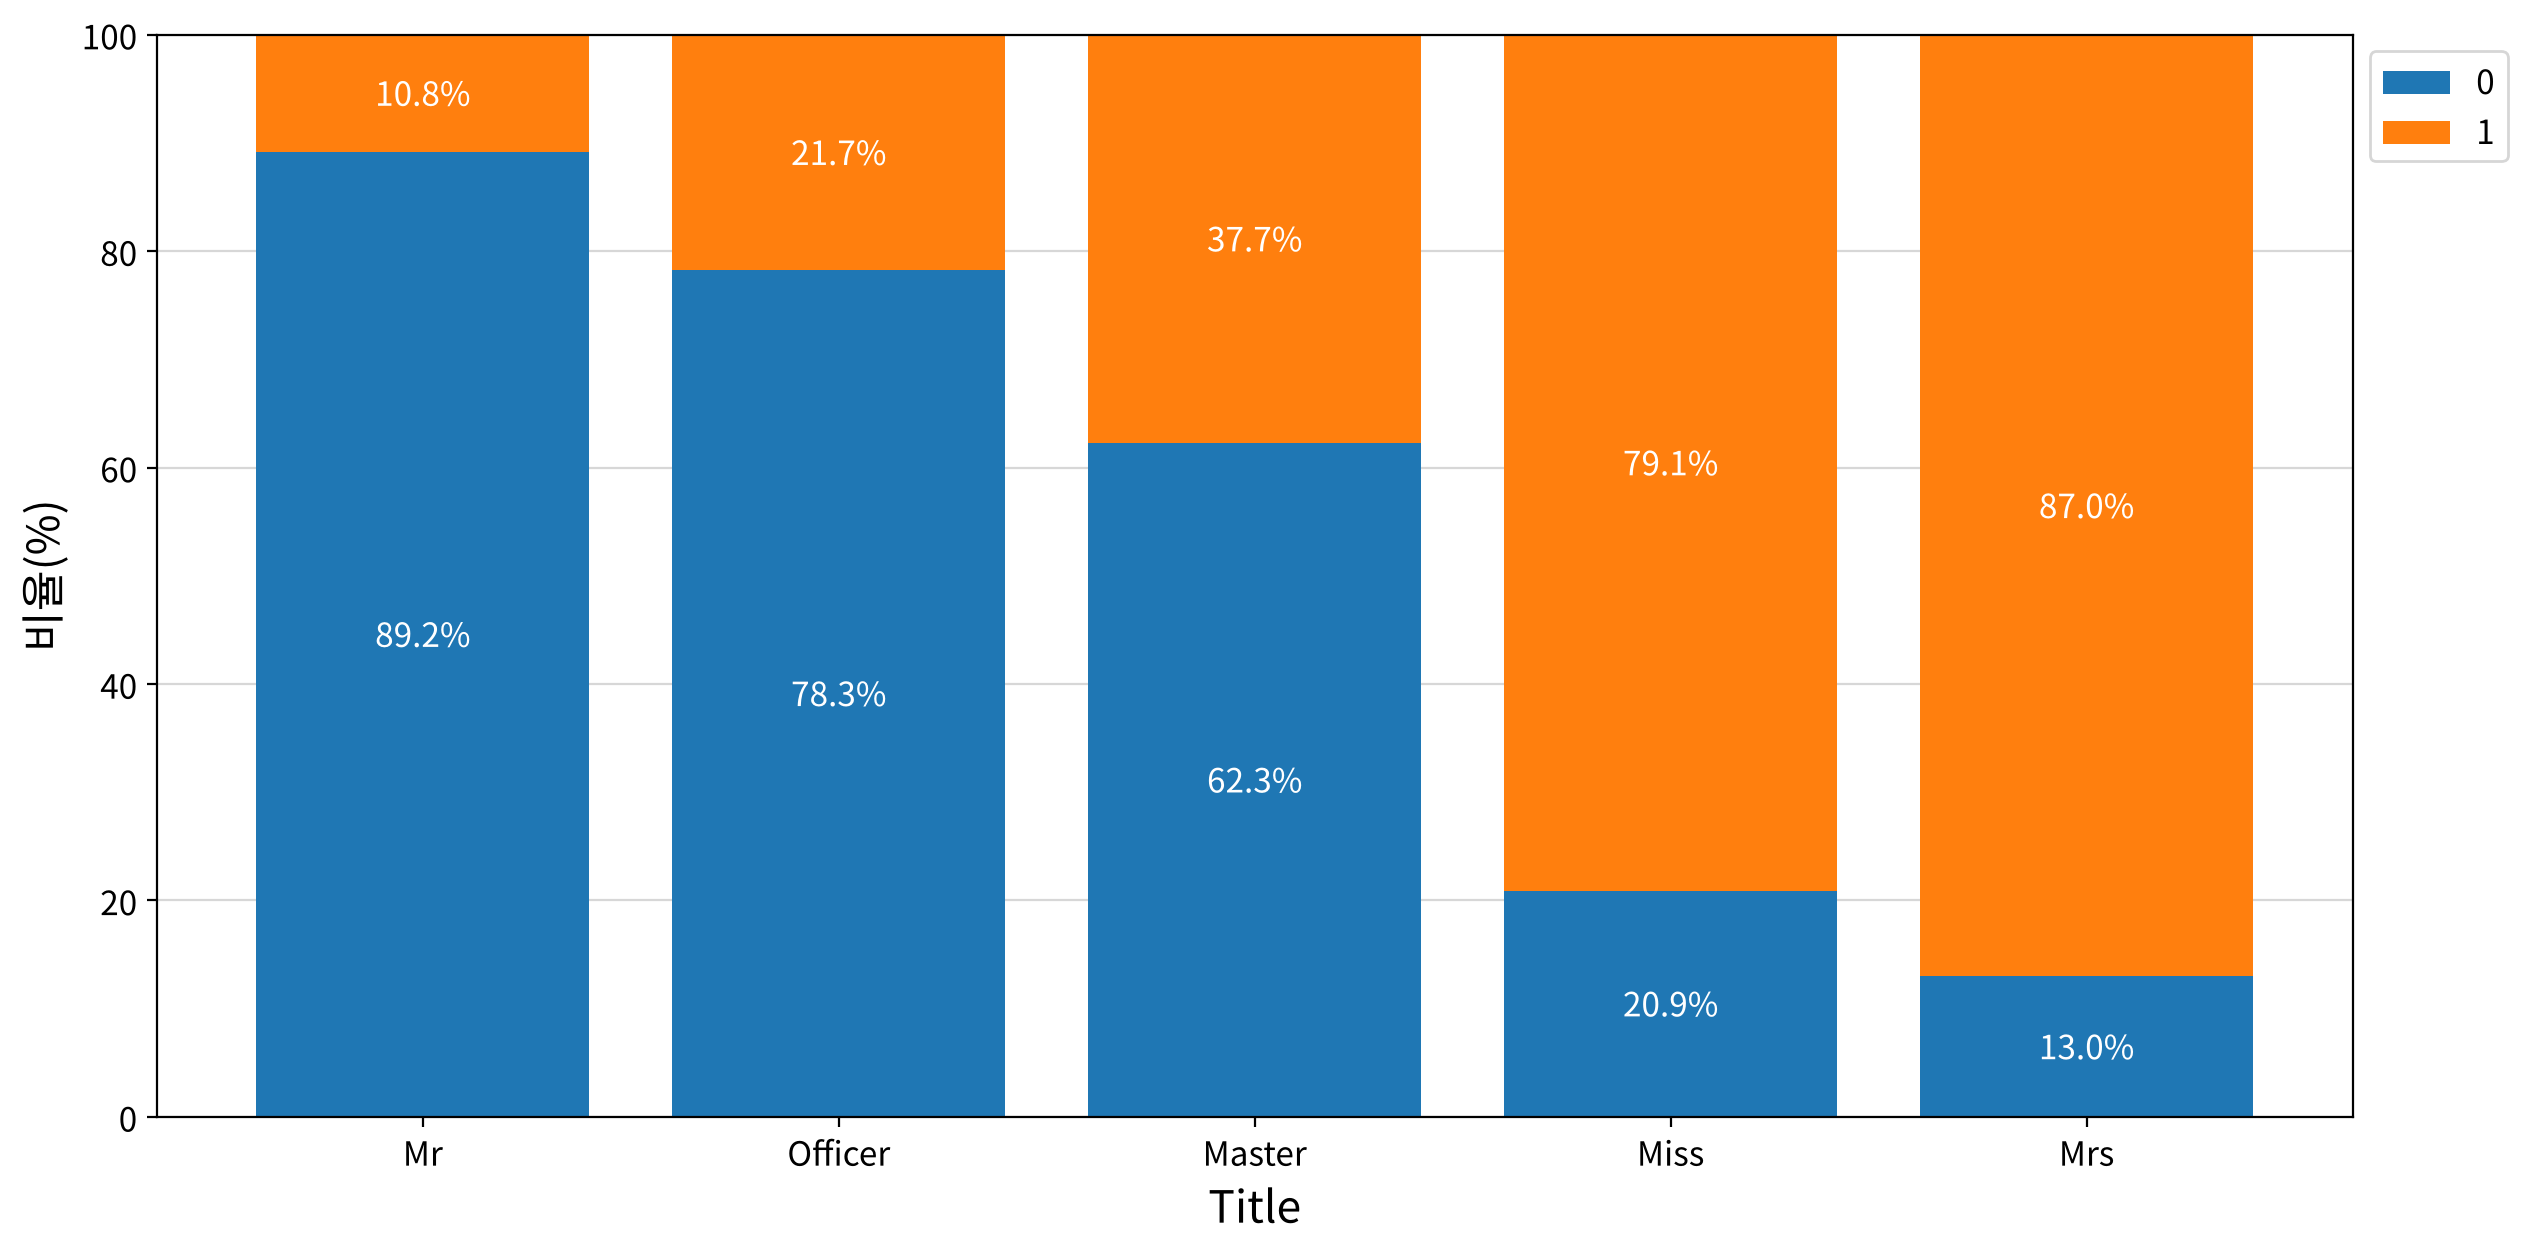

,,test,chi2,dof,p-value,significant,effect(V),strength,min_expected,assumption
row,col,,,,,,,,,
Title,Survived,Chi-square test of independence,635.224,4,0.000,True,0.697,Strong,8.660,True


In [22]:
for n in nominal_cols:
    print()
    display(Markdown(f"#### ▶︎ {n}({column_means[n]}) → {target}"))
    display(my_stats.chi2_independence(df, x=n, y=target))

---

##### 💡 인사이트

- 판정 기준 : **유의(p < 0.05) + Cramér's V ≥ 0.1**(효과가 무시할 수준이 아님) → ✅ 채택

| 판정 | 변수 | χ² | 유의확률 | Cramér's V | 효과 크기 | 범주별 생존율 |
|---|---|---|---|---|---|---|
| ✅ 채택 | **`Title`** | **635.22** | < 0.001 | **0.697** | **Strong** | Mrs 87.0% · Miss 79.1% · **Master 37.7%** · Officer 21.7% · Mr 10.8% |
| ✅ 채택 | `Sex` | 614.17 | < 0.001 | 0.686 | Strong | 여성 82.5% · 남성 12.9% |
| ✅ 채택 | `Pclass` | 89.73 | < 0.001 | 0.262 | Weak | 1등급 57.3% · 2등급 42.2% · 3등급 27.0% |
| ✅ 채택 | `Embarked` | 24.55 | < 0.001 | 0.137 | Weak | C 49.3% · Q 43.9% · S 33.4% |

- **4개 모두 채택**이다. 생존과의 관계가 유의하고, 효과 크기도 모두 무시할 수준(0.1)을 넘는다.
- **`Title`이 `Sex`보다 생존을 더 잘 설명한다**(V 0.697 > 0.686).
- 차이가 나는 자리는 **`Master`(남자아이) 37.7%** 다. `Sex`는 이 61명을 성인 남성과 같은 `male`(12.9%)로 묶었지만, `Title`은 따로 떼어 **약 3배 높은 생존율**을 보여 준다. **'여성과 아이 먼저'의 '아이' 부분이 여기서 드러난다.**
- `Mrs`(87.0%)와 `Miss`(79.1%)도 갈린다. 성별로는 둘 다 82.5%의 `female`이었다.
- 객실 등급은 1등급에서 3등급으로 갈수록 생존율이 **단조 감소**한다.
- 효과 크기가 Weak인 `Pclass` · `Embarked`도 버리지 않는다. 다른 변수를 통제했을 때의 효과는 모델에서 판정한다.
- ⚠️ `Title`과 `Sex`는 같은 정보를 담고 있을 가능성이 크다(남자아이를 빼면 성별과 호칭이 거의 일치). 

---

## 2-3. 다변량 분석 — 독립변수끼리 같은 정보를 담고 있는가?

- 2-2 이변량 분석은 **독립변수 → 생존**의 관계를 봤다. 여기서는 **독립변수끼리**의 관계를 보고, 같은 정보를 담은 변수(공선성)를 찾는다.
- 연속형끼리는 상관분석 · VIF, 명목형끼리는 교차분석을 쓴다.

### (1) 연속형 독립변수끼리 : 상관분석 · VIF

- 파생변수 `FamilySize`는 `SibSp` · `Parch`를 더해 만든 변수라 **원재료와 겹칠 수밖에 없다.**

In [23]:
corr = my_stats.multi_correlation(df, columns=continuous_cols, plot=False)
display(my_stats.correlation_summary(corr))
display(my_stats.compute_vif(df, columns=continuous_cols))

,Age,SibSp,Parch,Fare,FamilySize
Age,1.000,-0.101,-0.181,0.171,-0.133
SibSp,-0.101,1.000,0.438,0.448,0.848
Parch,-0.181,0.438,1.000,0.402,0.796
Fare,0.171,0.448,0.402,1.000,0.524
FamilySize,-0.133,0.848,0.796,0.524,1.000


,max-y,max-coef,count,columns
x,,,,
FamilySize,SibSp,0.848,2,"SibSp, Parch"
SibSp,FamilySize,0.848,1,FamilySize
Parch,FamilySize,0.796,1,FamilySize
Fare,FamilySize,0.524,0,-
Age,Parch,-0.181,0,-


,VIF
FamilySize,1000799917193443.500
Parch,1000799917193443.500
SibSp,1000799917193443.500
Fare,1.119
Age,1.098


### (2) 명목형 독립변수끼리 : `Title` ↔ `Sex`

- 호칭은 성별 정보를 포함한다(Mr · Master는 남성, Miss · Mrs는 여성). 두 독립변수가 얼마나 겹치는지 교차분석으로 본다.

In [24]:
display(my_stats.chi2_independence(df, x="Title", y="Sex", plot=False))
crosstab(df["Title"], df["Sex"])   # 교차표 생성

,,test,chi2,dof,p-value,significant,effect(V),strength,min_expected,assumption
row,col,,,,,,,,,
Title,Sex,Chi-square test of independence,1301.824,4,0.000,True,0.998,Strong,8.170,True


Sex,female,male
Title,,
Mr,0,759
Officer,1,22
Master,0,61
Miss,263,0
Mrs,200,0


---
##### 💡 인사이트

- **`FamilySize` · `SibSp` · `Parch`는 완전히 겹친다.** `FamilySize = SibSp + Parch + 1`이라 VIF가 사실상 무한대다. 셋을 함께 넣으면 계수를 추정할 수 없다.
- `Age` · `Fare`는 다른 변수와 겹치지 않는다(VIF 1.10 · 1.12).
- **`Title`과 `Sex`도 거의 같은 정보다**(Cramér's V = 0.998). `Mr` · `Master`는 전원 남성, `Miss` · `Mrs`는 전원 여성이고, 예외는 여성 `Officer` 1명뿐이다.

---

## 2-4. 최종 변수 선택

| 판정 | 변수 | 검정방법 | 유의확률 | 방향 | 공선성 신호 | 근거 |
|---|---|---|---|---|---|---|
| ✅ 채택 | `Title` | 교차분석 | < 0.001 | Mrs > Miss > Master > Officer > Mr | `Sex`와 V = 0.998 | V = 0.697 (**Strong**) — 가장 높음. 성별에 더해 아이 · 기혼/미혼 여성까지 구분 |
| ✅ 채택 | `Pclass` | 교차분석 | < 0.001 | 1등급 > 3등급 | 없음 | 등급 순서대로 단조 감소 |
| ✅ 채택 | `Embarked` | 교차분석 | < 0.001 | C > S | 없음 | 유의하나 `Pclass`와 겹칠 가능성 → 모델에서 재확인 |
| ✅ 채택 | `Fare` | Mann-Whitney U | < 0.001 | 생존 > 사망 | 없음 (VIF 1.12) | 집단 차이 유의 |
| ✅ 채택 | `FamilySize` | Mann-Whitney U | < 0.001 | 생존 > 사망 (∩자) | `SibSp` · `Parch`와 완전 공선성 | 두 변수를 합친 대표 |
| 🟡 보류 | `Age` | Mann-Whitney U | 0.267 | — | 없음 (VIF 1.10) | 단독 차이는 없으나 억제효과 가능성 → 모델에서 판정 |
| ❌ 제외 | `Sex` | 교차분석 | < 0.001 | 여성 > 남성 | `Title`과 V = 0.998 | `Title`에 포함된 정보 |
| ❌ 제외 | `SibSp` · `Parch` | Mann-Whitney U | < 0.001 | 생존 > 사망 | `FamilySize`와 완전 공선성 (VIF = ∞) | `FamilySize`로 대표 |
| ❌ 제외 | `PassengerId` · `Name` · `Ticket` | — | — | — | — | 식별자 · 텍스트 (PART 1에서 제거) |
| ❌ 제외 | `Cabin` | — | — | — | — | 결측 77.5% (PART 1에서 제거) |

- **`Sex` 대신 `Title`, `SibSp` · `Parch` 대신 `FamilySize`를 쓴다.** 두 경우 모두 '비슷한' 변수가 아니라 **사실상 같은 정보**라, 함께 넣으면 계수를 안정적으로 추정할 수 없다.
- 상관이 강한 정도의 중복은 모델의 VIF · 후진소거에 맡기지만, 이렇게 **수식이나 정의로 겹치는 변수**는 EDA에서 대표 하나만 남긴다.

---
# PART 3. 기준선 모형과 가정 검정

## 3-1. 기준선 모형

### (1) 모델 데이터 준비 

- 종속변수 라벨링

    - 2-4에서 정한 대로 `Sex` · `SibSp` · `Parch`를 뺀다.
    - 종속변수는 **0 / 1 정수**로 라벨링한다. → 이 모형이 예측하는 것은 **P(Survived = 1) = 생존 확률**이다.

In [25]:
df_model = df.drop(columns=["Sex", "SibSp", "Parch"])
df_model = my_prep.labeling(df=df_model, columns=[target])
df_model.head()

Survived (2종): 0=0, 1=1


,Survived,Pclass,Age,Fare,Embarked,FamilySize,Title
0,0,3,22.000,7.250,S,2,Mr
1,1,1,38.000,71.283,C,2,Mrs
2,1,3,26.000,7.925,S,1,Miss
3,1,1,35.000,53.100,S,2,Mrs
4,0,3,35.000,8.050,S,1,Mr


- 이 데이터(`df_model`)를 **모델링용 데이터로 저장**한다. PART 6 머신러닝에서도 같은 데이터를 불러와, 두 분석이 **같은 1,306행 · 같은 변수**에서 출발하게 한다.

In [26]:
df_model.to_excel("titanic_model.xlsx", index=False)

- 더미변수

    - 명목형 변수(`Pclass` · `Embarked` · `Title`)는 **더미변수**(범주별 0 / 1)로 바꿔 넣는다. 숫자(1, 2, 3)로 그대로 넣으면 범주 사이에 **순서와 같은 간격**이 있다고 가정하게 되기 때문이다.
    - `Pclass`는 순서는 있지만 등급 간 간격이 같다는 보장이 없어, 역시 더미로 바꿔 등급마다 효과를 따로 추정한다.
    - 기준 범주는 각각 **3등급 · C(Cherbourg) · Mr**이다. 계수는 모두 이 기준 범주와 비교한 값으로 읽는다.

In [27]:
df_dummy = my_prep.dummies(df=df_model, columns=["Pclass", "Embarked", "Title"])
df_dummy.head()

Pclass (3종) -> 2개: Pclass_2, Pclass_1 (기준: 3 제외)
Embarked (3종) -> 2개: Embarked_Q, Embarked_S (기준: C 제외)
Title (5종) -> 4개: Title_Officer, Title_Master, Title_Miss, Title_Mrs (기준: Mr 제외)

컬럼 수: 7개 -> 12개


,Survived,Age,Fare,FamilySize,Pclass_2,Pclass_1,Embarked_Q,Embarked_S,Title_Officer,Title_Master,Title_Miss,Title_Mrs
0,0,22.000,7.250,2,0,0,0,1,0,0,0,0
1,1,38.000,71.283,2,0,1,0,0,0,0,0,1
2,1,26.000,7.925,1,0,0,0,1,0,0,1,0
3,1,35.000,53.100,2,0,1,0,1,0,0,0,1
4,0,35.000,8.050,1,0,0,0,1,0,0,0,0


### (2) 기준선 모형 적합

In [28]:
fit = my_logit.fit_model(data=df_dummy, y=target)
my_logit.report_variables(fit=fit, data=df_dummy)

,종속변수,독립변수,B,β,표준오차,z,유의확률,B 95% 하한,B 95% 상한,오즈비(OR),OR 95% 하한,OR 95% 상한,공차,VIF
0,Survived,Title_Mrs,4.624,1.666,0.292,15.861,0.000,4.053,5.195,101.889,57.542,180.413,0.830,1.205
1,Survived,Title_Miss,3.895,1.563,0.244,15.995,0.000,3.418,4.372,49.160,30.502,79.232,0.766,1.306
2,Survived,Title_Master,2.494,0.526,0.396,6.292,0.000,1.717,3.271,12.109,5.569,26.333,0.709,1.410
3,Survived,Pclass_1,1.947,0.839,0.286,6.799,0.000,1.386,2.508,7.007,3.997,12.281,0.467,2.139
4,Survived,Pclass_2,0.879,0.360,0.232,3.782,0.000,0.424,1.335,2.409,1.527,3.800,0.829,1.207
5,Survived,Title_Officer,0.400,0.053,0.547,0.731,0.465,-0.673,1.472,1.491,0.510,4.357,0.945,1.058
6,Survived,FamilySize,-0.333,-0.527,0.065,-5.104,0.000,-0.461,-0.205,0.717,0.631,0.815,0.721,1.388
7,Survived,Embarked_Q,0.196,0.057,0.356,0.550,0.583,-0.502,0.893,1.216,0.605,2.443,0.641,1.561
8,Survived,Embarked_S,-0.156,-0.071,0.225,-0.691,0.489,-0.597,0.286,0.856,0.550,1.331,0.662,1.511
9,Survived,Age,-0.022,-0.282,0.008,-2.613,0.009,-0.038,-0.005,0.978,0.962,0.995,0.639,1.565


---
##### 💡 인사이트 — 기준선 모형

| 변수 | 단독 비교 (EDA) | 기준선 모형 (다른 변수 통제) |
|---|---|---|
| `Title` (Mrs · Miss · Master) | 유의 | ✅ 모두 유의 (p < 0.001) |
| `Pclass` (1 · 2등급) | 유의 | ✅ 모두 유의 (p < 0.001) |
| `FamilySize` | 유의 | ✅ 유의 (B = −0.333, p < 0.001) |
| **`Age`** | **유의하지 않음 (p = 0.267)** | ✅ **유의 (B = −0.022, p = 0.009)** |
| `Fare` | 유의 | ❌ 유의하지 않음 (p = 0.226) |
| `Embarked` (S · Q) | 유의 | ❌ 유의하지 않음 (p = 0.489 · 0.583) |
| `Title_Officer` | — | ❌ 유의하지 않음 (p = 0.465) |

- **단독으로는 무관했던 `Age`가 유의해졌다.** 호칭으로 아이(Master)를 따로 통제하자, 같은 호칭 안에서는 **나이가 많을수록 생존에 불리하다**는 효과가 드러났다.
- 반대로 **`Fare`와 `Embarked`는 유의하지 않게 됐다.** 다른 변수와 함께 넣자 효과가 사라졌는데, 요금 · 항구가 담고 있던 정보가 **객실 등급과 겹쳤을 가능성**이 있다.
- **`FamilySize`는 음수**로 나왔다. 가족이 많을수록 불리하다는 뜻인데, EDA의 ∩자(4명까지는 유리)와 맞지 않는다. 직선 하나로 표현하면서 대가족의 강한 불리함이 전체 기울기를 끌어내린 것이다.

---

## 3-2. 가정 검정

### (1) 로짓 선형성 검정 (Box-Tidwell)

- 연속형 변수 x에 `x × ln(x)` 보조항을 넣었을 때 **그 항이 유의하면(p < 0.05) 직선이 아니다.**

In [29]:
my_logit.test_linear(fit=fit, data=df_dummy)

,z,p-value,linearity,위치이동,result
독립변수,,,,,
Age,0.923,0.356,True,False,귀무가설 채택 → 로짓 선형성 위배 근거 없음
Fare,-0.008,0.994,True,True,귀무가설 채택 → 로짓 선형성 위배 근거 없음
FamilySize,0.032,0.974,True,False,귀무가설 채택 → 로짓 선형성 위배 근거 없음


---
##### 💡 인사이트

- 세 변수 모두 **로짓 선형성 위배 근거가 없다**(p ≥ 0.05). 그래서 제곱항 · 로그 같은 처방은 하지 않는다.
- 그런데 `FamilySize`는 EDA에서 분명한 **∩자**(4명까지 상승, 5명부터 급락)를 보였다. Box-Tidwell은 `x × ln(x)` 형태의 완만한 휘어짐을 잡는 검정이라, **특정 지점에서 꺾이는 모양은 잘 잡지 못할 수 있다.**
- → 통계 검정만으로 판단하지 않고, PART 4에서 **도메인 지식으로 가족 규모를 집단화**한 모델과 비교한다.

---

### (2) 독립성 검정 — Durbin-Watson

In [30]:
my_logit.test_independent(fit)

,statistic,independence,result
Durbin-Watson,1.973,True,독립성 만족


---
##### 💡 인사이트

- DW = **1.973**으로 기준 범위(1.5 ~ 2.5) 안에 있다. → **독립성 만족.**
- 1,306명은 서로 다른 승객이고 행 순서에 의미가 없으므로, 자료 수집 설계로 봐도 독립이 타당하다.

---

# PART 4. 로지스틱 회귀 모델링

### (1) 도메인 파생변수 — 가족 규모를 세 집단으로 (`FamilyGroup`)

- EDA에서 생존율은 **1명 → 2~4명에서 오르고, 5명 이상에서 급락**했다. 그런데 직선을 가정한 기준선 모형과 로짓 선형성 검정은 이 모양을 잡지 못했다.
- 그래서 가족 규모를 **단독(1명) · 소가족(2~4명) · 대가족(5명 이상)** 세 집단으로 나눈 명목형 변수로 바꾼다. 범주형이면 집단마다 효과를 따로 추정하므로, 곡선 모양을 가정 없이 담을 수 있다.

In [31]:
df_domain = df_model.drop(columns=["FamilySize"])
df_domain["FamilyGroup"] = cut(df_model["FamilySize"], 
                               bins=[0, 1, 4, 20], labels=["Alone", "Small", "Large"])

df_domain.groupby("FamilyGroup", observed=True)[target].agg(생존율="mean", 인원수="size").T

FamilyGroup,Alone,Small,Large
생존율,0.291,0.561,0.220
인원수,787.000,437.000,82.000


### (2) 전처리 체크포인트 정의

- PART 3의 로짓 선형성 검정에서 위배된 변수가 없어 **처방(`recipe`)이 필요 없다.** 그래서 '가정 반영' 계열 대신, EDA에서 본 가족 규모의 ∩자를 담은 **도메인 파생변수(`FamilyGroup`)** 계열과 비교한다.
- **0~3번은 원본 `FamilySize`(연속형)**, **4~7번은 `FamilyGroup`(도메인 파생변수)** 을 쓴 조합이다. 두 계열의 전처리를 똑같이 맞춰 **파생변수의 순수한 효과**를 본다.
- **공선성 제거(`vif=True`)는 모든 체크포인트에 공통으로 건다.**

In [32]:
# 원본 FamilySize 데이터(df_model)에 적용할 체크포인트
checkpoints = {
    "0_기준선":     dict(vif=True),
    "1_후진소거":   dict(backward=True, vif=True),
    "2_이상치대체": dict(backward=True, outlier=True, vif=True),
    "3_정규화":     dict(backward=True, outlier=True, vif=True, scale=True),
}

# 도메인 파생변수 데이터(df_domain)에 적용할 체크포인트
domain_checkpoints = {
    "4_도메인":           dict(vif=True),
    "5_도메인+후진소거":   dict(backward=True, vif=True),
    "6_도메인+이상치대체": dict(backward=True, outlier=True, vif=True),
    "7_도메인+정규화":     dict(backward=True, outlier=True, vif=True, scale=True),
}

### (3) 체크포인트별 모델 적합

- 이상치 대체는 `Age` · `Fare`에만 적용한다. 카운트 변수(`FamilySize`)에 IQR 대체를 쓰면 4명 이상이 전부 눌려 버린다.

In [33]:
fits = {}        # 적합된 모델을 누적할 딕셔너리

# 원본 FamilySize 데이터
for name in checkpoints:
    print(f"\n▶︎ --- {name} ---")
    fits[name] = my_logit.fit_pipeline(data=df_model, y=target, columns=["Age", "Fare"],
                                       name=name, **checkpoints[name])

# 도메인 파생변수 데이터 (fits 에 이어서 담는다)
for name in domain_checkpoints:
    print(f"\n▶︎ --- {name} ---")
    fits[name] = my_logit.fit_pipeline(data=df_domain, y=target, columns=["Age", "Fare"],
                                       name=name, **domain_checkpoints[name])

print("\n누적된 모델 :", len(fits), "개")


▶︎ --- 0_기준선 ---

완료! 남은 변수: ['Age', 'Embarked_Q', 'Embarked_S', 'FamilySize', 'Fare', 'Pclass_1', 'Pclass_2', 'Title_Master', 'Title_Miss', 'Title_Mrs', 'Title_Officer']
최대 VIF = 2.14


▶︎ --- 1_후진소거 ---

완료! 남은 변수: ['Age', 'Embarked_Q', 'Embarked_S', 'FamilySize', 'Fare', 'Pclass_1', 'Pclass_2', 'Title_Master', 'Title_Miss', 'Title_Mrs', 'Title_Officer']
최대 VIF = 2.14

유의하지 않은 독립변수 제거 → Embarked_Q (p = 0.5826)
유의하지 않은 독립변수 제거 → Title_Officer (p = 0.4609)
유의하지 않은 독립변수 제거 → Fare (p = 0.2507)
유의하지 않은 독립변수 제거 → Embarked_S (p = 0.1726)



▶︎ --- 2_이상치대체 ---

완료! 남은 변수: ['Age', 'Embarked_Q', 'Embarked_S', 'FamilySize', 'Fare', 'Pclass_1', 'Pclass_2', 'Title_Master', 'Title_Miss', 'Title_Mrs', 'Title_Officer']
최대 VIF = 3.94

유의하지 않은 독립변수 제거 → Embarked_Q (p = 0.5507)
유의하지 않은 독립변수 제거 → Title_Officer (p = 0.4163)
유의하지 않은 독립변수 제거 → Embarked_S (p = 0.2736)

▶︎ --- 3_정규화 ---

완료! 남은 변수: ['Age', 'Embarked_Q', 'Embarked_S', 'FamilySize', 'Fare', 'Pclass_1', 'Pclass_2', 'Title_Master', 'Title_Miss', 'Title_Mrs', 'Title_Officer']
최대 VIF = 3.94



유의하지 않은 독립변수 제거 → Embarked_Q (p = 0.5507)
유의하지 않은 독립변수 제거 → Title_Officer (p = 0.4163)
유의하지 않은 독립변수 제거 → Embarked_S (p = 0.2736)

▶︎ --- 4_도메인 ---

완료! 남은 변수: ['Age', 'Embarked_Q', 'Embarked_S', 'FamilyGroup_Large', 'FamilyGroup_Small', 'Fare', 'Pclass_1', 'Pclass_2', 'Title_Master', 'Title_Miss', 'Title_Mrs', 'Title_Officer']
최대 VIF = 2.16


▶︎ --- 5_도메인+후진소거 ---

완료! 남은 변수: ['Age', 'Embarked_Q', 'Embarked_S', 'FamilyGroup_Large', 'FamilyGroup_Small', 'Fare', 'Pclass_1', 'Pclass_2', 'Title_Master', 'Title_Miss', 'Title_Mrs', 'Title_Officer']
최대 VIF = 2.16



유의하지 않은 독립변수 제거 → Embarked_S (p = 0.7478)
유의하지 않은 독립변수 제거 → Title_Officer (p = 0.5154)
유의하지 않은 독립변수 제거 → Embarked_Q (p = 0.2507)
유의하지 않은 독립변수 제거 → FamilyGroup_Small (p = 0.1318)
유의하지 않은 독립변수 제거 → Fare (p = 0.1681)



▶︎ --- 6_도메인+이상치대체 ---

완료! 남은 변수: ['Age', 'Embarked_Q', 'Embarked_S', 'FamilyGroup_Large', 'FamilyGroup_Small', 'Fare', 'Pclass_1', 'Pclass_2', 'Title_Master', 'Title_Miss', 'Title_Mrs', 'Title_Officer']
최대 VIF = 3.68

유의하지 않은 독립변수 제거 → Embarked_S (p = 0.6755)
유의하지 않은 독립변수 제거 → Title_Officer (p = 0.4945)
유의하지 않은 독립변수 제거 → Embarked_Q (p = 0.2375)


유의하지 않은 독립변수 제거 → Fare (p = 0.0595)
유의하지 않은 독립변수 제거 → FamilyGroup_Small (p = 0.2310)

▶︎ --- 7_도메인+정규화 ---

완료! 남은 변수: ['Age', 'Embarked_Q', 'Embarked_S', 'FamilyGroup_Large', 'FamilyGroup_Small', 'Fare', 'Pclass_1', 'Pclass_2', 'Title_Master', 'Title_Miss', 'Title_Mrs', 'Title_Officer']
최대 VIF = 3.68

유의하지 않은 독립변수 제거 → Embarked_S (p = 0.6755)
유의하지 않은 독립변수 제거 → Title_Officer (p = 0.4945)


유의하지 않은 독립변수 제거 → Embarked_Q (p = 0.2375)
유의하지 않은 독립변수 제거 → Fare (p = 0.0595)
유의하지 않은 독립변수 제거 → FamilyGroup_Small (p = 0.2310)

누적된 모델 : 8 개


### (4) 모델 성능 비교

- AUC 1순위 모델과 차이가 5% 이내인 모델 중 **변수가 적은 모델**을 우선한다.

In [34]:
best = my_logit.compare_models(fits)
print("간명성 기준 1순위 :", best.name_)

,변수 수,정확도,정밀도,재현율,F1,AUC,Pseudo R²,AIC,Gap(%)
모델,,,,,,,,,
6_도메인+이상치대체,7,0.872,0.865,0.782,0.822,0.904,0.476,923.279,0.390
7_도메인+정규화,7,0.872,0.865,0.782,0.822,0.904,0.476,923.279,0.390
5_도메인+후진소거,7,0.872,0.865,0.782,0.822,0.904,0.476,923.331,0.390
1_후진소거,7,0.868,0.851,0.787,0.817,0.903,0.466,940.001,0.440
2_이상치대체,8,0.867,0.849,0.787,0.817,0.906,0.468,937.820,0.160
3_정규화,8,0.867,0.849,0.787,0.817,0.906,0.468,937.820,0.160
0_기준선,11,0.870,0.852,0.793,0.821,0.904,0.468,943.999,0.350
4_도메인,12,0.873,0.864,0.787,0.823,0.907,0.479,927.270,0.000


간명성 기준 1순위 : 6_도메인+이상치대체


---
##### 💡 인사이트 — 가족을 '집단'으로 보자 모델이 나아졌다 → 최종 모델은 `5_도메인+후진소거`

| 계열 | 대표 모델 | 변수 수 | AUC | 정확도 | Pseudo R² | AIC |
|---|---|---|---|---|---|---|
| 원본 `FamilySize` (0~3번) | 1_후진소거 | 7 | 0.903 | 0.868 | 0.466 | 940.00 |
| **도메인 `FamilyGroup` (4~7번)** | **5_도메인+후진소거** | **7** | **0.904** | **0.872** | **0.476** | **923.33** |

**계열 비교**
- 같은 변수 7개인데, 가족 규모를 세 집단으로 바꾸자 **AIC가 940.00 → 923.33으로 낮아지고**, Pseudo R²도 0.466 → 0.476으로 올랐다.
- AUC · 정확도는 거의 같다. 예측력보다 **모형의 설명력(적합도)** 이 좋아진 것이다.
- 이상치 대체 · 정규화는 성능을 거의 바꾸지 못했다(AUC 차이 0.003 이하).

**최종 모델 선택**
- `compare_models()`는 **`6_도메인+이상치대체`** 를 1순위로 골랐다. 그런데 `5` · `6` · `7`번은 남은 변수(7개)와 성능이 **사실상 같다**(AUC 0.904 · 정확도 0.872 · Pseudo R² 0.476, AIC 923.28 vs 923.33).
- 세 모델의 차이는 **전처리 단계뿐**이다.
  - `6`번의 이상치 대체 : 성능을 바꾸지 못한 채 실제 나이 · 요금 값만 바꿨다.
  - `7`번의 정규화 : 나이를 '살' 단위가 아닌 다른 단위로 바꿔, "1살 많으면 생존 오즈 1.7% 감소" 같은 바로 와닿는 해석을 할 수 없게 된다.
- 그래서 같은 성능이면 **불필요한 전처리가 없는 `5_도메인+후진소거`** 를 최종 채택한다.
  - → **간명성은 변수 수만이 아니라 전처리 단계에도 적용된다.**

---

### (5) 최종 모델 선택

- 성능이 같다면 불필요한 전처리가 없는 5번을 최종 채택한다

In [35]:
final_name = "5_도메인+후진소거"

final_fit = fits[final_name]
final_data = final_fit.data_[["Survived"] + list(final_fit.model.exog_names[1:])]   # 상수항을 제외하여 최종 모델에 남은 변수만 출력

print("최종 모델 :", final_name)
print("독립변수  :", int(final_fit.df_model), "개")

최종 모델 : 5_도메인+후진소거
독립변수  : 7 개


---
# PART 5. 최종 모델 보고

### (1) 모형 적합도 · 계수 해석

#### ▶ 모형 적합도

 **Note. n = 1306. LL = -453.665, LL-Null = -865.143, LLR χ²(7) = 822.955, p < 0.001, Pseudo R² = 0.476**

Survived를 종속변수로, Age, Pclass_2, Pclass_1, Title_Master, Title_Miss, Title_Mrs, FamilyGroup_Large(을)를 독립변수로 한 이항 로지스틱 회귀분석 결과, 모형은 통계적으로 유의하였다.

> LLR χ²(7) = 822.955, p < 0.001, Pseudo R² = 0.476.

즉, 모형의 유사결정계수는 0.476로 매우 우수한 적합 수준을 보였다.

> ※ Pseudo R²는 선형회귀의 R²처럼 '분산 설명 비율'로 해석하지 않는다. 일반적으로 **0.2~0.4** 구간이면 매우 우수한 적합으로 본다.

#### ▶ 독립변수 보고

,종속변수,독립변수,B,β,표준오차,z,유의확률,B 95% 하한,B 95% 상한,오즈비(OR),OR 95% 하한,OR 95% 상한,공차,VIF
0,Survived,Title_Mrs,4.420,1.592,0.280,15.801,0.000,3.872,4.969,83.120,48.038,143.822,0.898,1.114
1,Survived,Title_Miss,3.949,1.584,0.235,16.828,0.000,3.489,4.409,51.875,32.751,82.167,0.832,1.202
2,Survived,Title_Master,2.337,0.493,0.387,6.030,0.000,1.577,3.096,10.346,4.841,22.111,0.746,1.341
3,Survived,FamilyGroup_Large,-2.236,-0.543,0.337,-6.639,0.000,-2.896,-1.576,0.107,0.055,0.207,0.869,1.151
4,Survived,Pclass_1,2.012,0.866,0.235,8.543,0.000,1.550,2.473,7.476,4.712,11.860,0.748,1.338
5,Survived,Pclass_2,0.717,0.293,0.232,3.095,0.002,0.263,1.171,2.049,1.301,3.227,0.871,1.149
6,Survived,Age,-0.017,-0.224,0.008,-2.121,0.034,-0.034,-0.001,0.983,0.967,0.999,0.661,1.512


- **Age**의 회귀계수는 **B = -0.0175**, 오즈비는 **OR = 0.9827** (95% CI [0.9670, 0.9987])로 나타났으며, 신뢰구간이 1을 포함하지 않아 **Survived**에 유의한 요인임을 의미한다 (**z = -2.12**, **p = .034**). 즉, **Age** 가 1 증가할 때 Survived가 1(사건 발생)이 될 오즈는 평균적으로 약 **1.7% 감소**하는 것으로 해석된다.
- **Pclass_2**의 회귀계수는 **B = 0.7173**, 오즈비는 **OR = 2.0488** (95% CI [1.3010, 3.2266])로 나타났으며, 신뢰구간이 1을 포함하지 않아 **Survived**에 유의한 요인임을 의미한다 (**z = 3.10**, **p = .002**). 즉, **Pclass_2** 에 해당하는 경우(기준 범주 대비) Survived가 1(사건 발생)이 될 오즈는 평균적으로 약 **104.9% 증가**하는 것으로 해석된다.
- **Pclass_1**의 회귀계수는 **B = 2.0117**, 오즈비는 **OR = 7.4757** (95% CI [4.7122, 11.8600])로 나타났으며, 신뢰구간이 1을 포함하지 않아 **Survived**에 유의한 요인임을 의미한다 (**z = 8.54**, **p < .001**). 즉, **Pclass_1** 에 해당하는 경우(기준 범주 대비) Survived가 1(사건 발생)이 될 오즈는 평균적으로 약 **647.6% 증가**하는 것으로 해석된다.
- **Title_Master**의 회귀계수는 **B = 2.3366**, 오즈비는 **OR = 10.3461** (95% CI [4.8411, 22.1112])로 나타났으며, 신뢰구간이 1을 포함하지 않아 **Survived**에 유의한 요인임을 의미한다 (**z = 6.03**, **p < .001**). 즉, **Title_Master** 에 해당하는 경우(기준 범주 대비) Survived가 1(사건 발생)이 될 오즈는 평균적으로 약 **934.6% 증가**하는 것으로 해석된다.
- **Title_Miss**의 회귀계수는 **B = 3.9488**, 오즈비는 **OR = 51.8751** (95% CI [32.7508, 82.1667])로 나타났으며, 신뢰구간이 1을 포함하지 않아 **Survived**에 유의한 요인임을 의미한다 (**z = 16.83**, **p < .001**). 즉, **Title_Miss** 에 해당하는 경우(기준 범주 대비) Survived가 1(사건 발생)이 될 오즈는 평균적으로 약 **5087.5% 증가**하는 것으로 해석된다.
- **Title_Mrs**의 회귀계수는 **B = 4.4203**, 오즈비는 **OR = 83.1201** (95% CI [48.0382, 143.8221])로 나타났으며, 신뢰구간이 1을 포함하지 않아 **Survived**에 유의한 요인임을 의미한다 (**z = 15.80**, **p < .001**). 즉, **Title_Mrs** 에 해당하는 경우(기준 범주 대비) Survived가 1(사건 발생)이 될 오즈는 평균적으로 약 **8212.0% 증가**하는 것으로 해석된다.
- **FamilyGroup_Large**의 회귀계수는 **B = -2.2357**, 오즈비는 **OR = 0.1069** (95% CI [0.0553, 0.2069])로 나타났으며, 신뢰구간이 1을 포함하지 않아 **Survived**에 유의한 요인임을 의미한다 (**z = -6.64**, **p < .001**). 즉, **FamilyGroup_Large** 에 해당하는 경우(기준 범주 대비) Survived가 1(사건 발생)이 될 오즈는 평균적으로 약 **89.3% 감소**하는 것으로 해석된다.

> ※ 오즈비(OR)가 1보다 크면 사건 발생 오즈가 증가, 1보다 작으면 감소함을 뜻한다. 유의확률이 유의수준보다 큰(=유의하지 않은) 변수는 효과가 통계적으로 확인되지 않았으므로 오즈비 해석에 주의한다. 오즈비의 신뢰구간이 1을 포함하지 않으면 해당 유의수준에서 유의하며, 이는 p값 판정과 일치한다. 더미변수의 오즈비는 '기준(drop_first로 제외된) 범주' 대비 값이다.

### ▶ 오즈비 시각화

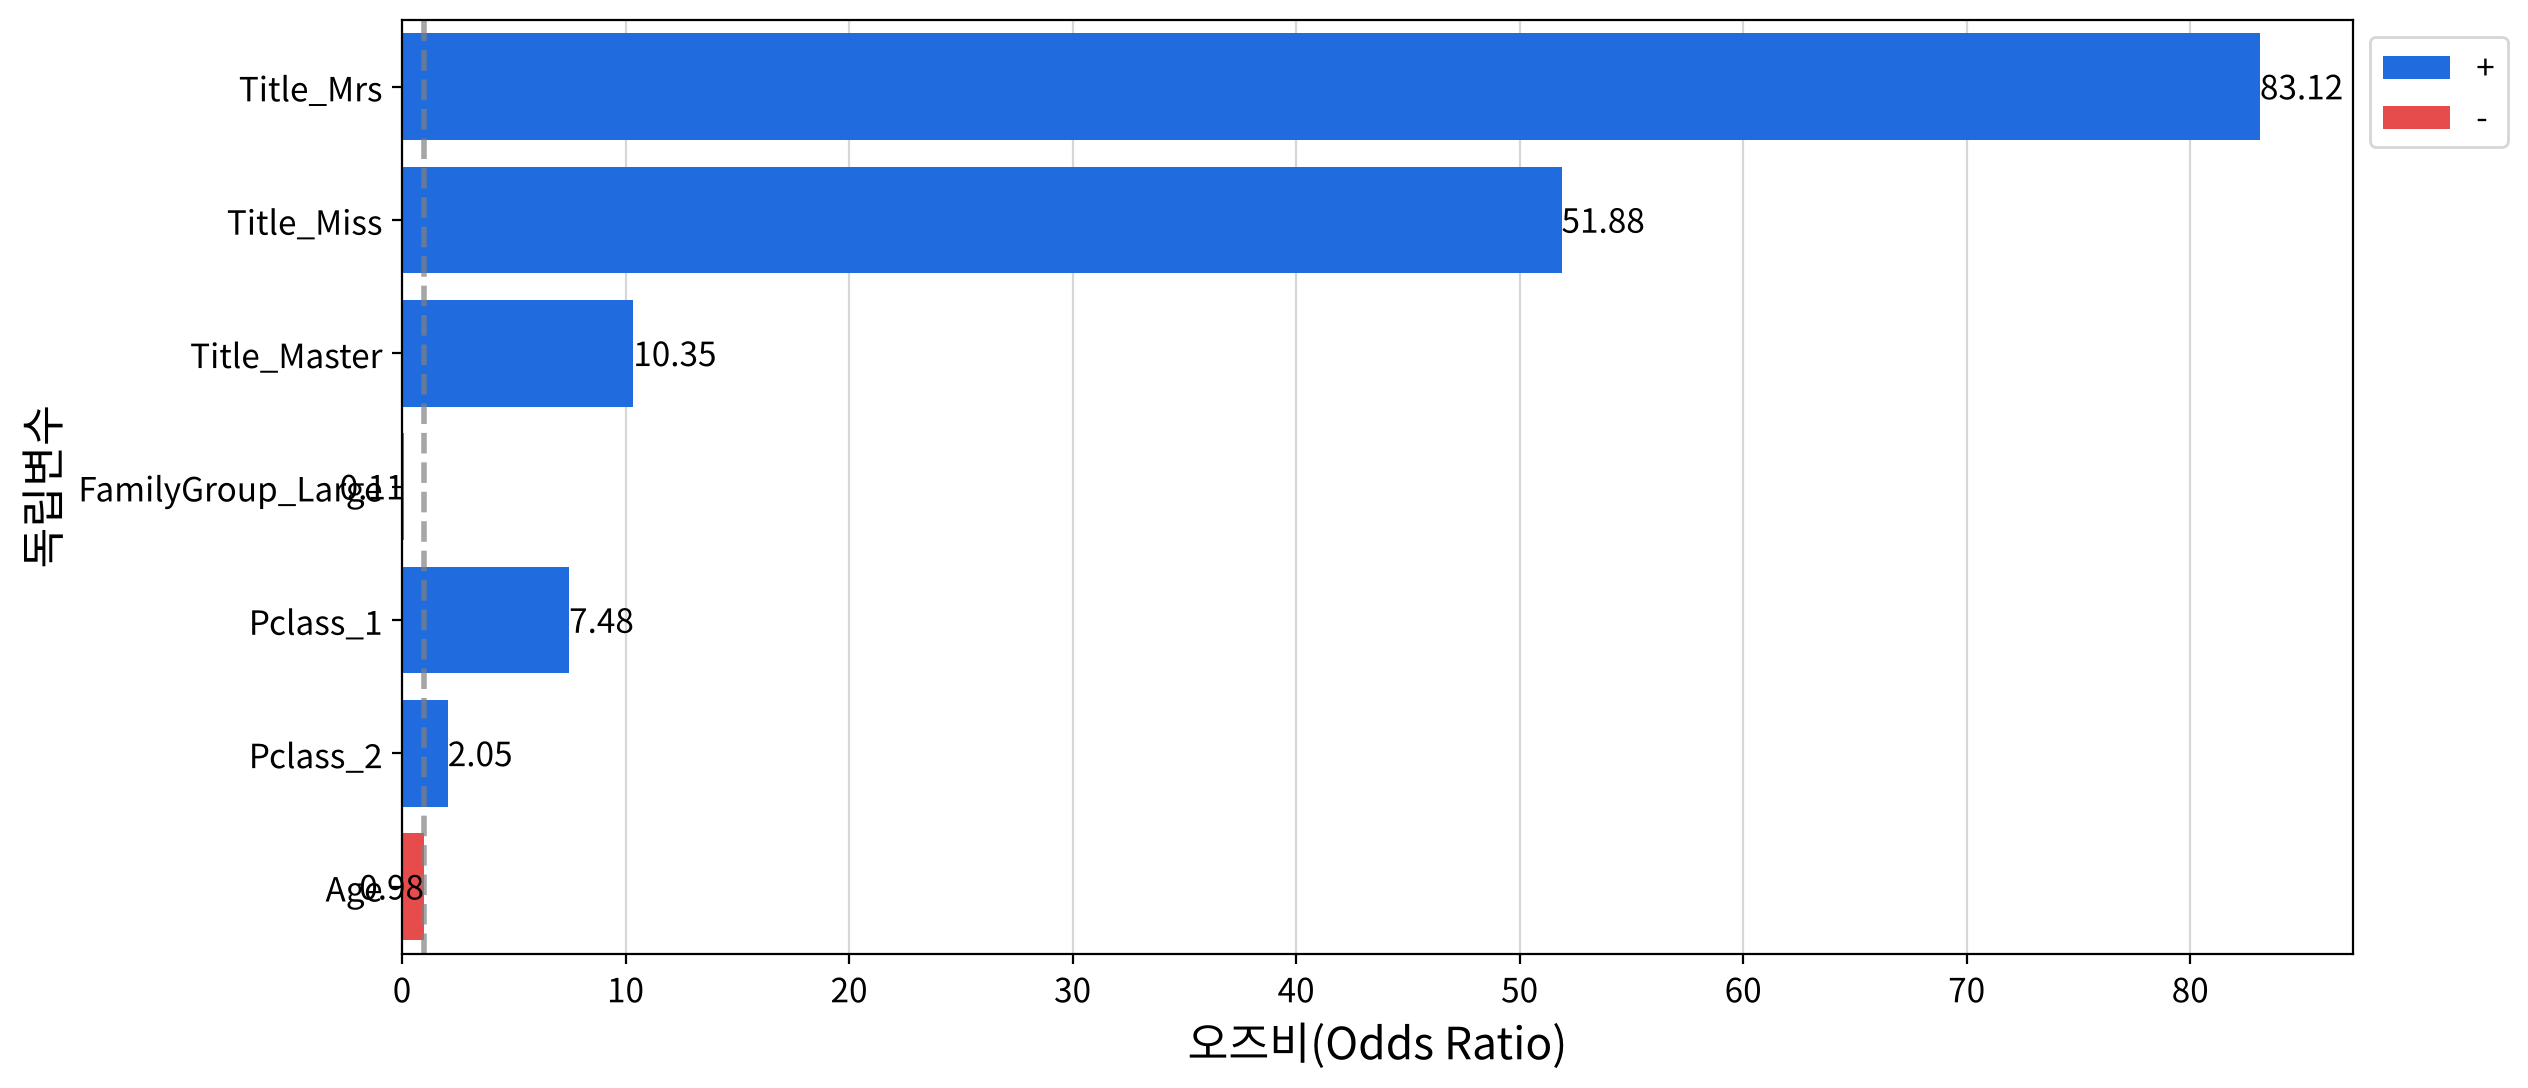

In [36]:
my_logit.auto_logit(data=final_data, y=target)

> ※ **오즈비(OR)의 크기로 변수의 영향력을 비교하면 안 된다.** 변수마다 값의 범위가 달라서, 영향력은 **표준화 계수(β)** 로 비교한다.

---
##### 💡 인사이트 — 최종 모델

**① 적합도**
- **LLR χ²(7) = 822.96, p < .001, Pseudo R² = 0.476** — 로지스틱 회귀에서 0.2~0.4면 매우 좋은 적합으로 보는데, 그보다도 높다.
   - 즉, 독립변수 7개를 넣은 모델이 아무것도 넣지 않은 모델보다 유의하게 낫다.
- **7개 항이 모두 유의**하다(p ≤ 0.034).

<br>

**② 영향력 순위 (표준화 계수 β)**

| 순위 | 변수 | β | 의미 |
|---|---|---|---|
| 1 | `Title_Mrs` | 1.592 | 기혼 여성은 성인 남성보다 생존에 유리 |
| 2 | `Title_Miss` | 1.584 | 미혼 여성은 성인 남성보다 생존에 유리 |
| 3 | `Pclass_1` | 0.866 | 1등급은 3등급보다 생존에 유리 |
| 4 | `FamilyGroup_Large` | −0.543 | 대가족은 단독 · 소가족보다 생존에 불리 |
| 5 | `Title_Master` | 0.493 | 남자아이는 성인 남성보다 생존에 유리 |

- **여성 → 1등급 → 대가족(불리) → 남자아이** 순으로 생존을 갈랐다.
- 남자아이는 β 순위로는 5위지만, 오즈비는 **약 10배**로 1등급(약 7.5배)보다 크다(아래 ③ 참고). 남자아이가 61명(4.7%)뿐이라, **한 사람에게 주는 효과는 크지만 전체 승객 사이의 영향력(β)은 작게** 나타난 것이다.
- 즉 '여성과 아이 먼저'는 데이터에서 **여성 쪽이 훨씬 강하게** 드러난다.

<br>

**③ 오즈비로 해석** (기준 범주 : 성인 남성 `Mr` · `Officer` / 3등급 / 단독 · 소가족)

| 변수 | 오즈비 | 해석 |
|---|---|---|
| `Title_Mrs` | 83.1 | 기혼 여성의 생존 오즈는 성인 남성의 **약 83배** |
| `Title_Miss` | 51.9 | 미혼 여성의 생존 오즈는 성인 남성의 **약 52배** |
| `Title_Master` | 10.3 | 남자아이의 생존 오즈는 성인 남성의 **약 10배** |
| `Pclass_1` | 7.48 | 1등급의 생존 오즈는 3등급의 **약 7.5배** |
| `Pclass_2` | 2.05 | 2등급의 생존 오즈는 3등급의 **약 2배** |
| `FamilyGroup_Large` | 0.107 | 대가족(5명 이상)의 생존 오즈는 **약 89% 낮다** |
| `Age` | 0.983 | 나이 1살 ↑ → 생존 오즈 **1.7% 감소** |

- `Title_Officer`와 `FamilyGroup_Small`은 후진소거로 빠져서, 각각 성인 남성(`Mr`)과 단독 승객과 **같은 기준 범주**로 묶였다.

<br>

**④ EDA와 무엇이 달라졌나**

| 변수 | EDA (단독 비교) | 최종 모델 (다른 변수 통제) |
|---|---|---|
| `Age` | 차이 없음 (p = 0.267) | ✅ 유의 (나이가 많을수록 불리) |
| `Fare` | 유의 | ❌ 후진소거 제거 (p = 0.168) |
| `Embarked` (S · Q) | 유의 | ❌ 후진소거 제거 (p = 0.748 · 0.251) |
| `Title_Officer` | 성인 남성보다 생존율 높음 (21.7% vs 10.8%) | ❌ 후진소거 제거 (p = 0.515, 성인 남성과 차이 없음) |
| `FamilyGroup_Small` | 단독보다 생존율 높음 (56.1% vs 29.1%) | ❌ 후진소거 제거 (p = 0.132, 단독과 차이 없음) |
| `FamilyGroup_Large` | 단독보다 생존율 낮음 (22.0% vs 29.1%) | ✅ 유지 (생존에 뚜렷하게 불리) |

- **나이** : 단독으로 볼 때는 생존과 관계가 없어 보였지만, 다른 변수(호칭 · 객실 등급 등)와 함께 모델에 넣자 **나이가 많을수록 생존에 불리하다**는 효과가 나타났다.
- **요금 · 항구 · Officer · 소가족** : 단독으로 볼 때는 생존과 관계가 있어 보였지만, 다른 변수와 함께 넣자 **효과가 사라졌다.** 이 변수들이 담고 있던 정보가 다른 변수와 겹쳤을 가능성이 있다.
- 끝까지 남은 것은 **호칭 · 객실 등급 · 대가족 · 나이**이고, 그중 **대가족(5명 이상)이 생존에 불리하다**는 것이 가족 규모에서 남은 결과다.

---

### (2) 분류 성능 평가

,예측 0 (Negative),예측 1 (Positive)
실제 0 (Negative),754,60
실제 1 (Positive),107,385


,정확도(Accuracy),정밀도(Precision),"재현율(Recall,TPR)","위양성율(Fallout,FPR)","특이성(Specificity,TNR)",F1,AUC,AUC 판단,진단오즈비(DOR)
performance,0.872,0.865,0.783,0.074,0.926,0.822,0.904,판별력 매우 우수,45.217


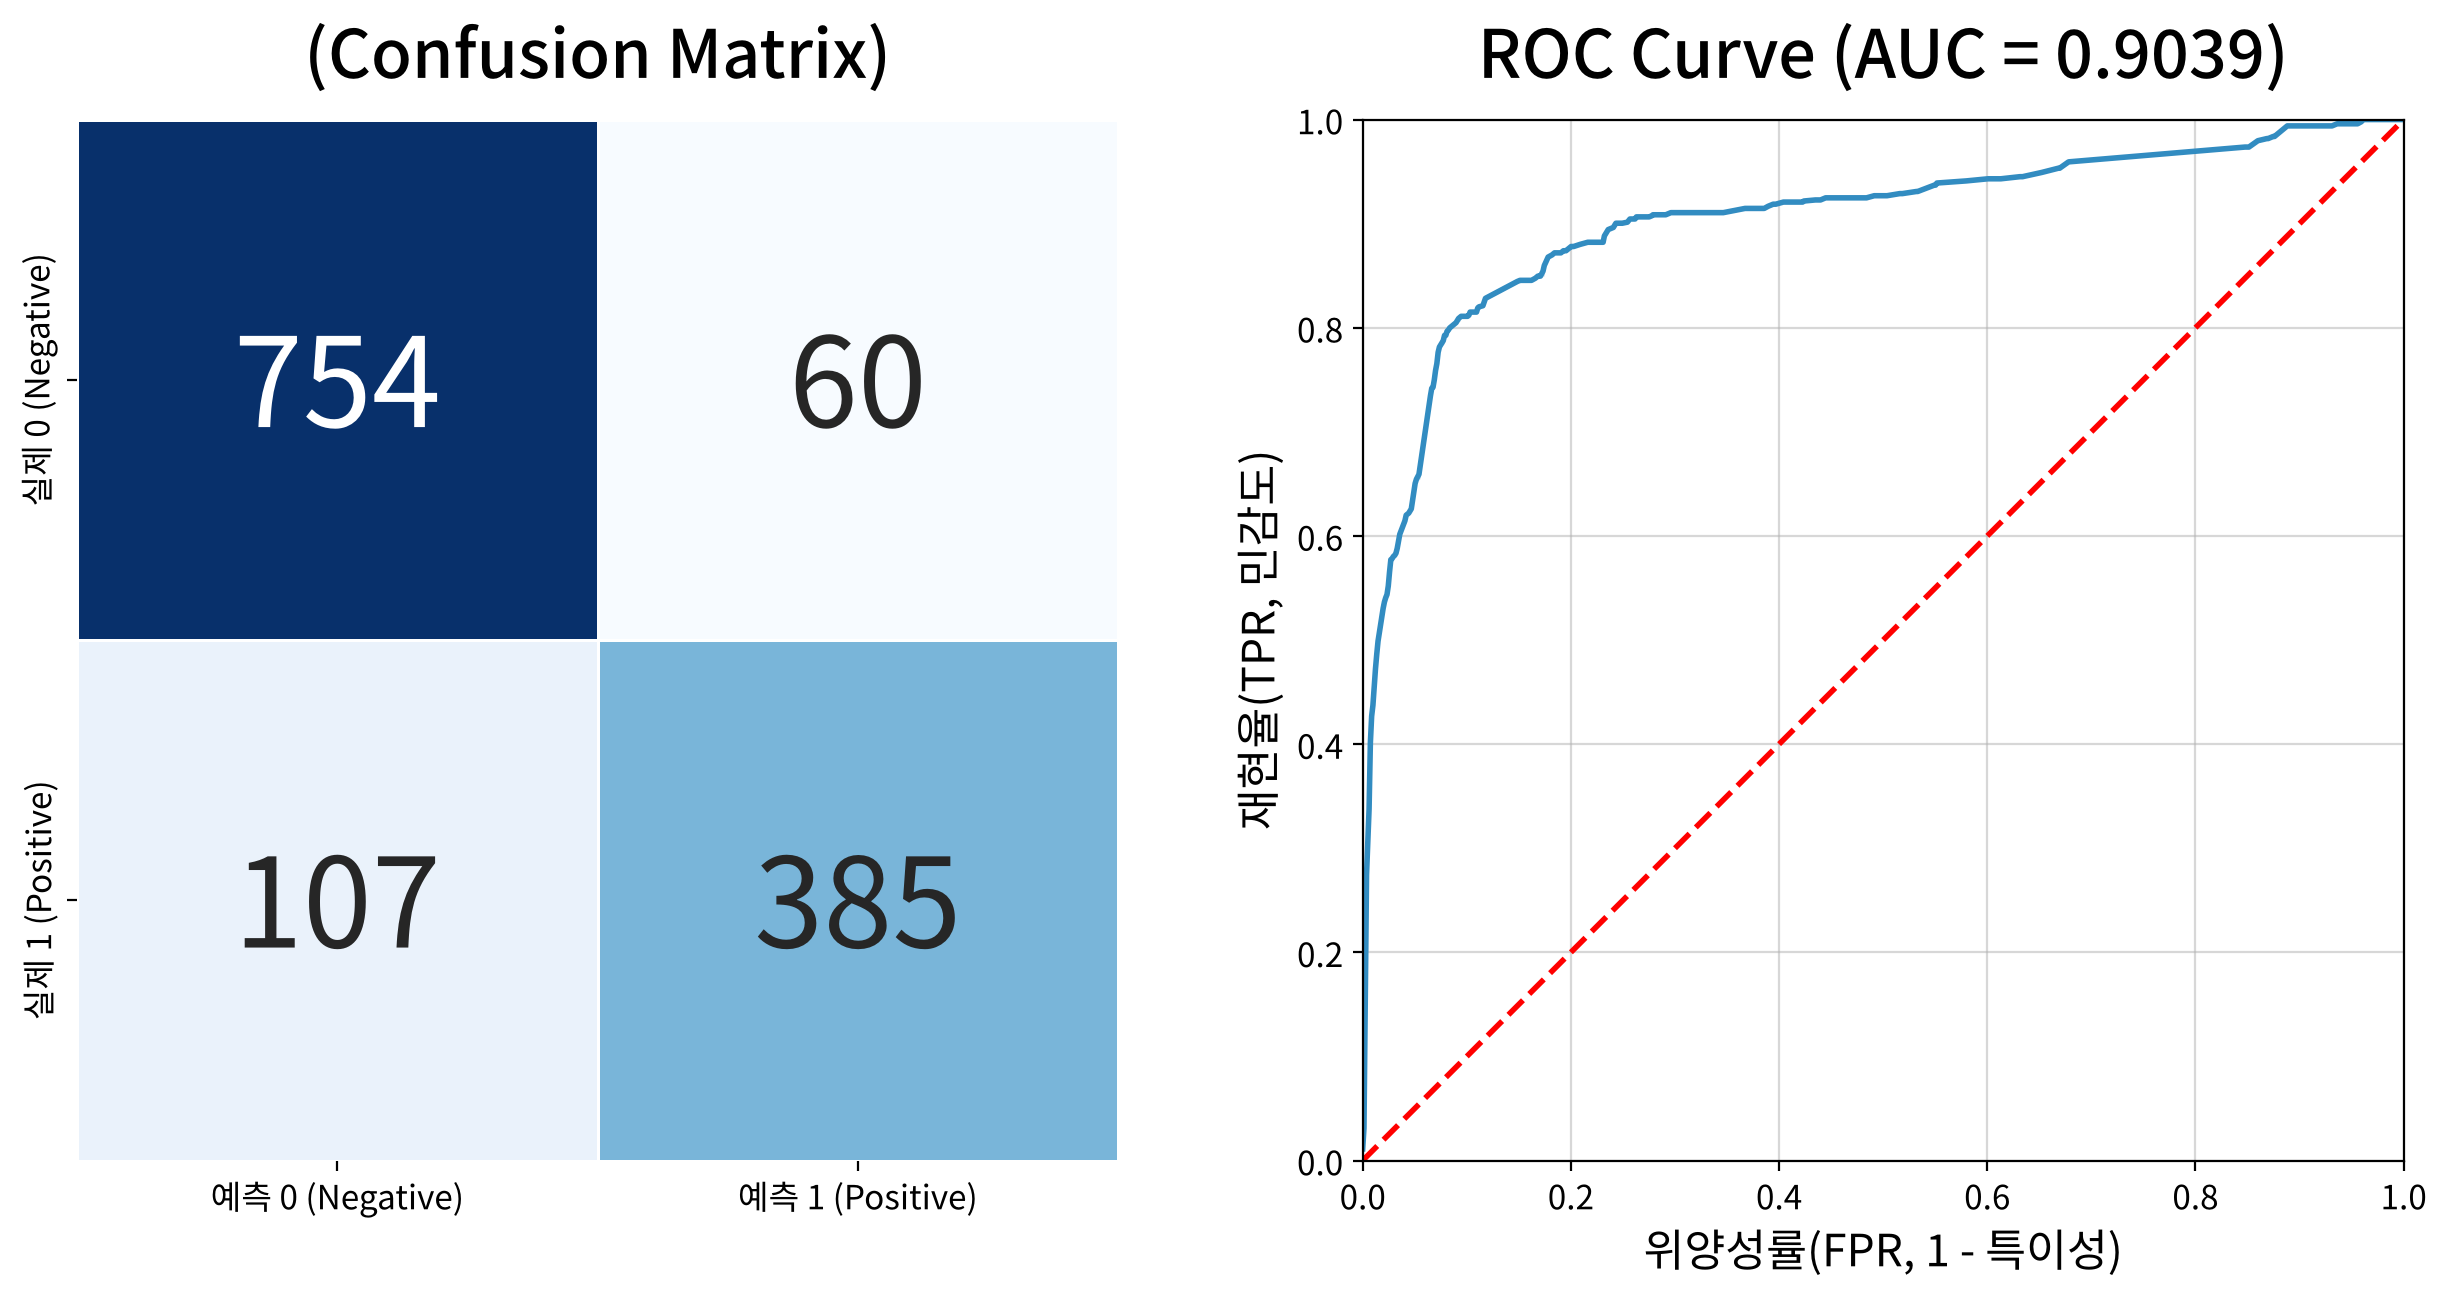

In [37]:
my_logit.report_performance(final_fit)

---
##### 💡 인사이트

| 지표 | 값 | 의미 |
|---|---|---|
| 정확도 | 0.872 | 1,306명 중 1,139명을 맞혔다. 게으른 모델의 바닥값(62.3%)보다 **24.9%p 높다** |
| 정밀도 | 0.865 | 생존으로 판정한 사람 중 86.5%가 실제 생존자 |
| 재현율 | 0.783 | 실제 생존자 492명 중 385명(78.3%)을 찾아냈다 |
| 위양성률 | 0.074 | 사망자의 7.4%를 생존으로 잘못 판정했다 (= 1 − 특이성) |
| 특이성 | 0.926 | 사망자의 92.6%를 사망으로 맞혔다 |
| F1 | 0.822 | 정밀도와 재현율을 합친 점수. 재현율이 낮아 정확도보다 조금 낮다 |
| AUC | 0.904 | 생존자 한 명과 사망자 한 명을 무작위로 뽑았을 때, 모델이 생존자 쪽에 더 높은 확률을 줄 가능성 **90.4% (매우 우수)** |
| 진단 오즈비 | 45.22 | 생존으로 판정한 사람이 실제 생존자일 오즈가, 사망으로 판정한 사람의 **약 45배** |

- **특이성(0.926)이 재현율(0.783)보다 높다.** 사망자가 더 많은 데이터라 모델이 '사망' 쪽으로 판정하는 경향이 있고, 그 결과 **생존자 107명을 사망으로 판정**했다.

---

### (3) 임계값 조정

- 임계값 0.5는 관례일 뿐 정답이 아니다. `FN`은 실제 생존자인데 사망으로 판정한 경우, `FP`는 실제 사망자인데 생존으로 판정한 경우다.

In [38]:
my_logit.report_threshold(final_fit)

,정확도,정밀도,재현율,F1,FN (놓침 : 실제1→예측0),FP (헛짚음 : 실제0→예측1)
임계값,,,,,,
0.300,0.845,0.766,0.846,0.804,76,127
0.400,0.873,0.853,0.801,0.826,98,68
0.500,0.872,0.865,0.783,0.822,107,60
0.600,0.871,0.865,0.780,0.821,108,60
0.700,0.866,0.868,0.760,0.810,118,57


---
##### 💡 인사이트 — 임계값 0.4가 가장 균형 잡혀 있다

| 임계값 | 정확도 | 정밀도 | 재현율 | F1 | 놓친 생존자 (FN) | 잘못 판정한 사망자 (FP) |
|---|---|---|---|---|---|---|
| 0.3 | 0.845 | 0.766 | **0.846** | 0.804 | **76명** | 127명 |
| 0.4 | **0.873** | 0.853 | 0.801 | **0.826** | 98명 | 68명 |
| 0.5 (기본) | 0.872 | 0.865 | 0.783 | 0.822 | 107명 | 60명 |
| 0.6 | 0.871 | 0.865 | 0.780 | 0.821 | 108명 | 60명 |
| 0.7 | 0.866 | **0.868** | 0.760 | 0.810 | 118명 | **57명** |

- **정확도와 F1이 모두 임계값 0.4에서 최대**다(0.873 · 0.826). 기본값 0.5보다 놓친 생존자가 107명 → 98명으로 줄고, 잘못 판정한 사망자는 60명 → 68명으로 조금 늘 뿐이다.
- 0.5 이상에서는 정밀도가 거의 오르지 않는다(0.865 → 0.868). 임계값을 높여도 **얻는 것은 적고 놓치는 생존자만 늘어난다.**
- **정답은 목적이 정한다.**
  - **생존 가능성이 있는 사람을 빠짐없이 찾아야 할 때** → 임계값 **0.3** : 재현율 0.846
  - **전체적으로 가장 잘 맞히고 싶을 때** → 임계값 **0.4** : 정확도 · F1 최대

---

# PART 6. 머신러닝 ① 베이스라인 모델 11종

## 6-1. 준비

### (1) 라이브러리 참조

In [39]:
from pandas import read_excel
import datetime as dt
import os
import glob as gl   # 파일 목록을 리스트로 반환하는 파이썬 내장 모듈

# 훈련, 검증 데이터 분리 함수
from sklearn.model_selection import train_test_split

# 하이퍼파라미터 튜닝
from sklearn.model_selection import GridSearchCV

# 선형 계열 모델
from sklearn.linear_model import LogisticRegression, RidgeClassifier, SGDClassifier

# 비선형 계열 모델
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

# 트리 계열 모델
from sklearn.tree import DecisionTreeClassifier

# 앙상블 모델
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

### (2) 데이터 불러오기

- PART 3에서 저장한 모델링용 데이터(`titanic_model.xlsx`)를 불러온다.
  - EDA에서 고른 변수 : `Pclass` · `Age` · `Fare` · `Embarked` · `FamilySize` · `Title` (1,306행)
  - 로지스틱 회귀와 **같은 데이터**에서 출발한다. 가족 규모는 구간(`FamilyGroup`)이 아니라 원래의 숫자(`FamilySize`)로 넣어, 꺾이는 지점을 모델이 스스로 찾게 한다.

In [40]:
# PART 3에서 저장한 모델링용 데이터 (EDA에서 고른 변수 · 1,306행)
origin = read_excel("titanic_model.xlsx")
df = my_qtcheck.set_type(origin, as_category=['Title', 'Pclass', 'Embarked', 'Survived'])

<class 'pandas.DataFrame'>
RangeIndex: 1306 entries, 0 to 1305
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   Survived    1306 non-null   category
 1   Pclass      1306 non-null   category
 2   Age         1306 non-null   float64 
 3   Fare        1306 non-null   float64 
 4   Embarked    1306 non-null   category
 5   FamilySize  1306 non-null   int64   
 6   Title       1306 non-null   category
dtypes: category(4), float64(2), int64(1)
memory usage: 35.9 KB


### (3) 독립변수와 종속변수 분리 및 훈련, 검증 데이터 분할

In [41]:
feature = df.drop(columns=["Survived"])
target = df["Survived"]

# 훈련, 검증 데이터 분리
# 분류 문제이므로 stratify=target 을 지정해 훈련/검증의 클래스 비율을 원본과 같게 유지한다
x_train, x_test, y_train, y_test = train_test_split(
    feature, target, test_size=0.2, random_state=RANDOM_STATE, stratify=target)

x_train.shape, x_test.shape, y_train.shape, y_test.shape

((1044, 6), (262, 6), (1044,), (262,))

### (4) 학습을 완료한 모델이 저장될 폴더

In [42]:
baseline_dir = f"titanic/baseline"  # 베이스라인 모델이 저장될 경로

if not os.path.exists(baseline_dir):
    os.makedirs(baseline_dir)

## 6-2. 선형 계열 모델

### (1) LogisticRegression

In [43]:
# 학습 모델 객체 생성
model = LogisticRegression(random_state=RANDOM_STATE)

# 모델이름 문자열 구성 (클래스 이름을 소문자 변환 후 "regression" 꼬리 제거)
model_name = model.__class__.__name__.lower().removesuffix("regression")

# 파이프라인 구축 -> 학습 -> 저장
model = my_ml.fit_pipeline(
                model=model,                              # 학습 모델
                x_train=x_train, y_train=y_train,         # 훈련 데이터 (독립,종속)
                vif=True,                                 # 다중공선성 확인 여부
                scale=True,                               # 기본값이 L2 규제이므로 스케일링 필요
                drop_first=True,                          # 더미변수 생성(첫번째 컬럼 제거)
                save_path=f"{baseline_dir}/{model_name}.pkl")  # 모델 저장 경로

display(my_ml.cls_score(model, x_test, y_test))           # 모델 성능평가
display(model)                                            # 모델 구조 출력

대상: 1044행 x 6열 | 모델: logistic
명목형: ['Pclass', 'Embarked', 'Title']
연속형: ['Age', 'Fare', 'FamilySize']

전처리 단계
  연속형: 다중공선성 제거(VIF >= 10.0) → 정규화(standard)
  명목형: 더미변수 인코딩(drop_first=True)



모델 학습 완료: logistic
모델 저장: titanic/baseline/logistic.pkl


,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,LogLoss,MCC
Model,,,,,,,,
LogisticRegression,0.885,0.848,0.848,0.848,0.930,0.912,0.322,0.756


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['Pclass','Age','Fare','Embarked','FamilySize','Title']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
name_,str,'lo...ic'
pipeline_info_,dict,"{'ca...te': 'mo...nt', 'co...ls': ['Age', 'Fare', 'Fa...ze'], 'dr...st': True, 'encode': True, ...}"
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"


### (2) RidgeClassifier

In [44]:
# 학습 모델 객체 생성
model = RidgeClassifier(random_state=RANDOM_STATE)

# 모델이름 문자열 구성 (클래스 이름을 소문자 변환 후 "classifier" 꼬리 제거)
model_name = model.__class__.__name__.lower().removesuffix("classifier")

# 파이프라인 구축 -> 학습 -> 저장
model = my_ml.fit_pipeline(
                model=model,                              # 학습 모델
                x_train=x_train, y_train=y_train,         # 훈련 데이터 (독립,종속)
                vif=True,                                 # 다중공선성 확인 여부
                scale=True,                               # 계수에 벌점을 매기므로 스케일링 필요
                drop_first=True,                          # 더미변수 생성(첫번째 컬럼 제거)
                save_path=f"{baseline_dir}/{model_name}.pkl")  # 모델 저장 경로

display(my_ml.cls_score(model, x_test, y_test))           # 모델 성능평가
display(model)                                            # 모델 구조 출력

대상: 1044행 x 6열 | 모델: ridge
명목형: ['Pclass', 'Embarked', 'Title']
연속형: ['Age', 'Fare', 'FamilySize']

전처리 단계
  연속형: 다중공선성 제거(VIF >= 10.0) → 정규화(standard)
  명목형: 더미변수 인코딩(drop_first=True)

모델 학습 완료: ridge
모델 저장: titanic/baseline/ridge.pkl


,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,LogLoss,MCC
Model,,,,,,,,
RidgeClassifier,0.874,0.830,0.838,0.834,0.926,0.910,NaN,0.733


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['Pclass','Age','Fare','Embarked','FamilySize','Title']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
name_,str,'ridge'
pipeline_info_,dict,"{'ca...te': 'mo...nt', 'co...ls': ['Age', 'Fare', 'Fa...ze'], 'dr...st': True, 'encode': True, ...}"
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"


### (3) Lasso

In [45]:
# 학습 모델 객체 생성
# 분류에는 Lasso 클래스가 없다. L1 규제를 건 로지스틱 회귀가 그 자리를 대신한다.
model = LogisticRegression(l1_ratio=1, solver="liblinear", random_state=RANDOM_STATE)

# 모델이름 문자열 구성 (1번 모델과 클래스가 같아 이름이 겹치므로 직접 지정)
model_name = "lasso"

# 파이프라인 구축 -> 학습 -> 저장
model = my_ml.fit_pipeline(
                model=model,                              # 학습 모델
                x_train=x_train, y_train=y_train,         # 훈련 데이터 (독립,종속)
                vif=True,                                 # 다중공선성 확인 여부
                scale=True,                               # 계수에 벌점을 매기므로 스케일링 필요
                drop_first=True,                          # 더미변수 생성(첫번째 컬럼 제거)
                name=model_name,                          # 모델을 구분할 이름
                save_path=f"{baseline_dir}/{model_name}.pkl")  # 모델 저장 경로

display(my_ml.cls_score(model, x_test, y_test))           # 모델 성능평가
display(model)                                            # 모델 구조 출력

대상: 1044행 x 6열 | 모델: lasso
명목형: ['Pclass', 'Embarked', 'Title']
연속형: ['Age', 'Fare', 'FamilySize']

전처리 단계
  연속형: 다중공선성 제거(VIF >= 10.0) → 정규화(standard)
  명목형: 더미변수 인코딩(drop_first=True)

모델 학습 완료: lasso
모델 저장: titanic/baseline/lasso.pkl


,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,LogLoss,MCC
Model,,,,,,,,
LogisticRegression,0.882,0.840,0.848,0.844,0.928,0.910,0.324,0.749


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['Pclass','Age','Fare','Embarked','FamilySize','Title']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
name_,str,'lasso'
pipeline_info_,dict,"{'ca...te': 'mo...nt', 'co...ls': ['Age', 'Fare', 'Fa...ze'], 'dr...st': True, 'encode': True, ...}"
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"


### (4) ElasticNet

In [46]:
# 학습 모델 객체 생성
# loss="log_loss" 는 로지스틱 회귀와 같은 확률 모형, penalty="elasticnet" 은 L1+L2 규제
model = SGDClassifier(loss="log_loss", penalty="elasticnet", random_state=RANDOM_STATE, n_jobs=-1)

# 모델이름 문자열 구성 (클래스명(sgd)이 아니라 규제 방식으로 부르기 위해 직접 지정)
model_name = "elasticnet"

# 파이프라인 구축 -> 학습 -> 저장
model = my_ml.fit_pipeline(
                model=model,                              # 학습 모델
                x_train=x_train, y_train=y_train,         # 훈련 데이터 (독립,종속)
                vif=True,                                 # 다중공선성 확인 여부
                scale=True,                               # 계수에 벌점을 매기므로 스케일링 필요
                drop_first=True,                          # 더미변수 생성(첫번째 컬럼 제거)
                name=model_name,                          # 모델을 구분할 이름
                save_path=f"{baseline_dir}/{model_name}.pkl")  # 모델 저장 경로

display(my_ml.cls_score(model, x_test, y_test))           # 모델 성능평가
display(model)                                            # 모델 구조 출력

대상: 1044행 x 6열 | 모델: elasticnet
명목형: ['Pclass', 'Embarked', 'Title']
연속형: ['Age', 'Fare', 'FamilySize']

전처리 단계
  연속형: 다중공선성 제거(VIF >= 10.0) → 정규화(standard)
  명목형: 더미변수 인코딩(drop_first=True)

모델 학습 완료: elasticnet
모델 저장: titanic/baseline/elasticnet.pkl


,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,LogLoss,MCC
Model,,,,,,,,
SGDClassifier,0.870,0.822,0.838,0.830,0.928,0.906,0.327,0.725


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['Pclass','Age','Fare','Embarked','FamilySize','Title']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
name_,str,'el...et'
pipeline_info_,dict,"{'ca...te': 'mo...nt', 'co...ls': ['Age', 'Fare', 'Fa...ze'], 'dr...st': True, 'encode': True, ...}"
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"


## 6-3. 비선형 계열 모델

### (1) KNN

In [47]:
# 학습 모델 객체 생성
model = KNeighborsClassifier(n_jobs=-1)

# 모델이름 문자열 구성 (클래스 이름을 소문자 변환 후 "classifier" 꼬리 제거)
model_name = model.__class__.__name__.lower().removesuffix("classifier")

# 파이프라인 구축 -> 학습 -> 저장
model = my_ml.fit_pipeline(
                model=model,                              # 학습 모델
                x_train=x_train, y_train=y_train,         # 훈련 데이터 (독립,종속)
                vif=True,                                 # 다중공선성 확인 여부
                scale=True,                               # 거리로 학습하므로 스케일링 필요
                drop_first=True,                          # 더미변수 생성(첫번째 컬럼 제거)
                save_path=f"{baseline_dir}/{model_name}.pkl")  # 모델 저장 경로

display(my_ml.cls_score(model, x_test, y_test))           # 모델 성능평가
display(model)                                            # 모델 구조 출력

대상: 1044행 x 6열 | 모델: kneighbors
명목형: ['Pclass', 'Embarked', 'Title']
연속형: ['Age', 'Fare', 'FamilySize']

전처리 단계
  연속형: 다중공선성 제거(VIF >= 10.0) → 정규화(standard)
  명목형: 더미변수 인코딩(drop_first=True)

모델 학습 완료: kneighbors
모델 저장: titanic/baseline/kneighbors.pkl


,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,LogLoss,MCC
Model,,,,,,,,
KNeighborsClassifier,0.863,0.806,0.838,0.822,0.905,0.838,1.479,0.710


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['Pclass','Age','Fare','Embarked','FamilySize','Title']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
name_,str,'kn...rs'
pipeline_info_,dict,"{'ca...te': 'mo...nt', 'co...ls': ['Age', 'Fare', 'Fa...ze'], 'dr...st': True, 'encode': True, ...}"
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"


### (2) Support Vector Classifier

In [48]:
# 학습 모델 객체 생성
# probability=True 로 두어야 확률 기반 지표(LogLoss)까지 계산된다.
# 확률을 얻으려고 내부에서 교차검증을 한 번 더 돌리므로 그만큼 느려진다.
model = SVC(probability=True, random_state=RANDOM_STATE)

# 모델이름 문자열 구성 (클래스 이름을 소문자 변환 후 "classifier" 꼬리 제거)
model_name = model.__class__.__name__.lower().removesuffix("classifier")

# 파이프라인 구축 -> 학습 -> 저장
model = my_ml.fit_pipeline(
                model=model,                              # 학습 모델
                x_train=x_train, y_train=y_train,         # 훈련 데이터 (독립,종속)
                vif=True,                                 # 다중공선성 확인 여부
                scale=True,                               # 마진으로 학습하므로 스케일링 필요
                drop_first=True,                          # 더미변수 생성(첫번째 컬럼 제거)
                save_path=f"{baseline_dir}/{model_name}.pkl")  # 모델 저장 경로

display(my_ml.cls_score(model, x_test, y_test))           # 모델 성능평가
display(model)                                            # 모델 구조 출력

대상: 1044행 x 6열 | 모델: svc
명목형: ['Pclass', 'Embarked', 'Title']
연속형: ['Age', 'Fare', 'FamilySize']

전처리 단계
  연속형: 다중공선성 제거(VIF >= 10.0) → 정규화(standard)
  명목형: 더미변수 인코딩(drop_first=True)

모델 학습 완료: svc
모델 저장: titanic/baseline/svc.pkl


,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,LogLoss,MCC
Model,,,,,,,,
SVC,0.878,0.832,0.848,0.840,0.909,0.879,0.348,0.741


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['Pclass','Age','Fare','Embarked','FamilySize','Title']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
name_,str,'svc'
pipeline_info_,dict,"{'ca...te': 'mo...nt', 'co...ls': ['Age', 'Fare', 'Fa...ze'], 'dr...st': True, 'encode': True, ...}"
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"


## 6-4. 트리 계열 모델

### (1) Decision Tree

In [49]:
# 학습 모델 객체 생성
model = DecisionTreeClassifier(random_state=RANDOM_STATE)

# 모델이름 문자열 구성 (클래스 이름을 소문자 변환 후 "classifier" 꼬리 제거)
model_name = model.__class__.__name__.lower().removesuffix("classifier")

# 파이프라인 구축 -> 학습 -> 저장
model = my_ml.fit_pipeline(
                model=model,                              # 학습 모델
                x_train=x_train, y_train=y_train,         # 훈련 데이터 (독립,종속)
                vif=True,                                 # 다중공선성 확인 여부
                encode=True,                              # 더미변수 생성(모든 범주 유지)
                save_path=f"{baseline_dir}/{model_name}.pkl")  # 모델 저장 경로

display(my_ml.cls_score(model, x_test, y_test))           # 모델 성능평가
display(model)                                            # 모델 구조 출력

대상: 1044행 x 6열 | 모델: decisiontree
명목형: ['Pclass', 'Embarked', 'Title']
연속형: ['Age', 'Fare', 'FamilySize']

전처리 단계
  연속형: 다중공선성 제거(VIF >= 10.0)
  명목형: 더미변수 인코딩(drop_first=False)

모델 학습 완료: decisiontree
모델 저장: titanic/baseline/decisiontree.pkl


,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,LogLoss,MCC
Model,,,,,,,,
DecisionTreeClassifier,0.840,0.766,0.828,0.796,0.834,0.698,5.789,0.666


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['Pclass','Age','Fare','Embarked','FamilySize','Title']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
name_,str,'de...ee'
pipeline_info_,dict,"{'ca...te': 'mo...nt', 'co...ls': ['Age', 'Fare', 'Fa...ze'], 'dr...st': False, 'encode': True, ...}"
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"


## 6-5. 앙상블 모델

### (1) Random Forest

In [50]:
# 학습 모델 객체 생성
model = RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1)

# 모델이름 문자열 구성 (클래스 이름을 소문자 변환 후 "classifier" 꼬리 제거)
model_name = model.__class__.__name__.lower().removesuffix("classifier")

# 파이프라인 구축 -> 학습 -> 저장
model = my_ml.fit_pipeline(
                model=model,                              # 학습 모델
                x_train=x_train, y_train=y_train,         # 훈련 데이터 (독립,종속)
                vif=True,                                 # 다중공선성 확인 여부
                encode=True,                              # 더미변수 생성(모든 범주 유지)
                save_path=f"{baseline_dir}/{model_name}.pkl")  # 모델 저장 경로

display(my_ml.cls_score(model, x_test, y_test))           # 모델 성능평가
display(model)                                            # 모델 구조 출력

대상: 1044행 x 6열 | 모델: randomforest
명목형: ['Pclass', 'Embarked', 'Title']
연속형: ['Age', 'Fare', 'FamilySize']

전처리 단계
  연속형: 다중공선성 제거(VIF >= 10.0)
  명목형: 더미변수 인코딩(drop_first=False)



모델 학습 완료: randomforest
모델 저장: titanic/baseline/randomforest.pkl


,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,LogLoss,MCC
Model,,,,,,,,
RandomForestClassifier,0.832,0.772,0.788,0.780,0.895,0.861,0.653,0.644


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['Pclass','Age','Fare','Embarked','FamilySize','Title']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
name_,str,'ra...st'
pipeline_info_,dict,"{'ca...te': 'mo...nt', 'co...ls': ['Age', 'Fare', 'Fa...ze'], 'dr...st': False, 'encode': True, ...}"
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"


### (2) XGBoost

In [51]:
# 학습 모델 객체 생성
model = XGBClassifier(random_state=RANDOM_STATE, n_jobs=-1)

# 모델이름 문자열 구성 (클래스 이름을 소문자 변환 후 "classifier" 꼬리 제거)
model_name = model.__class__.__name__.lower().removesuffix("classifier")

# 파이프라인 구축 -> 학습 -> 저장
model = my_ml.fit_pipeline(
                model=model,                              # 학습 모델
                x_train=x_train, y_train=y_train,         # 훈련 데이터 (독립,종속)
                vif=True,                                 # 다중공선성 확인 여부
                encode=True,                              # 더미변수 생성(모든 범주 유지)
                save_path=f"{baseline_dir}/{model_name}.pkl")  # 모델 저장 경로

display(my_ml.cls_score(model, x_test, y_test))           # 모델 성능평가
display(model)                                            # 모델 구조 출력

대상: 1044행 x 6열 | 모델: xgb
명목형: ['Pclass', 'Embarked', 'Title']
연속형: ['Age', 'Fare', 'FamilySize']

전처리 단계
  연속형: 다중공선성 제거(VIF >= 10.0)
  명목형: 더미변수 인코딩(drop_first=False)

모델 학습 완료: xgb
모델 저장: titanic/baseline/xgb.pkl


,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,LogLoss,MCC
Model,,,,,,,,
XGBClassifier,0.851,0.788,0.828,0.808,0.918,0.896,0.380,0.687


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['Pclass','Age','Fare','Embarked','FamilySize','Title']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
name_,str,'xgb'
pipeline_info_,dict,"{'ca...te': 'mo...nt', 'co...ls': ['Age', 'Fare', 'Fa...ze'], 'dr...st': False, 'encode': True, ...}"
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"


### (3) LightGBM

In [52]:
# 학습 모델 객체 생성
model = LGBMClassifier(random_state=RANDOM_STATE, verbose=-1)

# 모델이름 문자열 구성 (클래스 이름을 소문자 변환 후 "classifier" 꼬리 제거)
model_name = model.__class__.__name__.lower().removesuffix("classifier")

# 파이프라인 구축 -> 학습 -> 저장
model = my_ml.fit_pipeline(
                model=model,                              # 학습 모델
                x_train=x_train, y_train=y_train,         # 훈련 데이터 (독립,종속)
                vif=True,                                 # 다중공선성 확인 여부
                encode=True,                              # 더미변수 생성(모든 범주 유지)
                save_path=f"{baseline_dir}/{model_name}.pkl")  # 모델 저장 경로

display(my_ml.cls_score(model, x_test, y_test))           # 모델 성능평가
display(model)                                            # 모델 구조 출력

대상: 1044행 x 6열 | 모델: lgbm
명목형: ['Pclass', 'Embarked', 'Title']
연속형: ['Age', 'Fare', 'FamilySize']

전처리 단계
  연속형: 다중공선성 제거(VIF >= 10.0)
  명목형: 더미변수 인코딩(drop_first=False)

모델 학습 완료: lgbm
모델 저장: titanic/baseline/lgbm.pkl


,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,LogLoss,MCC
Model,,,,,,,,
LGBMClassifier,0.882,0.827,0.869,0.847,0.931,0.912,0.326,0.751


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['Pclass','Age','Fare','Embarked','FamilySize','Title']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
name_,str,'lgbm'
pipeline_info_,dict,"{'ca...te': 'mo...nt', 'co...ls': ['Age', 'Fare', 'Fa...ze'], 'dr...st': False, 'encode': True, ...}"
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"


### (4) CatBoost

In [53]:
# 학습 모델 객체 생성
model = CatBoostClassifier(random_state=RANDOM_STATE, verbose=0)

# 모델이름 문자열 구성 (클래스 이름을 소문자 변환 후 "classifier" 꼬리 제거)
model_name = model.__class__.__name__.lower().removesuffix("classifier")

# 파이프라인 구축 -> 학습 -> 저장
model = my_ml.fit_pipeline(
                model=model,                              # 학습 모델
                x_train=x_train, y_train=y_train,         # 훈련 데이터 (독립,종속)
                vif=True,                                 # 다중공선성 확인 여부
                encode=False,                             # CatBoost는 자체적으로 범주형 처리
                save_path=f"{baseline_dir}/{model_name}.pkl",   # 모델 저장 경로
                # 이름이 `단계명__인자명` 형식인 인자는 모델의 fit 으로 그대로 전달된다
                model__cat_features=my_qtcheck.get_categorical_column_names(x_train))

display(my_ml.cls_score(model, x_test, y_test))           # 모델 성능평가
display(model)                                            # 모델 구조 출력

대상: 1044행 x 6열 | 모델: catboost
명목형: ['Pclass', 'Embarked', 'Title']
연속형: ['Age', 'Fare', 'FamilySize']

전처리 단계
  연속형: 다중공선성 제거(VIF >= 10.0)
  명목형: (변환 없음)



모델 학습 완료: catboost
모델 저장: titanic/baseline/catboost.pkl


,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,LogLoss,MCC
Model,,,,,,,,
CatBoostClassifier,0.885,0.848,0.848,0.848,0.919,0.893,0.328,0.756


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['Pclass','Age','Fare','Embarked','FamilySize','Title']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
name_,str,'ca...st'
pipeline_info_,dict,"{'ca...te': 'mo...nt', 'co...ls': ['Age', 'Fare', 'Fa...ze'], 'dr...st': False, 'encode': False, ...}"
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"


## 6-6. 베이스라인 모델 비교

### (1) 학습 모델 파일 목록

In [54]:
# 작업폴더 내의 모든 pkl 파일 목록 확인
model_pickles = gl.glob(f"{baseline_dir}/*.pkl")
print(model_pickles)

['titanic/baseline/decisiontree.pkl', 'titanic/baseline/randomforest.pkl', 'titanic/baseline/logistic.pkl', 'titanic/baseline/lasso.pkl', 'titanic/baseline/svc.pkl', 'titanic/baseline/kneighbors.pkl', 'titanic/baseline/elasticnet.pkl', 'titanic/baseline/catboost.pkl', 'titanic/baseline/xgb.pkl', 'titanic/baseline/ridge.pkl', 'titanic/baseline/lgbm.pkl']


### (2) 학습 모델 불러오기

In [55]:
models = {}                         # 모델명과 모델 객체를 저장할 딕셔너리

for p in model_pickles:
    model_name = p.split(".")[0]    # 파일 목록에서 파일명만 분리
    model = my_ml.load_model(p)     # 모델 로드
    models[model.name_] = model     # 모델명과 모델 객체를 딕셔너리에 저장

# 로드된 모델과 모델 객체의 타입 출력
for name, model in models.items():
    print(f"- {name}: {type(model)}")

- decisiontree: <class 'sklearn.pipeline.Pipeline'>
- randomforest: <class 'sklearn.pipeline.Pipeline'>
- logistic: <class 'sklearn.pipeline.Pipeline'>
- lasso: <class 'sklearn.pipeline.Pipeline'>
- svc: <class 'sklearn.pipeline.Pipeline'>
- kneighbors: <class 'sklearn.pipeline.Pipeline'>
- elasticnet: <class 'sklearn.pipeline.Pipeline'>
- catboost: <class 'sklearn.pipeline.Pipeline'>
- xgb: <class 'sklearn.pipeline.Pipeline'>
- ridge: <class 'sklearn.pipeline.Pipeline'>
- lgbm: <class 'sklearn.pipeline.Pipeline'>


### (3) 모델간 성능평가 비교

In [56]:
my_ml.cls_compare_models(models,    # 모델 객체들을 담은 딕셔너리
                         x_test,    # 검증 데이터의 독립 변수
                         y_test,    # 검증 데이터의 종속 변수
                         primary="F1",                 # 주 지표
                         aux=["ROC_AUC", "Accuracy"])  # 보조 지표


◆ Score Table Ranking : primary='F1', aux=['ROC_AUC', 'Accuracy']

▲ step1: 주 지표(F1) 기준 정렬 — 높을수록 좋음 (DESC)
    1. logistic       F1    =            0.848
    2. catboost       F1    =            0.848
    3. lgbm           F1    =            0.847
    4. lasso          F1    =            0.844
    5. svc            F1    =            0.840
    6. ridge          F1    =            0.834
    7. elasticnet     F1    =            0.830
    8. kneighbors     F1    =            0.822
    9. xgb            F1    =            0.808
   10. decisiontree   F1    =            0.796
   11. randomforest   F1    =            0.780

▲ step2: 근소 격차 그룹 묶기 (1등의 5% 이내)
   - 1등 F1     : 0.848
   - 허용 범위    : F1 ≥ 0.806
   - 근소 격차 그룹 (9) : ['logistic', 'catboost', 'lgbm', 'lasso', 'svc', 'ridge', 'elasticnet', 'kneighbors', 'xgb']
   - 그룹 외부     (2) : ['decisiontree', 'randomforest']

▲ step3: 보조 지표 결정적 결함 점검 (근소 격차 그룹 내부)
   - 그룹 1등 점수 / 결함 임계치:
       · ROC_AUC best=     0.931   결함조건: row < 0.881  (1등 −

,Rank,Group,Model,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,LogLoss,MCC,F1_Gap
name,,,,,,,,,,,,
logistic,1,Contender,LogisticRegression,0.885,0.848,0.848,0.848,0.930,0.912,0.322,0.756,-0.000
catboost,2,Contender,CatBoostClassifier,0.885,0.848,0.848,0.848,0.919,0.893,0.328,0.756,-0.000
lgbm,3,Contender,LGBMClassifier,0.882,0.827,0.869,0.847,0.931,0.912,0.326,0.751,0.001
lasso,4,Contender,LogisticRegression,0.882,0.840,0.848,0.844,0.928,0.910,0.324,0.749,0.005
svc,5,Contender,SVC,0.878,0.832,0.848,0.840,0.909,0.879,0.348,0.741,0.010
ridge,6,Contender,RidgeClassifier,0.874,0.830,0.838,0.834,0.926,0.910,NaN,0.733,0.017
elasticnet,7,Contender,SGDClassifier,0.870,0.822,0.838,0.830,0.928,0.906,0.327,0.725,0.022
kneighbors,8,Contender,KNeighborsClassifier,0.863,0.806,0.838,0.822,0.905,0.838,1.479,0.710,0.031
xgb,9,Contender,XGBClassifier,0.851,0.788,0.828,0.808,0.918,0.896,0.380,0.687,0.048


---
##### 💡 인사이트 — 베이스라인: 로지스틱 회귀가 1위, 상위 9개가 근소 격차

| 구분 | 모델 (F1) |
|---|---|
| 근소 격차 그룹 (1등의 5% 이내) | Logistic 0.848 · CatBoost 0.848 · LightGBM 0.847 · Lasso 0.844 · SVC 0.840 · Ridge 0.834 · ElasticNet 0.830 · KNN 0.822 · XGBoost 0.808 |
| 그룹 밖 | DecisionTree 0.796 · RandomForest 0.780 |

- 1위는 **Logistic(F1 0.848 · ROC_AUC 0.930)**, 2위는 **CatBoost(F1 0.848 · ROC_AUC 0.919)** 로 F1이 같다.
- 근소 격차 그룹 9개 모두 보조 지표(ROC_AUC · Accuracy) **결함이 없다.**
- 비교표에서 **Ridge의 LogLoss만 NaN**이다. `RidgeClassifier`는 확률을 내지 않는 모델이라, 예측 확률이 필요한 LogLoss를 계산할 수 없다. 오류가 아니며, ROC_AUC는 결정 점수로 계산되어 정상적으로 나왔다.
- 기본 설정에서는 **DecisionTree · RandomForest가 그룹 밖**이었다. → 다음 단계에서 하이퍼파라미터를 튜닝해 다시 비교한다.

---

# PART 7. 머신러닝 ② 하이퍼파라미터 튜닝

## 7-1. 준비

### (1) 모델 저장 폴더

- 데이터와 분할은 PART 6과 같으므로 그대로 이어서 쓴다.

In [57]:
baseline_dir = f"titanic/baseline"  # 베이스라인 모델이 저장되어 있는 경로

if not os.path.exists(baseline_dir):
    os.makedirs(baseline_dir)

tune_dir = f"titanic/tune"          # 하이퍼파라미터 튜닝 모델이 저장될 경로

if not os.path.exists(tune_dir):
    os.makedirs(tune_dir)

## 7-2. 하이퍼파라미터 튜닝

### (1) LogisticRegression

In [58]:
%%time

# 로지스틱 회귀의 핵심 하이퍼파라미터는 규제 강도 C 다.
# C 는 규제 강도의 "역수" 라서 값이 작을수록 규제가 강해진다 (Ridge 의 alpha 와 반대 방향).
param_grid = {
    "model__C": [0.01, 0.1, 1.0, 10.0],       # 규제 강도의 역수
    "model__solver": ["lbfgs", "liblinear"]   # 최적화 알고리즘
}

model = my_ml.load_model(f"{baseline_dir}/logistic.pkl")    # 베이스모델 로드

# 파라미터 탐색을 위한 그리드 서치 객체 생성
gs = GridSearchCV(estimator=model, param_grid=param_grid,
    cv=5, scoring="f1", n_jobs=-1)

gs.fit(x_train, y_train)                            # 파라미터 탐색 수행
gs.name_ = f"{model.name_}_tuned"                   # 튜닝 완료 객체에 이름 부여
my_ml.save_model(gs, f"{tune_dir}/logistic.pkl")    # 튜닝된 모델 저장
display(my_ml.cls_score(gs, x_test, y_test))        # 성능 평가 결과 출력
display(gs)                                         # 학습 모형 구조 출력

,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,LogLoss,MCC
Model,,,,,,,,
LogisticRegression,0.885,0.848,0.848,0.848,0.927,0.908,0.325,0.756


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...state=3217))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__C': [0.01, 0.1, ...], 'model__solver': ['lbfgs', 'liblinear']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of i

CPU times: user 199 ms, sys: 8.23 ms, total: 207 ms
Wall time: 1.52 s


### (2) RidgeClassifier

In [59]:
%%time
# [실제 탐색용] 20개 조합
# param_grid = {
#     "model__alpha": [0.01, 0.1, 1.0, 10.0, 100.0],
#     "model__solver": ["auto", "svd", "cholesky", "lsqr"]
# }
# [수업용] 8개 조합. alpha 가 클수록 계수를 0 쪽으로 강하게 눌러 분산을 줄인다.
param_grid = {
    "model__alpha": [0.1, 1.0, 10.0, 100.0],        # 규제 강도
    "model__solver": ["auto", "lsqr"]               # 최적화 알고리즘
}

model = my_ml.load_model(f"{baseline_dir}/ridge.pkl")   # 베이스모델 로드

# 파라미터 탐색을 위한 그리드 서치 객체 생성
gs = GridSearchCV(estimator=model, param_grid=param_grid, cv=5, scoring="f1", n_jobs=-1)
gs.fit(x_train, y_train)                            # 파라미터 탐색 수행
gs.name_ = f"{model.name_}_tuned"                   # 튜닝 완료 객체에 이름 부여
my_ml.save_model(gs, f"{tune_dir}/ridge.pkl")       # 튜닝된 모델 저장
display(my_ml.cls_score(gs, x_test, y_test))        # 성능 평가 결과 출력
display(gs)                                         # 학습 모형 구조 출력

,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,LogLoss,MCC
Model,,,,,,,,
RidgeClassifier,0.870,0.822,0.838,0.830,0.925,0.910,NaN,0.725


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...state=3217))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__alpha': [0.1, 1.0, ...], 'model__solver': ['auto', 'lsqr']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of info

CPU times: user 216 ms, sys: 16.1 ms, total: 232 ms
Wall time: 1.41 s


### (3) Lasso

In [60]:
%%time

# [실제 탐색용] 15개 조합
# param_grid = {
#     "model__C": [0.001, 0.01, 0.1, 1.0, 10.0],
#     "model__solver": ["liblinear"]
# }
# [수업용] 8개 조합.
param_grid = {
    "model__C": [0.01, 0.1, 1.0, 10.0],       # 규제 강도의 역수 (L1)
    "model__solver": ["liblinear"]            # L1 을 지원하는 최적화 알고리즘
}

model = my_ml.load_model(f"{baseline_dir}/lasso.pkl")   # 베이스모델 로드

# 파라미터 탐색을 위한 그리드 서치 객체 생성
gs = GridSearchCV(estimator=model, param_grid=param_grid, cv=5, scoring="f1", n_jobs=-1)
gs.fit(x_train, y_train)                            # 파라미터 탐색 수행
gs.name_ = f"{model.name_}_tuned"                   # 튜닝 완료 객체에 이름 부여
my_ml.save_model(gs, f"{tune_dir}/lasso.pkl")       # 튜닝된 모델 저장
display(my_ml.cls_score(gs, x_test, y_test))        # 성능 평가 결과 출력
display(gs)                                         # 학습 모형 구조 출력

,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,LogLoss,MCC
Model,,,,,,,,
LogisticRegression,0.885,0.848,0.848,0.848,0.926,0.908,0.326,0.756


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...liblinear'))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__C': [0.01, 0.1, ...], 'model__solver': ['liblinear']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of informatio

CPU times: user 212 ms, sys: 8.22 ms, total: 220 ms
Wall time: 799 ms


### (4) ElasticNet

In [61]:
%%time

# [실제 탐색용] 20개 조합
# param_grid = {
#     "model__alpha": [0.0001, 0.001, 0.01, 0.1, 1.0],
#     "model__l1_ratio": [0.1, 0.3, 0.5, 0.9]
# }
# [수업용] 8개 조합.
param_grid = {
    "model__alpha": [0.0001, 0.001, 0.01, 0.1],   # 규제 강도
    "model__l1_ratio": [0.2, 0.8]                 # L1 규제의 비중
}

model = my_ml.load_model(f"{baseline_dir}/elasticnet.pkl")   # 베이스모델 로드

# 파라미터 탐색을 위한 그리드 서치 객체 생성
gs = GridSearchCV(estimator=model, param_grid=param_grid, cv=5, scoring="f1", n_jobs=-1)
gs.fit(x_train, y_train)                                # 파라미터 탐색 수행
gs.name_ = f"{model.name_}_tuned"                       # 튜닝 완료 객체에 이름 부여
my_ml.save_model(gs, f"{tune_dir}/elasticnet.pkl")      # 튜닝된 모델 저장
display(my_ml.cls_score(gs, x_test, y_test))            # 성능 평가 결과 출력
display(gs)                                             # 학습 모형 구조 출력

,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,LogLoss,MCC
Model,,,,,,,,
SGDClassifier,0.893,0.866,0.848,0.857,0.928,0.910,0.319,0.772


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...state=3217))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__alpha': [0.0001, 0.001, ...], 'model__l1_ratio': [0.2, 0.8]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of inf

CPU times: user 237 ms, sys: 58 μs, total: 237 ms
Wall time: 1.47 s


### (5) KNN

In [62]:
%%time

# [실제 탐색용] 24개 조합
# param_grid = {
#     "model__n_neighbors": [3, 5, 10, 20, 30, 50],
#     "model__weights": ["uniform", "distance"],
#     "model__p": [1, 2]
# }
# [수업용] 8개 조합. 이웃 수가 적으면 과대적합, 많으면 과소적합 쪽으로 기운다.
param_grid = {
    "model__n_neighbors": [5, 10, 20, 30],       # 참조할 이웃 수
    "model__weights": ["uniform", "distance"]    # 거리에 따른 가중 방식
}

model = my_ml.load_model(f"{baseline_dir}/kneighbors.pkl")   # 베이스모델 로드

# 파라미터 탐색을 위한 그리드 서치 객체 생성
gs = GridSearchCV(estimator=model, param_grid=param_grid, cv=5, scoring="f1", n_jobs=-1)
gs.fit(x_train, y_train)                                # 파라미터 탐색 수행
gs.name_ = f"{model.name_}_tuned"                       # 튜닝 완료 객체에 이름 부여
my_ml.save_model(gs, f"{tune_dir}/kneighbors.pkl")      # 튜닝된 모델 저장
display(my_ml.cls_score(gs, x_test, y_test))            # 성능 평가 결과 출력
display(gs)                                             # 학습 모형 구조 출력

,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,LogLoss,MCC
Model,,,,,,,,
KNeighborsClassifier,0.882,0.840,0.848,0.844,0.922,0.869,0.461,0.749


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...(n_jobs=-1))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__n_neighbors': [5, 10, ...], 'model__weights': ['uniform', 'distance']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbos

CPU times: user 340 ms, sys: 2.22 ms, total: 342 ms
Wall time: 1.77 s


### (6) Support Vector Machine

In [63]:
%%time

# [실제 탐색용] 18개 조합 --> 표본 수의 제곱에 비례해 학습 시간이 늘어나므로 매우 오래 걸린다
# param_grid = {
#     "model__C": [0.1, 1.0, 10.0],
#     "model__gamma": ["scale", 0.01, 0.1],
#     "model__kernel": ["rbf", "poly"]
# }
# [수업용] SVC 는 확률 계산 때문에 이 노트북에서 가장 느리므로 튜닝 시간을 줄이기 위해 조합을 2개로 축소한다.
param_grid = {
    "model__C": [1.0],              # 오차 허용에 대한 벌점 (클수록 훈련 데이터에 밀착)
    "model__gamma": ["scale", 0.01] # RBF 커널의 영향 반경
}

model = my_ml.load_model(f"{baseline_dir}/svc.pkl")   # 베이스모델 로드

# 파라미터 탐색을 위한 그리드 서치 객체 생성
gs = GridSearchCV(estimator=model, param_grid=param_grid, cv=5, scoring="f1", n_jobs=-1)
gs.fit(x_train, y_train)                            # 파라미터 탐색 수행
gs.name_ = f"{model.name_}_tuned"                   # 튜닝 완료 객체에 이름 부여
my_ml.save_model(gs, f"{tune_dir}/svc.pkl")         # 튜닝된 모델 저장
display(my_ml.cls_score(gs, x_test, y_test))        # 성능 평가 결과 출력
display(gs)                                         # 학습 모형 구조 출력

,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,LogLoss,MCC
Model,,,,,,,,
SVC,0.878,0.832,0.848,0.840,0.909,0.879,0.348,0.741


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...state=3217))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__C': [1.0], 'model__gamma': ['scale', 0.01]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of information printed 

CPU times: user 343 ms, sys: 108 μs, total: 343 ms
Wall time: 1.08 s


### (7) Decision Tree

In [64]:
%%time

# [실제 탐색용] 24개 조합
# param_grid = {
#     "model__max_depth": [4, 6, 10, 14, 20, None],
#     "model__min_samples_leaf": [1, 5, 10, 20]
# }
# [수업용] 8개 조합.
param_grid = {
    "model__max_depth": [6, 10, 14, None],   # 트리의 최대 깊이
    "model__min_samples_leaf": [1, 10]       # 잎 노드가 가져야 할 최소 표본 수
}

model = my_ml.load_model(f"{baseline_dir}/decisiontree.pkl")   # 베이스모델 로드

# 파라미터 탐색을 위한 그리드 서치 객체 생성
gs = GridSearchCV(estimator=model, param_grid=param_grid, cv=5, scoring="f1", n_jobs=-1)
gs.fit(x_train, y_train)                                # 파라미터 탐색 수행
gs.name_ = f"{model.name_}_tuned"                       # 튜닝 완료 객체에 이름 부여
my_ml.save_model(gs, f"{tune_dir}/decisiontree.pkl")    # 튜닝된 모델 저장
display(my_ml.cls_score(gs, x_test, y_test))            # 성능 평가 결과 출력
display(gs)                                             # 학습 모형 구조 출력

,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,LogLoss,MCC
Model,,,,,,,,
DecisionTreeClassifier,0.882,0.833,0.859,0.846,0.920,0.858,0.492,0.750


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...state=3217))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__max_depth': [6, 10, ...], 'model__min_samples_leaf': [1, 10]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of in

CPU times: user 186 ms, sys: 4.58 ms, total: 190 ms
Wall time: 1.3 s


### (8) Random Forest

In [65]:
%%time

# [실제 탐색용] 18개 조합
# param_grid = {
#     "model__n_estimators": [100, 300, 500],
#     "model__max_depth": [10, 20, None],
#     "model__min_samples_leaf": [1, 5]
# }
# [수업용] 트리를 n_estimators 개 만큼 학습하므로 조합 하나당 성능 평가 시간이 오래 걸린다 --> 4개로 축소
param_grid = {
    "model__n_estimators": [100, 300],     # 숲을 이루는 트리 개수
    "model__min_samples_leaf": [1, 5]      # 잎 노드가 가져야 할 최소 표본 수
}

model = my_ml.load_model(f"{baseline_dir}/randomforest.pkl")   # 베이스모델 로드

# 파라미터 탐색을 위한 그리드 서치 객체 생성
gs = GridSearchCV(estimator=model, param_grid=param_grid, cv=5, scoring="f1", n_jobs=-1)
gs.fit(x_train, y_train)                                # 파라미터 탐색 수행
gs.name_ = f"{model.name_}_tuned"                       # 튜닝 완료 객체에 이름 부여
my_ml.save_model(gs, f"{tune_dir}/randomforest.pkl")    # 튜닝된 모델 저장
display(my_ml.cls_score(gs, x_test, y_test))            # 성능 평가 결과 출력
display(gs)                                             # 학습 모형 구조 출력

,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,LogLoss,MCC
Model,,,,,,,,
RandomForestClassifier,0.878,0.838,0.838,0.838,0.927,0.908,0.328,0.740


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...state=3217))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__min_samples_leaf': [1, 5], 'model__n_estimators': [100, 300]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of in

CPU times: user 791 ms, sys: 103 ms, total: 894 ms
Wall time: 5.46 s


### (9) XGBoost

In [66]:
%%time

# [실제 탐색용] 27개 조합
# param_grid = {
#     "model__n_estimators": [300, 600, 1000],
#     "model__max_depth": [3, 4, 6],
#     "model__learning_rate": [0.03, 0.05, 0.1]
# }
# [수업용] 8개 조합.
param_grid = {
    "model__n_estimators": [300, 600],        # 부스팅 라운드 수
    "model__max_depth": [4, 6],               # 트리 깊이
    "model__learning_rate": [0.05, 0.1]       # 각 트리의 반영 비율
}

model = my_ml.load_model(f"{baseline_dir}/xgb.pkl")   # 베이스모델 로드

# 파라미터 탐색을 위한 그리드 서치 객체 생성
gs = GridSearchCV(estimator=model, param_grid=param_grid, cv=5, scoring="f1", n_jobs=-1)
gs.fit(x_train, y_train)                            # 파라미터 탐색 수행
gs.name_ = f"{model.name_}_tuned"                   # 튜닝 완료 객체에 이름 부여
my_ml.save_model(gs, f"{tune_dir}/xgb.pkl")         # 튜닝된 모델 저장
display(my_ml.cls_score(gs, x_test, y_test))        # 성능 평가 결과 출력
display(gs)                                         # 학습 모형 구조 출력

,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,LogLoss,MCC
Model,,,,,,,,
XGBClassifier,0.889,0.850,0.859,0.854,0.927,0.913,0.315,0.765


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...=None, ...))])"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__learning_rate': [0.05, 0.1], 'model__max_depth': [4, 6], 'model__n_estimators': [300, 600]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, defau

CPU times: user 379 ms, sys: 102 ms, total: 481 ms
Wall time: 4.25 s


### (10) LightGBM

In [67]:
%%time

# [실제 탐색용] 27개 조합
# param_grid = {
#     "model__n_estimators": [300, 600, 1000],
#     "model__num_leaves": [15, 31, 63],
#     "model__learning_rate": [0.03, 0.05, 0.1]
# }
# [수업용] 8개 조합. LightGBM 은 깊이 대신 잎 개수(num_leaves)로 복잡도를 조절한다.
param_grid = {
    "model__n_estimators": [300, 600],        # 부스팅 라운드 수
    "model__num_leaves": [31, 63],            # 트리 하나가 가질 잎 개수
    "model__learning_rate": [0.05, 0.1]       # 각 트리의 반영 비율
}

model = my_ml.load_model(f"{baseline_dir}/lgbm.pkl")   # 베이스모델 로드

# 파라미터 탐색을 위한 그리드 서치 객체 생성
gs = GridSearchCV(estimator=model, param_grid=param_grid, cv=5, scoring="f1", n_jobs=-1)
gs.fit(x_train, y_train)                            # 파라미터 탐색 수행
gs.name_ = f"{model.name_}_tuned"                   # 튜닝 완료 객체에 이름 부여
my_ml.save_model(gs, f"{tune_dir}/lgbm.pkl")        # 튜닝된 모델 저장
display(my_ml.cls_score(gs, x_test, y_test))        # 성능 평가 결과 출력
display(gs)                                         # 학습 모형 구조 출력

,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,LogLoss,MCC
Model,,,,,,,,
LGBMClassifier,0.844,0.779,0.818,0.798,0.902,0.877,0.513,0.671


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...verbose=-1))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__learning_rate': [0.05, 0.1], 'model__n_estimators': [300, 600], 'model__num_leaves': [31, 63]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, defa

CPU times: user 1.42 s, sys: 980 ms, total: 2.4 s
Wall time: 3min 25s


### (11) CatBoost

In [68]:
%%time
# [실제 탐색용] 36개 조합 x 5-fold = CatBoost 학습 180회
# param_grid = {
#     "model__iterations": [500, 1000, 2000],
#     "model__depth": [4, 6, 8, 10],
#     "model__learning_rate": [0.03, 0.05, 0.1]
# }
# [수업용] 각 하이퍼파라미터를 일부만 두어 조합을 축소한다.
param_grid = {
    "model__iterations": [500, 1000],
    "model__depth": [4, 6, 8],
    "model__learning_rate": [0.03, 0.05, 0.1]
}

model = my_ml.load_model(f"{baseline_dir}/catboost.pkl") # 베이스모델 로드

# 파라미터 탐색을 위한 그리드 서치 객체 생성
gs = GridSearchCV(estimator=model, param_grid=param_grid, cv=5, scoring="f1", n_jobs=-1)

# 파라미터 탐색 수행 --> 카테고리타입 지정해야 함
gs.fit(x_train, y_train, model__cat_features=my_qtcheck.get_categorical_column_names(x_train))
gs.name_ = f"{model.name_}_tuned"                   # 튜닝 완료 객체에 이름 부여
my_ml.save_model(gs, f"{tune_dir}/catboost.pkl")    # 튜닝된 모델 저장
display(my_ml.cls_score(gs, x_test, y_test))        # 성능 평가 결과 출력
display(gs)                                         # 학습 모형 구조 출력

,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,LogLoss,MCC
Model,,,,,,,,
CatBoostClassifier,0.893,0.866,0.848,0.857,0.926,0.911,0.314,0.772


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step... verbose=0))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__depth': [4, 6, ...], 'model__iterations': [500, 1000], 'model__learning_rate': [0.03, 0.05, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, d

CPU times: user 1.98 s, sys: 262 ms, total: 2.24 s
Wall time: 1min 36s


## 7-3. 튜닝 모델 비교

### (1) 튜닝 모델 파일 목록

In [69]:
# 작업폴더 내의 모든 pkl 파일 목록 확인
model_pickles = gl.glob(f"{tune_dir}/*.pkl")
print(model_pickles)

['titanic/tune/decisiontree.pkl', 'titanic/tune/randomforest.pkl', 'titanic/tune/logistic.pkl', 'titanic/tune/lasso.pkl', 'titanic/tune/svc.pkl', 'titanic/tune/kneighbors.pkl', 'titanic/tune/elasticnet.pkl', 'titanic/tune/catboost.pkl', 'titanic/tune/xgb.pkl', 'titanic/tune/ridge.pkl', 'titanic/tune/lgbm.pkl']


### (2) 튜닝 모델 불러오기

In [70]:
models = {}                         # 모델명과 모델 객체를 저장할 딕셔너리

for p in model_pickles:
    model = my_ml.load_model(p)     # 모델 로드
    models[model.name_] = model     # 모델명과 모델 객체를 딕셔너리에 저장

# 로드된 모델과 모델 객체의 타입 출력
for name, model in models.items():
    print(f"- {name}: {type(model)}")

- decisiontree_tuned: <class 'sklearn.model_selection._search.GridSearchCV'>
- randomforest_tuned: <class 'sklearn.model_selection._search.GridSearchCV'>
- logistic_tuned: <class 'sklearn.model_selection._search.GridSearchCV'>
- lasso_tuned: <class 'sklearn.model_selection._search.GridSearchCV'>
- svc_tuned: <class 'sklearn.model_selection._search.GridSearchCV'>
- kneighbors_tuned: <class 'sklearn.model_selection._search.GridSearchCV'>
- elasticnet_tuned: <class 'sklearn.model_selection._search.GridSearchCV'>
- catboost_tuned: <class 'sklearn.model_selection._search.GridSearchCV'>
- xgb_tuned: <class 'sklearn.model_selection._search.GridSearchCV'>
- ridge_tuned: <class 'sklearn.model_selection._search.GridSearchCV'>
- lgbm_tuned: <class 'sklearn.model_selection._search.GridSearchCV'>


### (3) 모델간 성능평가 비교

In [71]:
my_ml.cls_compare_models(models,                       # 모델 객체들을 담은 딕셔너리
                         x_test,                       # 검증 데이터의 독립 변수
                         y_test,                       # 검증 데이터의 종속 변수
                         primary="F1",                 # 주 지표
                         aux=["ROC_AUC", "Accuracy"])  # 보조 지표


◆ Score Table Ranking : primary='F1', aux=['ROC_AUC', 'Accuracy']

▲ step1: 주 지표(F1) 기준 정렬 — 높을수록 좋음 (DESC)
    1. elasticnet_tuned F1    =            0.857
    2. catboost_tuned F1    =            0.857
    3. xgb_tuned      F1    =            0.854
    4. logistic_tuned F1    =            0.848
    5. lasso_tuned    F1    =            0.848
    6. decisiontree_tuned F1    =            0.846
    7. kneighbors_tuned F1    =            0.844
    8. svc_tuned      F1    =            0.840
    9. randomforest_tuned F1    =            0.838
   10. ridge_tuned    F1    =            0.830
   11. lgbm_tuned     F1    =            0.798

▲ step2: 근소 격차 그룹 묶기 (1등의 5% 이내)
   - 1등 F1     : 0.857
   - 허용 범위    : F1 ≥ 0.814
   - 근소 격차 그룹 (10) : ['elasticnet_tuned', 'catboost_tuned', 'xgb_tuned', 'logistic_tuned', 'lasso_tuned', 'decisiontree_tuned', 'kneighbors_tuned', 'svc_tuned', 'randomforest_tuned', 'ridge_tuned']
   - 그룹 외부     (1) : ['lgbm_tuned']

▲ step3: 보조 지표 결정적 결함 점검 (근소 격차 그룹 내부)
   -

,Rank,Group,Model,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,LogLoss,MCC,F1_Gap
name,,,,,,,,,,,,
elasticnet_tuned,1,Contender,SGDClassifier,0.893,0.866,0.848,0.857,0.928,0.910,0.319,0.772,-0.000
catboost_tuned,2,Contender,CatBoostClassifier,0.893,0.866,0.848,0.857,0.926,0.911,0.314,0.772,-0.000
xgb_tuned,3,Contender,XGBClassifier,0.889,0.850,0.859,0.854,0.927,0.913,0.315,0.765,0.003
logistic_tuned,4,Contender,LogisticRegression,0.885,0.848,0.848,0.848,0.927,0.908,0.325,0.756,0.010
lasso_tuned,5,Contender,LogisticRegression,0.885,0.848,0.848,0.848,0.926,0.908,0.326,0.756,0.010
decisiontree_tuned,6,Contender,DecisionTreeClassifier,0.882,0.833,0.859,0.846,0.920,0.858,0.492,0.750,0.013
kneighbors_tuned,7,Contender,KNeighborsClassifier,0.882,0.840,0.848,0.844,0.922,0.869,0.461,0.749,0.015
svc_tuned,8,Contender,SVC,0.878,0.832,0.848,0.840,0.909,0.879,0.348,0.741,0.020
randomforest_tuned,9,Contender,RandomForestClassifier,0.878,0.838,0.838,0.838,0.927,0.908,0.328,0.740,0.022


---
##### 💡 인사이트 — 튜닝: ElasticNet · CatBoost가 공동 1위, 트리 계열이 가장 크게 올랐다

| 순위 | 모델 | 베이스라인 F1 | 튜닝 F1 | 변화 |
|---|---|---|---|---|
| 1 | **ElasticNet** | 0.830 | **0.857** | +0.027 |
| 2 | **CatBoost** | 0.848 | **0.857** | +0.009 |
| 3 | XGBoost | 0.808 | 0.854 | +0.046 |
| 4 | Logistic | 0.848 | 0.848 | 0.000 |
| 5 | Lasso | 0.844 | 0.848 | +0.004 |
| 6 | DecisionTree | 0.796 | 0.846 | +0.050 |
| 7 | KNN | 0.822 | 0.844 | +0.022 |
| 8 | SVC | 0.840 | 0.840 | 0.000 |
| 9 | RandomForest | 0.780 | 0.838 | +0.058 |
| 10 | Ridge | 0.834 | 0.830 | −0.004 |
| 11 | LightGBM | 0.847 | 0.798 | −0.049 |

- **1위 ElasticNet과 2위 CatBoost는 Test 지표가 거의 같다.** F1 0.857 · 정확도 0.893 · 정밀도 0.866 · 재현율 0.848 · MCC 0.772가 모두 같고, ROC_AUC(0.928 vs 0.926)와 LogLoss(0.319 vs 0.314)만 소수 셋째 자리에서 다르다.
- 튜닝으로 가장 크게 오른 것은 **트리 계열**이다(RandomForest +0.058 · DecisionTree +0.050 · XGBoost +0.046).
- 반대로 **LightGBM은 0.847 → 0.798로 내려가 그룹 밖**으로 밀렸다. 튜닝이 항상 검증 성능을 올리지는 않는다.
- → Test 점수로는 상위 2개를 구분할 수 없으므로, **과적합 판정의 교차검증(CV) 결과로 비교**한다.

---

# PART 8. 머신러닝 ③ 과적합 진단 · 변수 중요도

## 8-1. 준비

### (1) 모델 저장 폴더

In [72]:
# 이전 학습 결과(하이퍼파라미터 튜닝)가 저장되어 있는 폴더 위치
workdir = "titanic/tune"
workdir

'titanic/tune'

In [73]:
# 새로운 학습 결과를 저장할 폴더 위치
savedir = workdir.replace("tune", "importance")
savedir

'titanic/importance'

## 8-2. 상위 성능 모델에 대한 과적합 판정

### (1) ElasticNet (튜닝 순위 1위)

- 하이퍼파라미터 튜닝 모델의 순위표 순서로 과적합 여부를 판정한다.
- **훈련 ↔ 교차검증(5-Fold) 격차(Gap%)가 15% 이상이면 과대적합**, 훈련 ROC_AUC가 0.6 미만이면 과소적합, 둘 다 아니면 **일반화**로 판정한다.

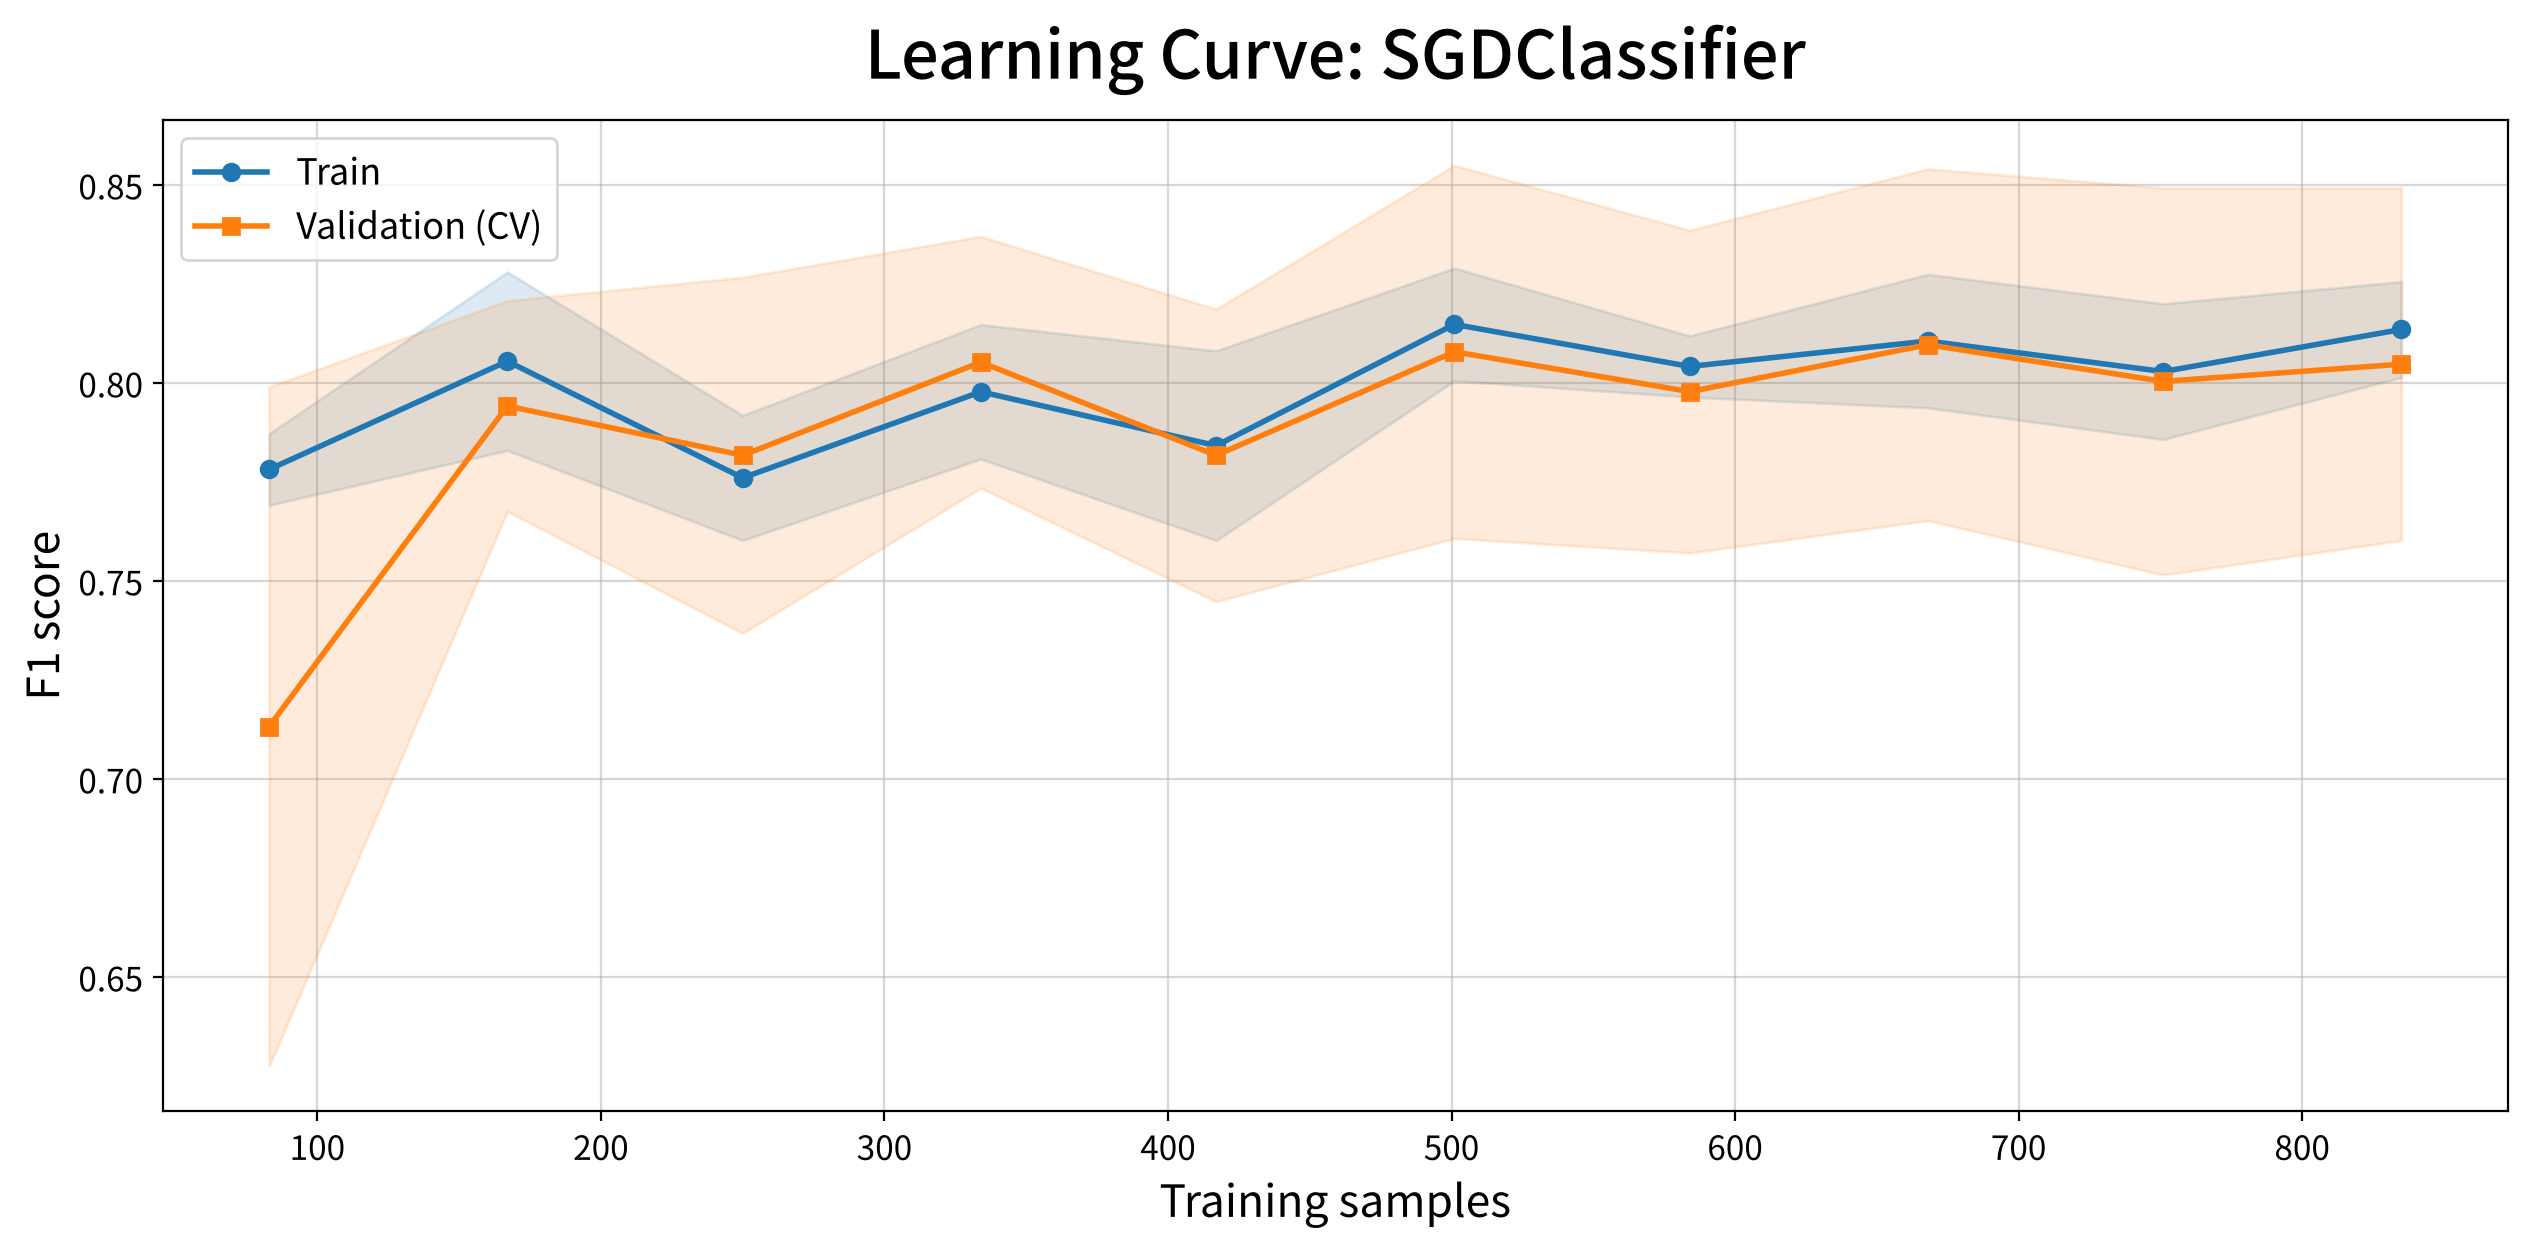


◆ Fit Diagnosis: SGDClassifier  (threshold=15%, 기준=Train↔CV 5-Fold)
   ▷ 탐색 객체의 best_params: {'model__alpha': 0.001, 'model__l1_ratio': 0.8}
   ※ threshold 는 학술 표준이 아닌 경험칙입니다. 임계값보다 학습곡선 추세를 함께 보세요.
   - F1      Train=     0.8182  CV=     0.8048 (±0.0446)  Test=     0.8571  Gap%=    1.34%  [일반화]
   - ROC_AUC  Train=     0.8982  CV=     0.8895 (±0.0308)  Test=     0.9281  Gap%=    0.87%  [일반화]
   - Accuracy  Train=     0.8697  CV=     0.8583 (±0.0349)  Test=     0.8931  Gap%=    1.15%  [일반화]

   ▶ 진단: ✔ 일반화 (Good fit) — 격차가 작고 훈련 성능도 양호
     · train ROC_AUC=0.8982 (과소적합 기준 < 0.6) · CV ROC_AUC=0.8895

CPU times: user 287 ms, sys: 25.2 ms, total: 312 ms
Wall time: 2.44 s


,Train,CV,CV_Std,Test,Gap,Gap%,Overfit
Metric,,,,,,,
F1,0.818,0.805,0.045,0.857,0.013,1.340,일반화
ROC_AUC,0.898,0.890,0.031,0.928,0.009,0.870,일반화
Accuracy,0.870,0.858,0.035,0.893,0.011,1.150,일반화


In [74]:
%%time
model = my_ml.load_model(f"{workdir}/elasticnet.pkl")
my_ml.cls_overfit(model, x_train, y_train, x_test, y_test)

### (2) CatBoost (튜닝 순위 2위)

- 1순위가 일반화에 성공했다고 해서 절대적인 것은 아니다.
- 최소 그 다음 순위도 함께 점검하여 지표를 비교해 종합적으로 판단해야 한다.

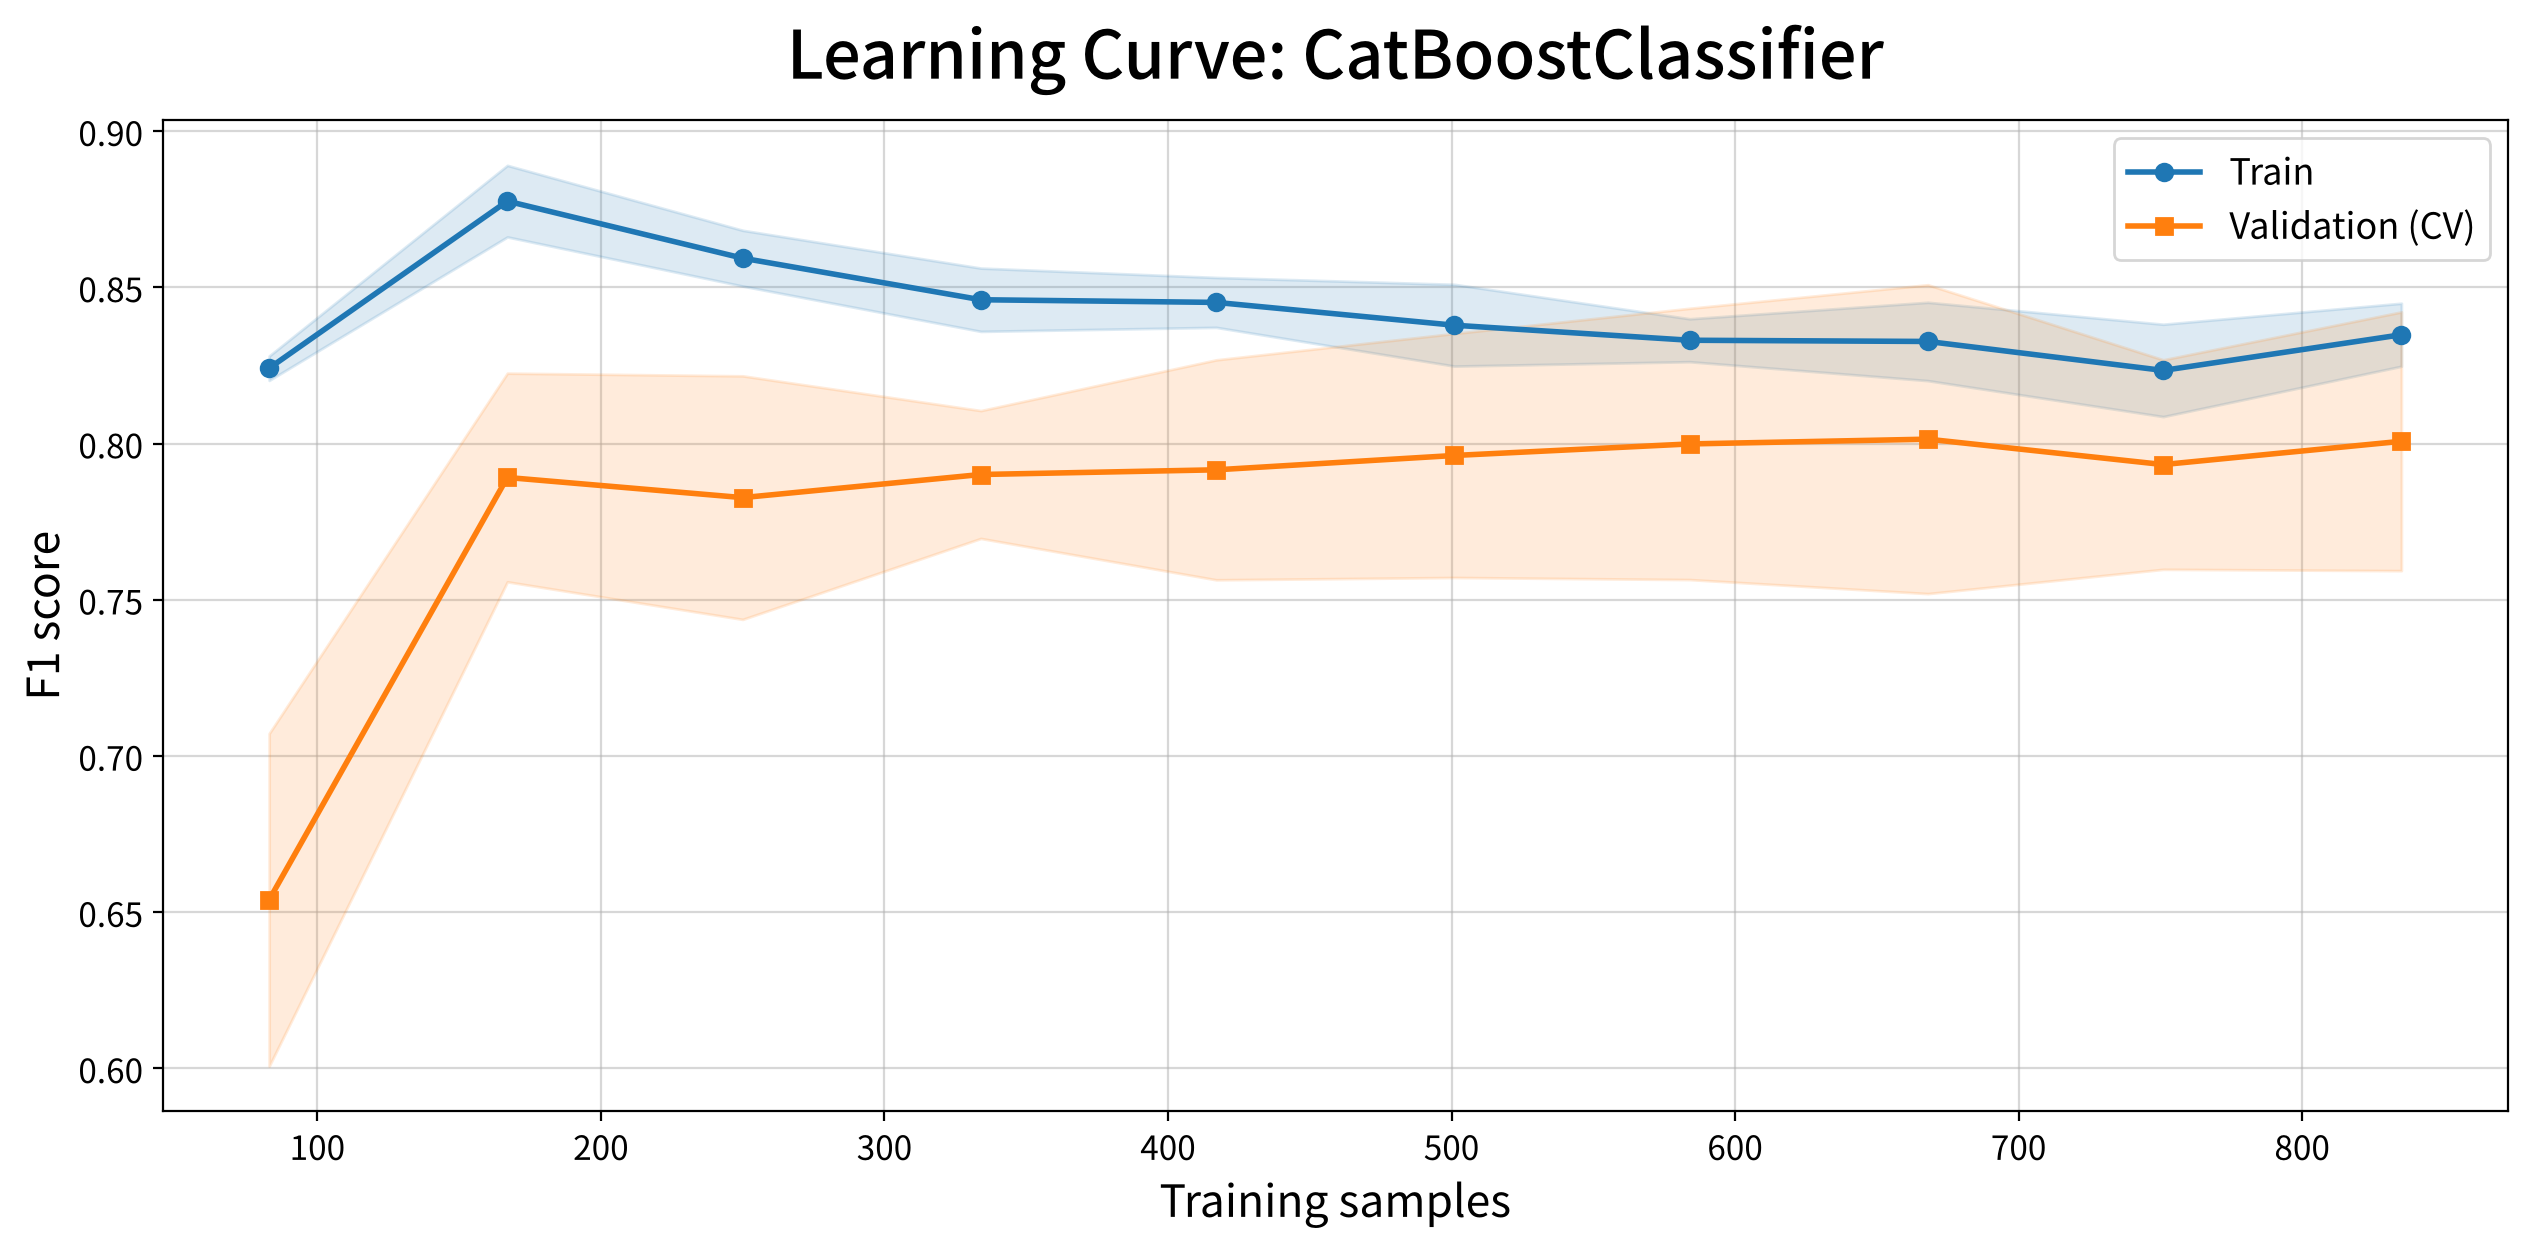


◆ Fit Diagnosis: CatBoostClassifier  (threshold=15%, 기준=Train↔CV 5-Fold)
   ▷ 탐색 객체의 best_params: {'model__depth': 4, 'model__iterations': 500, 'model__learning_rate': 0.03}
   ※ threshold 는 학술 표준이 아닌 경험칙입니다. 임계값보다 학습곡선 추세를 함께 보세요.
   - F1      Train=     0.8268  CV=     0.8007 (±0.0414)  Test=     0.8571  Gap%=    2.60%  [일반화]
   - ROC_AUC  Train=     0.9288  CV=     0.9010 (±0.0230)  Test=     0.9262  Gap%=    2.78%  [일반화]
   - Accuracy  Train=     0.8736  CV=     0.8554 (±0.0310)  Test=     0.8931  Gap%=    1.82%  [일반화]

   ▶ 진단: ✔ 일반화 (Good fit) — 격차가 작고 훈련 성능도 양호
     · train ROC_AUC=0.9288 (과소적합 기준 < 0.6) · CV ROC_AUC=0.9010

CPU times: user 362 ms, sys: 21.6 ms, total: 383 ms
Wall time: 21.2 s


,Train,CV,CV_Std,Test,Gap,Gap%,Overfit
Metric,,,,,,,
F1,0.827,0.801,0.041,0.857,0.026,2.600,일반화
ROC_AUC,0.929,0.901,0.023,0.926,0.028,2.780,일반화
Accuracy,0.874,0.855,0.031,0.893,0.018,1.820,일반화


In [75]:
%%time
model = my_ml.load_model(f"{workdir}/catboost.pkl")

# CatBoost 는 범주형 변수를 직접 처리하므로, 교차검증 재학습에도 범주형 컬럼 목록을 넘긴다
my_ml.cls_overfit(model, x_train, y_train, x_test, y_test,
                  fit_params={"model__cat_features": my_qtcheck.get_categorical_column_names(x_train)})

---
##### 💡 인사이트 — 과적합 판정: 둘 다 일반화, CV F1은 구분되지 않고 ROC_AUC는 CatBoost가 조금 앞선다

| 지표 | ElasticNet (Train / CV / Test) | CatBoost (Train / CV / Test) | 판정 |
|---|---|---|---|
| F1 | 0.818 / **0.805** / 0.857 | 0.827 / **0.801** / 0.857 | 둘 다 일반화 |
| ROC_AUC | 0.898 / **0.890** / 0.928 | 0.929 / **0.901** / 0.926 | 둘 다 일반화 |
| Accuracy | 0.870 / **0.858** / 0.893 | 0.874 / **0.855** / 0.893 | 둘 다 일반화 |
| Gap% (F1) | **1.34%** | 2.60% | 둘 다 15%보다 훨씬 작다 |

- 두 모델 모두 **Train ROC_AUC가 0.6 이상**(0.898 · 0.929)이라 과소적합이 아니고, **Gap%가 15%보다 훨씬 작아** 과대적합도 아니다 → **일반화** 판정이다.
- **CV F1 차이는 0.004**(0.805 vs 0.801)로, CV 표준편차(±0.04)보다 훨씬 작다. F1로는 두 모델을 구분할 수 없다.
- **CV ROC_AUC는 CatBoost가 0.011 높다**(0.901 vs 0.890). 다만 이 차이도 CV 표준편차(±0.02 ~ 0.03)보다 작아 확실한 우위는 아니다. 정확도는 0.003 차이로 거의 같다.

**학습곡선**
- **ElasticNet** : 표본 170개 이후 Train과 CV가 0.78 ~ 0.81에서 거의 겹친 채 움직인다.
- **CatBoost** : Train(약 0.88 → 0.835)은 내려오고 CV(약 0.79 → 0.80)는 조금씩 올라 **두 곡선이 점점 가까워진다.**

**결정 — 이후 분석은 CatBoost로 진행한다**
- 두 모델은 사실상 동률이다. 동률일 때는 보조 지표를 기준으로 삼아, **CV ROC_AUC가 조금 더 높은 CatBoost**를 고른다.
- 선형 모델의 해석은 PART 1 ~ 5의 로지스틱 회귀가 이미 맡고 있다. 트리 계열인 CatBoost는 가족 규모처럼 **꺾이는 모양을 스스로 찾을 수 있는 모델**이라, 로지스틱 회귀와 다른 관점에서 결과를 확인할 수 있다.

---

## 8-3. Feature Importance

### (1) Feature Importance 도출

- 성능에 영향이 없을 수준으로 변수의 수를 줄여서 일반화 성능을 높이고 모형 설명의 용이성을 확보하려는 시도
  - 변수가 많을 수록 과적합 가능성이 높아진다.

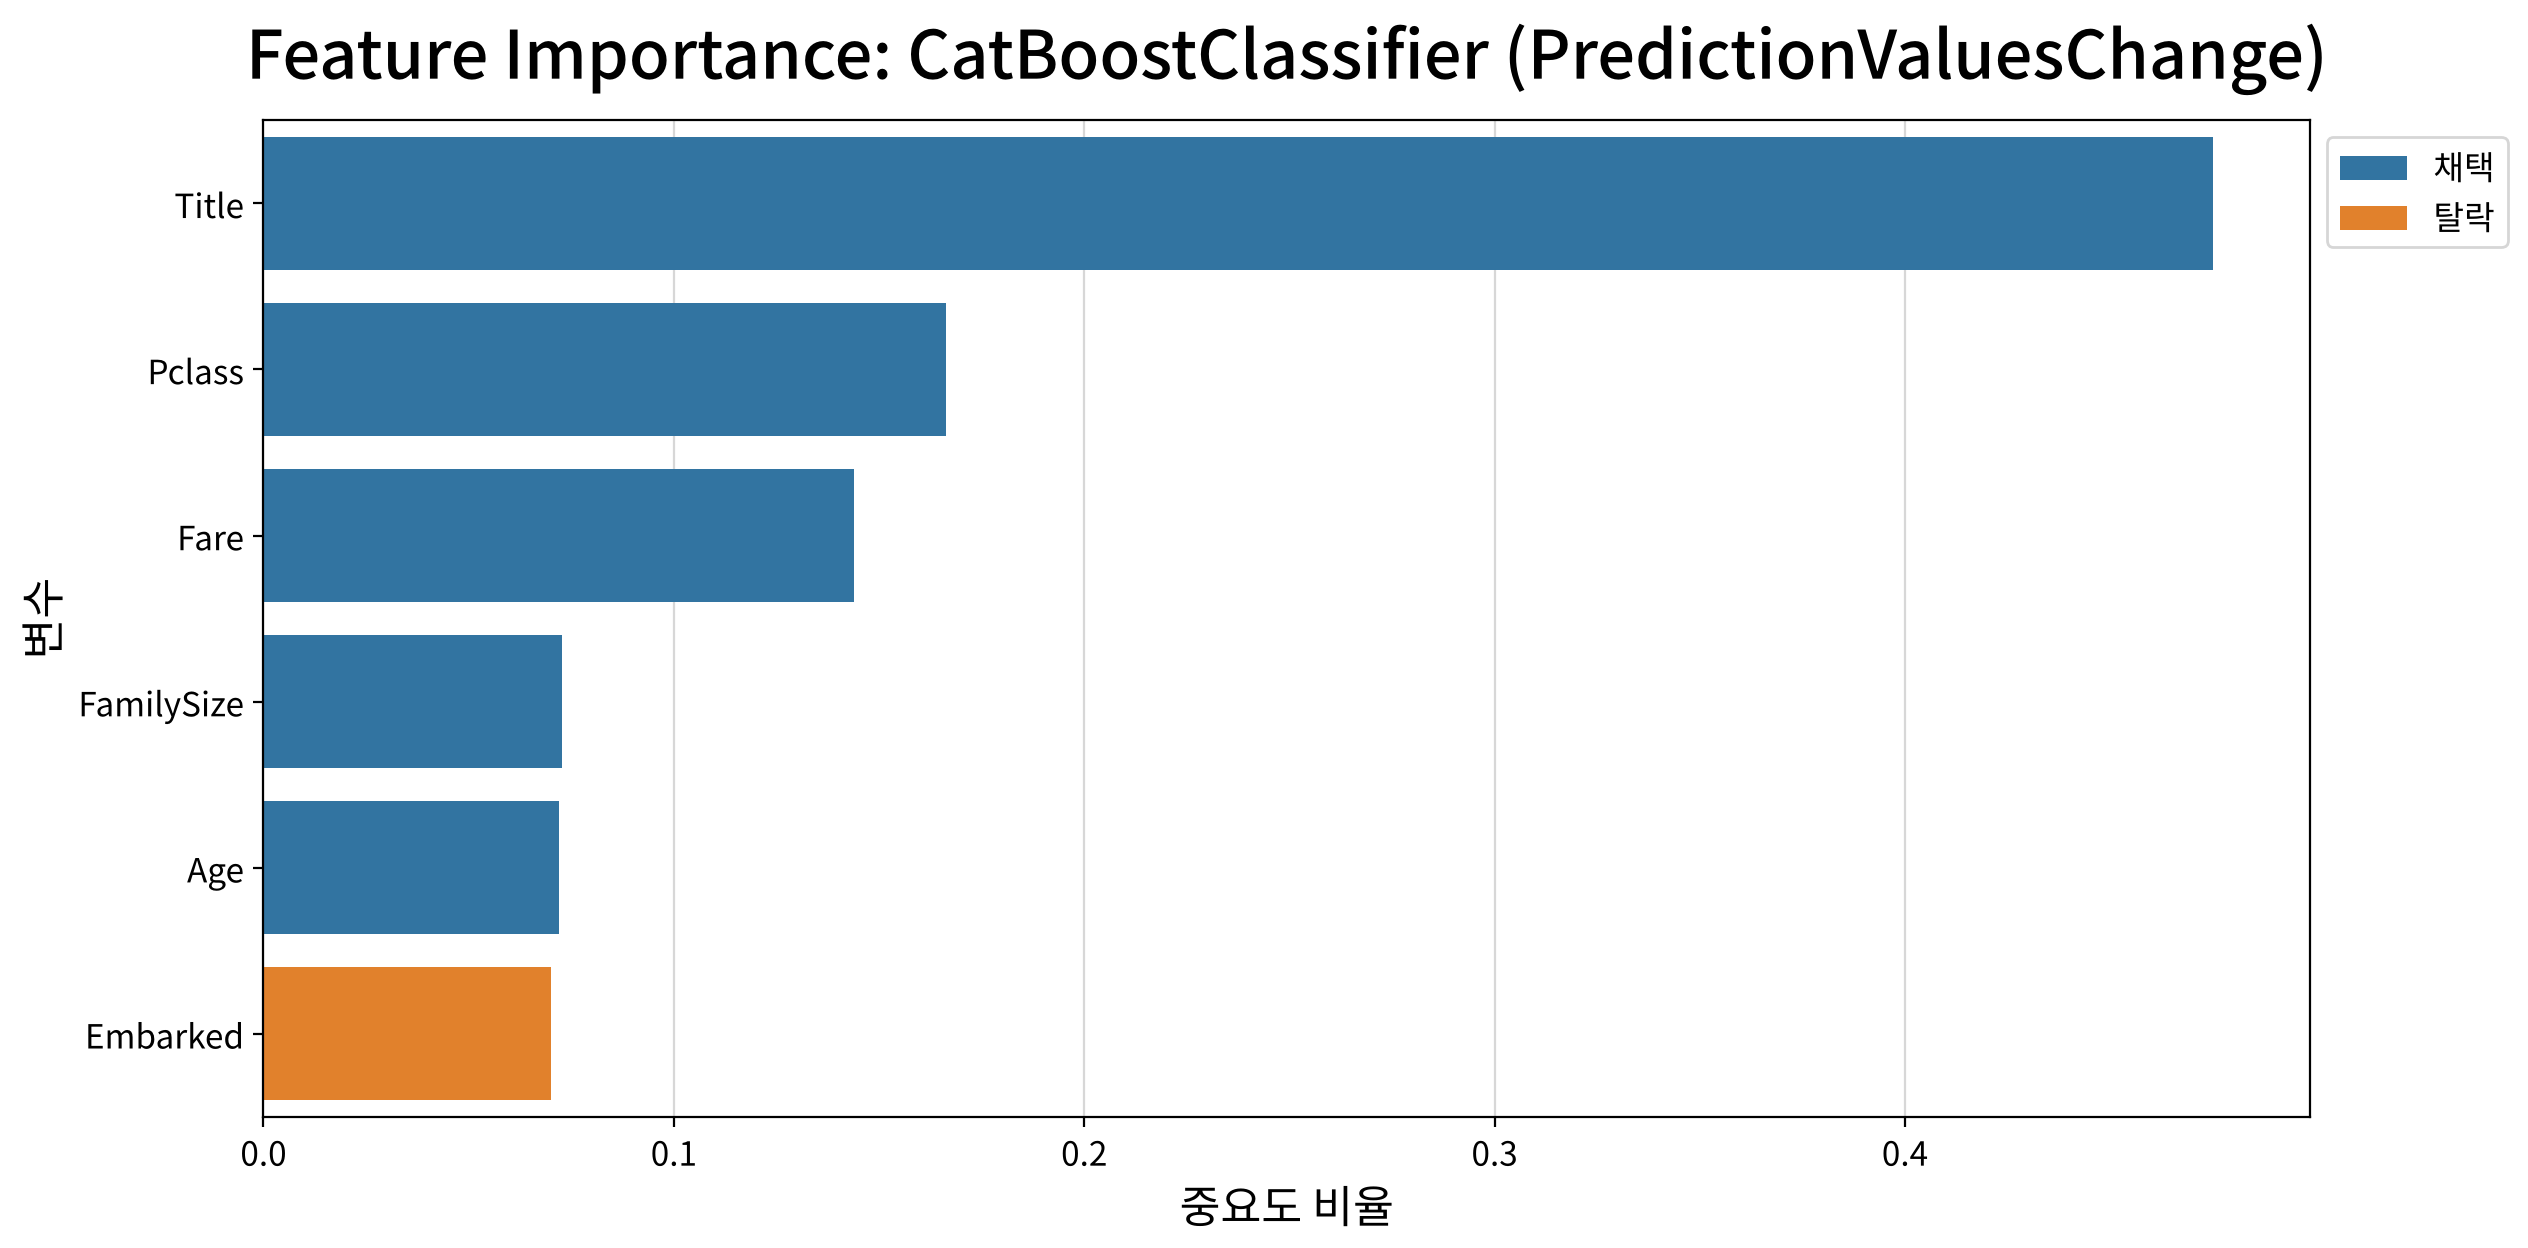


◆ Feature Importance: CatBoostClassifier  (중요도 기준=PredictionValuesChange, 채택 기준=cum_ratio=90%)
   ▷ 탐색 객체의 best_params: {'model__depth': 4, 'model__iterations': 500, 'model__learning_rate': 0.03}
   전체 변수 6개 중 5개 채택 (누적 중요도 92.99% 설명)
   ▶ 채택된 변수: ['Title', 'Pclass', 'Fare', 'FamilySize', 'Age']



,Importance,Ratio,CumRatio,채택여부
Feature,,,,
Title,47.496,0.475,0.475,채택
Pclass,16.634,0.166,0.641,채택
Fare,14.399,0.144,0.785,채택
FamilySize,7.268,0.073,0.858,채택
Age,7.193,0.072,0.930,채택
Embarked,7.009,0.070,1.000,탈락


In [76]:
# 최종 채택 모델인 CatBoostClassifier 모델 로드
model = my_ml.load_model(f"{workdir}/catboost.pkl")

# 로드한 모델의 feature importance 확인
fi = my_ml.feature_importance(model, cum_ratio=0.9)
fi

---
##### 💡 인사이트 — Title이 중요도의 절반

- **`Title` 47.5%** → `Pclass` 16.6% → `Fare` 14.4% → `FamilySize` 7.3% → `Age` 7.2% → `Embarked` 7.0%
- `Title` 하나가 2위 `Pclass`의 **약 2.9배**다.
- `Title`은 이름에서 뽑아낸 **파생변수**다. 로지스틱 회귀에서도 β 상위 2개가 호칭(기혼 · 미혼 여성)이었다 — 두 모델 모두 신분을 가장 큰 요인으로 본다.
- 누적 90% 기준으로 **5개 채택**, `Embarked` **1개 탈락**이다.

---

### (2) Title에 따른 생존 비율

- 분석을 수행하던 중 문득 궁금해져서 시각화 해 보았다. 
  - Title이 생존에 가장 큰 영향을 주는 변수이고, Title에는 성별과 나이 정보가 함축되어 있다면,     
  나이와 성별에 따른 생존 여부의 차이를 이 데이터가 말할 수 있는지 확인해 본다.

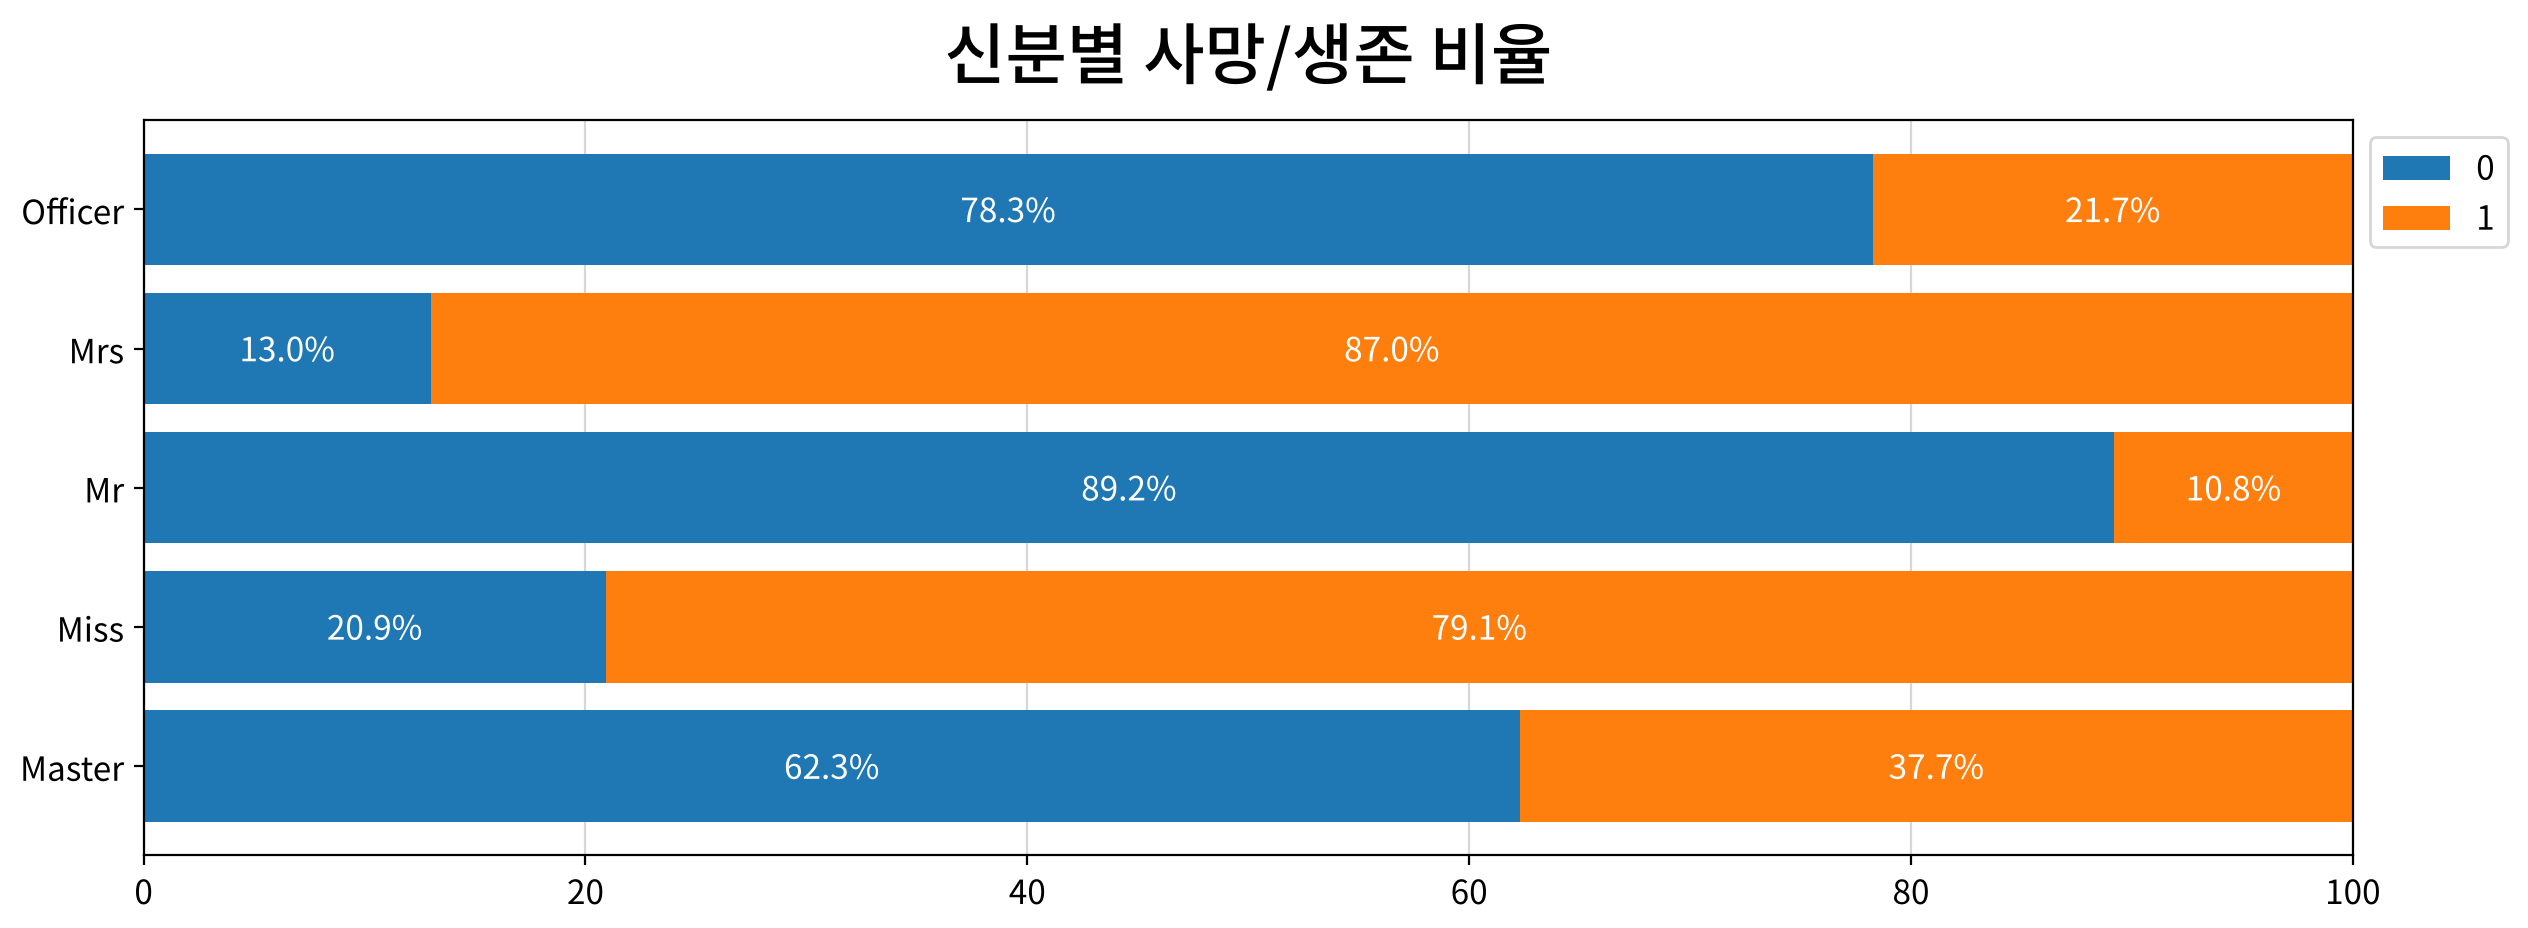

In [77]:
fig, ax = my_plot.init(title="신분별 사망/생존 비율", height=480)

# 탑승객 수를 단순히 count하여 Survived 여부에 따라 비율로 시각화
my_plot.stackplot(origin, x="Title", y="Fare", hue="Survived", ratio=True, 
                  orient='h', aggfunc="count", ax=ax)

my_plot.show()

---
##### 💡 인사이트 — 호칭별 생존 비율

| 호칭 | Master | Miss | Mr | Mrs | Officer |
|---|---|---|---|---|---|
| 생존 비율 | 37.7% | **79.1%** | **10.8%** | **87.0%** | 21.7% |

- 여성(Mrs · Miss)의 생존 비율이 가장 높고, 그다음이 남자아이(Master)다. 성인 남성(Mr)은 10.8%로 가장 낮다.
- 같은 남성이라도 **Master(37.7%)는 Mr(10.8%)의 약 3.5배**다. 성별만으로는 나뉘지 않는 차이를 호칭이 구분한다.

---

### (3) 채택된 변수 추출

- `feature_importance()` 의 반환 표에서 채택/탈락을 확인하고    
   **채택된 변수 목록만** 꺼내 재학습에 사용한다.

In [78]:
# 채택된 변수 목록 (재학습에 사용)
selected = fi.attrs['selected_features']
dropped = [c for c in x_train.columns if c not in selected]

print(f"채택 {len(selected)}개: {selected}")
print(f"탈락 {len(dropped)}개: {dropped}")

채택 5개: ['Title', 'Pclass', 'Fare', 'FamilySize', 'Age']
탈락 1개: ['Embarked']


---
##### 💡 인사이트 — 탈락한 변수 1개

- **`Embarked`(7.0%) 탈락** : 누적 중요도 93.0%까지가 다른 5개 변수로 채워져 기준(90%)을 넘었다.

---

### (4) 데이터에서 채택된 변수만 추출

In [79]:
# 훈련 데이터에서 채택된 변수만 추출
x_tr = x_train[selected]
display(x_tr.columns)

# 검증 데이터에서 채택된 변수만 추출
x_te = x_test[selected]
display(x_te.columns)

Index(['Title', 'Pclass', 'Fare', 'FamilySize', 'Age'], dtype='str')

Index(['Title', 'Pclass', 'Fare', 'FamilySize', 'Age'], dtype='str')

### (5) 베이스라인 모델 재학습

- 채택된 변수를 활용하여 베이스라인에 대해 **학습➔튜닝➔과적합 진단**을 다시 수행하여 **직전 단계 모델과 성능을 비교**한다.
  - 성능에 큰 차이가 없다면 변수를 축소한 모델을 채택
  - 성능에 유의미한 차이가 있다면 변수 축소 모델을 폐기하고 직전 단계 모델 채택

In [80]:
catboost = my_ml.fit_pipeline(
            model=CatBoostClassifier(random_state=RANDOM_STATE, verbose=0),
            x_train=x_tr, y_train=y_train,
            vif=True,
            encode=False,   # CatBoost는 자체적으로 범주형 처리
            model__cat_features=my_qtcheck.get_categorical_column_names(x_tr))

display(my_ml.cls_score(catboost, x_te, y_test))

catboost

대상: 1044행 x 5열 | 모델: catboost
명목형: ['Title', 'Pclass']
연속형: ['Fare', 'FamilySize', 'Age']

전처리 단계
  연속형: 다중공선성 제거(VIF >= 10.0)
  명목형: (변환 없음)



모델 학습 완료: catboost


,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,LogLoss,MCC
Model,,,,,,,,
CatBoostClassifier,0.882,0.840,0.848,0.844,0.919,0.895,0.325,0.749


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](5,)","['Title','Pclass','Fare','FamilySize','Age']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,5
name_,str,'ca...st'
pipeline_info_,dict,"{'ca...te': 'mo...nt', 'co...ls': ['Fare', 'Fa...ze', 'Age'], 'dr...st': False, 'encode': False, ...}"
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"


### (6) 하이퍼파라미터 튜닝

In [81]:
%%time

# PART 7 의 CatBoost 튜닝과 같은 조합을 쓴다.
# 변수만 줄이고 조건을 똑같이 맞춰야 "변수 선택의 효과"만 따로 볼 수 있다
param_grid = {
    "model__iterations": [500, 1000],
    "model__depth": [4, 6, 8],
    "model__learning_rate": [0.03, 0.05, 0.1]
}

# 하이퍼파라미터 튜닝 수행 --> 카테고리타입 지정해야 함
gs = GridSearchCV(estimator=catboost, param_grid=param_grid, cv=5,
                  scoring="f1", n_jobs=-1)
gs.fit(x_tr, y_train, model__cat_features=my_qtcheck.get_categorical_column_names(x_tr))

if not os.path.exists(savedir):
    os.makedirs(savedir)

gs.name_ = f"{model.name_}_selected"   # 변수 선택 후 재튜닝된 모델임을 이름에 남긴다
my_ml.save_model(gs, f"{savedir}/catboost.pkl")     # 튜닝이 완료된 모델을 저장한다.
display(my_ml.cls_score(gs, x_te, y_test))          # 성능 평가

,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,LogLoss,MCC
Model,,,,,,,,
CatBoostClassifier,0.885,0.848,0.848,0.848,0.927,0.911,0.315,0.756


CPU times: user 1.69 s, sys: 176 ms, total: 1.86 s
Wall time: 1min 21s


### (7) 과적합 판정

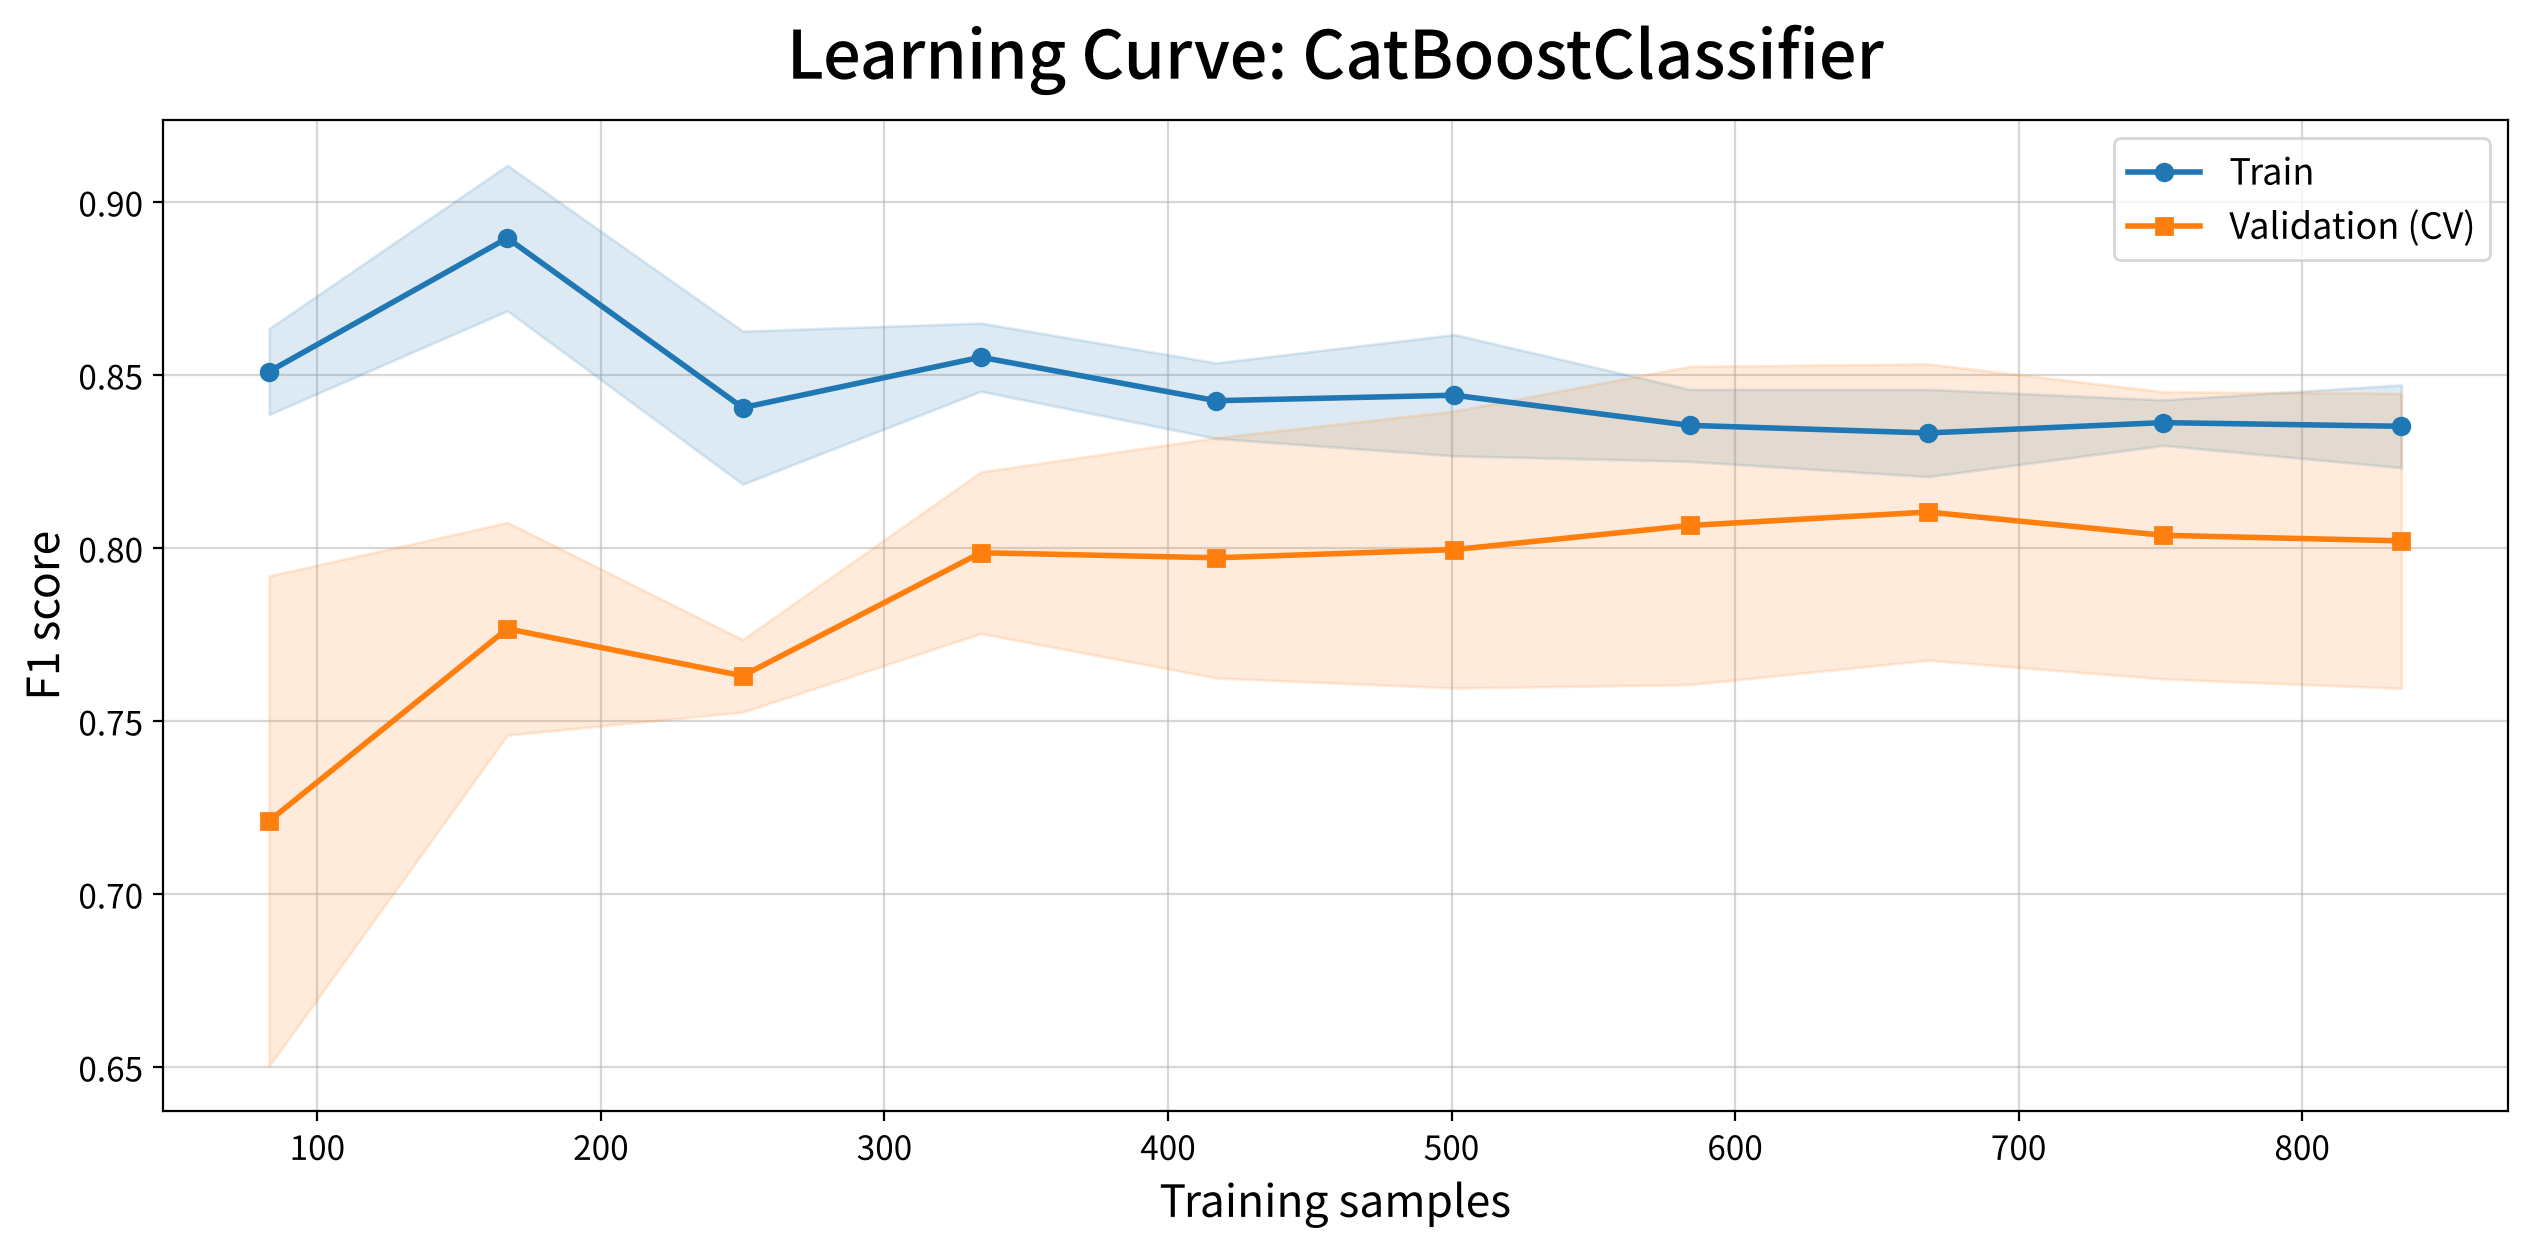


◆ Fit Diagnosis: CatBoostClassifier  (threshold=15%, 기준=Train↔CV 5-Fold)
   ▷ 탐색 객체의 best_params: {'model__depth': 4, 'model__iterations': 500, 'model__learning_rate': 0.03}
   ※ threshold 는 학술 표준이 아닌 경험칙입니다. 임계값보다 학습곡선 추세를 함께 보세요.
   - F1      Train=     0.8274  CV=     0.8036 (±0.0436)  Test=     0.8485  Gap%=    2.38%  [일반화]
   - ROC_AUC  Train=     0.9362  CV=     0.8993 (±0.0237)  Test=     0.9274  Gap%=    3.68%  [일반화]
   - Accuracy  Train=     0.8745  CV=     0.8563 (±0.0338)  Test=     0.8855  Gap%=    1.82%  [일반화]

   ▶ 진단: ✔ 일반화 (Good fit) — 격차가 작고 훈련 성능도 양호
     · train ROC_AUC=0.9362 (과소적합 기준 < 0.6) · CV ROC_AUC=0.8993

CPU times: user 299 ms, sys: 44.7 ms, total: 344 ms
Wall time: 19 s


,Train,CV,CV_Std,Test,Gap,Gap%,Overfit
Metric,,,,,,,
F1,0.827,0.804,0.044,0.848,0.024,2.380,일반화
ROC_AUC,0.936,0.899,0.024,0.927,0.037,3.680,일반화
Accuracy,0.875,0.856,0.034,0.885,0.018,1.820,일반화


In [82]:
%%time
my_ml.cls_overfit(gs, x_tr, y_train, x_te, y_test,
                  fit_params={"model__cat_features": my_qtcheck.get_categorical_column_names(x_tr)})

---
##### 💡 인사이트 — 변수를 하나 줄여도 성능은 유지된다

- 비교는 **CV · Test**로 하고, Train은 과적합 판정(Gap%)에만 쓴다. Train 점수는 외운 데이터에서 나온 값이라 높을수록 좋은 게 아니기 때문이다.

| 지표 | 6개 변수 (CV / Test) | 5개 변수 (CV / Test) | 판정 (5개 변수) |
|---|---|---|---|
| F1 | 0.801 / 0.857 | **0.804** / 0.848 | 일반화 (Gap 2.38%) |
| ROC_AUC | 0.901 / 0.926 | 0.899 / **0.927** | 일반화 (Gap 3.68%) |
| Accuracy | 0.855 / 0.893 | **0.856** / 0.885 | 일반화 (Gap 1.82%) |

- **CV 기준으로 F1 +0.003 · ROC_AUC −0.002 · 정확도 +0.001** 로 거의 변하지 않았다.
- **Test F1은 0.009 내려갔지만 CV 표준편차(±0.044) 안쪽**이다.
- → 성능이 그대로이고 변수가 하나 줄어 설명이 단순해지므로 **5개 변수 모델을 최종 채택**한다.

---

# PART 9. 머신러닝 ④ SHAP 분석

## 9-1. 준비

### (1) 저장 폴더

In [83]:
# 최종 모델이 저장되어 있는 위치
savedir = "titanic/importance"
savedir

'titanic/importance'

### (2) 최종 모델 로드

In [84]:
gs = my_ml.load_model(f"{savedir}/catboost.pkl")
gs

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step... verbose=0))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__depth': [4, 6, ...], 'model__iterations': [500, 1000], 'model__learning_rate': [0.03, 0.05, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, d

## 9-2. SHAP 분석

### (1) SHAP Explainer 객체 생성

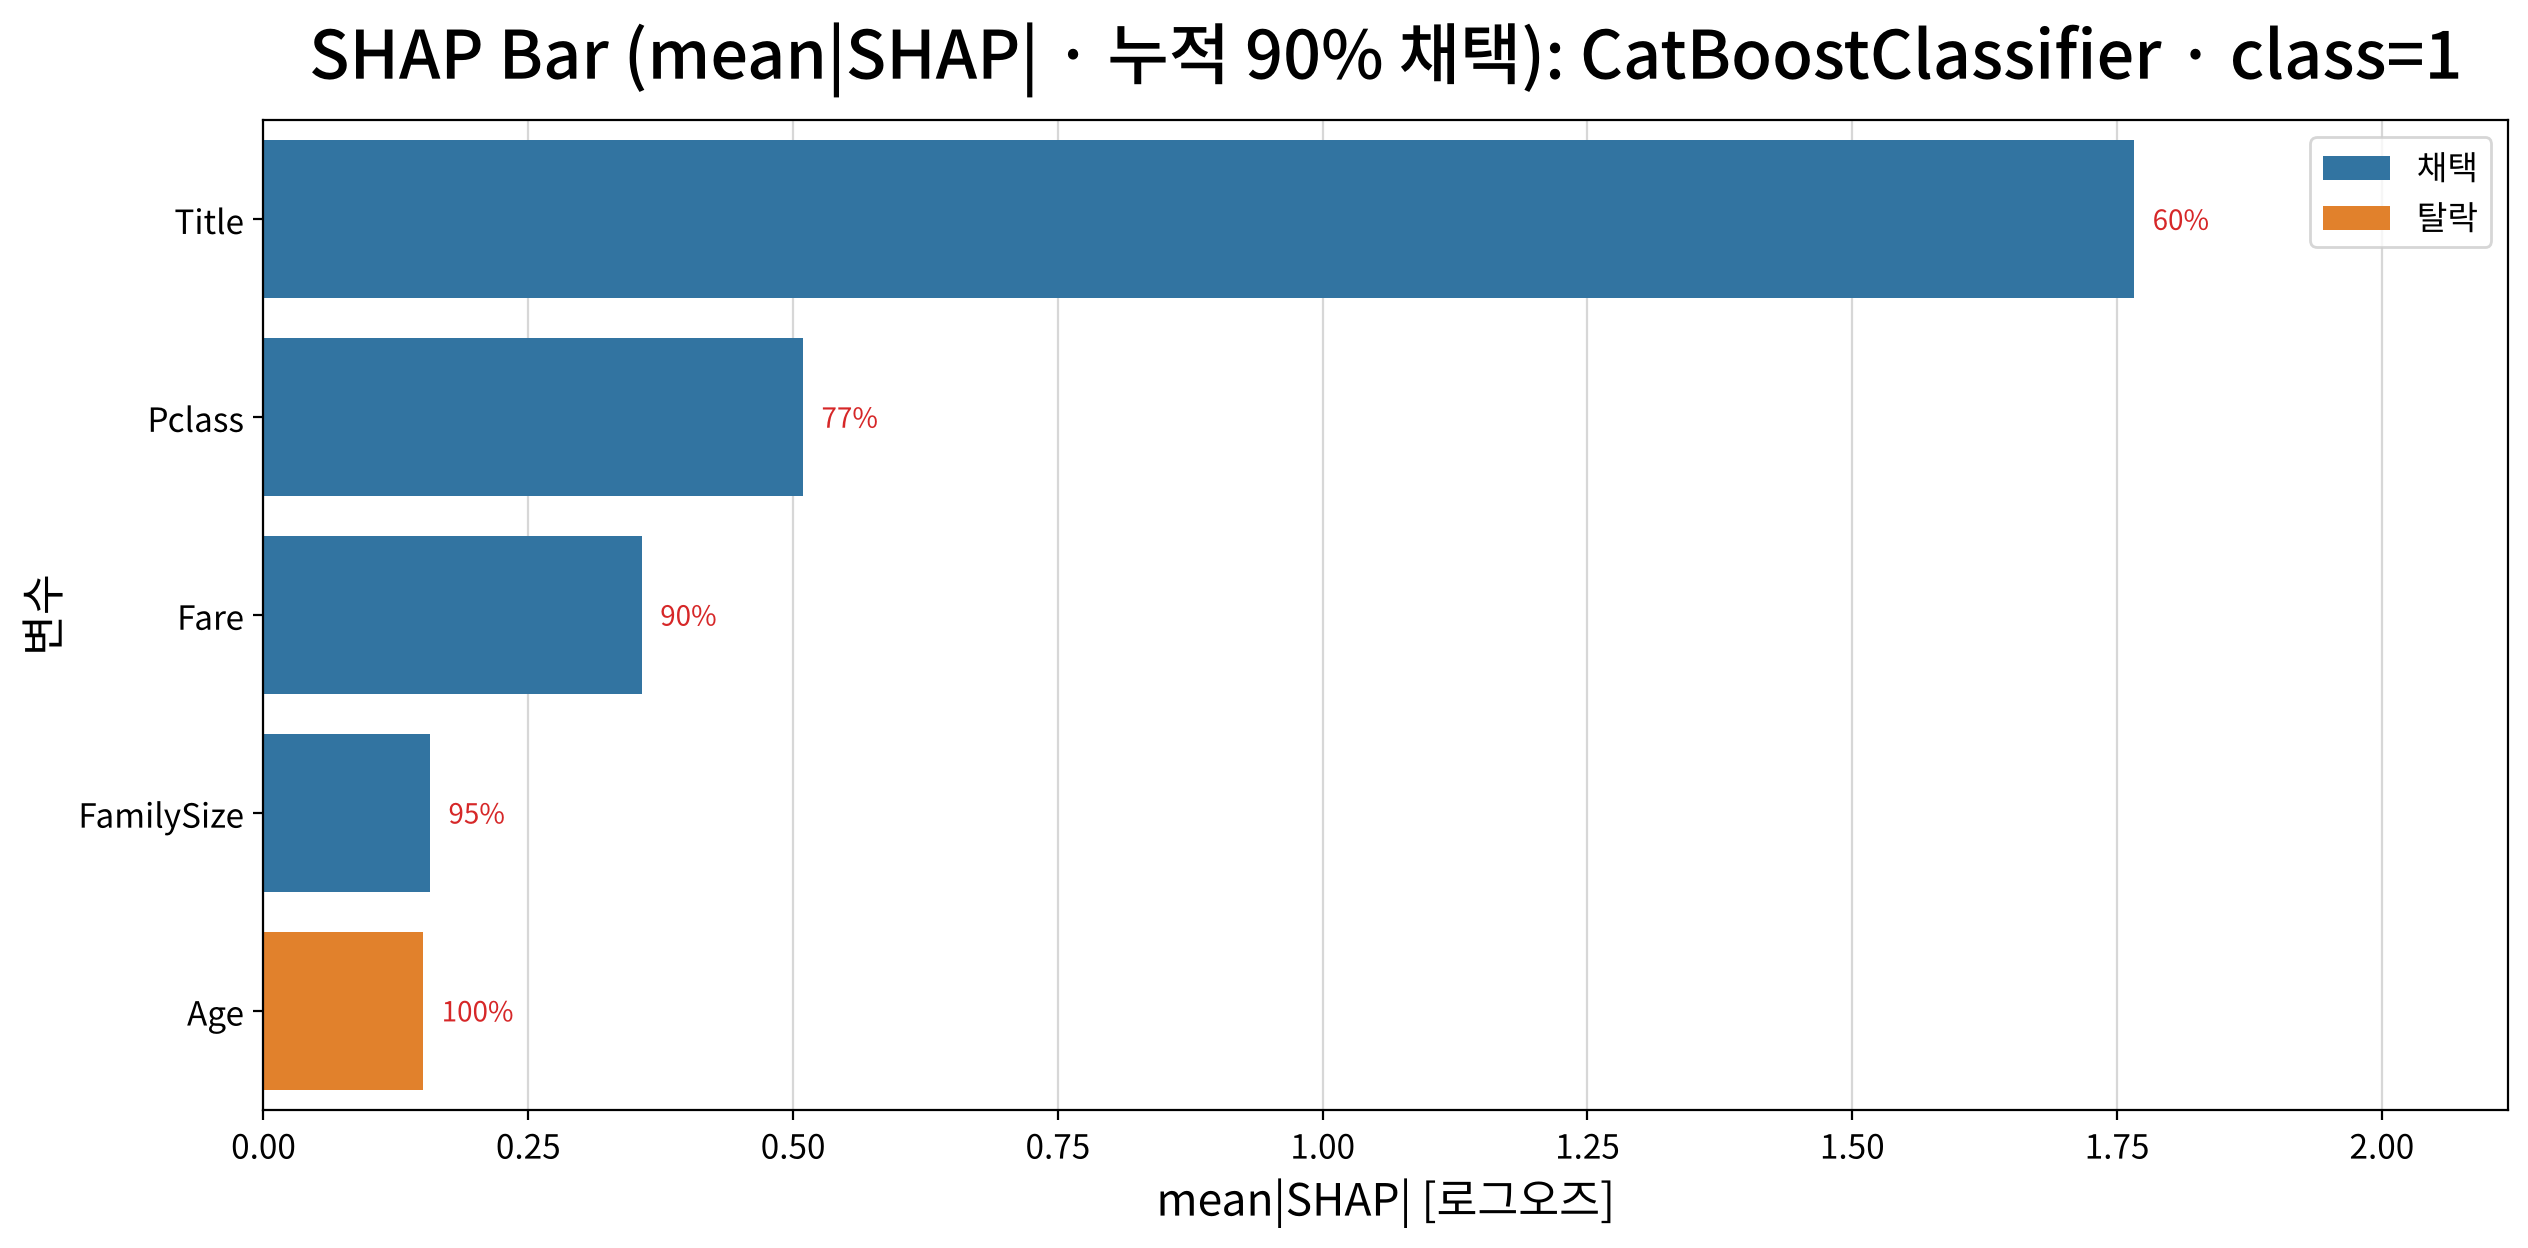

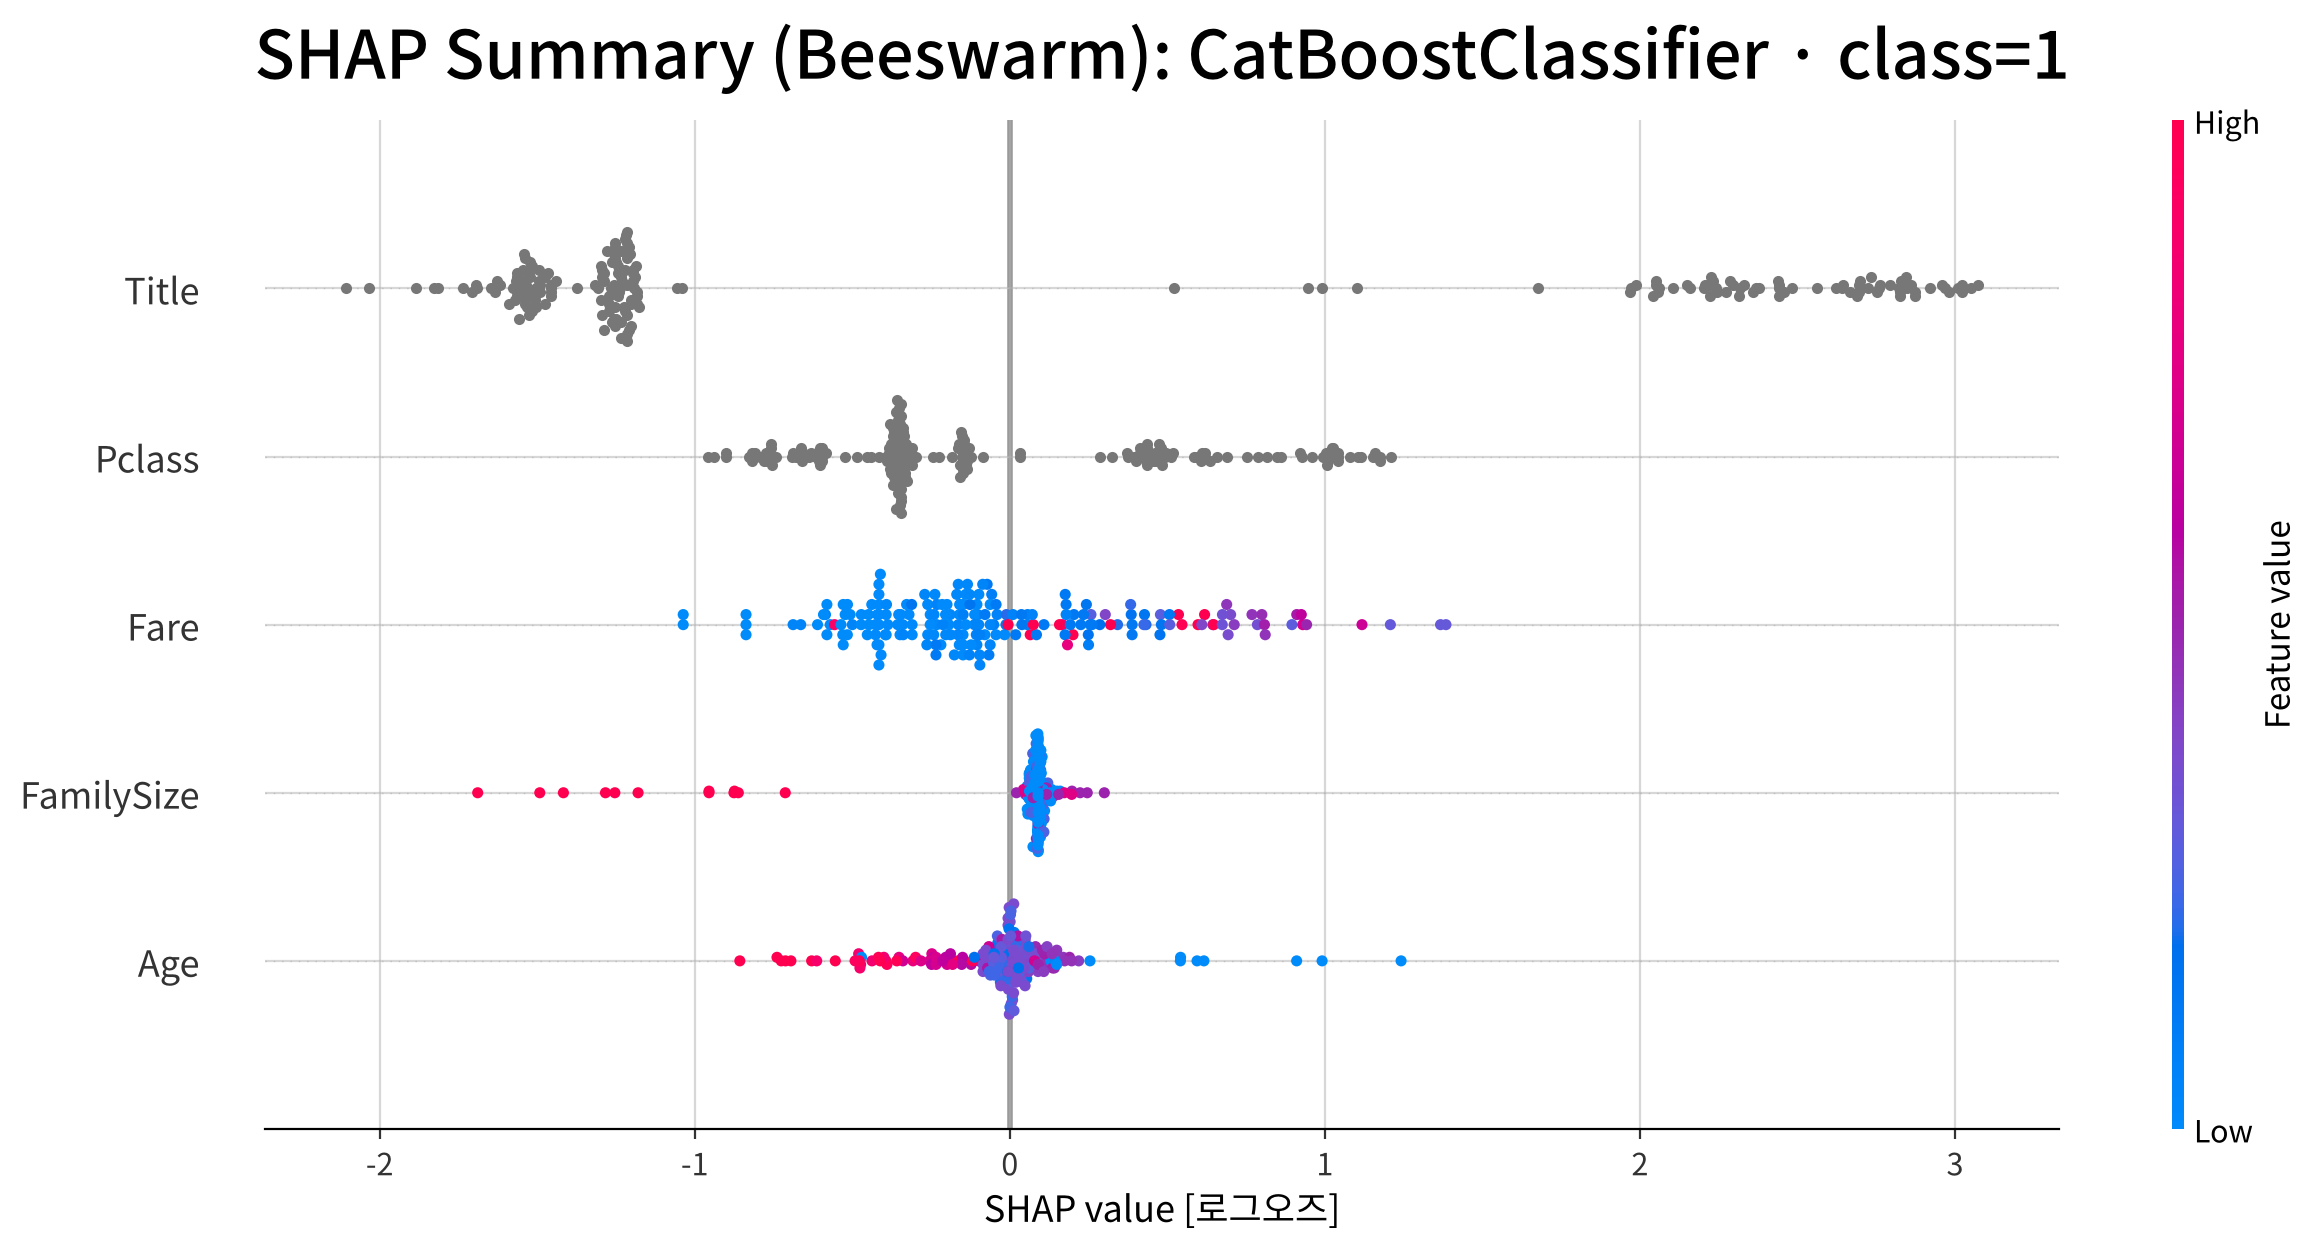


◆ SHAP Analysis: CatBoostClassifier  (TreeExplainer, classification)
   ▷ 설명 대상 클래스: 1 (index=1)
     이 모델은 출력이 하나라 SHAP 값이 양성 클래스 기준으로 나옵니다.
   ▷ 탐색 객체의 best_params: {'model__depth': 4, 'model__iterations': 500, 'model__learning_rate': 0.03}
   설명 표본 200행 × 변수 5개 · base value=-0.6159 · SHAP 단위=로그오즈
   → base value 를 확률로 바꾸면 35.07% (SHAP 값도 확률이 아니라 로그오즈 증감입니다)
   Title                  mean|SHAP|=1.7659  방향=증가  비선형/불안정
   Pclass                 mean|SHAP|=0.5092  방향=감소  비선형/불안정
   Fare                   mean|SHAP|=0.3569  방향=감소  비선형/불안정
   FamilySize             mean|SHAP|=0.1570  방향=증가  비선형/불안정
   Age                    mean|SHAP|=0.1506  방향=감소  비선형/불안정



In [85]:
# 앞에서 학습 완료한 최종 모델과 데이터 사용
shap = my_ml.shap_analysis(gs, x_tr)

---
##### 💡 인사이트

**Bar Plot — 전역 영향력**

| 순위 | 변수 | mean\|SHAP\| | 비중 | 누적 |
|---|---|---|---|---|
| 1 | `Title` | 1.766 | 60.1% | 60.1% |
| 2 | `Pclass` | 0.509 | 17.3% | 77.4% |
| 3 | `Fare` | 0.357 | 12.1% | 89.5% |
| 4 | `FamilySize` | 0.157 | 5.3% | 94.9% |
| 5 | `Age` | 0.151 | 5.1% | 100% |

- **`Title` 하나가 60%** 로, 2위 `Pclass`의 약 3.5배다. Feature Importance(47.5%)보다 비중이 더 크다.
- 그래프에서 `Age`가 '탈락'으로 표시된 것은 누적 90% 표시 기준일 뿐이다. 변수 선택은 앞의 Feature Importance로 이미 끝났으므로 다시 줄이지 않는다.

**Beeswarm — 방향과 분포**
- **`Title`은 두 덩어리로 갈린다** : 왼쪽(−2.1 ~ −1.0)과 오른쪽(+0.5 ~ +3.1). 범주형이라 색 없이 회색으로 표시된다.
- **`Fare`** : 저액(파랑)이 왼쪽(−1.0 ~ 0), 고액(빨강 · 보라)이 오른쪽(+0.1 ~ +1.1)에 모인다. 다만 파랑 일부도 오른쪽(+1.4까지)에 있다.
- **`FamilySize`** : 대부분(파랑, 작은 가족)은 0 바로 오른쪽(+0.0 ~ +0.3)에 모여 있고, **빨강(대가족)만 −0.7 ~ −1.7로 멀리 떨어져 있다.** → "대가족이면 크게 불리"라는 한쪽 방향의 효과다.
- **`Age`** : 고령(빨강)이 왼쪽(−0.9까지), 저연령(파랑) 일부가 오른쪽(+1.2까지)에 있다. 대부분은 0 근처다.
- ⚠️ 요약표의 `방향`은 SHAP 평균의 부호일 뿐이라, 두 덩어리로 갈리는 변수에서는 믿을 수 없다. **방향은 Beeswarm과 Dependence Plot으로 읽는다.**

---

### (2) Dependence Plot

◆ SHAP Dependence — 변수쌍(주변수 × 상호작용변수) · 선정기준=cum_ratio=90%
   Title  ×  Pclass
   Pclass  ×  Fare
   Fare  ×  FamilySize
   FamilySize  ×  Fare


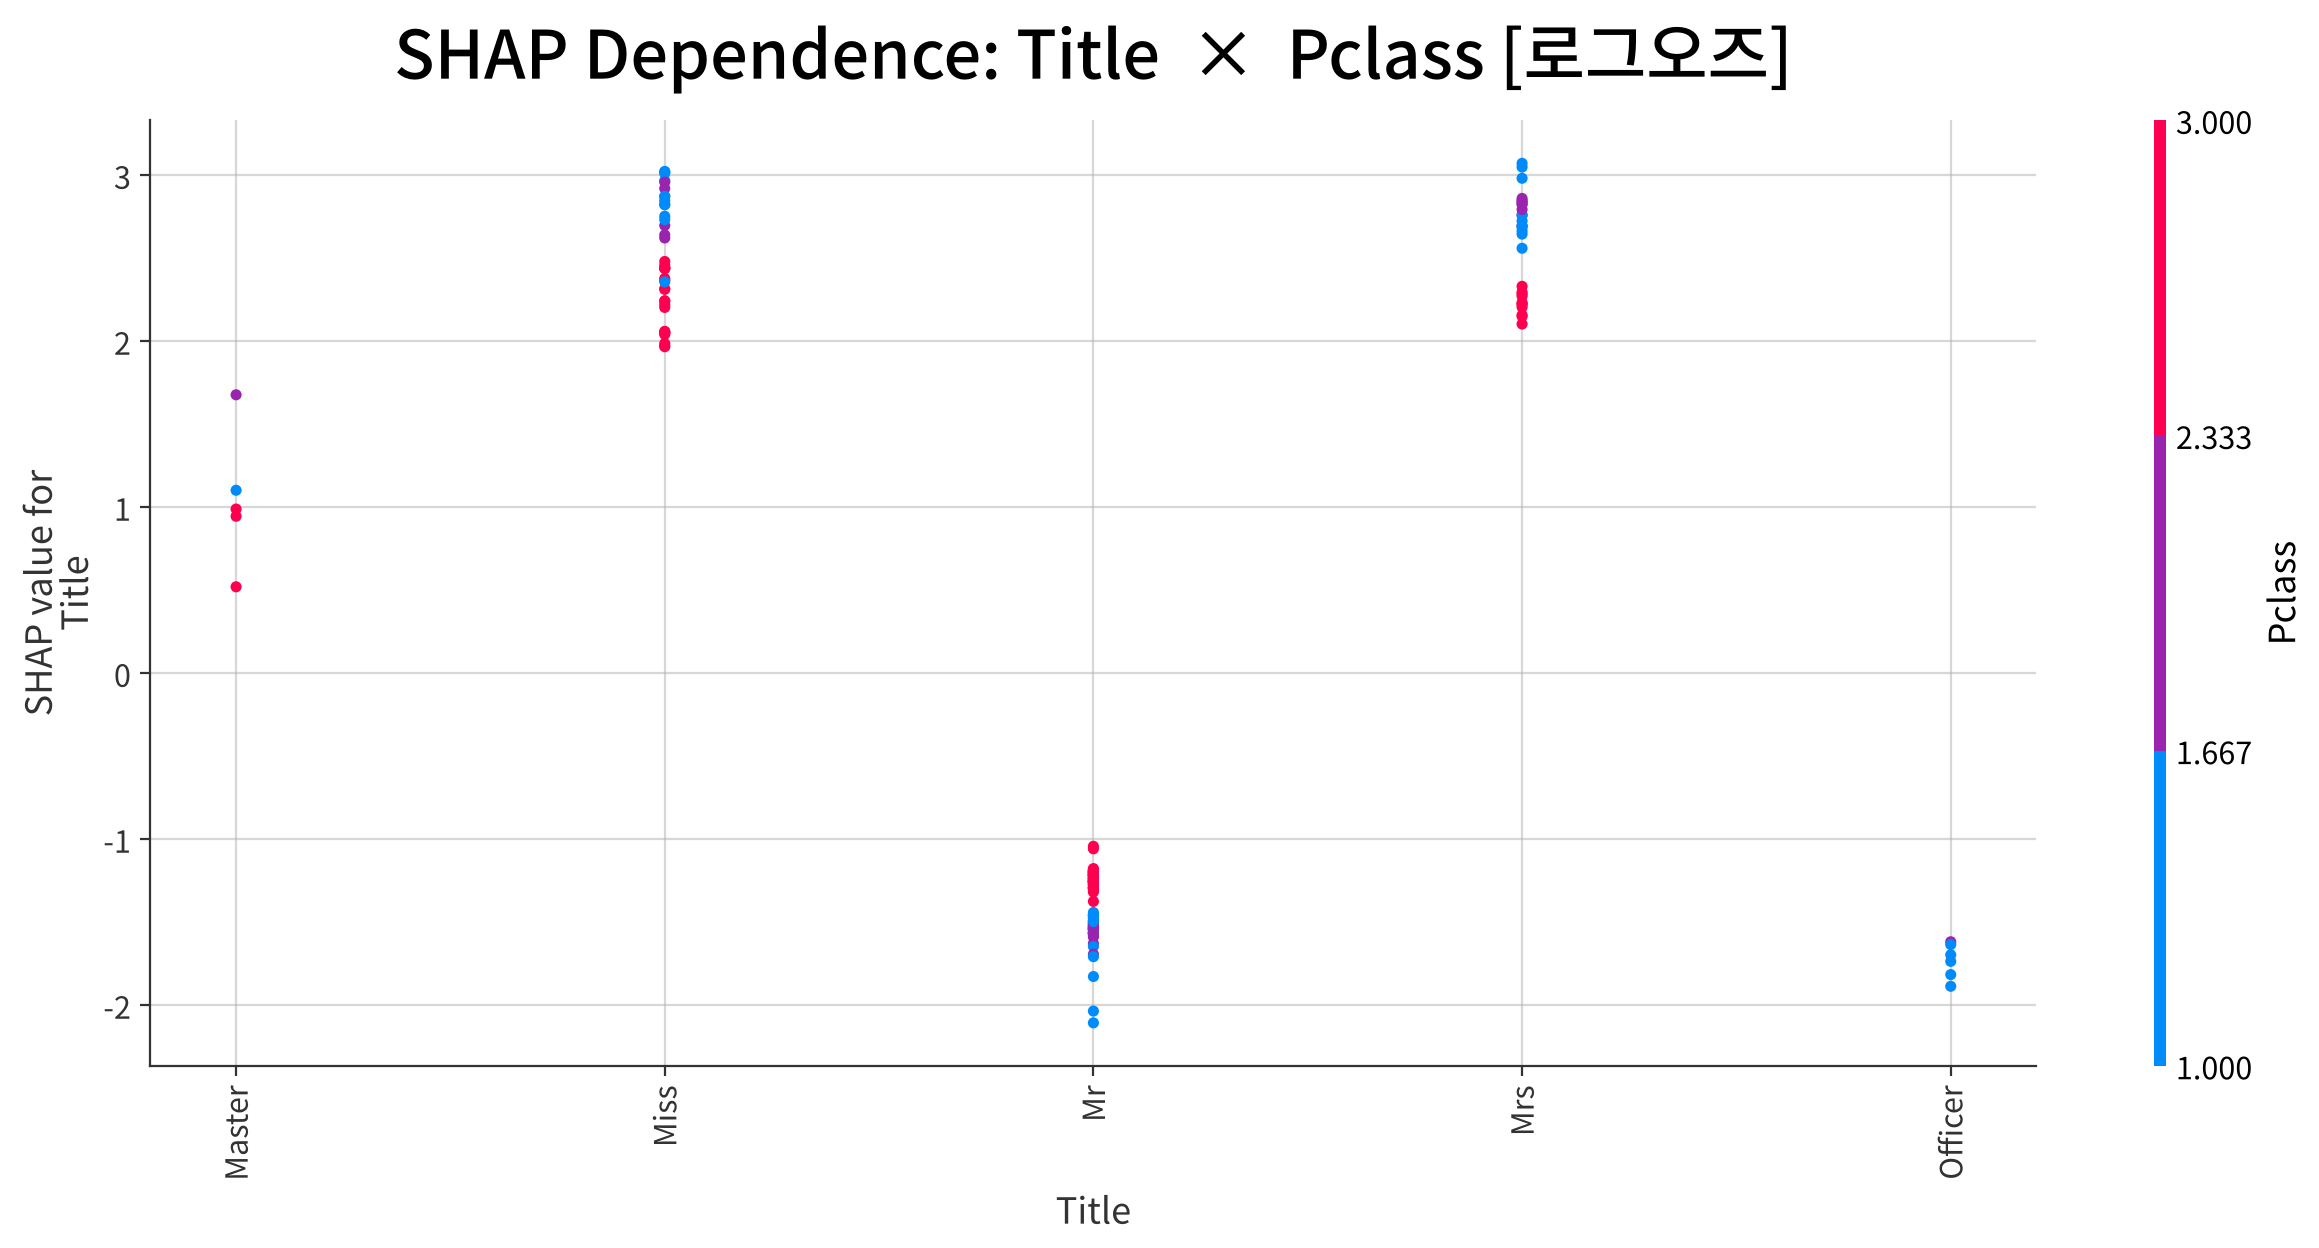

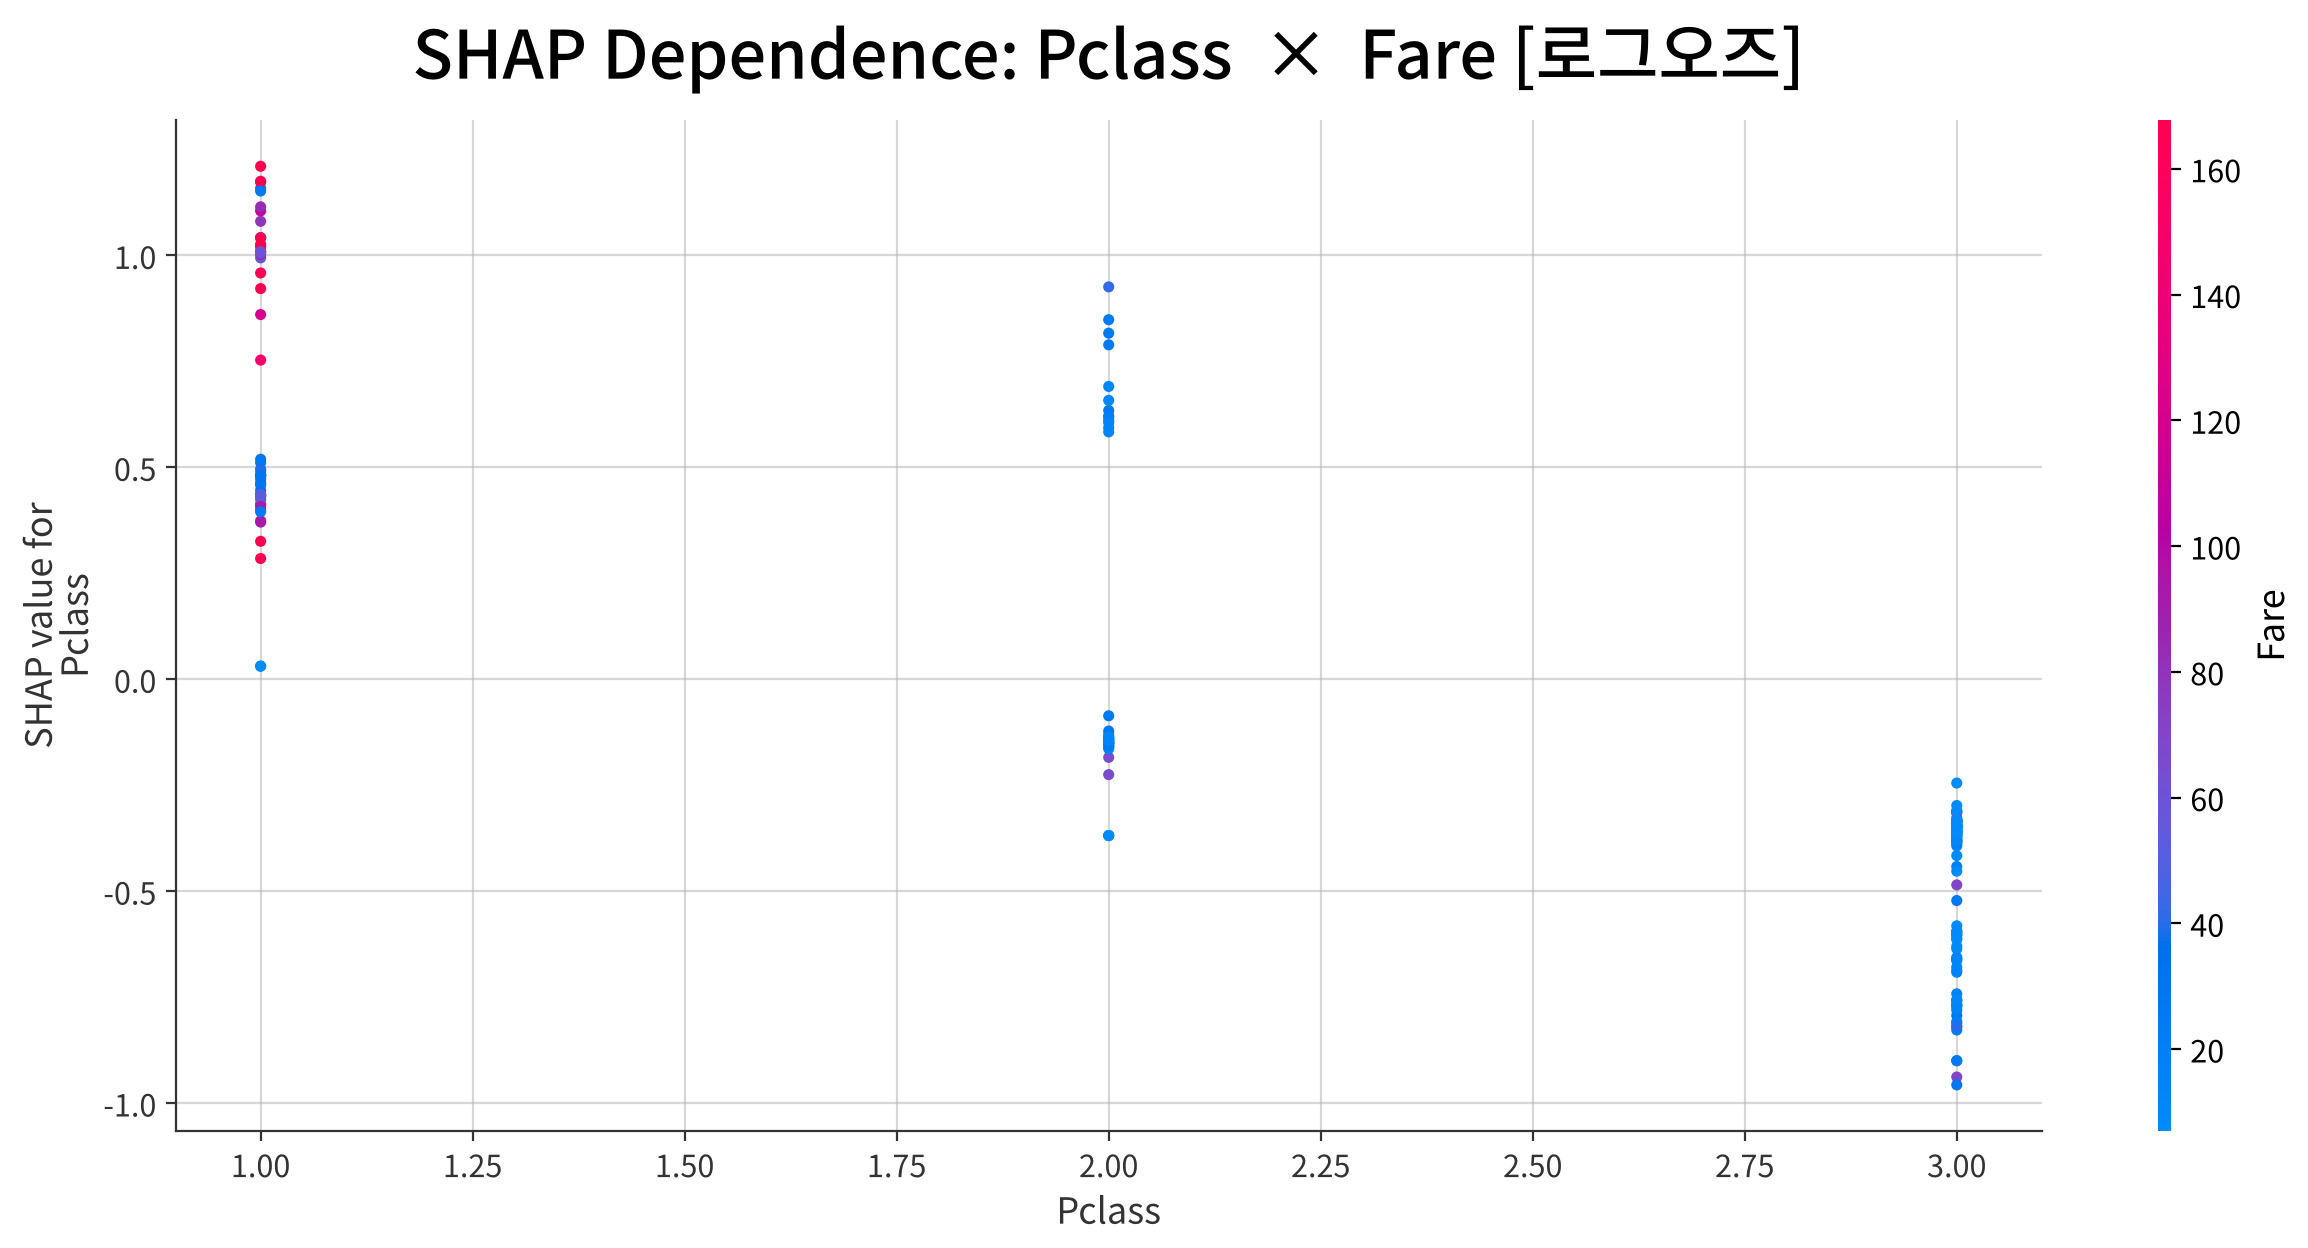

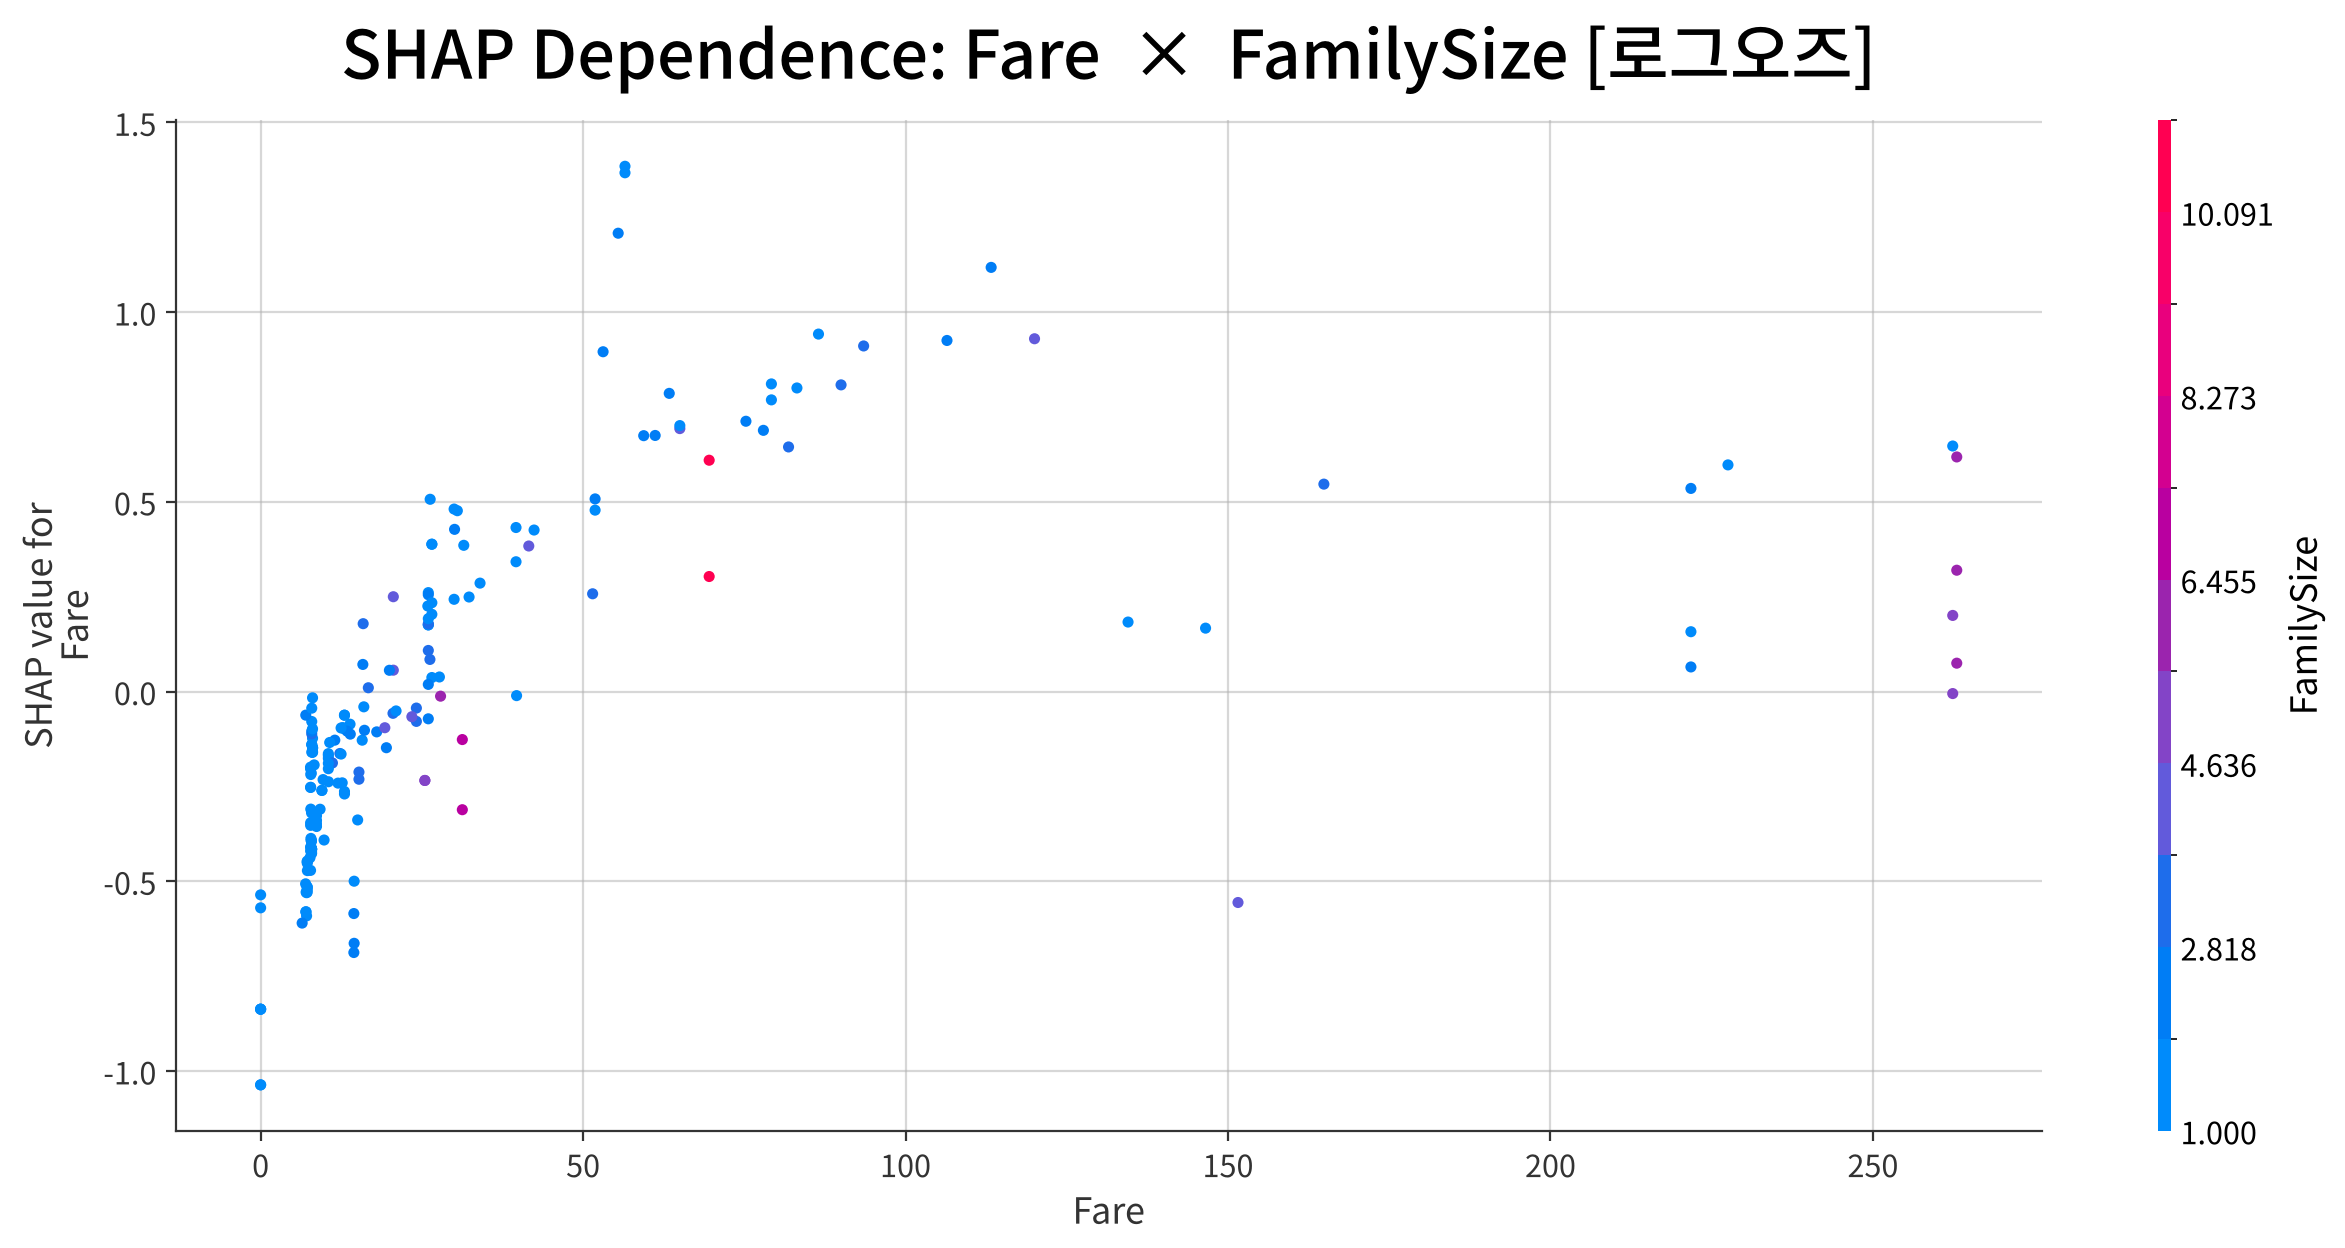

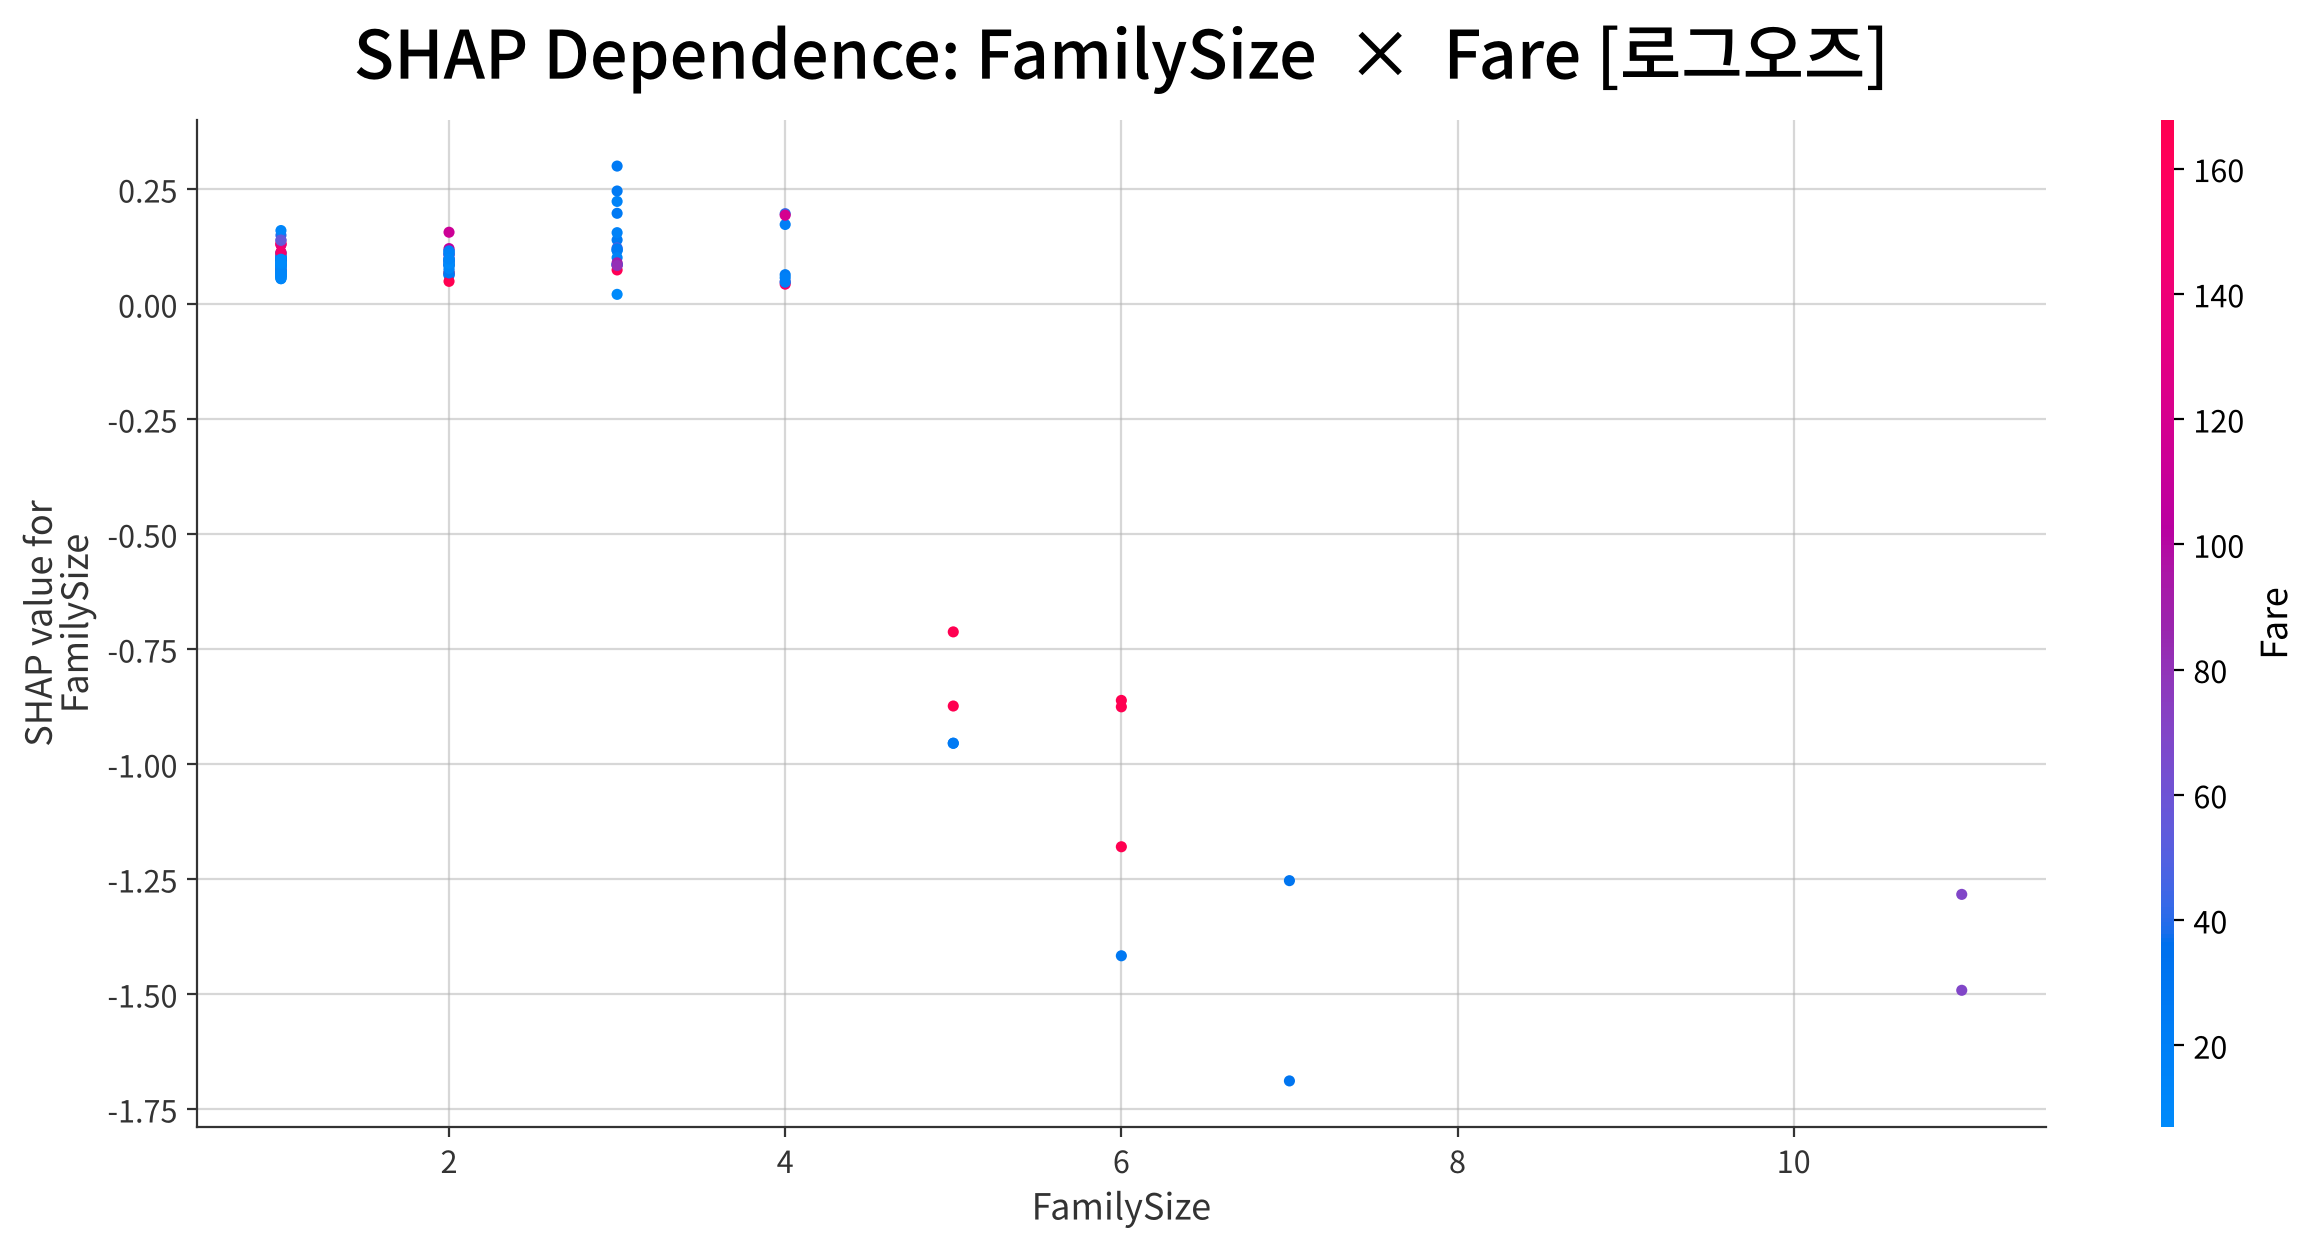

[{'feature': 'Title', 'interaction_feature': 'Pclass'},
 {'feature': 'Pclass', 'interaction_feature': 'Fare'},
 {'feature': 'Fare', 'interaction_feature': 'FamilySize'},
 {'feature': 'FamilySize', 'interaction_feature': 'Fare'}]

In [86]:
# 데이터는 shap.attrs 에서 읽으므로 훈련데이터를 넘기지 않는다.
# features 를 비워야 cum_ratio/top_k 자동선정이 동작한다.
my_ml.shap_dependence_plot(shap)

---
##### 💡 인사이트 — Dependence Plot 4종

- **세로축(SHAP)** = 그 변수 값이 **생존 예측을 얼마나 밀었는지**(설명 대상 = 1, 생존)다. **0보다 위면 생존 쪽, 아래면 사망 쪽**이다.

**① `Title` × `Pclass` — 호칭별 SHAP**

| 호칭 | Master | Miss | Mr | Mrs | Officer |
|---|---|---|---|---|---|
| SHAP (로그오즈) | +0.52 ~ +1.68 | +1.97 ~ +3.02 | −2.11 ~ −1.04 | +2.10 ~ +3.07 | −1.89 ~ −1.62 |

- **여성(Mrs · Miss) > 남자아이(Master) > 0 > 성인 남성(Mr) · Officer** 순서다. 앞의 호칭별 생존 비율(87.0% · 79.1% · 37.7% · 10.8% · 21.7%)과 같은 순서다.
- 같은 호칭 안에서 색(`Pclass`)이 위아래로 갈린다.
  - Miss · Mrs : 3등석(빨강)이 아래쪽(Miss +1.97 ~ +2.48 · Mrs +2.10 ~ +2.70), 1 · 2등석(파랑 · 보라)이 위쪽
  - Mr : 3등석(빨강)이 위쪽(−1.37 ~ −1.04), 1등석(파랑)이 아래쪽(−2.11 ~ −1.44)
- → `Title`의 효과 크기가 객실 등급에 따라 조금씩 달라진다. 다만 어떤 경우에도 **여성은 양수, Mr는 음수라는 방향은 바뀌지 않는다.**

**② `Pclass` × `Fare`**
- 1등석 **+0.03 ~ +1.21**, 2등석 **−0.37 ~ +0.93**, 3등석 **−0.96 ~ −0.24**
- **3등석은 모두 음수**다. 2등석은 0을 사이에 두고 두 무리로 나뉜다(약 −0.4 ~ −0.1과 +0.6 ~ +0.9).

**③ `Fare` × `FamilySize` — 낮으면 사망 쪽, 50 ~ 100에서 가장 생존 쪽**
- 요금 0 : **−1.04 ~ −0.54**, 10 미만 : −0.61 ~ −0.02 → 낮은 요금은 **사망 쪽**으로 민다.
- 25 ~ 50 구간에서 0을 넘기 시작하고, **50 ~ 100 구간이 +0.26 ~ +1.38로 가장 생존 쪽**이다.
- 100 이상은 −0.56 ~ +1.12로 흩어지고 더 오르지 않는다.
- → 요금이 오를수록 생존 쪽으로 가다가, **약 50 ~ 100 이후로는 효과가 커지지 않는다.**
- PART 3 로지스틱 기준선 모형에서는 다른 변수와 함께 넣자 `Fare`가 유의하지 않았지만(p = 0.226), CatBoost에서는 SHAP 3위(12.1%)로 쓰였다. 두 모델이 `Fare`를 다르게 활용한 이유는 이 결과만으로 단정할 수 없다.

**④ `FamilySize` × `Fare` — 4명과 5명 사이의 임계효과**

| 가족 수 | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 11 |
|---|---|---|---|---|---|---|---|---|
| SHAP (로그오즈) | +0.06 ~ +0.16 | +0.05 ~ +0.16 | +0.02 ~ +0.30 | +0.04 ~ +0.20 | −0.95 ~ −0.71 | −1.42 ~ −0.86 | −1.69 ~ −1.25 | −1.49 ~ −1.28 |

- **1 ~ 4명은 모두 작은 양수**이고, **5명부터 한꺼번에 −0.7 이하로 떨어진다.**
- 이 경계는 PART 4 로지스틱 회귀에서 사람이 정한 `FamilyGroup`의 대가족 기준(5명 이상)과 **정확히 같다.** 모델에는 구간을 알려 주지 않고 숫자 `FamilySize`만 넣었는데, CatBoost가 같은 지점을 스스로 찾아냈다.
- ⚠️ 5명 이상 구간의 점은 **200행 표본 중 12개**뿐이다. 경계 위치와 방향은 분명하지만 정확한 크기는 단정하지 않는다.

---

# 📌 결론

### 1. 연구 질문별 답변

| 질문 | 근거 | 답 |
|---|---|---|
| **① 누가 살아남았는가?** | 로지스틱 β : 기혼 여성 1.592 · 미혼 여성 1.584 > 1등급 0.866 > 대가족 −0.543 · CatBoost SHAP : `Title` 60.1% > `Pclass` 17.3% > `Fare` 12.1% | **여성과 아이, 상위 등급, 대가족이 아닌 승객**이 살아남았다. 두 모델 모두 신분(Title)을 가장 큰 요인으로, 객실 등급을 그다음으로 꼽았다. |
| **② '여성과 아이 먼저'는 어떻게 드러나는가?** | 호칭별 생존 비율 Mrs 87.0% · Miss 79.1% · Master 37.7% · Mr 10.8% · SHAP : Mrs · Miss +2 ~ +3, Master +0.5 ~ +1.7, Mr −1.0 ~ −2.1 | **성별보다 호칭에서 더 정확히** 드러난다. 같은 남성이라도 Master는 Mr의 약 3.5배가 살아남았고, 모델도 Master를 양수, Mr를 음수로 밀었다. |
| **③ 가족과 함께 탄 것은 유리했는가?** | 로지스틱 : 대가족 생존 오즈 약 89% ↓ · SHAP : 1 ~ 4명 +0.02 ~ +0.30, 5명 이상 −0.71 ~ −1.69 | **4명까지는 차이가 거의 없고, 5명 이상이면 크게 불리**했다. |

### 2. 핵심 인사이트

**로지스틱 회귀 (PART 1 ~ 5) — 해석**

- **호칭(Title)이 성별보다 많은 것을 말했다** : 성별로는 남자아이가 성인 남성(생존율 12.9%)과 같은 집단이었지만, 호칭으로 떼어 보니 **37.7%** 였다. 호칭으로 아이를 통제하자 EDA에서 무관했던 **나이의 효과**(1살 ↑ → 생존 오즈 1.7% ↓)도 드러났다.
- **통계 검정이 놓친 모양을 도메인 지식으로 담았다** : 가족 규모는 4명까지 생존율이 오르다 5명부터 급락했지만, 로짓 선형성 검정은 위배를 잡지 못했다. 단독 · 소가족 · 대가족으로 나눈 **`FamilyGroup`** 을 쓰자, 같은 변수 7개로 AIC가 940.00 → 923.33으로 낮아졌다.
- **요금 · 항구의 효과는 객실 등급과 겹쳤을 가능성이 있다** : 단독으로는 유의했던 `Fare` · `Embarked`가 다른 변수와 함께 넣자 사라졌다.
- **자동 선택은 전처리의 의미를 모른다** : `compare_models()`는 이상치 대체까지 한 모델(6번)을 골랐지만, 5 · 6 · 7번은 성능이 같았다. 이상치 대체는 성능 이득 없이 실제 나이 · 요금 값만 바꾸고, 정규화는 "1살 많으면 생존 오즈 1.7% 감소" 같은 원래 단위의 해석을 어렵게 만든다. 그래서 전처리가 없는 `5_도메인+후진소거`를 최종 채택했다.

**머신러닝 (PART 6 ~ 9) — 예측과 검증**

- **같은 데이터에서 출발했다** : PART 3에서 저장한 `titanic_model.xlsx`(1,306행 · EDA에서 고른 6개 변수)를 그대로 써서, 두 분석의 결과를 나란히 비교할 수 있다.
- **처음 보는 데이터에서도 성능이 유지됐다** : 로지스틱 회귀는 학습에 쓴 1,306행으로 성능을 재서(in-sample) 새 데이터에서의 성능을 알 수 없었다. 머신러닝에서는 학습에 쓰지 않은 Test 262행(전체의 20%)과 5-Fold 교차검증으로 확인했고, 최종 CatBoost는 Test F1 0.848 · CV F1 0.804, Gap 2.38%로 **일반화** 판정이다.
- **비선형 모델이 성능을 크게 올리지는 못했다** : 베이스라인 1위는 기본 설정의 로지스틱 회귀였고(CatBoost와 F1 0.848로 같음), 튜닝 후 1위도 선형 모델인 ElasticNet이었다(CatBoost와 F1 0.857로 같음). 이 데이터에서는 **선형 모델도 트리 모델과 비슷한 성능**을 냈다. CatBoost를 고른 것은 성능 우위가 아니라, 동률에서 CV ROC_AUC가 조금 높고 꺾이는 모양을 확인할 수 있어서다.
- **사람이 정한 기준을 모델이 독립적으로 재확인했다** : 로지스틱 회귀에서는 가족 규모를 단독(1명) · 소가족(2 ~ 4명) · 대가족(5명 이상)으로 직접 나눈 파생변수 **`FamilyGroup`** 을 만들었다. 머신러닝에는 이 구간을 알려 주지 않고 숫자 `FamilySize`만 넣었는데, SHAP은 **4명과 5명 사이**에서 값이 한꺼번에 떨어졌다. `FamilyGroup`의 대가족 기준(5명 이상)과 같은 지점이다.
- **두 모델이 `Fare`를 다르게 봤다** : 기준선 로지스틱에서는 다른 변수와 함께 넣자 유의하지 않았던 `Fare`가(p = 0.226), CatBoost SHAP에서는 3위(12.1%)였다. 왜 차이가 났는지는 따로 검증하지 않았다.

### ⚠️ 한계

**로지스틱 회귀**
- **`Age` 결측 263명(20.1%)을 전체 중앙값(28세)으로 채웠다.** 28세 자리에 인공적인 봉우리가 생겼고, 나이를 모르는 남자아이 8명도 28세로 채워졌다. 호칭별 중앙값 등으로 채우면 더 정확할 수 있다. 머신러닝도 같은 데이터를 써서 이 한계를 공유한다.
- **`Cabin`(선실 정보)을 버렸다.** 77.5%가 비어 있었지만, 기록 여부 자체가 객실 위치 · 등급과 관련된 정보였을 수 있다.
- **`Officer`(23명) 등 작은 범주의 추정은 불안정하다.**
- **로지스틱 회귀의 성능은 학습 데이터에서 측정했다(in-sample).** 최종 모델 자체를 처음 보는 데이터로 채점하지는 않았다. 다만 PART 6에서 같은 데이터로 학습한 scikit-learn 로지스틱 회귀가 Test에서도 F1 0.848 · ROC_AUC 0.930으로 1위여서, 선형 로지스틱 모형이 새 데이터에서도 크게 무너지지 않는다는 참고 근거는 있다.

**머신러닝**
- **모델 후보를 고르는 데 Test 데이터를 썼다.** 베이스라인과 튜닝 모델 비교시 Test 점수로 순위를 매기고 그 순위로 후보를 골랐기 때문에, 최종적으로 같은 Test로 잰 점수(F1 0.848)는 실제보다 조금 좋게 나왔을 수 있다. 실제로 Test를 쓰지 않은 CV F1(0.804)보다 높다.
- **Test가 262행뿐이라 점수가 흔들리기 쉽다.** 튜닝 1 · 2위(ElasticNet · CatBoost)처럼 점수가 같은 모델은 Test만으로 우열을 가릴 수 없어, 5-Fold 교차검증(CV)으로 다시 비교했다.
- **SHAP은 200명 표본으로 계산했다.** 승객마다 변수별 기여를 따로 계산해 시간이 오래 걸리므로, `my_ml.shap_analysis`의 기본값대로 Train 1,044명 중 200명만 뽑았다. 그중 가족 5명 이상은 12명뿐이라 그 구간의 수치는 대략적인 값으로만 본다.
- **SHAP은 원인이 아니라 모델의 예측을 설명한다.** "Mr이라서 사망했다"가 아니라 **"모델이 Mr인 승객의 생존 예측을 크게 낮췄다(SHAP −1.0 ~ −2.1)"** 가 정확한 표현이다.

### ✅ 최종 모델

| 구분 | 로지스틱 회귀 (해석용) | CatBoost (예측용) |
|---|---|---|
| 모델 | `5_도메인+후진소거` | CatBoost (`depth` 4 · `iterations` 500 · `learning_rate` 0.03) |
| 데이터 | PART 3의 `df_model` 1,306행 전체 (`FamilySize` → `FamilyGroup`) | `titanic_model.xlsx` 1,306행 (Train 1,044 · Test 262) |
| 투입 변수 | `Title`(Master · Miss · Mrs) · `Pclass`(1 · 2등급) · `FamilyGroup_Large` · `Age` | `Title` · `Pclass` · `Fare` · `FamilySize` · `Age` (5개) |
| 성능 | 정확도 0.872 · AUC 0.904 · 재현율 0.783 · Pseudo R² 0.476 (학습 데이터, 임계값 0.5) | Test F1 0.848 · ROC_AUC 0.927 · 정확도 0.885 · CV F1 0.804 · CV ROC_AUC 0.899 |
| 임계값 | 0.4 권장 → 정확도 0.873 · F1 0.826 | 0.5 (기본값) |
| 일반화 | — | 일반화 판정 (F1 Gap 2.38%) |
| 가장 큰 영향 | `Title_Mrs` (β = 1.592) | `Title` (SHAP 60.1%) |